# 🌊 Bangladesh National Flood Intelligence — v12 (publication-ready final: robust data registry · HydroGate-Net · TabM-style MLP · meta-learner arena · all-folds deployment rule)

**Every component must EARN its place on development years (judged 70 % on ONSET PR-AUC), then is checked once on the untouched final test (≥ 2025). All v8/v9 comparison metrics are kept.**
Tabular XGBoost family + hydrograph-shape features + keyless-API extras + LSTM + **HydroGate-Net** → Caruana combination **or a learned meta-learner (arena)** → calibration → optional SAR / forecast-rain correction → online self-correction → tiers, recall-guaranteed levels, low-agreement flag.

Run once with `DRY_RUN=True` (synthetic; proves the code executes — it says NOTHING about skill), then `DRY_RUN=False` on a **GPU** Colab Pro runtime. Read **`14e · FINAL PROOF`** and `results/eval/PROOF_REPORT.md`: if the new pieces do not clear their gates, the notebook serves plain XGBoost and says so.


## v11 — what changed (from your executed v10 run)
| What your run showed | v11 response |
|---|---|
| Open-Meteo ERA5-Land: **HTTP 429** → source disabled | the hourly ERA5-Land request was far above the free per-minute limit. It is now OFF by default (NASA POWER already supplies soil wetness and worked: 3 d latency); if you switch it on it uses tiny batches and waits out the *per-minute* limit, but stops cleanly at an *hourly / daily* limit (cached chunks are kept) |
| Earth Engine CHIRPS: "returned no values" | the newest days are not published yet (CHIRPS lags weeks), so the whole last chunk was empty and the source was thrown away. The empty newest chunk is now tolerated; latency is measured from the last valid day and the source is dropped only if it is too late to matter |
| cell 9m: `NameError POOL` | the Colab runtime had restarted after cell 9 (25 min of work lost). Cell 9 now **checkpoints every finished fold to Drive** and restores them on re-run, and 9m says clearly what to do |
| your dev scores: combination +0.024 over plain XGBoost, HydroGate-Net weight 0.25 | kept. A **TabM-style MLP ensemble** (cell 8f) is added as one more, structurally different member |
| "pick the ensemble / meta-learner only if it beats XGBoost-all-features in all folds, even slightly" | new **cell 9z — final selection**: every candidate gets its gain over plain XGBoost *in each dev fold*; only a candidate with a strictly positive gain in **every** fold (and pooled) is deployed — otherwise plain XGBoost (all features, calibrated) is deployed. The table is saved and is part of PROOF_REPORT |
| "do not remove any model" | nothing was removed: all baselines, XGBoost variants, LightGBM, bagging, regime split, LSTM, HydroGate-Net, TabM, Caruana combination, three meta-learners, SAR/U-Net, online correction, forecast-rain test remain and stay in every comparison table |


## v10 — what changed
| Your request / the v9 evidence | v10 response |
|---|---|
| "the meta-learners are not utilised properly" — in v7 the stacker saw ≈ 400 SAR floods, in v8/v9 only fixed Caruana weights | **9m · Meta-learner arena**: three stackers learn *how to combine* the members from the national out-of-fold logits (≈ every dev node-day, ≈ 10 k floods): logistic stack, **context-gated mixture-of-experts** (weights depend on regime · riparian score · season · flow level; initialised on the base model and L2-pulled back to it), residual boosting on member logits. Nested leave-one-fold-out; the gate learned is printed (interpretable) |
| "design a novel architecture" | **8e · HydroGate-Net** — node-conditioned variable-selection gate + dilated causal multi-scale convolutions + GRU + FiLM static modulation + auxiliary ONSET and flood-NOW heads, one pooled network for all nodes. It is one more member of the pool *and* a stand-alone candidate |
| "do not put useless / non-working APIs; let me replace and flag them" | **8b2 · Data-source registry**: only keyless HTTP APIs — Open-Meteo archive (ERA5-Land soil moisture + ET0; ERA5 rain) and NASA POWER (corrected rain, root-zone + surface soil wetness). Every source has `on=True/False`, a replaceable `url` / `params` / `parse` mode (or your own `fetch` function), a **live pre-flight test** (reachability, variable names, plausible values, latency) and **auto-disables itself with a printed reason**. Earth Engine is OFF by default (`USE_EE_SOURCES`) |
| comparison metrics | unchanged: every candidate, including the new ones, goes through the same pooled / final-test tables, block-bootstrap significance, tolerance-window events, onset lead-time table and proof report |

**Honest limits.** The labels are GloFAS-derived (not gauge records) — that, not the model, is probably the ceiling; an FFWC/BWDB gauge label is the real next lever (hook in 10f). Beating plain XGBoost is *possible, not guaranteed*: the proof table decides, and with more candidates the best-of-N selection is slightly optimistic on dev — the sealed ≥ 2025 test is the arbiter. I could not call the web APIs from my sandbox; the endpoints and parameter names were checked against their public documentation and the pre-flight test checks them again on **your** runtime.


## Literature behind the v10 design (only sources that were opened and read, or are standard references)
| Finding | Source | What v10 does with it |
|---|---|---|
| On medium-sized tabular data, **tree ensembles still beat deep nets** | Grinsztajn, Oyallon & Varoquaux, *Why do tree-based models still outperform deep learning on tabular data?* arXiv:2207.08815 (2022) | XGBoost stays the base model; every deep or stacked model must **beat it by a margin** or it is not served |
| Parameter-efficient **ensembling of MLP sub-models** is the strongest deep tabular recipe | Gorishniy, Kotelnikov & Babenko, *TabM*, ICLR 2025, arXiv:2410.24210 | members = several seeds / sub-models, combined in logit space |
| **Gating and variable selection** per time step + static context improves interpretable multi-horizon forecasting | Lim, Arık, Loeff & Pfister, *Temporal Fusion Transformers*, Int. J. Forecasting 37(4):1748–1764 (2021) | HydroGate-Net's node-conditioned variable-selection gate and static modulation |
| **LSTMs** are the strong baseline for rainfall–runoff and for extreme-flood forecasts in ungauged basins | Kratzert et al., HESS 23:5089 (2019); Nearing et al., Nature 627:559 (2024) | pooled-node sequence models (LSTM + HydroGate-Net) trained across all nodes |
| **Spatio-temporal attention LSTM** for Bangladesh river water levels | Noor et al., *Water level forecasting using spatiotemporal attention-based long short-term memory network*, Water 14(4):612 (2022) | motivation for attention-style gating on the Bangladesh network |
| **Stacking** and **ensemble selection** combine heterogeneous models; **mixture-of-experts** routes by context | Wolpert (1992) *Stacked generalization*; Caruana et al. (2004) *Ensemble selection from libraries of models*; Jacobs et al. (1991) *Adaptive mixtures of local experts* | Caruana (kept) vs logistic stack vs **context-gated mixture-of-experts** vs residual boosting — a fair arena with nested evaluation |


## v6 production release — what changed and WHY (every change is justified by the v5.8 results)

**What the v5.8 run showed:** (i) 74 % of the signal is node hydrology; upstream / transboundary / spatial features add ≈ 0; (ii) re-weighting / bagging did not move PR-AUC (0.831–0.834), only the POD ⇄ FAR trade-off; (iii) the ResNet had no signal (val PR-AUC 0.11 → falling) and the fusion was significantly *worse* than tabular; (iv) overall F1 beats "same as today" by only 0.02 — the skill is in **onsets**, and day-level scoring flatters persistence.

| # | Change | Why | Overfitting control |
|---|---|---|---|
| 1 | **Regime-split XGBoost** (onset specialist trained on quiet days ⇄ continuation specialist trained on flooding days) + 6 onset-physics features (acceleration, days-to-threshold at current rise rate, rise vs 7-day minimum …) | the two regimes have different physics; one model averages them | specialists share the same tuned hyper-parameters; judged only on out-of-time folds |
| 2 | **Combination selection** (Caruana greedy ensemble over XGB · LGBM · local-XGB · bagging · regime-split, weights learned on *logits*) | "pick the best model combination" | weights are learned on walk-forward predictions only, estimated with a **nested leave-one-fold-out** loop; the combination is served only if it beats plain XGBoost by ≥ margin **and** wins in ≥ 60 % of the folds |
| 3 | **SAR residual corrector** = the real meta-learner: logit(p_tab) is an *offset*; a depth-2 booster sees only interpretable SAR water features (water fraction, centre / low-lying water, change vs previous block, anomaly vs the node's own causal history, backscatter) and adds a *bounded* correction `α·δ` | the ResNet embedding had no signal and only ~40 positives to learn from; the corrector trains on **all** 2020-24 out-of-fold rows and is scored by an **expanding-window** (train < Y → test Y) | α ∈ {0 … 1} and tree count are chosen out-of-time; **α = 0 (no correction) is always allowed** — the corrector switches itself off unless it wins in ≥ 60 % of the years |
| 4 | **Tolerance-window event evaluation** (cell 10d): onset-event POD, lead time, alert-episode precision, event-F1/F2 at ±0/1/2-day tolerance | the "Good → Exceptional" advice: timing slack must not be counted as a failure | **strict (tol 0) stays the headline**; a persistence row is printed next to it to show how much leniency alone inflates a score |
| 5 | **Overfit audit** (cell 10e): fold stability, in-sample vs unseen gap, **leave-one-basin-out** generalisation, coordinates vs no-coordinates | proves the model works at locations it has never seen | selection is **frozen to JSON before the final test is touched** (cell 10) |
| 6 | **Deployment refit** (cell 14c): the served models are refit on *all* labelled data (incl. 2025+) with the frozen hyper-parameters, weights, calibrator and thresholds | the evaluation fit stops at 2024 | numbers reported in this notebook always come from the *pre-refit* models |
| 7 | **Forecast-rain archiver** (cell 15b) + **gauge-validation hook** (cell 10f) | no long forecast-rain history exists (Open-Meteo previous-runs archive ≈ 2024+); BWDB/FFWC gauge records are the real ground truth | archiver starts building a true forecast history today; the gauge hook scores alerts against observed danger-level exceedance as soon as you drop a CSV in `gauges/` |
| 8 | CNN branch is now **off by default** (`USE_CNN=False`); SAR patches are used through the corrector | evidence says it adds nothing and costs training time | flag kept so the comparison can be re-run |

**Strict rule of this notebook:** *nothing is selected, tuned, calibrated or thresholded on the final test (≥ 2025).* Tolerance-window scores are always printed **together with** the strict ones.

---


## What is new in v5 (on top of the v4 architecture, which is unchanged)

| Area | Change | Where |
|---|---|---|
| **Speed – node QC** | Vectorised NaN-safe `np.nanpercentile` for node q95 + vectorised gauge/row counts (the Gemini fix, made NaN-safe: plain `np.percentile` returns NaN for every node that has a single missing day) | cell 6b |
| **Speed – hardware** | Auto-detects GPU / RAM: XGBoost on `device="cuda"`, bigger Optuna budget & more trees on GPU, `TRAIN_STRIDE` shrinks with RAM, CNN uses AMP (fp16) + larger batch + DataLoader workers, Earth-Engine workers 4 → 8 | cells 2, 9, 11, 12 |
| **Speed – caching** | Every walk-forward fold panel + its fitted routing/threshold dictionary is cached on Drive (zstd-parquet). Re-runs skip all feature engineering; fold Y0 is no longer built twice | cell 9 |
| **Class imbalance (core of this release)** | (1) Optuna now tunes the cost-sensitive weight **`spw_mult`** and an **onset weight** (up-weights the rare, hard quiet→flood rows) together with the tree hyper-parameters · (2) **balanced bagging with hard-negative mining** (all positives + undersampled negatives, half of them "near-miss" negatives, K models averaged) · (3) **logit-average imbalance ensemble** XGB + LightGBM + Bag · (4) **focal loss** + √-pos-weight + AMP for the CNN · (5) F1 / F2 **threshold moving** and recall-weighted WATCH tier (kept) · (6) Platt calibration on pooled walk-forward predictions undoes the probability inflation caused by re-weighting. SMOTE-style synthetic rows are deliberately *not* used: interpolating between autocorrelated hydrological states creates physically impossible records and temporal leakage | cells 2, 9, 12, 10c |
| **New metrics** | **F2**, F2-onset, **MCC**, **MAE** (mean \|y − p\|) next to PR-AUC / ROC-AUC / F1 / POD / FAR / CSI / Brier / ECE; thresholds for F1 *and* F2 are always picked on development data only | cells 10, 14 |
| **New evidence cell** | 10c retrains XGBoost with *no re-weighting → natural spw → √spw → tuned spw×onset → balanced bagging → bag+tuned ensemble* on identical rows, picking thresholds on a held-out training year, so the imbalance recipe is justified by data, not asserted | cell 10c |
| Parsimony margin | `SELECT_MARGIN` 0.02 → 0.01 (more candidate models are now in play; the margin still protects against noise) | cell 2 |

**Colab Pro run recipe:** Runtime → *Change runtime type* → GPU (A100/L4/T4) and, if offered, *High-RAM*. Run with `DRY_RUN=True` once (≈10 min), then `DRY_RUN=False`. Panels are cached under `Drive/Bangladesh_Flood_Research/processed_data/` (≈1 GB) — delete `panel_*.parquet` if you change features or thresholds.

---


## 1 · Setup

In [1]:
# @title 1 · Install & import  (+ RAM meter, float32 helpers, metric helpers)
import subprocess, sys, importlib.util, os, json, time, math, warnings, random, shutil, io, gc, glob, zlib, datetime as dt
from concurrent.futures import ThreadPoolExecutor, as_completed
warnings.filterwarnings("ignore")
_need = {"optuna": "optuna", "lightgbm": "lightgbm", "xgboost": "xgboost", "pyarrow": "pyarrow", "psutil": "psutil"}
_miss = [p for m, p in _need.items() if importlib.util.find_spec(m) is None]
if _miss:
    print("Installing:", _miss); subprocess.run([sys.executable, "-m", "pip", "install", "-q", *_miss], check=False)
import numpy as np, pandas as pd, requests, psutil
import matplotlib.pyplot as plt, seaborn as sns
from matplotlib.path import Path as MPath
from xml.sax.saxutils import escape as xml_escape
from sklearn.metrics import (average_precision_score, f1_score, precision_recall_curve, precision_score, recall_score,
                             brier_score_loss, roc_auc_score, fbeta_score, confusion_matrix, matthews_corrcoef)
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.decomposition import PCA
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
import optuna, xgboost as xgb, lightgbm as lgb
optuna.logging.set_verbosity(optuna.logging.WARNING); sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 120, "savefig.bbox": "tight"})
try:                                                   # PyTorch is pre-installed on Colab; the vision branch degrades gracefully without it
    import torch, torch.nn as nn, torchvision
    from torch.utils.data import Dataset, DataLoader
    HAS_TORCH = True
except Exception as _e:
    HAS_TORCH = False; print("PyTorch not available → the vision branch will use a PCA-embedding fallback:", str(_e)[:80])

def ram(tag=""):
    """Resident RAM of this process (Colab free tier ≈ 12.7 GB)."""
    print(f"🧠 RAM {psutil.Process().memory_info().rss/1e9:.2f} GB used of {psutil.virtual_memory().total/1e9:.1f} GB  {tag}")
def downcast(df):
    """float64 → float32 (halves RAM). float16 is NOT used for tabular features (ratios/discharge need float32); flags are uint8."""
    for c in df.columns:
        if pd.api.types.is_float_dtype(df[c]) and df[c].dtype != np.float32: df[c] = df[c].astype(np.float32)
    return df
def show(df, nd=3):
    try: from IPython.display import display; display(df.round(nd))
    except Exception: print(df.round(nd).to_string())

# ---- metric helpers shared by every evaluation block ------------------------------------------------------------------------------------
def aps(y, p): return float(average_precision_score(y, p)) if y.sum() > 0 and (1 - y).sum() > 0 else np.nan
def auc(y, p): return float(roc_auc_score(y, p)) if y.sum() > 0 and (1 - y).sum() > 0 else np.nan
def best_thr(y, p, beta=1.0):
    """Threshold maximising F-beta (beta=1 → F1, beta=2 → recall-weighted, used for the WATCH tier)."""
    if y.sum() == 0: return 0.5
    pr, rc, th = precision_recall_curve(y, p); b2 = beta * beta; f = (1 + b2) * pr[:-1] * rc[:-1] / np.maximum(b2 * pr[:-1] + rc[:-1], 1e-12)
    return float(th[int(np.argmax(f))])
def ece(y, p, bins=10):
    """Expected calibration error with equal-width bins."""
    p = np.clip(p, 0, 1); b = np.minimum((p * bins).astype(int), bins - 1); e = 0.0
    for k in range(bins):
        m = b == k
        if m.any(): e += m.mean() * abs(p[m].mean() - y[m].mean())
    return float(e)
def verif(y, yh):
    """Flood-forecast verification scores: POD (hit rate), FAR (false-alarm ratio), CSI (critical success index)."""
    tp = int(((yh == 1) & (y == 1)).sum()); fp = int(((yh == 1) & (y == 0)).sum()); fn = int(((yh == 0) & (y == 1)).sum())
    return dict(POD=tp / max(tp + fn, 1), FAR=fp / max(tp + fp, 1), CSI=tp / max(tp + fp + fn, 1))
def logit(p): p = np.clip(np.asarray(p, float), 1e-6, 1 - 1e-6); return np.log(p / (1 - p))
class Platt:
    """Platt scaling (logistic regression on the logit of a score) — fitted on out-of-time predictions only."""
    def __init__(self): self.lr = None
    def fit(self, p, y):
        y = np.asarray(y)
        if y.sum() > 0 and (1 - y).sum() > 0: self.lr = LogisticRegression(C=1e6, max_iter=1000).fit(logit(p).reshape(-1, 1), y)
        return self
    def __call__(self, p): return np.asarray(p, float) if self.lr is None else self.lr.predict_proba(logit(p).reshape(-1, 1))[:, 1]
print("✅ imports OK | xgboost", xgb.__version__, "| lightgbm", lgb.__version__, "| torch", HAS_TORCH); ram("after imports")


Installing: ['optuna']
✅ imports OK | xgboost 3.4.1 | lightgbm 4.6.0 | torch True
🧠 RAM 0.62 GB used of 13.6 GB  after imports


### 1b · Publication style (300-dpi PNG + vector PDF for every figure, colour-blind palette, clean model names)

In [2]:
# @title 1b · PUBLICATION STYLE — one consistent journal look for EVERY figure: 300-dpi PNG + vector PDF twin, colour-blind-safe palette, readable font sizes, constrained layout (no overlapping labels), clean model names
import matplotlib as mpl, matplotlib.pyplot as plt, os
from cycler import cycler
OKABE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#F0E442", "#000000"]        # Okabe–Ito colour-blind-safe palette
PUB_PDF = True            # also write a vector PDF next to every PNG (journals prefer vector or ≥ 300 dpi)
mpl.rcParams.update({"figure.dpi": 100, "savefig.dpi": 300, "savefig.bbox": "tight", "savefig.pad_inches": 0.1, "figure.constrained_layout.use": True, "figure.constrained_layout.h_pad": 0.1, "figure.constrained_layout.w_pad": 0.1,
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Liberation Sans", "DejaVu Sans"], "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlepad": 8, "axes.labelsize": 10, "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 8.5, "legend.title_fontsize": 9, "legend.frameon": False,
    "figure.titlesize": 13, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6, "axes.axisbelow": True, "axes.prop_cycle": cycler(color=OKABE), "lines.linewidth": 1.6, "lines.markersize": 5, "pdf.fonttype": 42, "ps.fonttype": 42})
if not getattr(mpl.figure.Figure.savefig, "_pub", False):
    _orig_savefig = mpl.figure.Figure.savefig
    def _pub_prep(fig, maxw=14.0):
        """Journal-ready layout at save time: cap the width (so 10-pt text stays legible when the figure is scaled to a page), then wrap titles that would not fit their panel."""
        try:
            w, h = fig.get_size_inches()
            if w > maxw: fig.set_size_inches(maxw, h * maxw / w)
            fig.draw_without_rendering(); import textwrap
            for ax_ in fig.axes:
                t = ax_.get_title()
                if t and "\n" not in t:
                    try: wd = ax_.get_subplotspec().get_position(fig).width
                    except Exception: wd = ax_.get_position().width
                    room = max(wd * fig.get_figwidth() * 7.2, 14)
                    if len(t) > room: ax_.set_title(textwrap.fill(t, int(room)), fontsize=mpl.rcParams["axes.titlesize"])
            rend = fig.canvas.get_renderer()
            for ax_ in fig.axes:
                if ax_.get_ylabel() in ("v", "value"): ax_.set_ylabel("")
                for _ in range(4):
                    L = [l for l in ax_.get_xticklabels() if l.get_text() and l.get_visible()]
                    if len(L) < 2: break
                    bb = [l.get_window_extent(rend) for l in L]
                    if not any(bb[i].x1 > bb[i + 1].x0 - 2 and bb[i].y0 < bb[i + 1].y1 and bb[i + 1].y0 < bb[i].y1 for i in range(len(bb) - 1)): break
                    num = all(l.get_text().replace(".", "").replace("-", "").replace("−", "").isdigit() for l in L)
                    if _ == 0 and L[0].get_rotation() == 0: plt.setp(L, rotation=45, ha="right")
                    elif not num and L[0].get_rotation() != 90: plt.setp(L, rotation=90, ha="center")
                    elif num:
                        for l in L[1::2]: l.set_visible(False)
                    else: break
                    fig.draw_without_rendering()
            st = getattr(fig, "_suptitle", None)
            if st is not None and len(st.get_text()) > fig.get_figwidth() * 9 and "\n" not in st.get_text(): st.set_text(textwrap.fill(st.get_text(), int(fig.get_figwidth() * 9)))
        except Exception as err: print("   (layout prep skipped:", str(err)[:80], ")")
    def _pub_savefig(self, fname, *a, **k):
        if isinstance(fname, (str, os.PathLike)): _pub_prep(self)
        r = _orig_savefig(self, fname, *a, **k)
        try:
            if PUB_PDF and isinstance(fname, (str, os.PathLike)) and str(fname).lower().endswith(".png"): k2 = {q: v for q, v in k.items() if q not in ("dpi", "format")}; _orig_savefig(self, os.path.splitext(str(fname))[0] + ".pdf", *a, **k2)
        except Exception as err: print("   (PDF twin not written:", str(err)[:80], ")")
        return r
    _pub_savefig._pub = True; mpl.figure.Figure.savefig = _pub_savefig
_SHORT = [("Persistence-soft", "Persistence (soft rank)"), ("Persistence (binary", "Persistence (binary)"), ("Logistic Regression", "Logistic regression"), ("Random Forest", "Random forest"), ("LightGBM", "LightGBM"), ("XGB+LGBM average", "XGBoost + LightGBM mean"),
          ("XGBoost (all features)", "XGBoost, all features"), ("XGBoost-local", "XGBoost, local only"), ("XGBoost balanced-bag", "XGBoost + balanced bagging / HNM"), ("XGBoost regime-split", "XGBoost regime-split"), ("XGBoost distance-gated", "XGBoost distance-gated"),
          ("XGBoost (baseline + hydrograph", "XGBoost + hydrograph shape"), ("XGBoost (baseline features)", "XGBoost, baseline features"), ("Imbalance ensemble", "Imbalance ensemble (XGB+LGBM+Bag)"), ("LSTM", "LSTM (30-day)"), ("HydroGate", "HydroGate-Net"), ("TabM", "TabM-style MLP"),
          ("Selected combination", "Selected combination"), ("Meta-learner · logistic", "Meta: logistic stack"), ("Meta-learner · context", "Meta: gated mixture-of-experts"), ("Meta-learner · residual", "Meta: residual boosting")]
def short_name(n, w=46):
    """Readable model name for axes and legends (never cuts a word in half)."""
    n = str(n).lstrip("· "); star = n.startswith("★ "); core = n[2:] if star else n; cal = core.endswith("(calibrated)"); core = core.replace(" (calibrated)", "")
    out = next((s for p, s in _SHORT if core.startswith(p)), core if len(core) <= w else core[:w - 1].rsplit(" ", 1)[0] + "…")
    return ("* " if star else "") + out + (" (cal.)" if cal else "")
print("✅ publication style active: 300-dpi PNG + vector PDF twin for every saved figure | font", mpl.rcParams["font.sans-serif"][:2])


✅ publication style active: 300-dpi PNG + vector PDF twin for every saved figure | font ['Arial', 'Liberation Sans']


## 2 · Configuration

In [3]:
# @title 2 · Configuration  (edit here)
DRY_RUN    = False    # True = synthetic smoke-test of the WHOLE pipeline (no internet, no credentials, no Earth Engine). Run this first, then set False.
QUICK_MODE = False   # True = fewer folds / trees / SAR years / bootstrap draws (fast first real pass)
SEED       = 42
USE_SAR    = True    # vision branch (Sentinel-1 SAR + DEM patches → ResNet-18 embeddings → meta-learner). False = tabular branch only (no Earth Engine)
USE_ELEV_API = True  # real run: node elevation/relief from the free Open-Meteo elevation API (Copernicus DEM)

# ---- hardware auto-detection (Colab Pro: GPU + High-RAM) ----------------------------------------------------------------------------
RAM_GB     = psutil.virtual_memory().total / 1e9
ON_GPU     = bool(HAS_TORCH and torch.cuda.is_available())
XGB_DEVICE = "cuda" if ON_GPU else "cpu"
print(f"⚙️ hardware: RAM {RAM_GB:.0f} GB | GPU {torch.cuda.get_device_name(0) if ON_GPU else 'none'} | XGBoost device = {XGB_DEVICE} | CPU cores {os.cpu_count()}")
TODAY       = pd.Timestamp.today().normalize()
DATA_START  = "1984-01-01"     # GloFAS v4 reanalysis starts 1984 → ≈ 15.5 k days per node (nodes × days ≫ 500 k rows)
# ---- national grid -------------------------------------------------------------------------------------------------------------------
GRID_DEG     = 0.45            # regular grid spacing (≈ 50 km) → ≈ 65–85 nodes after adding haor / confluence / border nodes
RIPARIAN_KM  = 20.0            # riparian flag: node within this distance of a monitored river (HAND-proxy; true HAND is used if Earth Engine is available)
NODE_MIN_Q95 = 1.0             # m³/s: nodes whose GloFAS cell carries no river signal are flagged and excluded (printed in the node table)
K_NEIGH      = 6               # spatial-lag neighbours per node
N_GAUGE_CAND, N_TB_CAND = 4, 2 # candidate upstream gauges per node: 4 nearest + the 2 nearest transboundary entry gauges
VEL_KM_DAY, LAMBDA_KM = 60.0, 150.0   # prior flood-wave celerity (km/day) and distance decay of the prior upstream weight
# ---- target + features ---------------------------------------------------------------------------------------------------------------
HORIZON    = 3        # flood_next3 = node discharge exceeds its high-flow threshold on ANY of days t+1 … t+3
EMBARGO    = HORIZON  # days dropped at the end of every training period (labels look this far ahead)
FLOOD_Q    = 0.95     # node/gauge threshold = this quantile of the TRAINING period only (re-fitted inside every fold)
MAX_LAG    = 7        # longest upstream travel time searched (days)
DYN_GAIN   = 2.0      # dynamic up-weighting of a fast-rising upstream gauge
SPIKE_Z    = 3.0      # robust z of a 1-day discharge jump = release / spike
API_WIN_K  = 0.90     # decay for the 3/7/14-day windowed Antecedent Precipitation Index
API_WINDOWS = (3, 7, 14)
API_K      = (0.85, 0.95)   # 30-day API decay constants
API_WINDOW = 30
# ---- chronological validation --------------------------------------------------------------------------------------------------------
DEV_FOLDS       = [2022, 2023, 2024] if QUICK_MODE else [2020, 2021, 2022, 2023, 2024]   # walk-forward test years (train = all earlier years − embargo)
FINAL_TEST_FROM = 2025         # untouched final test (final model trained on ≤ 2024)
SELECT_MARGIN   = 0.005         # parsimony: a more complex variant must beat the simpler one by this much (pooled out-of-time) to be chosen
TRAIN_STRIDE    = 6 if DRY_RUN else (6 if QUICK_MODE else (1 if RAM_GB > 60 else 2 if RAM_GB > 20 else 3))   # keep every n-th day of the TRAINING rows only (daily series are highly autocorrelated); test rows are always complete
XGB_TRIALS      = 2 if DRY_RUN else (4 if QUICK_MODE else (24 if ON_GPU else 8))
N_TREES         = 120 if DRY_RUN else (150 if QUICK_MODE else (600 if ON_GPU else 300))
SUB_CAP         = 120_000      # row cap for the slow baselines (LogReg, RandomForest)
N_BOOT          = 80 if DRY_RUN else (150 if QUICK_MODE else 400); BLOCK_DAYS = 14   # block-bootstrap draws / block length (days)
D0_GRID = [0, 10, 20, 30, 50, 100000]; S_GRID = [5, 15]   # km: distance-gate search (0 = never use upstream info, 100000 = always)
# ---- vision branch (Sentinel-1 SAR + DEM patches) ------------------------------------------------------------------------------------
PATCH_PX, PATCH_SCALE_M = 32, 300          # 32×32 px at 300 m ≈ 9.6 km square around every node
BLOCK_LEN   = 12                           # SAR composite length in days (= Sentinel-1 repeat cycle)
SEASON_START, SEASON_END = (3, 20), (11, 30)
SAR_YEARS   = list(range(2018 if QUICK_MODE else 2017, TODAY.year + 1))
VIS_TRAIN_LAST, VIS_VAL_YEAR = 2020, 2021  # CNN trained on patches ≤ 2020, early-stopped on 2021
META_TRAIN_YEARS, META_VAL_YEAR = (2022, 2023), 2024   # meta-learner fitted on 2022–23 OOF branch outputs, selected/calibrated on 2024, tested on ≥ 2025
CNN_EPOCHS, CNN_BATCH, PCA_DIM = (2 if DRY_RUN else (4 if QUICK_MODE else (14 if ON_GPU else 8))), (128 if ON_GPU else 64), 32
MIN_VALID   = 0.6                          # a patch needs ≥ 60 % valid pixels
PATCH_FILL  = (-22.0, -28.0, 6.0)          # fill for missing VV, VH (dB) and VV−VH
# ---- ingestion ------------------------------------------------------------------------------------------------------------------------
API_WORKERS = 4                            # parallel API workers (Open-Meteo free tier ≈ 600 calls/min · 5 k/hour · 10 k/day — the cache makes a re-run resume)
FLOOD_CHUNK_YEARS, WX_CHUNK_YEARS = 6, 5
REFRESH_DAYS = 10                          # the newest N days are always re-fetched (reanalysis values get revised)
# ---- alerts ---------------------------------------------------------------------------------------------------------------------------
SEVERE_MIN_PREC = 0.60                     # SEVERE tier = lowest probability whose pooled out-of-time precision ≥ this
CAP_SENDER = "flood-ai@example.org"; CAP_STATUS = "Test"   # keep "Test"/"Exercise" until BWDB/FFWC/BMD validate the system
BN_TIER = {"WATCH": "নজরদারি", "WARNING": "সতর্কতা", "SEVERE": "মারাত্মক সতর্কতা"}

# ---- v5: class-imbalance toolkit ---------------------------------------------------------------------------------------------------------
BAG_K, BAG_NEG_RATIO = (2 if DRY_RUN else 6), 6          # balanced bagging: K models, each sees all positives + 6 negatives per positive (half of them hard near-misses)
BAG_NAME, ENS_NAME = "XGBoost balanced-bag (hard-negative undersampling)", "Imbalance ensemble (XGB+LGBM+Bag)"
CNN_FOCAL_GAMMA = 2.0                                      # focal-loss focusing parameter for the vision branch
NUM_WORKERS, EE_WORKERS = (0 if DRY_RUN else 2), 8         # DataLoader workers · parallel Earth-Engine requests
# ---- v6 production switches ------------------------------------------------------------------------------------------------------------
FEAT_VER      = "v6a"                       # bump whenever features change → invalidates the cached fold panels
USE_CNN       = True                       # ResNet branch had no signal in v5.8 (val PR-AUC 0.11); SAR is used through the interpretable residual corrector instead
DEPLOY_REFIT  = True                        # after evaluation: refit the served models on ALL labelled rows (frozen hyper-params / weights / thresholds)
RUN_SPATIAL_CV = True                       # leave-one-basin-out generalisation test (≈ 7 extra XGBoost fits)
SPLIT_NAME, COMBO_NAME = "XGBoost regime-split (onset ⇄ continuation)", "Selected combination (walk-forward ensemble)"
COMBO_ITERS   = 6 if DRY_RUN else 12        # Caruana greedy-selection steps
TOL_DAYS      = (0, 1, 2)                   # event-evaluation tolerance windows (days); 0 = strict
SAR_VH_WATER, SAR_VV_WATER = -20.0, -15.0   # open-water backscatter thresholds (dB)
CORR_TREES, CORR_ALPHAS, CORR_MCW, CORR_MARGIN = ((20, 40) if DRY_RUN else (40, 80)), (0.0, .25, .5, .75, 1.0), 20, 0.003
FINAL_META    = "Tabular only (calibrated) — baseline"       # default served fusion (overwritten only if the legacy CNN meta-learner is enabled)
BASE_NAME = "Bangladesh_Flood_Research"
np.random.seed(SEED); random.seed(SEED)
print(f"DRY_RUN={DRY_RUN} QUICK={QUICK_MODE} USE_SAR={USE_SAR} | data {DATA_START} → {TODAY.date()} | train stride {TRAIN_STRIDE} | dev folds {DEV_FOLDS} | final test ≥ {FINAL_TEST_FROM}")

# ======================================================================= v8 · extra data · LSTM · U-Net · self-correction (every component must EARN its place on DEVELOPMENT years — see the 14e proof table) =======================================================================
FEAT_VER = "v8a"
USE_EXTRA, XS_START, XS_MAX_LATENCY = True, "2000-01-01", 45      # CHIRPS + ERA5-Land through Earth Engine (needs EE_READY). A source whose data arrive > 45 d late is dropped (not operational).
USE_LSTM, LSTM_SEQ, LSTM_H = True, 30, 64                           # pooled-node LSTM over the last 30 days → one more member of the combination pool
LSTM_EPOCHS, LSTM_SEEDS, LSTM_NEG_RATIO = (2 if DRY_RUN else 14), (1 if DRY_RUN else 2), 5
USE_UNET, UNET_EPOCHS, UNET_BASE = True, (3 if DRY_RUN else 25), 16 # small SUPERVISED U-Net on the SAR+DEM patches (water segmentation → verification + light, gated correction)
UNET_SLOPE_MAX, UNET_NOISE_DB = 6.0, 2.0
ONL_WINDOWS, ONL_KAPPAS, ONL_MIN_POS = (30, 60, 120), (0.0, 0.25, 0.5, 0.75, 1.0), 8     # online bias correction from MATURED outcomes (self-correcting loop)
CF_LEVELS = (0.90, 0.95)                                            # class-conditional conformal recall levels
FINAL_META = "Tabular only (calibrated) — baseline"

# ======================================================================= v9 · onset-first selection · hydrograph-shape features · interpretable SAR rules · forecast-rain value test =======================================================================
FEAT_VER = "v9a"
SCORE_W_ONSET = 0.70            # every development-year decision (model choice, Caruana weights, SAR gate, …) now maximises 0.70 × onset PR-AUC + 0.30 × overall PR-AUC  (was 0.5 / 0.5)
FC_MODEL = "ecmwf_ifs025"       # forecast model used for the rain archive, the previous-runs backfill and live scoring (must be the SAME everywhere)
FC_BACKFILL_FROM = "2024-02-01" # Open-Meteo previous-runs history starts around here
FC_MIN_DAYS, FC_MIN_POS = 240, 60

# ======================================================================= v10 · keyless data registry · HydroGate-Net · meta-learner arena =======================================================================
FEAT_VER = "v10a"
USE_EE_SOURCES = True          # Earth Engine CHIRPS / ERA5-Land (cell 8b) — OFF by default because Earth Engine is not reachable for every user; the keyless registry (cell 8b2) replaces it. Set True only if EE works for you.
USE_EXTRA = USE_EE_SOURCES
USE_HG, HG_H = True, 64         # HydroGate-Net (cell 8e): novel gated multi-scale sequence network, one more member of the pool
HG_EPOCHS, HG_SEEDS = (2 if DRY_RUN else 14), (1 if DRY_RUN else 2)

# ======================================================================= v11 · robust data + deep-tabular member + all-folds final selection =======================================================================
USE_EE_SOURCES = True           # Earth Engine ERA5-Land / CHIRPS are used when Earth Engine is ready (cell 4); otherwise the keyless registry (8b2) carries the extra data. A source that fails is dropped with a printed reason.
USE_EXTRA = USE_EE_SOURCES
USE_TABM = True                 # TabM-style MLP ensemble member (cell 8f)


⚙️ hardware: RAM 14 GB | GPU none | XGBoost device = cpu | CPU cores 2
DRY_RUN=False QUICK=False USE_SAR=True | data 1984-01-01 → 2026-11-17 | train stride 3 | dev folds [2020, 2021, 2022, 2023, 2024] | final test ≥ 2025


## 3 · Registry (gauges, rivers, districts, basin rules)

In [4]:
# @title 3 · Registry: river gauges & routing network, districts, national polygon, basin rules, strategic nodes
STATIONS = {   # name: (lat, lon) → snapped at runtime to the main-channel GloFAS cell
    "Bahadurabad":      (25.18, 89.67),   # Jamuna / Brahmaputra
    "Sirajganj":        (24.47, 89.72),   # Jamuna
    "Teesta_Dalia":     (26.18, 89.05),   # Teesta
    "Chapai_Ganges":    (24.58, 88.28),   # Ganges / Padma entry
    "Surma_Sunamganj":  (25.07, 91.40),   # Surma
    "Surma_Sylhet":     (24.90, 91.87),   # Surma
    "Surma_Kanairghat": (25.00, 92.17),   # Surma (upstream)
    "Dhubri":           (26.02, 89.98),   # Brahmaputra at the border (upstream)
    "Pandu":            (26.15, 91.70),   # Brahmaputra at Guwahati (transboundary upstream)
    "Teesta_Gajoldoba": (26.52, 88.77),   # Teesta barrage, West Bengal (transboundary upstream)
    "Farakka":          (24.80, 87.92),   # Ganges at Farakka barrage (transboundary upstream)
    "Barak_Silchar":    (24.82, 92.78),   # Barak, Assam (transboundary upstream)
    "Goalundo_Padma":   (23.75, 89.75),   # Padma below the Jamuna–Ganges confluence
    "Bhairab_Meghna":   (24.05, 90.98),   # Upper Meghna at Bhairab
}
# Minimum PLAUSIBLE median monsoon (Jun–Sep) discharge m³/s for the snapped GloFAS cell – a sanity check against snapping to a tributary.
STATION_MIN_Q = {"Pandu": 15000, "Dhubri": 15000, "Bahadurabad": 20000, "Sirajganj": 20000, "Goalundo_Padma": 30000, "Chapai_Ganges": 10000, "Farakka": 10000,
                 "Teesta_Dalia": 500, "Teesta_Gajoldoba": 200, "Surma_Kanairghat": 100, "Surma_Sylhet": 100, "Surma_Sunamganj": 150, "Barak_Silchar": 100, "Bhairab_Meghna": 2000}
UP_RAIN = {"rain_Guwahati": (26.14, 91.74), "rain_Cherrapunji": (25.30, 91.70), "rain_Darjeeling": (27.04, 88.26),
           "rain_Silchar": (24.83, 92.80), "rain_Patna": (25.60, 85.14)}
RAIN_POINTS = {**UP_RAIN, **{f"local_site_{s}": ll for s, ll in STATIONS.items()}}
# Each modelled SITE lists upstream gauges with a PRIOR travel time (days); lag + weight are re-estimated from TRAIN data (prewhitened CCF).
# regime: riverine = slow big-river rise · flash = steep hill-fed response (Surma/haor, Teesta)
SITES = {
    "Dhubri":          dict(up=[("Pandu", 2)],                                   rain_up=["rain_Guwahati"],                      regime="riverine"),
    "Bahadurabad":     dict(up=[("Dhubri", 1), ("Pandu", 3)],                    rain_up=["rain_Guwahati", "rain_Cherrapunji"],  regime="riverine"),
    "Sirajganj":       dict(up=[("Bahadurabad", 1), ("Pandu", 4)],               rain_up=["rain_Guwahati", "rain_Cherrapunji"],  regime="riverine"),
    "Chapai_Ganges":   dict(up=[("Farakka", 1)],                                 rain_up=["rain_Patna"],                         regime="riverine"),
    "Goalundo_Padma":  dict(up=[("Sirajganj", 2), ("Chapai_Ganges", 3)],         rain_up=["rain_Patna", "rain_Guwahati"],        regime="riverine"),
    "Teesta_Dalia":    dict(up=[("Teesta_Gajoldoba", 1)],                        rain_up=["rain_Darjeeling"],                    regime="flash"),
    "Surma_Sunamganj": dict(up=[("Surma_Kanairghat", 1), ("Barak_Silchar", 2)],  rain_up=["rain_Cherrapunji", "rain_Silchar"],  regime="flash"),
    "Surma_Sylhet":    dict(up=[("Surma_Kanairghat", 1), ("Barak_Silchar", 2)],  rain_up=["rain_Cherrapunji", "rain_Silchar"],  regime="flash"),
    "Bhairab_Meghna":  dict(up=[("Surma_Sylhet", 3), ("Surma_Sunamganj", 2)],    rain_up=["rain_Cherrapunji", "rain_Silchar"],  regime="riverine"),
}
TRANSBOUNDARY = {"Pandu", "Dhubri", "Teesta_Gajoldoba", "Farakka", "Barak_Silchar"}     # flow controlled upstream of Bangladesh (barrages/dams)
assert all(s in STATIONS and all(u in STATIONS for u, _ in v["up"]) for s, v in SITES.items())

# Approximate centre-lines of the monitored rivers (lat, lon waypoints, ±10 km – fine for 28-km cells; edit/extend if you like).
# Used ONLY to compute each cell's distance to the nearest monitored river.
RIVER_SKELETON = {
    "Brahmaputra-Jamuna": [(26.15, 91.70), (26.02, 89.98), (25.18, 89.67), (24.47, 89.72), (23.75, 89.75)],
    "Ganges-Padma":       [(24.80, 87.92), (24.58, 88.28), (24.07, 89.03), (23.75, 89.75), (23.23, 90.65)],
    "Meghna":             [(24.05, 90.98), (23.60, 90.80), (23.23, 90.65), (22.70, 90.85), (22.20, 91.05)],
    "Surma-Kushiyara":    [(25.00, 92.17), (24.90, 91.87), (25.07, 91.40), (24.60, 91.30), (24.05, 90.98)],
    "Teesta":             [(26.52, 88.77), (26.18, 89.05), (25.80, 89.35), (25.30, 89.62)],
}
# District head-quarters (approximate; used to NAME cells by the nearest district)
DISTRICTS = {
 "Barguna": (22.15, 90.12), "Barisal": (22.70, 90.37), "Bhola": (22.69, 90.65), "Jhalokati": (22.64, 90.20), "Patuakhali": (22.36, 90.33), "Pirojpur": (22.58, 89.97),
 "Bandarban": (22.20, 92.22), "Brahmanbaria": (23.96, 91.11), "Chandpur": (23.23, 90.65), "Chittagong": (22.34, 91.83), "Comilla": (23.46, 91.18), "Cox's Bazar": (21.45, 91.98),
 "Feni": (23.02, 91.40), "Khagrachhari": (23.12, 91.98), "Lakshmipur": (22.94, 90.84), "Noakhali": (22.82, 91.10), "Rangamati": (22.65, 92.17),
 "Dhaka": (23.81, 90.41), "Faridpur": (23.60, 89.84), "Gazipur": (24.00, 90.43), "Gopalganj": (23.01, 89.83), "Kishoreganj": (24.43, 90.78), "Madaripur": (23.17, 90.20),
 "Manikganj": (23.86, 90.00), "Munshiganj": (23.55, 90.53), "Narayanganj": (23.62, 90.50), "Narsingdi": (23.92, 90.72), "Rajbari": (23.76, 89.64), "Shariatpur": (23.24, 90.43), "Tangail": (24.25, 89.92),
 "Bagerhat": (22.66, 89.79), "Chuadanga": (23.64, 88.85), "Jessore": (23.17, 89.21), "Jhenaidah": (23.54, 89.17), "Khulna": (22.82, 89.55), "Kushtia": (23.90, 89.12),
 "Magura": (23.49, 89.42), "Meherpur": (23.76, 88.63), "Narail": (23.17, 89.50), "Satkhira": (22.72, 89.07),
 "Jamalpur": (24.92, 89.95), "Mymensingh": (24.75, 90.40), "Netrokona": (24.87, 90.73), "Sherpur": (25.02, 90.02),
 "Bogra": (24.85, 89.37), "Joypurhat": (25.10, 89.02), "Naogaon": (24.80, 88.93), "Natore": (24.42, 89.00), "Chapainawabganj": (24.60, 88.28), "Pabna": (24.00, 89.25),
 "Rajshahi": (24.37, 88.60), "Sirajganj": (24.45, 89.70),
 "Dinajpur": (25.63, 88.64), "Gaibandha": (25.33, 89.53), "Kurigram": (25.81, 89.65), "Lalmonirhat": (25.99, 89.45), "Nilphamari": (25.93, 88.86), "Panchagarh": (26.34, 88.55),
 "Rangpur": (25.75, 89.25), "Thakurgaon": (26.03, 88.47),
 "Habiganj": (24.38, 91.42), "Moulvibazar": (24.48, 91.77), "Sunamganj": (25.07, 91.40), "Sylhet": (24.90, 91.87)}
# Coarse national outline (lon, lat). Cells are kept if any of 9 sample points falls inside → coastal & border cells included.
BD_POLY = [(88.35, 26.50), (88.80, 26.50), (89.05, 26.30), (89.45, 26.30), (89.85, 26.05), (89.80, 25.60), (90.15, 25.20), (90.60, 25.20), (91.20, 25.20), (91.85, 25.20),
           (92.25, 25.10), (92.30, 24.90), (92.10, 24.60), (92.25, 24.30), (91.95, 24.10), (91.60, 23.90), (91.40, 23.65), (91.40, 23.20), (91.55, 22.95), (92.05, 23.10),
           (92.45, 22.80), (92.55, 22.40), (92.55, 21.90), (92.40, 21.20), (92.30, 20.60), (92.05, 20.90), (91.95, 21.45), (91.85, 22.00), (91.60, 22.45), (91.40, 22.75),
           (90.95, 22.70), (90.70, 22.15), (90.30, 21.78), (89.90, 21.85), (89.50, 21.70), (89.10, 21.80), (89.05, 22.30), (88.90, 22.70), (88.85, 23.00), (88.75, 23.30),
           (88.65, 23.65), (88.60, 23.95), (88.40, 24.20), (88.05, 24.50), (88.15, 24.95), (88.40, 25.30), (88.40, 25.55), (88.15, 26.00)]

# ---- v4 additions -------------------------------------------------------------------------------------------------------------------
# Hydrological zones used for stratified evaluation / EDA. Rules are intentionally simple, transparent and editable.
BASINS = ["Teesta", "Brahmaputra-Jamuna", "Padma-Ganges", "Meghna", "Haor-NE", "Hill-East", "Coastal-Delta"]
BASIN_CODE = {b: i for i, b in enumerate(BASINS)}
def basin_of(lat, lon):
    if lat < 22.9: return "Coastal-Delta"
    if lon >= 91.35 and lat < 24.2: return "Hill-East"
    if lon >= 90.65 and lat >= 24.0: return "Haor-NE"                 # north-eastern haor depression (Sunamganj–Netrokona–Kishoreganj–Habiganj–Sylhet)
    if lat >= 25.35 and lon < 89.75: return "Teesta"                  # Teesta fan: Rangpur / Nilphamari / Lalmonirhat / Dinajpur / Panchagarh
    if lon >= 89.3 and lat >= 24.0: return "Brahmaputra-Jamuna"       # Jamuna–Brahmaputra axis
    if lon >= 90.3: return "Meghna"
    return "Padma-Ganges"                                             # Padma / Ganges floodplain & the Barind
# Strategic nodes added to the regular grid (kept only if no grid node lies within 18 km): haor depression, river confluences, border entry points.
STRATEGIC_NODES = {"Tanguar_Haor": (25.15, 91.05, "haor"), "Hakaluki_Haor": (24.62, 92.00, "haor"), "Kishoreganj_Haor": (24.45, 90.95, "haor"),
                   "Habiganj_Haor": (24.40, 91.45, "haor"), "Netrokona_Haor": (24.90, 90.85, "haor"), "Sylhet_Surma": (24.90, 91.87, "haor"),
                   "Aricha_Confluence": (23.85, 89.78, "confluence"), "Goalundo": (23.75, 89.75, "confluence"), "Chandpur_Meghna_Padma": (23.25, 90.65, "confluence"),
                   "Bhairab": (24.05, 90.98, "confluence"), "Bahadurabad": (25.18, 89.67, "confluence"), "Sirajganj": (24.47, 89.72, "confluence"),
                   "Chapai_Ganges": (24.58, 88.28, "border"), "Teesta_Dalia": (26.18, 89.05, "border"), "Kurigram_Brahmaputra": (25.80, 89.65, "border"),
                   "Sunamganj_Surma": (25.07, 91.40, "haor")}
print(len(STATIONS), "gauges |", len(SITES), "routed river sites |", len(DISTRICTS), "districts |", len(RIVER_SKELETON), "monitored rivers |", len(UP_RAIN), "upstream rain points |", len(STRATEGIC_NODES), "strategic nodes")


14 gauges | 9 routed river sites | 64 districts | 5 monitored rivers | 5 upstream rain points | 16 strategic nodes


## 4 · Credentials & Drive persistence

In [5]:
# @title 4 · Credentials & Google-Drive persistence  (nothing secret is written to disk)
import getpass
IN_COLAB = "google.colab" in sys.modules
def ask(prompt, secret=False):
    try: return (getpass.getpass(prompt) if secret else input(prompt)).strip()
    except EOFError: return ""
def secret(name, prompt):
    """Use a Colab Secret (🔑 sidebar) if present, otherwise prompt."""
    try:
        from google.colab import userdata
        v = userdata.get(name)
        if v: return v
    except Exception: pass
    return ask(prompt, secret=True)

# ---- Drive-persistence pipeline: every heavy artefact lives on Drive, so a free-tier runtime wipe never loses work -----------------------------
if DRY_RUN:
    BASE = "/tmp/bd_flood_dry"; shutil.rmtree(BASE, ignore_errors=True)            # a dry run always starts clean
elif IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive"); BASE = f"/content/drive/MyDrive/{BASE_NAME}"
else:
    BASE = f"./{BASE_NAME}"
DIRS = {k: f"{BASE}/{k}" for k in ["raw_apis/flood", "raw_apis/weather", "raw_apis/static", "processed_data", "spatial_arrays/shards", "saved_models",
                                   "results/eda", "results/eval", "results/maps", "alerts", "cap"]}
for d in DIRS.values(): os.makedirs(d, exist_ok=True)

ALERT_CFG = {"telegram_token": "", "telegram_chat": ""}
GEE_PROJECT = ""; EE_READY = False
if DRY_RUN:
    print("DRY_RUN: skipping all credentials / Earth Engine.")
else:
    if USE_SAR:
        try:
            import ee
            GEE_PROJECT = ask("Google Cloud project ID registered for Earth Engine (https://code.earthengine.google.com/register): ")
            try: ee.Initialize(project=GEE_PROJECT or None)
            except Exception:
                print("Earth Engine needs authentication – follow the link and paste the code."); ee.Authenticate(); ee.Initialize(project=GEE_PROJECT or None)
            EE_READY = True; print("✅ Earth Engine ready")
        except Exception as e:
            print("⚠️ Earth Engine unavailable → vision branch disabled (tabular branch still runs):", str(e)[:120]); USE_SAR = False
    ALERT_CFG["telegram_token"] = secret("TELEGRAM_BOT_TOKEN", "Telegram bot token (optional, Enter to skip): ")
    if ALERT_CFG["telegram_token"]: ALERT_CFG["telegram_chat"] = ask("Telegram chat id: ")
print("📁 Project folder:", BASE); print("   ", ", ".join(sorted({k.split('/')[0] for k in DIRS})))


Mounted at /content/drive
Google Cloud project ID registered for Earth Engine (https://code.earthengine.google.com/register): summer-function-507209-h5
Earth Engine needs authentication – follow the link and paste the code.
✅ Earth Engine ready
Telegram bot token (optional, Enter to skip): ··········
📁 Project folder: /content/drive/MyDrive/Bangladesh_Flood_Research
    alerts, cap, processed_data, raw_apis, results, saved_models, spatial_arrays


## 5 · National node grid

In [6]:
# @title 5 · National node grid (50+ nodes): basins · riparian flag · elevation/relief · candidate upstream gauges · spatial neighbours
def km_between(lat1, lon1, lat2, lon2):
    p = np.pi / 180; a = np.sin((lat2 - lat1) * p / 2) ** 2 + np.cos(lat1 * p) * np.cos(lat2 * p) * np.sin((lon2 - lon1) * p / 2) ** 2
    return 12742 * np.arcsin(np.sqrt(a))
def dist_to_polyline_km(lat, lon, pts):
    """Distance (km) from points to a polyline (equirectangular projection around each point; vectorised)."""
    lat = np.asarray(lat, float); lon = np.asarray(lon, float); out = np.full(lat.shape, np.inf); kx = 111.32 * np.cos(np.radians(lat))
    for (la1, lo1), (la2, lo2) in zip(pts[:-1], pts[1:]):
        ax, ay, bx, by = (lo1 - lon) * kx, (la1 - lat) * 110.57, (lo2 - lon) * kx, (la2 - lat) * 110.57
        dx, dy = bx - ax, by - ay; t = np.clip(-(ax * dx + ay * dy) / (dx * dx + dy * dy + 1e-12), 0, 1); out = np.minimum(out, np.hypot(ax + t * dx, ay + t * dy))
    return out

def build_nodes():
    """Programmatic grid: regular GRID_DEG lattice clipped to the national polygon + strategic haor / confluence / border nodes (a strategic node that falls
    within 18 km of a lattice node simply re-labels and re-centres that node, so the strategic locations are always covered)."""
    poly = MPath(BD_POLY); lats = np.arange(20.5 + GRID_DEG / 2, 26.75, GRID_DEG); lons = np.arange(88.0 + GRID_DEG / 2, 92.75, GRID_DEG); rows = []
    for la in lats:
        for lo in lons:
            pts = [(lo + dx * GRID_DEG / 3, la + dy * GRID_DEG / 3) for dx in (-1, 0, 1) for dy in (-1, 0, 1)]
            if poly.contains_point((lo, la)) or sum(poly.contains_point(p) for p in pts) >= 5: rows.append(dict(lat=round(float(la), 4), lon=round(float(lo), 4), kind="grid", tag=""))
    for name, (la, lo, kind) in STRATEGIC_NODES.items():
        d = np.array([km_between(la, lo, r["lat"], r["lon"]) for r in rows])
        if d.min() >= 18: rows.append(dict(lat=la, lon=lo, kind=kind, tag=name))
        else: rows[int(d.argmin())].update(lat=la, lon=lo, kind=kind, tag=name)
    df = pd.DataFrame(rows).sort_values(["lat", "lon"], ascending=[False, True]).reset_index(drop=True); df.insert(0, "nid", [f"N{i:03d}" for i in range(len(df))])
    return df.set_index("nid")

def fetch_elevation(nodes, off=0.08):
    """Elevation at the node + 4 ring points (±off°) from the free Open-Meteo elevation API (Copernicus DEM 90 m) → elev, relief, slope, HAND-proxy."""
    pts = [(r.lat + dy, r.lon + dx) for r in nodes.itertuples() for dx, dy in ((0, 0), (off, 0), (-off, 0), (0, off), (0, -off))]
    cp = f"{DIRS['raw_apis/static']}/elevation_{len(nodes)}_{GRID_DEG}.json"
    if os.path.exists(cp): z = json.load(open(cp))
    else:
        z = []
        for i in range(0, len(pts), 100):
            blk = pts[i:i + 100]; r = requests.get("https://api.open-meteo.com/v1/elevation", params=dict(latitude=",".join(f"{a:.4f}" for a, _ in blk), longitude=",".join(f"{b:.4f}" for _, b in blk)), timeout=60)
            r.raise_for_status(); z += r.json()["elevation"]
        json.dump(z, open(cp, "w"))
    return np.array(z, float).reshape(len(nodes), 5)

def synth_elevation(nodes):
    """DRY_RUN only: plausible elevation (low in the south / delta, high in the north-west Barind and the eastern hills)."""
    rng = np.random.default_rng(SEED + 1); la, lo = nodes.lat.values, nodes.lon.values; base = 2 + 9 * np.maximum(0, la - 22.5) ** 1.4 + 70 * ((lo > 91.6) & (la < 24.3)) + 25 * (la > 25.7)
    ring = base[:, None] + rng.normal(0, 1, (len(nodes), 5)) * (1 + 0.15 * base[:, None]); ring[:, 0] = base; return np.maximum(ring, 0.5)

NODES = build_nodes()
Z = synth_elevation(NODES) if (DRY_RUN or not USE_ELEV_API) else fetch_elevation(NODES)
NODES["elev_m"] = Z[:, 0].astype("float32"); NODES["relief_m"] = (Z.max(1) - Z.min(1)).astype("float32")
NODES["slope_deg"] = np.degrees(np.arctan(np.abs(Z[:, 1:] - Z[:, [0]]).max(1) / 8900.0)).astype("float32"); NODES["hand_m"] = np.maximum(Z[:, 0] - Z.min(1), 0).astype("float32")   # HAND-proxy (replaced by true HAND if Earth Engine is ready)
dn = list(DISTRICTS); dla = np.array([DISTRICTS[k][0] for k in dn]); dlo = np.array([DISTRICTS[k][1] for k in dn])
NODES["district"] = [dn[i] for i in km_between(NODES.lat.values[:, None], NODES.lon.values[:, None], dla[None], dlo[None]).argmin(1)]
NODES["basin"] = [basin_of(a, b) for a, b in zip(NODES.lat, NODES.lon)]; NODES["basin_code"] = NODES.basin.map(BASIN_CODE).astype("int16")
NODES["d_river_km"] = np.min([dist_to_polyline_km(NODES.lat.values, NODES.lon.values, pts) for pts in RIVER_SKELETON.values()], axis=0).astype("float32")
NODES["ripar"] = (NODES.d_river_km <= RIPARIAN_KM).astype("uint8"); NODES["ripar_score"] = np.exp(-NODES.d_river_km / RIPARIAN_KM).astype("float32")   # riparian proximity flag + continuous score
NODES["zone"] = np.where(NODES.ripar == 1, "riparian", "inland")

# candidate upstream gauges per node: nearest gauges + nearest transboundary entry gauges, each with a prior travel time and prior weight
GN = list(STATIONS); gla = np.array([STATIONS[g][0] for g in GN]); glo = np.array([STATIONS[g][1] for g in GN]); DG = km_between(NODES.lat.values[:, None], NODES.lon.values[:, None], gla[None], glo[None])
tb_idx = [i for i, g in enumerate(GN) if g in TRANSBOUNDARY]; CAND = {}
for i, nid in enumerate(NODES.index):
    near = list(np.argsort(DG[i])[:N_GAUGE_CAND]); tbn = [j for j in sorted(tb_idx, key=lambda j: DG[i, j]) if j not in near][:N_TB_CAND]
    CAND[nid] = [dict(g=GN[j], d_km=float(DG[i, j]), tb=GN[j] in TRANSBOUNDARY, prior_lag=int(np.clip(round(DG[i, j] / VEL_KM_DAY), 1, MAX_LAG)), w_prior=float(np.exp(-DG[i, j] / LAMBDA_KM)) + 1e-3) for j in near + tbn]
# nearest upstream rain points + spatial neighbours (kNN, inverse-distance weights) for the spatial-lag features
URN = list(UP_RAIN); DR = km_between(NODES.lat.values[:, None], NODES.lon.values[:, None], np.array([UP_RAIN[k][0] for k in URN])[None], np.array([UP_RAIN[k][1] for k in URN])[None])
NODES["rain_up"] = [",".join(URN[j] for j in np.argsort(DR[i])[:2]) for i in range(len(NODES))]
DN_ = km_between(NODES.lat.values[:, None], NODES.lon.values[:, None], NODES.lat.values[None], NODES.lon.values[None]); np.fill_diagonal(DN_, np.inf)
NB_IDX = np.argsort(DN_, axis=1)[:, :K_NEIGH]; WSP = np.zeros((len(NODES), len(NODES)), np.float32)
for i in range(len(NODES)): WSP[i, NB_IDX[i]] = 1.0 / (DN_[i, NB_IDX[i]] + 10.0)
WSP = WSP / WSP.sum(1, keepdims=True); NODE_IDS = list(NODES.index)
assert len(NODES) >= 50, "grid must contain ≥ 50 nodes"
print(f"{len(NODES)} nodes ({GRID_DEG}° lattice + strategic) | kinds: {NODES.kind.value_counts().to_dict()} | riparian {int(NODES.ripar.sum())} / inland {int((1 - NODES.ripar).sum())}")
print("nodes per basin:", NODES.basin.value_counts().to_dict(), "|", NODES.district.nunique(), "districts covered")
show(NODES.groupby("basin").agg(nodes=("lat", "size"), riparian=("ripar", "sum"), elev_m=("elev_m", "median"), d_river_km=("d_river_km", "median")), 1)


71 nodes (0.45° lattice + strategic) | kinds: {'grid': 56, 'haor': 7, 'confluence': 5, 'border': 3} | riparian 21 / inland 50
nodes per basin: {'Padma-Ganges': 19, 'Coastal-Delta': 15, 'Haor-NE': 10, 'Brahmaputra-Jamuna': 9, 'Teesta': 7, 'Meghna': 7, 'Hill-East': 4} | 53 districts covered


,nodes,riparian,elev_m,d_river_km
basin,,,,
Brahmaputra-Jamuna,9,4,15.0,30.299999
Coastal-Delta,15,0,1.0,127.099998
Haor-NE,10,4,9.0,23.700001
Hill-East,4,0,43.0,61.299999
Meghna,7,5,5.0,17.299999
Padma-Ganges,19,7,15.0,38.799999
Teesta,7,1,36.0,33.700001


## 6 · Parallel API ingestion (Stream A)

In [7]:
# @title 6 · Parallel API ingestion — GloFAS v4 discharge + ERA5 weather (1984 → today), sharded Zstd-Parquet checkpoints on Drive
FLOOD_URL, ARCHIVE_URL = "https://flood-api.open-meteo.com/v1/flood", "https://archive-api.open-meteo.com/v1/archive"
FORECAST_URL = "https://api.open-meteo.com/v1/forecast"
SESSION = requests.Session(); STOP_INGEST = {"daily_limit": False}

def om_get(url, params, tries=6):
    """GET with retry + rate-limit handling (free tier ≈ 600/min, 5k/hour, 10k/day)."""
    for i in range(tries):
        if STOP_INGEST["daily_limit"]: raise RuntimeError("daily limit reached")
        try: r = SESSION.get(url, params=params, timeout=90)
        except requests.RequestException: time.sleep(5 * (i + 1)); continue
        if r.status_code == 200: return r.json()
        if r.status_code == 429:
            msg = r.text[:200]
            if "aily" in msg: STOP_INGEST["daily_limit"] = True; raise RuntimeError("Open-Meteo DAILY limit reached – re-run tomorrow (every finished shard is already cached on Drive).")
            wait = 70 if "inute" in msg else 900; print(f"[rate-limit] sleeping {wait}s …"); time.sleep(wait); continue
        if r.status_code >= 500: time.sleep(5 * (i + 1)); continue
        raise RuntimeError(f"{url} -> {r.status_code}: {r.text[:200]}")
    raise RuntimeError(f"Failed after retries: {url}")

SNAP_VER = "snap4"
def snap_station(name, lat, lon):
    """GloFAS is a ~5-km grid. Search a (2k+1)² neighbourhood for the cell with the largest median monsoon flow (= main channel); widen the search until the flow
    is PLAUSIBLE for that river (STATION_MIN_Q) — the v2 'Chapai_Ganges snapped to a tributary' fix."""
    p = f"{DIRS['raw_apis/static']}/{SNAP_VER}_{name}.json"
    if os.path.exists(p): return json.load(open(p))
    need = STATION_MIN_Q.get(name, 0); best = None
    for k in (2, 3, 4):
        offs = [i * 0.05 for i in range(-k, k + 1)]; lats = [lat + a for a in offs for _ in offs]; lons = [lon + b for _ in offs for b in offs]
        j = om_get(FLOOD_URL, dict(latitude=",".join(map(str, lats)), longitude=",".join(map(str, lons)), daily="river_discharge", start_date="2022-06-01", end_date="2022-09-30")); res = j if isinstance(j, list) else [j]
        med = [np.nanmedian(np.array(x["daily"]["river_discharge"], dtype=float)) for x in res]; i = int(np.nanargmax(med)); x = res[i]
        best = dict(lat=x["latitude"], lon=x["longitude"], median_monsoon_q=float(med[i]), requested=[lat, lon], search_halfwidth_deg=k * 0.05)
        if best["median_monsoon_q"] >= need: break
    if best["median_monsoon_q"] < need: print(f"⚠️  {name}: best GloFAS cell near {lat},{lon} has median monsoon flow {best['median_monsoon_q']:,.0f} m³/s (< plausible {need:,}) → check this coordinate.")
    json.dump(best, open(p, "w")); return best

def _chunks(start, end, years):
    s = pd.Timestamp(start); out = []
    while s <= end:
        e = min(pd.Timestamp(s.year + years - 1, 12, 31), end); out.append((s, e)); s = e + pd.Timedelta(days=1)
    return out

def _is_final(e): return e < TODAY - pd.Timedelta(days=60)          # chunks that ended > 60 days ago are immutable; the open-ended tail is refreshed daily
def _shard_path(kind, name, s, e):
    folder = DIRS["raw_apis/flood" if kind == "flood" else "raw_apis/weather"]; tag = f"{s.year}_{e.year}" if _is_final(e) else f"open_{s.year}"; return f"{folder}/{name}__{tag}.parquet"
def _fresh(p, e): return os.path.exists(p) and (_is_final(e) or dt.date.fromtimestamp(os.path.getmtime(p)) >= TODAY.date())

def _shard_task(kind, name, lat, lon, s, e):
    """One (point × time-chunk) request → one Zstd-Parquet shard on Drive (= the incremental checkpoint)."""
    p = _shard_path(kind, name, s, e)
    if _fresh(p, e): return p, 0
    if kind == "flood":
        j = om_get(FLOOD_URL, dict(latitude=lat, longitude=lon, daily="river_discharge", start_date=s.date(), end_date=e.date()))
        df = pd.DataFrame({"q": j["daily"]["river_discharge"]}, index=pd.to_datetime(j["daily"]["time"]))
    else:
        j = om_get(ARCHIVE_URL, dict(latitude=lat, longitude=lon, start_date=s.date(), end_date=e.date(), daily="precipitation_sum,et0_fao_evapotranspiration,temperature_2m_mean", timezone="Asia/Dhaka"))
        d = j["daily"]; df = pd.DataFrame({"precip": d["precipitation_sum"], "et0": d["et0_fao_evapotranspiration"], "temp": d["temperature_2m_mean"]}, index=pd.to_datetime(d["time"]))
    df.astype("float32").to_parquet(p, compression="zstd"); return p, 1

def ingest_all(points_flood, points_wx):
    """Parallel harvesting of every (point × chunk) with incremental checkpointing. points_*: {name: (lat, lon)}."""
    end_f = TODAY; end_w = TODAY - pd.Timedelta(days=6); tasks = []
    for n, (la, lo) in points_flood.items(): tasks += [("flood", n, la, lo, s, e) for s, e in _chunks(DATA_START, end_f, FLOOD_CHUNK_YEARS)]
    for n, (la, lo) in points_wx.items(): tasks += [("wx", n, la, lo, s, e) for s, e in _chunks(DATA_START, end_w, WX_CHUNK_YEARS)]
    todo = [t for t in tasks if not _fresh(_shard_path(t[0], t[1], t[4], t[5]), t[5])]
    print(f"{len(tasks)} request shards ({len(points_flood)} discharge points, {len(points_wx)} weather points) | {len(tasks) - len(todo)} already cached | fetching {len(todo)} with {API_WORKERS} parallel workers …")
    t0 = time.time(); done = 0; fetched = 0
    with ThreadPoolExecutor(API_WORKERS) as ex:
        futs = [ex.submit(_shard_task, *t) for t in todo]
        for f in as_completed(futs):
            try: _, k = f.result(); fetched += k
            except RuntimeError as err:
                if STOP_INGEST["daily_limit"]: print("⛔", err); break
                print("shard failed:", str(err)[:120])
            done += 1
            if done % 100 == 0: print(f"  … {done}/{len(todo)} shards ({time.time()-t0:.0f}s) – progress is checkpointed on Drive")
    if STOP_INGEST["daily_limit"]: raise RuntimeError("Daily API quota exhausted – re-run this block tomorrow; it resumes from the cached shards.")
    print(f"✅ ingestion finished in {time.time()-t0:.0f}s ({fetched} shards fetched this run)")

def _read_series(kind, name):
    folder = DIRS["raw_apis/flood" if kind == "flood" else "raw_apis/weather"]; parts = [pd.read_parquet(f) for f in sorted(glob.glob(f"{folder}/{name}__*.parquet"))]
    if not parts: return None
    d = pd.concat(parts); return d[~d.index.duplicated(keep="last")].sort_index()

def load_hydromet():
    """Returns dict: QN (date × node discharge), QG (date × gauge discharge), PR/ET/TP (date × node weather), UPR (date × upstream rain point), SNAP (gauge cells)."""
    if DRY_RUN: return synth_world()
    SNAP = {n: snap_station(n, *ll) for n, ll in STATIONS.items()}
    pf = {**{g: (s["lat"], s["lon"]) for g, s in SNAP.items()}, **{n: (r.lat, r.lon) for n, r in zip(NODES.index, NODES.itertuples())}}
    pw = {**{n: (r.lat, r.lon) for n, r in zip(NODES.index, NODES.itertuples())}, **UP_RAIN}
    ingest_all(pf, pw)
    idx = pd.date_range(DATA_START, TODAY, freq="D")
    QG = pd.DataFrame({g: _read_series("flood", g)["q"] for g in STATIONS}).reindex(idx); QN = pd.DataFrame({n: _read_series("flood", n)["q"] for n in NODES.index}).reindex(idx)
    W = {n: _read_series("wx", n) for n in list(NODES.index) + list(UP_RAIN)}
    PR = pd.DataFrame({n: W[n]["precip"] for n in NODES.index}).reindex(idx); ET = pd.DataFrame({n: W[n]["et0"] for n in NODES.index}).reindex(idx); TP = pd.DataFrame({n: W[n]["temp"] for n in NODES.index}).reindex(idx)
    UPR = pd.DataFrame({n: W[n]["precip"] for n in UP_RAIN}).reindex(idx)
    return dict(QN=QN.astype("float32"), QG=QG.astype("float32"), PR=PR.astype("float32"), ET=ET.astype("float32"), TP=TP.astype("float32"), UPR=UPR.astype("float32"), SNAP=SNAP)


### 6a · Synthetic world (DRY_RUN only)

In [8]:
# @title 6a · Synthetic world (used ONLY when DRY_RUN=True, to smoke-test the whole pipeline offline — results are NOT meaningful)
_GB = {"Pandu": ("Brahmaputra-Jamuna", 0), "Dhubri": ("Brahmaputra-Jamuna", 2), "Bahadurabad": ("Brahmaputra-Jamuna", 3), "Sirajganj": ("Brahmaputra-Jamuna", 4),
       "Teesta_Gajoldoba": ("Teesta", 0), "Teesta_Dalia": ("Teesta", 1), "Farakka": ("Padma-Ganges", 0), "Chapai_Ganges": ("Padma-Ganges", 1),
       "Barak_Silchar": ("Haor-NE", 0), "Surma_Kanairghat": ("Haor-NE", 1), "Surma_Sunamganj": ("Haor-NE", 3), "Surma_Sylhet": ("Haor-NE", 3),
       "Goalundo_Padma": ("Padma-Ganges", 4), "Bhairab_Meghna": ("Meghna", 5)}
_SCALE = {"Brahmaputra-Jamuna": 40000, "Teesta": 3000, "Padma-Ganges": 30000, "Meghna": 12000, "Haor-NE": 2500, "Hill-East": 800, "Coastal-Delta": 3000}
SYN = {}
def synth_world():
    """Basin-wide flood pulses drive (i) gauge discharge with a travel-time lag, (ii) riparian-node discharge (upstream-driven) and (iii) rainfall; inland nodes respond to LOCAL
    rain through a unit hydrograph + soil-storage term. So riparian ≠ inland by construction — the real data decide this in a real run."""
    rng = np.random.default_rng(SEED); idx = pd.date_range(DATA_START, TODAY, freq="D"); n = len(idx); doy = idx.dayofyear.values; season = np.exp(-((doy - 215) / 45.0) ** 2)
    yrs = idx.year.values; ym = {y: rng.lognormal(0, .3) for y in np.unique(yrs)}; yi = np.array([ym[y] for y in yrs]); pulses = {}
    for b in BASINS:
        ev = (rng.random(n) < 0.04 * (0.2 + season)) * rng.exponential(1.0, n) * (0.3 + season) * yi; pulses[b] = pd.Series(ev).ewm(span=6).mean().values * 6
    QG = {g: _SCALE[b] * (0.12 + 0.6 * season * np.sqrt(yi) + 0.5 * np.roll(pulses[b], lag)) * np.exp(rng.normal(0, .05, n)) for g, (b, lag) in _GB.items()}
    kern = np.exp(-np.arange(10) / 2.5); kern /= kern.sum(); soil = 0.97 ** np.arange(40); soil /= soil.sum(); QN, PR, ET, TP = {}, {}, {}, {}
    for nid, r in NODES.iterrows():
        b = r.basin; f = rng.lognormal(0, .3)
        pr = np.maximum(0, np.roll(pulses[b], -2) * 8 * rng.random(n) * f + rng.gamma(0.4, 4, n) * season * f); PR[nid] = pr
        ET[nid] = 3 + 2 * season + rng.normal(0, .3, n); TP[nid] = 24 + 6 * season + rng.normal(0, 1, n)
        if r.ripar == 1:
            lag = int(np.clip((26.5 - r.lat) * 1.2, 0, 5)); share = rng.uniform(0.01, 0.12)
            QN[nid] = _SCALE[b] * share * (0.12 + 0.6 * season * np.sqrt(yi) + 0.5 * np.roll(pulses[b], lag)) * np.exp(rng.normal(0, .06, n)) + 2.0 * np.convolve(pr, kern)[:n]
        else:
            q0 = rng.uniform(3, 15); QN[nid] = q0 * (0.3 + 0.7 * season) + 14 * np.convolve(pr, kern)[:n] * rng.uniform(.6, 1.4) + 30 * np.convolve(pr, soil)[:n] * rng.uniform(.6, 1.4) * (0.4 + season)
    up = {}
    for k, (la, lo) in UP_RAIN.items():
        b = "Brahmaputra-Jamuna" if ("Guwahati" in k or "Cherra" in k) else "Haor-NE" if "Silchar" in k else "Teesta" if "Darj" in k else "Padma-Ganges"
        up[k] = np.maximum(0, np.roll(pulses[b], -3) * 8 * rng.random(n) + rng.gamma(0.4, 4, n) * season)
    HM = dict(QN=pd.DataFrame(QN, index=idx).astype("float32"), QG=pd.DataFrame(QG, index=idx).astype("float32"), PR=pd.DataFrame(PR, index=idx).astype("float32"),
              ET=pd.DataFrame(ET, index=idx).astype("float32"), TP=pd.DataFrame(TP, index=idx).astype("float32"), UPR=pd.DataFrame(up, index=idx).astype("float32"),
              SNAP={g: dict(lat=la, lon=lo, median_monsoon_q=float(np.median(QG[g])), requested=[la, lo]) for g, (la, lo) in STATIONS.items()})
    SYN.update(season=season, idx=idx, pulses=pulses); return HM


### 6b · Load data & plausibility checks

In [9]:
# @title 6b · Load / top-up the hydro-met cache + node & gauge plausibility tables  (vectorised; self-diagnosing)
HM = load_hydromet(); QN, QG, PR, ET, TP, UPR = (HM[k] for k in ("QN", "QG", "PR", "ET", "TP", "UPR")); SNAP = HM["SNAP"]
# --- 1. gauge plausibility: median monsoon flow of every gauge in ONE vectorised call ---
med_mon = QG.loc[QG.index.month.isin([6, 7, 8, 9])].median()
rows = []
for g in STATIONS:
    need = STATION_MIN_Q.get(g, 0); m = float(med_mon[g])
    rows.append(dict(gauge=g, snapped=f"{SNAP[g]['lat']:.2f},{SNAP[g]['lon']:.2f}", median_monsoon_Q=round(m), plausible_min=need, flag="⚠️ too small (tributary?)" if m < need else "ok"))
GAUGE_TAB = pd.DataFrame(rows).set_index("gauge")
# --- 2. node quality (NaN-safe, vectorised). Two coverage numbers: over the FULL period, and over each node's OWN first→last valid day (a node whose record merely
#        starts late is still usable; a node that is mostly gaps is not). A node also needs >= 8 years of valid days. ---
Qv = QN.to_numpy(np.float32); ok = np.isfinite(Qv); n_ok = ok.sum(0)
first = np.where(n_ok > 0, ok.argmax(0), 0); last = np.where(n_ok > 0, len(QN) - 1 - ok[::-1].argmax(0), 0); span = np.maximum(last - first + 1, 1)
with np.errstate(all="ignore"): q95v = np.where(n_ok > 0, np.nanpercentile(np.where(ok, Qv, np.nan), FLOOD_Q * 100, axis=0), np.nan)
DIAG = pd.DataFrame(dict(valid_days=n_ok, cov_full=n_ok / len(QN), cov_span=n_ok / span, q95=q95v, first=QN.index[first].date, last=QN.index[last].date), index=QN.columns).reindex(NODES.index)
NODES["q_cov"] = DIAG.cov_full.values; NODES["q95_all"] = DIAG.q95.values.astype("float32")
good = (DIAG.valid_days.fillna(0).values >= 365 * 8) & (DIAG.cov_span.fillna(0).values >= 0.9) & (DIAG.q95.fillna(0).values >= NODE_MIN_Q95)
NODES["usable"] = good.astype("uint8"); NODE_IDS = list(NODES.index[NODES.usable == 1])
print(f"discharge {QN.shape} nodes + {QG.shape[1]} gauges | weather {PR.shape} | {QN.index.min().date()} → {QN.index.max().date()}")
print(f"nodes usable: {len(NODE_IDS)}/{len(NODES)}  (excluded: {list(NODES.index[NODES.usable == 0])[:12]})")
if len(NODE_IDS) < len(NODES):
    why = pd.Series(np.select([DIAG.valid_days.fillna(0).values == 0, DIAG.valid_days.fillna(0).values < 365 * 8, DIAG.cov_span.fillna(0).values < 0.9, DIAG.q95.fillna(0).values < NODE_MIN_Q95],
                              ["all-NaN (no data cached)", "< 8 years of data", "mostly gaps (cov_span < 0.9)", f"q95 < {NODE_MIN_Q95} m³/s (cell is not on a river)"], "ok"), index=NODES.index)
    print("exclusion reasons:", why[why != "ok"].value_counts().to_dict()); show(DIAG.assign(reason=why).round(3).head(12), 3)
if not NODE_IDS:
    allnan = int((n_ok == 0).sum())
    raise RuntimeError(
        f"0 usable nodes — every later cell would fail. {allnan}/{QN.shape[1]} node columns are entirely NaN; valid-day range {int(n_ok.min())}…{int(n_ok.max())}; q95 range {np.nanmin(q95v) if np.isfinite(q95v).any() else 'n/a'}…"
        f"{np.nanmax(q95v) if np.isfinite(q95v).any() else 'n/a'}.\n"
        "• all-NaN / very low valid_days  → the cached node shards are empty (e.g. saved after a rate-limited run). Delete them and re-run cell 6:  "
        f"!rm {DIRS['raw_apis/flood']}/N*__*.parquet\n"
        "• q95 tiny for every node       → the grid cells are not on GloFAS river cells; lower NODE_MIN_Q95 (cell 2) or snap nodes like the gauges.\n"
        "The table above lists each node's coverage, q95 and first/last valid day.")
n_rows = int(n_ok[[QN.columns.get_loc(n) for n in NODE_IDS]].sum()); print(f"🧮 modelling table size ≈ {n_rows:,} node-days (before train-stride) — target was 500 k+")
show(GAUGE_TAB, 0); ram("after ingestion")


1364 request shards (85 discharge points, 76 weather points) | 1364 already cached | fetching 0 with 4 parallel workers …
✅ ingestion finished in 0s (0 shards fetched this run)
discharge (15662, 71) nodes + 14 gauges | weather (15662, 71) | 1984-01-01 → 2026-11-17
nodes usable: 70/71  (excluded: ['N070'])
exclusion reasons: {'all-NaN (no data cached)': 1}


,valid_days,cov_full,cov_span,q95,first,last,reason
nid,,,,,,,
N000,10913,0.697,1.0,64.919998,1997-01-01,2026-11-17,ok
N001,10913,0.697,1.0,3.464000,1997-01-01,2026-11-17,ok
N002,10913,0.697,1.0,188.669998,1997-01-01,2026-11-17,ok
N003,10913,0.697,1.0,33.782001,1997-01-01,2026-11-17,ok
N004,10913,0.697,1.0,1583.890015,1997-01-01,2026-11-17,ok
N005,10913,0.697,1.0,3.050000,1997-01-01,2026-11-17,ok
N006,10913,0.697,1.0,4.310000,1997-01-01,2026-11-17,ok
N007,10913,0.697,1.0,93.928001,1997-01-01,2026-11-17,ok
N008,10913,0.697,1.0,13.720000,1997-01-01,2026-11-17,ok


🧮 modelling table size ≈ 763,910 node-days (before train-stride) — target was 500 k+


,snapped,median_monsoon_Q,plausible_min,flag
gauge,,,,
Bahadurabad,"25.08,89.68",40364,20000,ok
Sirajganj,"24.58,89.68",40643,20000,ok
Teesta_Dalia,"26.08,89.08",1922,500,ok
Chapai_Ganges,"24.48,88.28",28906,10000,ok
Surma_Sunamganj,"25.03,91.33",1264,150,ok
Surma_Sylhet,"24.78,91.98",2157,100,ok
Surma_Kanairghat,"24.93,92.23",1883,100,ok
Dhubri,"25.93,89.88",33650,15000,ok
Pandu,"26.18,91.62",26668,15000,ok


🧠 RAM 0.77 GB used of 13.6 GB  after ingestion


## EDA 1 · Coverage, quality & the node network

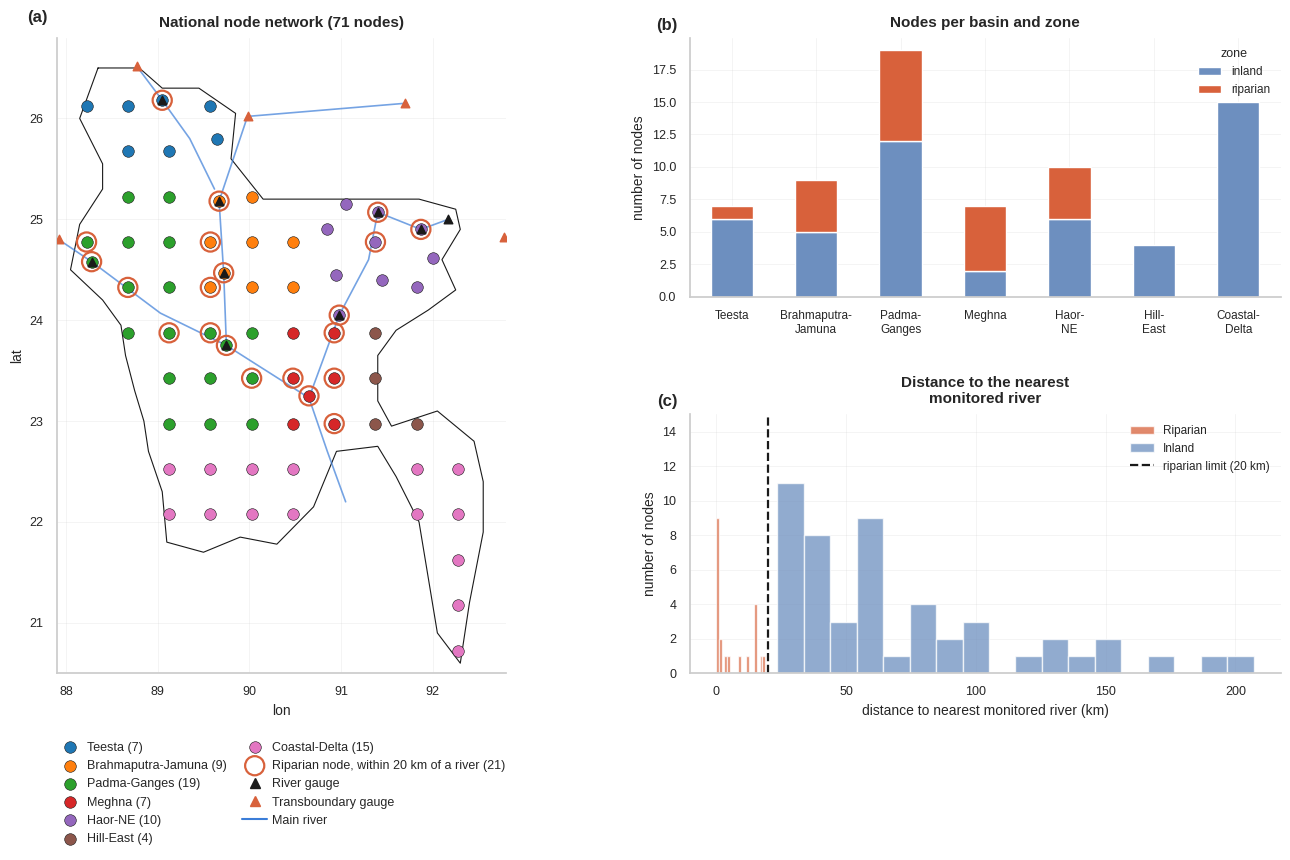

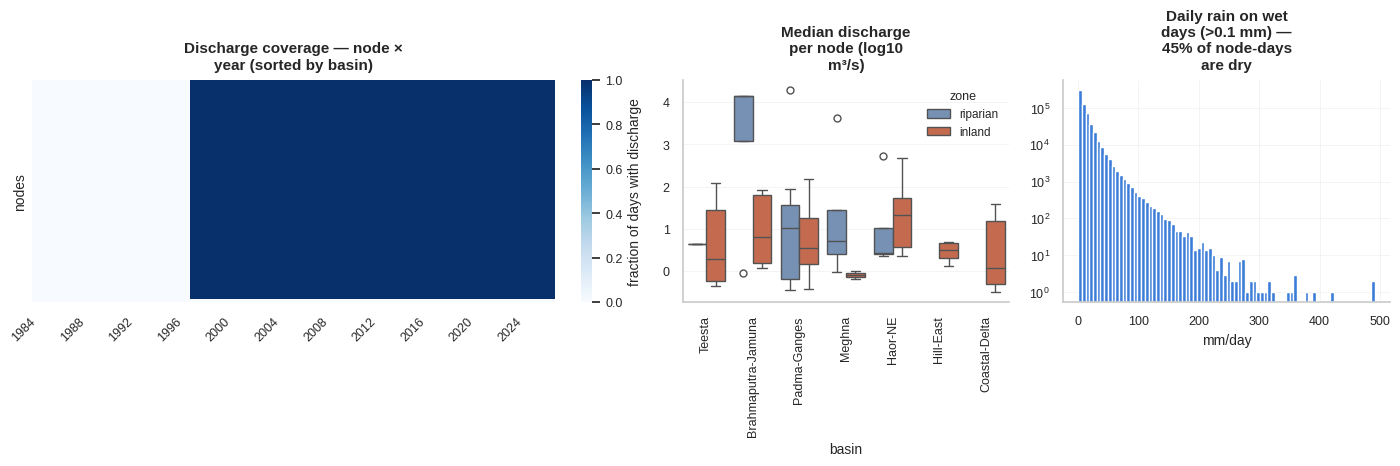

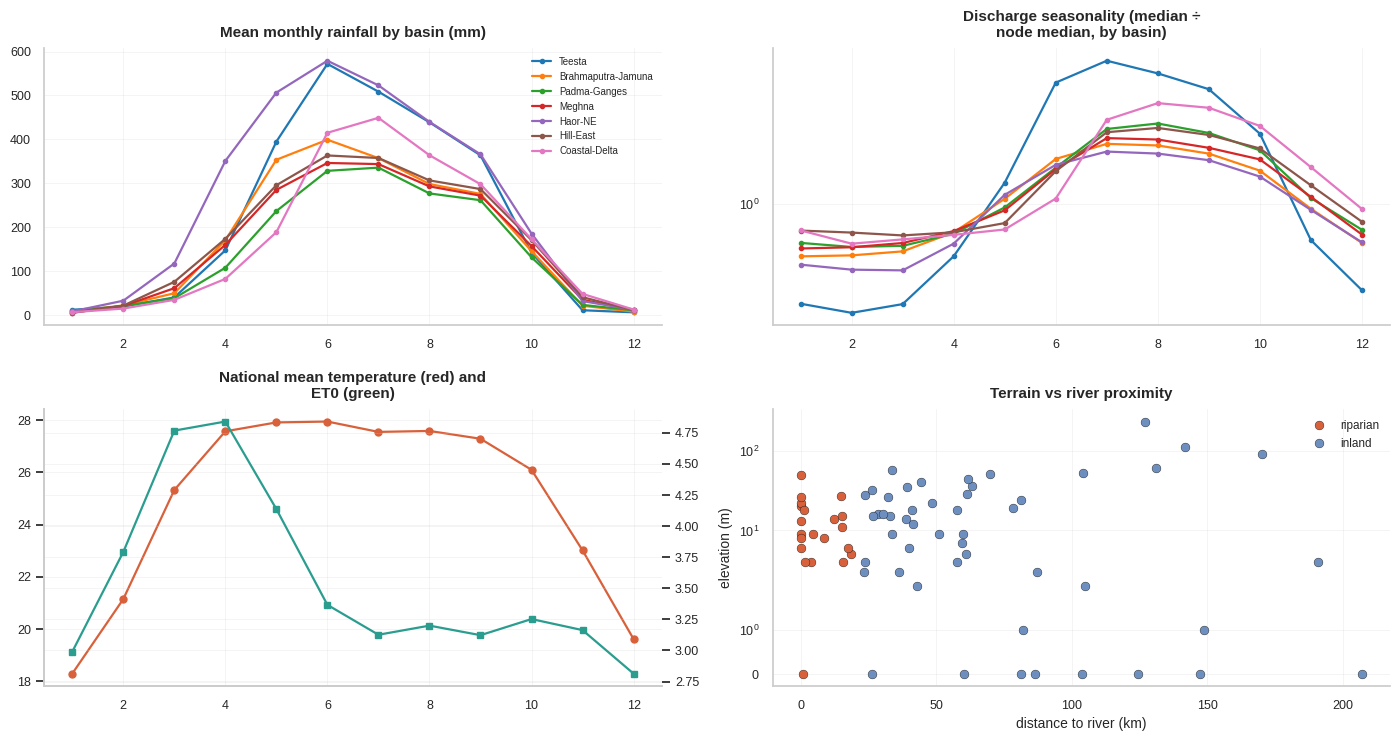

Basin summary:


,nodes,riparian,elev_m,slope_deg,q95_m3s,rain_mm_yr
basin,,,,,,
Brahmaputra-Jamuna,9,4,15.0,0.1,170.800003,2124.6
Coastal-Delta,14,0,1.5,0.0,6.300000,2102.4
Haor-NE,10,4,9.0,0.1,21.600000,3176.4
Hill-East,4,0,43.0,0.1,11.200000,2123.7
Meghna,7,5,5.0,0.0,8.500000,2005.8
Padma-Ganges,19,7,15.0,0.0,13.700000,1793.4
Teesta,7,1,36.0,0.0,33.799999,2678.0


Total modelling rows ≈ 763,910 node-days | 1984-01-01 → 2026-11-17 (43 years) | missing discharge 30.32% | missing rain 0.04%


In [10]:
# @title EDA 1 · Data coverage, quality & the national node network  (figures saved to results/eda/)
EDA = DIRS["results/eda"]; BP = dict(zip(BASINS, sns.color_palette("tab10", len(BASINS)))); _OUT = np.array(BD_POLY + [BD_POLY[0]])
def bd_map(ax, rivers=True, gauges=False, title=None):
    ax.plot(_OUT[:, 0], _OUT[:, 1], color="k", lw=.8)
    if rivers:
        for nm, pts in RIVER_SKELETON.items(): ax.plot([p[1] for p in pts], [p[0] for p in pts], color="#3b7dd8", lw=1.2, alpha=.7)
    if gauges:
        for g, (la, lo) in STATIONS.items(): ax.scatter(lo, la, marker="^", s=38, color="#d8613b" if g in TRANSBOUNDARY else "k", zorder=5)
    ax.set_xlim(87.9, 92.8); ax.set_ylim(20.5, 26.8); ax.set_aspect(1.1); ax.set_xlabel("lon"); ax.set_ylabel("lat")
    if title: ax.set_title(title)
def map_values(ax, vals, title, cmap="viridis", label="", s=95, vmin=None, vmax=None):
    sc = ax.scatter(NODES.loc[vals.index, "lon"], NODES.loc[vals.index, "lat"], c=vals.values, cmap=cmap, s=s, edgecolor="k", lw=.3, zorder=4, vmin=vmin, vmax=vmax); bd_map(ax, title=title); plt.colorbar(sc, ax=ax, shrink=.75, label=label)

# ---- Fig 1: the node network ----------------------------------------------------------------------------------------------------------------------------------------
fig = plt.figure(figsize=(13.5, 8.6), layout="constrained"); gs = fig.add_gridspec(2, 2, width_ratios=[1.12, 1]); ax = [fig.add_subplot(gs[:, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, 1])]
from matplotlib.lines import Line2D
bd_map(ax[0], gauges=True, title=f"National node network ({len(NODES)} nodes)")
for b in BASINS:
    m = NODES.basin == b; ax[0].scatter(NODES.lon[m], NODES.lat[m], s=70, color=BP[b], edgecolor="k", lw=.4, label=f"{b} ({int(m.sum())})", zorder=4)
r = NODES[NODES.ripar == 1]; ax[0].scatter(r.lon, r.lat, s=190, facecolor="none", edgecolor="#d8613b", lw=1.6, zorder=3, label=f"Riparian node, within {RIPARIAN_KM:.0f} km of a river ({len(r)})")
_h, _l = ax[0].get_legend_handles_labels(); _h += [Line2D([], [], marker="^", ls="", color="k", markersize=7), Line2D([], [], marker="^", ls="", color="#d8613b", markersize=7), Line2D([], [], color="#3b7dd8", lw=1.5)]; _l += ["River gauge", "Transboundary gauge", "Main river"]
ax[0].legend(_h, _l, loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=2, fontsize=9, columnspacing=1.2, handletextpad=0.4)
ct = NODES.groupby(["basin", "zone"]).size().unstack(fill_value=0).reindex(BASINS).fillna(0); ct.plot.bar(stacked=True, ax=ax[1], color=["#6d8fbf", "#d8613b"] if list(ct.columns) == ["inland", "riparian"] else None); ax[1].set_title("Nodes per basin and zone"); ax[1].set_xlabel(""); ax[1].set_ylabel("number of nodes"); ax[1].legend(title="zone", loc="upper right"); ax[1].set_xticklabels([str(b_).replace("-", "-\n") for b_ in ct.index], rotation=0, fontsize=8.5)
for z, c_ in (("riparian", "#d8613b"), ("inland", "#6d8fbf")): ax[2].hist(NODES.d_river_km[NODES.zone == z], bins=18, alpha=.75, color=c_, label=z.capitalize())
ax[2].set_ylabel("number of nodes"); ax[2].set_xlabel("distance to nearest monitored river (km)")
for a_, p_ in zip(ax, "abc"): a_.text(-0.02, 1.02, f"({p_})", transform=a_.transAxes, fontsize=12, fontweight="bold", ha="right", va="bottom")
ax[2].axvline(RIPARIAN_KM, color="k", ls="--", label=f"riparian limit ({RIPARIAN_KM:.0f} km)"); ax[2].set_title("Distance to the nearest monitored river"); ax[2].set_ylim(top=ax[2].get_ylim()[1] * 1.3); ax[2].legend(loc="upper right", ncol=1)
plt.savefig(f"{EDA}/E1_node_network.png"); plt.show(); plt.close("all")

# ---- Fig 2: coverage, missingness, distributions ---------------------------------------------------------------------------------------------------------------------
yrs = QN.index.year; order = NODES.sort_values(["basin_code", "d_river_km"]).index; cov = QN[order].notna().groupby(yrs).mean().T
fig, ax = plt.subplots(1, 3, figsize=(21, 7), gridspec_kw={"width_ratios": [1.6, 1, 1]})
sns.heatmap(cov, cmap="Blues", vmin=0, vmax=1, ax=ax[0], yticklabels=False, cbar_kws={"label": "fraction of days with discharge"}); ax[0].set_title("Discharge coverage — node × year (sorted by basin)"); ax[0].set_ylabel("nodes")
lq = np.log10(QN[NODE_IDS].where(QN[NODE_IDS] > 0).median()).rename("log10 median Q"); dfp = pd.DataFrame({"basin": NODES.loc[NODE_IDS, "basin"].values, "zone": NODES.loc[NODE_IDS, "zone"].values, "v": lq.values})
sns.boxplot(data=dfp, x="basin", y="v", hue="zone", order=BASINS, ax=ax[1], palette=["#6d8fbf", "#d8613b"]); ax[1].tick_params(axis="x", rotation=45); ax[1].set_title("Median discharge per node (log10 m³/s)")
pp = PR[NODE_IDS].values.ravel(); pp = pp[np.isfinite(pp)]; ax[2].hist(pp[pp > 0.1], bins=80, color="#3b7dd8"); ax[2].set_yscale("log"); ax[2].set_title(f"Daily rain on wet days (>0.1 mm) — {100*(pp<=0.1).mean():.0f}% of node-days are dry"); ax[2].set_xlabel("mm/day")
plt.savefig(f"{EDA}/E1_coverage_distributions.png"); plt.show(); plt.close("all")

# ---- Fig 3: climatology by basin ------------------------------------------------------------------------------------------------------------------------------------
mo = PR.index.month; rain_m = {b: PR[[n for n in NODE_IDS if NODES.at[n, "basin"] == b]].mean(axis=1).groupby(mo).mean() * 30.4 for b in BASINS}
rat = QN[NODE_IDS] / QN[NODE_IDS].median(); q_m = {b: rat[[n for n in NODE_IDS if NODES.at[n, "basin"] == b]].median(axis=1).groupby(mo).median() for b in BASINS}
fig, ax = plt.subplots(2, 2, figsize=(17, 9))
for b in BASINS: ax[0, 0].plot(rain_m[b].index, rain_m[b].values, color=BP[b], label=b, marker="o", ms=3); ax[0, 1].plot(q_m[b].index, q_m[b].values, color=BP[b], marker="o", ms=3)
ax[0, 0].set_title("Mean monthly rainfall by basin (mm)"); ax[0, 0].legend(fontsize=7); ax[0, 1].set_title("Discharge seasonality (median ÷ node median, by basin)"); ax[0, 1].set_yscale("log")
ax[1, 0].plot(TP[NODE_IDS].mean(axis=1).groupby(mo).mean(), color="#d8613b", marker="o", label="temperature °C"); ax2 = ax[1, 0].twinx(); ax2.plot(ET[NODE_IDS].mean(axis=1).groupby(mo).mean(), color="#2a9d8f", marker="s", label="ET0 mm/d"); ax[1, 0].set_title("National mean temperature (red) and ET0 (green)")
for z, c in (("riparian", "#d8613b"), ("inland", "#6d8fbf")): m = NODES.zone == z; ax[1, 1].scatter(NODES.d_river_km[m], NODES.elev_m[m], s=40, color=c, label=z, edgecolor="k", lw=.3)
ax[1, 1].set_yscale("symlog"); ax[1, 1].set_xlabel("distance to river (km)"); ax[1, 1].set_ylabel("elevation (m)"); ax[1, 1].set_title("Terrain vs river proximity"); ax[1, 1].legend()
plt.savefig(f"{EDA}/E1_climatology.png"); plt.show(); plt.close("all")
S = NODES.loc[NODE_IDS].groupby("basin").agg(nodes=("lat", "size"), riparian=("ripar", "sum"), elev_m=("elev_m", "median"), slope_deg=("slope_deg", "median"), q95_m3s=("q95_all", "median"))
S["rain_mm_yr"] = [float(PR[[n for n in NODE_IDS if NODES.at[n, "basin"] == b]].mean(axis=1).mean() * 365.25) for b in S.index]; print("Basin summary:"); show(S, 1)
print(f"Total modelling rows ≈ {int(sum(QN[n].notna().sum() for n in NODE_IDS)):,} node-days | {QN.index.min().date()} → {QN.index.max().date()} ({QN.index.year.nunique()} years) | missing discharge {100*QN[NODE_IDS].isna().mean().mean():.2f}% | missing rain {100*PR[NODE_IDS].isna().mean().mean():.2f}%")


## 8 · Feature engineering (spatial lags, transboundary weights, API windows, riparian context)

In [11]:
# @title 8 · Feature engineering — rain lags · windowed API (3/7/14 d) · prewhitened routing · dynamic upstream & TRANSBOUNDARY weights · release spikes · SPATIAL lags · riparian context
# Everything *learned* (thresholds, travel-time lags, weights, spike scales) is re-fitted on the TRAINING period of every walk-forward fold. Feature code is identical for training and live serving.
def _ar2_innovations(x):
    """AR(2) pre-whitening → innovations. Removes the strong day-to-day persistence of smooth GloFAS discharge, which otherwise makes every cross-correlation peak at lag 1."""
    v = x.to_numpy(np.float64); X = np.column_stack([v[1:-1], v[:-2]]); y = v[2:]; ok = np.isfinite(X).all(1) & np.isfinite(y)
    if ok.sum() < 50: return pd.Series(np.nan, x.index)
    a = np.linalg.lstsq(X[ok], y[ok], rcond=None)[0]; e = np.full(len(v), np.nan); e[2:] = y - X @ a; return pd.Series(e, x.index)

def _api(x, k, win):
    """Antecedent Precipitation Index over a FIXED window: API_t = Σ_{i<win} k^i · P_{t-i} (fixed window ⇒ identical in training and live serving)."""
    w = k ** np.arange(win); v = np.nan_to_num(x.to_numpy(np.float64), nan=0.0); out = np.convolve(v, w)[:len(v)]; out[:win - 1] = np.nan; return pd.Series(out, x.index)

def fit_all(train_last):
    """Fit everything learnable on data ≤ train_last ONLY: node & gauge thresholds, spike scales, rain-API scale, and the upstream→node routing (lag + weight) matrix."""
    Qn = QN.loc[:train_last, NODE_IDS].astype("float64"); Qg = QG.loc[:train_last].astype("float64"); Ln, Lg = np.log1p(Qn), np.log1p(Qg); gd1 = Lg.diff(1); gd3 = Lg.diff(3)
    fit = dict(train_last=str(pd.Timestamp(train_last).date()), nq95=Qn.quantile(FLOOD_Q).to_dict(), nq90=Qn.quantile(.90).to_dict(), nq99=Qn.quantile(.99).to_dict(),
               gq95=Qg.quantile(FLOOD_Q).to_dict(), g_d1_med=gd1.median().to_dict(), g_d1_mad=((gd1 - gd1.median()).abs().median() * 1.4826 + 1e-4).to_dict(),
               g_rise_scale=gd3.clip(lower=0).where(gd3 > 0).quantile(.9).fillna(.1).to_dict(), api7_q95={}, route={})
    P = PR.loc[:train_last, NODE_IDS]
    for n in NODE_IDS: fit["api7_q95"][n] = float(np.nanquantile(_api(P[n], API_WIN_K, 7).values, .95) + 1e-3)
    En = Ln.diff(1).apply(_ar2_innovations); Eg = gd1.apply(_ar2_innovations); mon = En.index.month.isin(range(5, 11))
    for n in NODE_IDS:
        rows = []
        for c in CAND[n]:
            g = c["g"]; cc = {}
            for lag in range(1, MAX_LAG + 1):                                    # a usable predictor must be lagged by ≥ 1 day
                v = En.loc[mon, n].corr(Eg[g].shift(lag).loc[mon])
                if np.isfinite(v): cc[lag] = v
            lag, r = max(cc.items(), key=lambda kv: kv[1]) if cc else (c["prior_lag"], 0.0); spread = np.median(np.abs(list(cc.values()))) if cc else 1.0
            if r >= 0.10 and r >= 1.5 * spread: src = "learned"
            else: lag, r, src = c["prior_lag"], cc.get(c["prior_lag"], 0.0), "prior"          # data uninformative → hydraulic prior (distance / celerity)
            rows.append(dict(g=g, lag=int(lag), corr=float(r), prior_lag=c["prior_lag"], lag_source=src, tb=c["tb"], d_km=c["d_km"], w_raw=max(r, 0.05) ** 2 * c["w_prior"]))
        s = sum(r["w_raw"] for r in rows)
        for r in rows: r["w0"] = r["w_raw"] / s
        fit["route"][n] = rows
    return fit

def node_features(n, fit, QN_, QG_, PR_, ET_, TP_, UPR_):
    """Causal (backward-looking) features of one node. Groups: hd_ node hydrology · up_ upstream (dynamic weights) · tb_ transboundary · rn_ local rain/API · ss_ season."""
    idx = QN_.index; q = QN_[n].astype("float64"); thr = max(fit["nq95"][n], 1e-3); r = q / thr; lq = np.log1p(q); d1 = lq.diff(1); f = {}
    f["hd_ratio"] = r
    for L in (1, 2, 3, 7): f[f"hd_ratio_lag{L}"] = r.shift(L)
    for W in (3, 7, 14): f[f"hd_ratio_mean{W}"] = r.rolling(W, min_periods=W // 2 + 1).mean()
    f["hd_ratio_max7"] = r.rolling(7, min_periods=4).max(); f["hd_ratio_max12"] = r.rolling(12, min_periods=6).max()
    f["hd_dlog1"], f["hd_dlog3"], f["hd_dlog7"] = d1, lq.diff(3), lq.diff(7); f["hd_dlog_std7"] = d1.rolling(7, min_periods=4).std()
    f["hd_ratio_q90"] = q / max(fit["nq90"][n], 1e-3); f["hd_ratio_q99"] = q / max(fit["nq99"][n], 1e-3)
    f["hd_accel"] = d1 - d1.shift(1); l3 = lq.diff(3); f["hd_accel3"] = l3 - l3.shift(3)                                                            # v6: is the rise speeding up?
    f["hd_days_to_thr"] = ((np.log1p(thr) - lq) / (l3 / 3).clip(lower=1e-3)).clip(lower=0, upper=30)                                                   # days until q95 at the CURRENT rise rate
    f["hd_ratio_vs_min7"] = r / r.rolling(7, min_periods=4).min().clip(lower=1e-3); f["hd_gap"] = (1 - r).clip(lower=-2)
    above = (q >= thr).astype("float64"); f["hd_days_above7"] = above.rolling(7, min_periods=1).sum()
    pos = np.arange(len(idx)); last = pd.Series(np.where(above.values == 1, pos, np.nan), idx).ffill(); f["hd_days_since_exceed"] = (pos - last).fillna(30).clip(upper=30)
    route = fit["route"][n]; R, RISE, SP, WD = [], [], [], []
    for rt in route:
        g, L = rt["g"], rt["lag"]; qg = QG_[g].astype("float64"); lg = np.log1p(qg)
        rise = (lg.diff(3).clip(lower=0) / fit["g_rise_scale"][g]).shift(L); z = ((lg.diff(1) - fit["g_d1_med"][g]) / fit["g_d1_mad"][g]).shift(L)
        R.append((qg / fit["gq95"][g]).shift(L).values); RISE.append(rise.values); SP.append(z.values)
        WD.append(rt["w0"] * (1 + DYN_GAIN * np.clip(np.nan_to_num(rise.values), 0, 3)))                 # a fast-rising upstream gauge gets more weight → DYNAMIC weights
    R, RISE, SP, WD = (np.column_stack(a) for a in (R, RISE, SP, WD))
    ok = np.isfinite(R); WD = np.where(ok, WD, 0.0); den = WD.sum(1); Wn = np.divide(WD, den[:, None], out=np.zeros_like(WD), where=den[:, None] > 0)
    Rz = np.nan_to_num(R); w0 = np.array([rt["w0"] for rt in route]); w0m = np.where(ok, w0, 0.0); d0 = w0m.sum(1)
    P = pd.Series(np.where(den > 0, (Wn * Rz).sum(1), np.nan), idx); f["up_pressure"] = P
    f["up_pressure_static"] = pd.Series(np.where(d0 > 0, (w0m * Rz).sum(1) / np.where(d0 > 0, d0, 1), np.nan), idx)
    f["up_pressure_d1"] = P.diff(1); f["up_pressure_d3"] = P.diff(3); f["up_pressure_max7"] = P.rolling(7, min_periods=4).max(); f["up_pressure_mean7"] = P.rolling(7, min_periods=4).mean()
    f["up_peak_ratio"] = pd.Series(np.where(ok.any(1), np.max(np.where(ok, R, -np.inf), axis=1), np.nan), idx)
    f["up_rise3"] = pd.Series(np.where(den > 0, (Wn * np.nan_to_num(RISE)).sum(1), np.nan), idx)
    f["up_flow_ratio"] = pd.Series(sum(QG_[rt["g"]].astype("float64").shift(rt["lag"]).values for rt in route) / (q.values + 1.0), idx)
    spk = np.where(np.isfinite(SP), SP, -np.inf); zmax = spk.max(1); f["up_spike_z"] = pd.Series(np.where(np.isfinite(zmax), zmax, np.nan), idx)
    f["up_spike_cnt7"] = pd.Series((np.where(np.isfinite(SP), SP, 0) > SPIKE_Z).sum(1), idx).rolling(7, min_periods=1).sum()              # barrage / dam-release proxy
    tb = [i for i, rt in enumerate(route) if rt["tb"]]                                                                                    # ---- transboundary upstream→downstream weight matrix ----
    if tb:
        wt = w0[tb]; okt = ok[:, tb]; ws = np.where(okt, wt, 0).sum(1)
        f["tb_pressure"] = pd.Series(np.where(ws > 0, (np.nan_to_num(R[:, tb]) * np.where(okt, wt, 0)).sum(1) / np.where(ws > 0, ws, 1), np.nan), idx)
        f["tb_rise3"] = pd.Series(np.where(ws > 0, (np.nan_to_num(RISE[:, tb]) * np.where(okt, wt, 0)).sum(1) / np.where(ws > 0, ws, 1), np.nan), idx)
        f["tb_spike_z"] = pd.Series(np.where(okt.any(1), np.max(np.where(np.isfinite(SP[:, tb]), SP[:, tb], -np.inf), axis=1), np.nan), idx).replace(-np.inf, np.nan)
        f["tb_weight_share"] = pd.Series(np.where(den > 0, WD[:, tb].sum(1) / np.where(den > 0, den, 1), np.nan), idx)
    else:
        for k in ("tb_pressure", "tb_rise3", "tb_spike_z", "tb_weight_share"): f[k] = pd.Series(np.nan, idx)
    Pr = PR_[n].astype("float64"); et = ET_[n].astype("float64"); tp = TP_[n].astype("float64")
    for W in (1, 3, 7, 14, 30): f[f"rn_sum{W}"] = Pr.rolling(W, min_periods=max(1, W // 2)).sum()
    for W in API_WINDOWS: f[f"rn_api_w{W}"] = _api(Pr, API_WIN_K, W)                                                                      # windowed Antecedent Precipitation Index (soil saturation)
    for k in API_K: f[f"rn_api{int(round(k * 100))}"] = _api(Pr, k, API_WINDOW)
    f["rn_api7_rel"] = f["rn_api_w7"] / fit["api7_q95"][n]
    f["rn_max7"] = Pr.rolling(7, min_periods=4).max(); f["rn_et0_mean7"] = et.rolling(7, min_periods=4).mean(); f["rn_temp_mean7"] = tp.rolling(7, min_periods=4).mean()
    f["rn_balance14"] = Pr.rolling(14, min_periods=7).sum() - et.rolling(14, min_periods=7).sum()
    up_p = pd.concat([UPR_[k].astype("float64") for k in NODES.at[n, "rain_up"].split(",")], axis=1).mean(axis=1)
    for W in (3, 7, 14): f[f"rn_up_sum{W}"] = up_p.rolling(W, min_periods=max(1, W // 2)).sum()
    f["rn_up_api85"] = _api(up_p, .85, API_WINDOW)
    doy = idx.dayofyear.values; f["ss_sin"] = pd.Series(np.sin(2 * np.pi * doy / 365.25), idx); f["ss_cos"] = pd.Series(np.cos(2 * np.pi * doy / 365.25), idx)
    f["ss_monsoon"] = pd.Series(((idx.month >= 6) & (idx.month <= 9)).astype(float), idx)
    return pd.DataFrame(f, index=idx).astype("float32")

def make_labels(n, fit, QN_):
    """flood_next3 = 1 if the node exceeds its (training-only) q95 on ANY of days t+1…t+HORIZON. flood_now = above threshold today (persistence). quiet4 = below threshold on t-3…t ⇒ a genuine ONSET day when y=1."""
    q = QN_[n].astype("float64"); ex = (q >= fit["nq95"][n]).astype(float).where(q.notna()); fut = pd.concat([ex.shift(-h) for h in range(1, HORIZON + 1)], axis=1); r4 = ex.rolling(4, min_periods=4).max()
    return pd.DataFrame({"y": fut.max(axis=1, skipna=False), "flood_now": ex, "quiet4": (r4 == 0).astype(float).where(r4.notna())}, index=q.index)

STATIC_COLS = {"st_lat": "lat", "st_lon": "lon", "st_elev": "elev_m", "st_slope": "slope_deg", "st_relief": "relief_m", "st_hand": "hand_m", "st_dist_river": "d_river_km",
               "st_ripar": "ripar", "st_ripar_score": "ripar_score", "st_basin": "basin_code"}
def spatial_lag_frames(fit, QN_, PR_, nodes):
    """Spatial-lag features: inverse-distance-weighted mean (and max) over each node's K nearest neighbours of discharge ratio, 3-day rain and API; plus a 2-day lag of the neighbour ratio."""
    ix = [list(NODES.index).index(n) for n in nodes]; W = WSP[np.ix_(ix, ix)]; W = W / np.maximum(W.sum(1, keepdims=True), 1e-9)
    RAT = (QN_[nodes].astype("float64") / pd.Series({n: max(fit["nq95"][n], 1e-3) for n in nodes})).values
    R3 = PR_[nodes].astype("float64").rolling(3, min_periods=2).sum().values; A7 = np.column_stack([_api(PR_[n].astype("float64"), API_WIN_K, 7).values for n in nodes])
    def nbmean(M):
        fin = np.isfinite(M); num = np.nan_to_num(M) @ W.T; dn = fin.astype(float) @ W.T; return np.where(dn > 0, num / np.maximum(dn, 1e-9), np.nan)
    out = {"sp_ratio_nb": nbmean(RAT), "sp_rain3_nb": nbmean(R3), "sp_api7_nb": nbmean(A7)}
    NBm = [[int(j) for j in np.argsort(-W[i])[:K_NEIGH] if W[i, j] > 0] for i in range(len(nodes))]
    mx = np.full_like(RAT, np.nan)
    for i in range(len(nodes)):
        if len(NBm[i]): mx[:, i] = np.nanmax(RAT[:, NBm[i]], axis=1)
    out["sp_ratio_nbmax"] = mx; D = {k: pd.DataFrame(v, index=QN_.index, columns=nodes) for k, v in out.items()}
    D["sp_ratio_nb_lag2"] = D["sp_ratio_nb"].shift(2); return {k: v.astype("float32") for k, v in D.items()}

def build_panel(fit, keep, nodes=None, data=None, live=False):
    """Node × day panel (features + labels) for ONE fit. keep(index) → boolean mask of the rows to retain (training stride / test years / live last day)."""
    d = data or dict(QN=QN, QG=QG, PR=PR, ET=ET, TP=TP, UPR=UPR); nodes = nodes or NODE_IDS; QN_, QG_, PR_, ET_, TP_, UPR_ = (d[k] for k in ("QN", "QG", "PR", "ET", "TP", "UPR"))
    SPF = spatial_lag_frames(fit, QN_, PR_, nodes); parts = []; idx = QN_.index; kp = np.asarray(keep(idx), bool); warm = np.arange(len(idx)) >= 31
    for n in nodes:
        F = node_features(n, fit, QN_, QG_, PR_, ET_, TP_, UPR_); L = make_labels(n, fit, QN_)
        for k, v in SPF.items(): F[k] = v[n].values
        D = pd.concat([F, L], axis=1).loc[kp & warm]; D.insert(0, "node", n); D.insert(1, "date", D.index); parts.append(D)
    P = pd.concat(parts, ignore_index=True); del parts
    for c in ("y", "flood_now", "quiet4"): P[c] = P[c].astype("float32")
    P = P.dropna(subset=["flood_now", "quiet4", "hd_ratio", "rn_sum30"]).reset_index(drop=True)
    if live: P["y"] = P["y"].fillna(0)                                                       # live serving: the future label does not exist yet
    nd = NODES.reindex(P.node.values)
    for c, src in STATIC_COLS.items(): P[c] = nd[src].values.astype("float32")
    P["st_log_thr"] = np.log1p(P.node.map(fit["nq95"]).values.astype("float32")); P["st_n_cand"] = np.float32(len(CAND[nodes[0]]))
    P["cx_river_drive"] = P.st_ripar_score * P.up_pressure; P["cx_tb_drive"] = P.st_ripar_score * P.tb_pressure          # context-aware interactions: riparian → upstream-driven
    P["cx_local_drive"] = (1 - P.st_ripar_score) * P.rn_api7_rel; P["cx_rain_x_wet"] = P.rn_sum3 * np.clip(P.rn_api7_rel, 0, 5)      # inland → rain / soil-saturation-driven
    FE = [c for c in P.columns if c.startswith(("hd_", "up_", "tb_", "rn_", "sp_", "st_", "ss_", "cx_", "ex_"))]
    P[FE] = P[FE].replace([np.inf, -np.inf], np.nan).astype("float32"); P["zone"] = nd["zone"].values; P["basin"] = nd["basin"].values
    P = P[P.y.notna()].reset_index(drop=True)
    for c in ("y", "flood_now", "quiet4"): P[c] = P[c].astype("uint8")
    return P, FE

GROUPS = {"hd": "node hydrology", "up": "upstream (dynamic weights)", "tb": "transboundary", "rn": "local rain / API", "sp": "spatial lag", "st": "static geography", "ss": "season", "cx": "riparian-context interactions"}
_FIT_PREVIEW = fit_all(pd.Timestamp(max(DEV_FOLDS), 12, 31))
RT = pd.DataFrame([dict(node=n, **{k: r[k] for k in ("g", "lag", "prior_lag", "lag_source", "tb", "d_km", "w0")}, corr=round(r["corr"], 2)) for n, rr in _FIT_PREVIEW["route"].items() for r in rr])
print(f"Learned upstream→node routing (prewhitened CCF, data ≤ {_FIT_PREVIEW['train_last']}): {len(RT)} (node, gauge) pairs | learned {int((RT.lag_source=='learned').sum())} / prior {int((RT.lag_source=='prior').sum())} | lag distribution:", RT.lag.value_counts().sort_index().to_dict())


Learned upstream→node routing (prewhitened CCF, data ≤ 2024-12-31): 420 (node, gauge) pairs | learned 116 / prior 304 | lag distribution: {1: 168, 2: 79, 3: 57, 4: 48, 5: 29, 6: 20, 7: 19}


### 8b · Extra data sources (CHIRPS · ERA5-Land)

In [12]:
# @title 8b · EXTRA DATA SOURCES — CHIRPS rain · ERA5-Land soil water / runoff / snow-melt (at the nodes AND at the upstream catchment points) via Earth Engine · latency-aware · cached on Drive · each must earn its place in the shoot-out
XS_FRAMES, XS_LAG, XS_READY, XS_NOTE = {}, {}, False, "extra sources disabled (USE_EXTRA=False)"
XS_DIR = f"{BASE}/raw_apis/extra"; os.makedirs(XS_DIR, exist_ok=True)
XS_SPEC = {"chirps": dict(coll="UCSB-CHG/CHIRPS/DAILY", bands={"precipitation": "chirps"}, scale=5566, mult={}),
           "era5l": dict(coll="ECMWF/ERA5_LAND/DAILY_AGGR", bands={"total_precipitation_sum": "e5_rain", "volumetric_soil_water_layer_1": "e5_sm1", "surface_runoff_sum": "e5_ro", "snowmelt_sum": "e5_melt"}, scale=11132, mult={"e5_rain": 1000.0, "e5_ro": 1000.0, "e5_melt": 1000.0})}
XS_VAR_SRC = {v: s for s, c in XS_SPEC.items() for v in c["bands"].values()}
XS_POINTS = {**{n: (float(r.lat), float(r.lon)) for n, r in zip(NODES.index, NODES.itertuples())}, **{k: (float(v[0]), float(v[1])) for k, v in UP_RAIN.items()}}
XS_IDX = pd.date_range(XS_START, TODAY, freq="D")

def xs_fetch_chunk(src, s, e):
    """One (source × ≤ 4 000-point) request: point samples of every node/upstream point for the days s…e → tidy DataFrame (pid, d, variables)."""
    import ee
    cfg = XS_SPEC[src]; bands = list(cfg["bands"]); pts = ee.FeatureCollection([ee.Feature(ee.Geometry.Point([lo, la]), {"pid": k}) for k, (la, lo) in XS_POINTS.items()])
    col = ee.ImageCollection(cfg["coll"]).filterDate(s.strftime("%Y-%m-%d"), (e + pd.Timedelta(days=1)).strftime("%Y-%m-%d")).select(bands)
    per = lambda img: img.reduceRegions(collection=pts, reducer=ee.Reducer.first().forEach(bands), scale=cfg["scale"]).map(lambda ft: ft.set("d", img.date().format("YYYY-MM-dd")))
    feats = col.map(per).flatten().getInfo()["features"]
    return pd.DataFrame([dict(pid=x["properties"]["pid"], d=x["properties"]["d"], **{cfg["bands"][b]: x["properties"].get(b, np.nan) for b in bands}) for x in feats])

def xs_load(src):
    days = max(5, int(4000 // len(XS_POINTS))); edges = []; s = pd.Timestamp(XS_START)
    while s <= TODAY: e = min(s + pd.Timedelta(days=days - 1), TODAY); edges.append((s, e)); s = e + pd.Timedelta(days=1)
    def one(se):
        s, e = se; p = f"{XS_DIR}/{src}_{s:%Y%m%d}_{e:%Y%m%d}.parquet"; final = e < TODAY - pd.Timedelta(days=120)
        if os.path.exists(p) and (final or dt.date.fromtimestamp(os.path.getmtime(p)) >= TODAY.date()):
            d = pd.read_parquet(p)
            if d.drop(columns=[c for c in ("pid", "d") if c in d.columns]).notna().any().any(): return d      # a cached chunk that is all-NaN (earlier bug / outage) is re-fetched
        for t in range(3):
            try:
                d = xs_fetch_chunk(src, s, e)
                if d.empty or not d.drop(columns=["pid", "d"]).notna().any().any(): raise ValueError(f"{src} {s:%Y-%m-%d}…{e:%Y-%m-%d}: Earth Engine returned no values")
                d.to_parquet(p, compression="zstd", index=False); return d
            except Exception as err:
                if t == 2:
                    if "no values" in str(err) and e >= TODAY - pd.Timedelta(days=1): return pd.DataFrame(columns=["pid", "d"] + list(XS_SPEC[src]["bands"].values()))      # newest days not published yet (CHIRPS lags weeks): keep older chunks, latency is measured from the last valid day
                    raise
                time.sleep(4 * (t + 1))
    with ThreadPoolExecutor(min(EE_WORKERS, 4)) as ex: parts = list(ex.map(one, edges))      # ≤ 4 parallel requests → far fewer HTTP 429 (rate-limit) retries
    D = pd.concat(parts, ignore_index=True); D["d"] = pd.to_datetime(D.d); out = {}
    for v, m in zip(XS_SPEC[src]["bands"].values(), [XS_SPEC[src]["mult"].get(v, 1.0) for v in XS_SPEC[src]["bands"].values()]):
        out[v] = (D.pivot_table(index="d", columns="pid", values=v, aggfunc="last") * m).reindex(XS_IDX).astype("float32")
    return out

def xs_synth(src):
    """DRY_RUN only: derive plausible extra sources from the synthetic weather so the whole code path (latency shift, features, shoot-out) is exercised."""
    rng = np.random.default_rng(7); idx = XS_IDX; out = {}; doy = idx.dayofyear.values
    def base(name): return (PR[name] if name in PR.columns else UPR[name]).reindex(idx).astype("float64") if (name in PR.columns or name in UPR.columns) else pd.Series(0.0, idx)
    cols = list(XS_POINTS); R = pd.DataFrame({c: base(c) for c in cols}, index=idx)
    if src == "chirps": out["chirps"] = (R * rng.lognormal(0, .25, R.shape)).astype("float32")
    else:
        out["e5_rain"] = (R * rng.lognormal(0, .2, R.shape)).astype("float32"); api = pd.DataFrame({c: _api(R[c].fillna(0), .85, 14) for c in cols}, index=idx)
        out["e5_sm1"] = (0.15 + 0.3 * (api / (api.quantile(.99) + 1e-6)).clip(0, 1)).astype("float32"); out["e5_ro"] = (np.maximum(R - 12, 0) * .4).astype("float32")
        melt = np.maximum(0, np.sin(2 * np.pi * (doy - 60) / 365.25)) * 6; out["e5_melt"] = pd.DataFrame({c: (melt * (1 if c.startswith("rain_") else 0) * rng.uniform(.7, 1.3, len(idx))) for c in cols}, index=idx).astype("float32")
    return out

if USE_EXTRA and (DRY_RUN or EE_READY):
    got = []
    for src in XS_SPEC:
        try:
            fr = xs_synth(src) if DRY_RUN else xs_load(src)
            last = min(f.dropna(how="all").index.max() for f in fr.values())
            if pd.isna(last): raise ValueError("no valid values returned")
            lat = int((TODAY - last).days); lag = next((b for b in (1, 2, 3, 5, 7, 10, 14, 21, 30, 45) if b >= max(lat, 1)), None)
            if DRY_RUN: lat, lag = 2, 3
            if lag is None or lat > XS_MAX_LATENCY: got.append(f"{src}: DROPPED (data arrive {lat} d late > {XS_MAX_LATENCY} d — not usable operationally)"); continue
            XS_FRAMES.update(fr); XS_LAG[src] = lag; got.append(f"{src}: {len(fr)} variables, latency {lat} d → features use the value of day t−{lag} (identical in training and live)")
        except Exception as err: got.append(f"{src}: UNAVAILABLE ({type(err).__name__}: {str(err)[:120]})")
    XS_READY = bool(XS_FRAMES); XS_NOTE = " | ".join(got); print("🛰️ extra sources:", *got, sep="\n   ")
else: print("🛰️ extra sources skipped (USE_EXTRA=False or Earth Engine not ready).")

_XS_CACHE = {}
def xs_node_features(n):
    """Fit-independent (no learned parameters) features of the extra sources for one node; cached. Prefix ex_ (node point) / ex_up_ (mean over the node's upstream catchment points)."""
    if n in _XS_CACHE: return _XS_CACHE[n]
    ups = [u for u in NODES.at[n, "rain_up"].split(",") if u in XS_POINTS]; f = {}
    def S(v, cols):
        if v not in XS_FRAMES: return None
        cs = [c for c in cols if c in XS_FRAMES[v].columns]
        return None if not cs else XS_FRAMES[v][cs].astype("float64").mean(axis=1).shift(XS_LAG[XS_VAR_SRC[v]])
    def roll(s, W, fn="sum"): r = s.rolling(W, min_periods=max(1, W // 2)); return getattr(r, fn)()
    s = S("chirps", [n])
    if s is not None:
        for W in (3, 7, 14): f[f"ex_chirps_sum{W}"] = roll(s, W)
        f["ex_chirps_api"] = _api(s.fillna(0), .85, 14)
    s = S("chirps", ups)
    if s is not None: f["ex_up_chirps_sum7"] = roll(s, 7); f["ex_up_chirps_sum14"] = roll(s, 14)
    s = S("e5_sm1", [n])
    if s is not None: f["ex_e5_sm1"] = s; f["ex_e5_sm1_d7"] = s - s.shift(7)
    s = S("e5_ro", [n])
    if s is not None: f["ex_e5_ro_sum3"] = roll(s, 3); f["ex_e5_ro_sum7"] = roll(s, 7)
    for v, nm in (("e5_melt", "melt"), ("e5_sm1", "sm1"), ("e5_ro", "ro")):
        s = S(v, ups)
        if s is None: continue
        if nm == "melt": f["ex_up_e5_melt_sum7"] = roll(s, 7); f["ex_up_e5_melt_sum30"] = roll(s, 30)
        elif nm == "sm1": f["ex_up_e5_sm1"] = s
        else: f["ex_up_e5_ro_sum7"] = roll(s, 7)
    D = pd.DataFrame(f, index=XS_IDX).astype("float32") if f else pd.DataFrame(index=XS_IDX); _XS_CACHE[n] = D; return D

def _nf_inner(fn, layer):      # re-running a feature-layer cell must NOT wrap the already-wrapped function again (that caused "RecursionError" when a cell was run twice)
    f = fn
    while hasattr(f, "_nf_layer"):
        if f._nf_layer == layer: return f._nf_base
        f = f._nf_base
    return fn
_node_features_core = _nf_inner(node_features, "xs")
def node_features(n, fit, QN_, QG_, PR_, ET_, TP_, UPR_):
    """v8: the v6 features + the extra-source features (aligned to whatever index the caller uses — full history in training, the last 60 days in live scoring)."""
    F = _node_features_core(n, fit, QN_, QG_, PR_, ET_, TP_, UPR_)
    if XS_READY:
        X = xs_node_features(n)
        if X.shape[1]: F = F.join(X.reindex(F.index))
    return F
GROUPS["ex"] = "extra sources (CHIRPS · ERA5-Land soil water / runoff / snow-melt)"
print(f"ℹ️ extra-source feature columns per node: {xs_node_features(NODES.index[0]).shape[1] if XS_READY else 0}")
node_features._nf_layer, node_features._nf_base = "xs", _node_features_core


🛰️ extra sources:
   chirps: DROPPED (data arrive 48 d late > 45 d — not usable operationally)
   era5l: 4 variables, latency 9 d → features use the value of day t−10 (identical in training and live)
ℹ️ extra-source feature columns per node: 8


### 8b2 · Data-source registry (keyless APIs · flags · replaceable)

In [13]:
# @title 8b2 · DATA-SOURCE REGISTRY — keyless web APIs (Open-Meteo ERA5-Land · NASA POWER) · every source has an ON/OFF flag, a replaceable URL / parameters / parser (or your own fetch function) · live pre-flight test · latency-aware · cached
# ╔═══════════════════════════════ EDIT HERE ═══════════════════════════════╗
# To switch a source off:   "on": False.      To use ANOTHER API:  change "url" / "params" / "vars"  (+ "parse"), or add your own source block.
# parse = "open-meteo"  → Open-Meteo style JSON (hourly/daily blocks)          parse = "nasa-power" → NASA POWER style JSON (properties.parameter.<VAR>.<YYYYMMDD>)
# parse = "generic"     → any JSON:  "time_path": ["a","b"] (list of dates)  and per variable  "path": ["x","y"]  (list aligned with time_path, OR a {date: value} dict)
# fetch = callable(lat, lon, start, end) → DataFrame(index = dates, columns = the source's variable names)  — overrides url/params/parse completely (use it for any API that is not plain JSON).
# A source that fails its pre-flight test (blocked, wrong parameter name, implausible values, data too late) is switched off automatically with a printed reason — the notebook never crashes because of it.
# kind: "flux" (rain, ET: windowed sums) · "state" (soil moisture: level + 7-day change) · valid = plausible (min, max) of the daily value · agg = how hourly values become a daily value.
SOURCES = {
  "om_era5land": dict(on=False, label="Open-Meteo archive · ERA5-Land soil moisture (0-7 cm, 7-28 cm) + FAO ET0", url="https://archive-api.open-meteo.com/v1/archive",
        params=dict(models="era5_land", hourly="soil_moisture_0_to_7cm,soil_moisture_7_to_28cm,et0_fao_evapotranspiration", timezone="UTC"), loc=("latitude", "longitude"), dates=("start_date", "end_date"), date_fmt="%Y-%m-%d",
        parse="open-meteo", vars={"soil_moisture_0_to_7cm": dict(name="om_sm1", kind="state", block="hourly", agg="mean", valid=(0, 1)), "soil_moisture_7_to_28cm": dict(name="om_sm2", kind="state", block="hourly", agg="mean", valid=(0, 1)),
        "et0_fao_evapotranspiration": dict(name="om_et0", kind="flux", block="hourly", agg="sum", valid=(0, 25))}, grid=0.1, batch=2, chunk_days=365, workers=1, pause=1.5),   # OFF by default: hourly soil moisture over many years exceeds the free per-minute limit (HTTP 429). NASA POWER below already supplies soil wetness. Set on=True only if you accept a multi-day, resumable download.
  "om_precip": dict(on=True, label="Open-Meteo archive · ERA5 precipitation (independent second rain estimate)", url="https://archive-api.open-meteo.com/v1/archive",
        params=dict(models="era5", daily="precipitation_sum", timezone="UTC"), loc=("latitude", "longitude"), dates=("start_date", "end_date"), date_fmt="%Y-%m-%d", parse="open-meteo",
        vars={"precipitation_sum": dict(name="om_rain", kind="flux", block="daily", agg="sum", valid=(0, 600))}, grid=0.25, batch=10, chunk_days=3650, workers=3, pause=0.4),
  "nasa_power": dict(on=True, label="NASA POWER daily · MERRA-2 corrected precipitation + root-zone / surface soil wetness", url="https://power.larc.nasa.gov/api/temporal/daily/point",
        params=dict(parameters="PRECTOTCORR,GWETROOT,GWETTOP", community="AG", format="JSON"), loc=("latitude", "longitude"), dates=("start", "end"), date_fmt="%Y%m%d", parse="nasa-power",
        vars={"PRECTOTCORR": dict(name="np_rain", kind="flux", valid=(0, 600)), "GWETROOT": dict(name="np_sm_root", kind="state", valid=(0, 1)), "GWETTOP": dict(name="np_sm_top", kind="state", valid=(0, 1))}, grid=(0.5, 0.625), batch=1, chunk_days=1826, workers=4, pause=0.3),
}
SRC_START = "2015-01-01"       # history requested from the keyless APIs (earlier years stay NaN → trees handle it; shorter = fewer API calls)
SRC_MAX_LATENCY = 30           # a source whose newest valid day is older than this is dropped (cannot serve a 3-day-ahead warning)
SRC_CALL_BUDGET = 9000         # soft cap on Open-Meteo "weighted calls" per run (free tier ≈ 10 000/day). Cached chunks are kept → just re-run tomorrow to finish a partly downloaded source
# ╚════════════════════════════════════════════════════════════════════════╝
HX_FRAMES, HX_LAG, HX_KIND, HX_SRC, HX_SEQ, HX_READY = {}, {}, {}, {}, [], False
HX_DIR = f"{BASE}/raw_apis/keyless"; os.makedirs(HX_DIR, exist_ok=True); HX_IDX = pd.date_range(SRC_START, TODAY, freq="D")
SRC_STATUS = []
import requests, hashlib

def _http_json(url, params, tries=6, timeout=90):
    """GET → JSON with exponential back-off on 429 / 5xx. Any other 4xx raises immediately with the server's own reason (that is what the pre-flight prints)."""
    last = None
    for t in range(tries):
        try:
            r = requests.get(url, params=params, timeout=timeout, headers={"User-Agent": "bd-flood-notebook/10 (research)"})
            if r.status_code in (429, 500, 502, 503, 504):
                low = r.text.lower()
                if r.status_code == 429 and ("hourly" in low or "daily" in low): raise RuntimeError("Open-Meteo hourly/daily request limit reached — cached chunks are kept; re-run THIS cell alone after the quota resets (hourly ≈ 1 h, daily = next day); turn expensive sources off meanwhile (" + r.text[:90] + ")")
                last = f"HTTP {r.status_code} {r.text[:60]}"; time.sleep(65 if (r.status_code == 429 and "minutely" in low) else 3 * (t + 1) ** 2); continue
            if r.status_code >= 400:
                try: msg = r.json().get("reason") or r.json().get("message") or r.json().get("messages") or r.text[:160]
                except Exception: msg = r.text[:160]
                raise RuntimeError(f"HTTP {r.status_code}: {str(msg)[:160]}")
            return r.json()
        except requests.RequestException as err: last = f"{type(err).__name__}: {str(err)[:80]}"; time.sleep(2 * (t + 1))
    raise RuntimeError(f"no usable response ({last})")

def _path(o, p):
    for k in p: o = o[k]
    return o
def _to_series(v, times, kind_dt):
    if isinstance(v, dict): return pd.Series({pd.to_datetime(k, format=kind_dt, errors="coerce"): x for k, x in v.items()}, dtype="float64")
    return pd.Series(np.asarray(v, dtype="float64"), index=pd.to_datetime(times))

def parse_response(spec, js):
    """One JSON (one location) → DataFrame(date × variable names) at DAILY resolution. Returns NaN for missing / fill values."""
    P = spec["parse"]; out = {}
    if P == "open-meteo":
        for api, vs in spec["vars"].items():
            blk = js.get(vs["block"], {});
            if api not in blk: continue
            s = pd.Series(np.array([np.nan if x is None else x for x in blk[api]], dtype="float64"), index=pd.to_datetime(blk["time"]))
            if vs["block"] == "hourly": g = s.groupby(s.index.floor("D")); s = g.mean() if vs.get("agg", "mean") == "mean" else g.sum(min_count=12)
            out[vs["name"]] = s
    elif P == "nasa-power":
        par = js["properties"]["parameter"]
        for api, vs in spec["vars"].items():
            if api in par: s = _to_series(par[api], None, "%Y%m%d"); out[vs["name"]] = s.where(s > -900)           # POWER fill value is -999
    elif P == "generic":
        times = _path(js, spec["time_path"]) if spec.get("time_path") else None
        for api, vs in spec["vars"].items(): out[vs["name"]] = _to_series(_path(js, vs["path"]), times, spec.get("date_fmt"))
    else: raise ValueError(f"unknown parse mode {P!r}")
    D = pd.DataFrame(out)
    for vs in spec["vars"].values():
        if vs["name"] in D.columns: lo, hi = vs["valid"]; D[vs["name"]] = D[vs["name"]].where((D[vs["name"]] >= lo) & (D[vs["name"]] <= hi))
    return D

def _snap(v, g): return round(round(v / g) * g, 4)
def src_points(spec):
    """pid → snapped request coordinate; unique snapped coordinates → pids (one request serves every node that shares a grid cell)."""
    g = spec.get("grid", 0.1); gl, go = (g, g) if not isinstance(g, tuple) else g; m = {}
    for pid, (la, lo) in XS_POINTS.items(): m.setdefault((_snap(la, gl), _snap(lo, go)), []).append(pid)
    return m

def fetch_chunk(spec, pts, s, e):
    """All unique coordinates of one date chunk → {coordinate: DataFrame}. Uses the user's own `fetch` if given, else url+params+parser."""
    out = {}
    if spec.get("fetch"):
        for (la, lo) in pts: out[(la, lo)] = spec["fetch"](la, lo, s, e)
        return out
    la_k, lo_k = spec["loc"]; ds, de = spec["dates"]; fmt = spec["date_fmt"]; b = int(spec.get("batch", 1))
    for i in range(0, len(pts), b):
        grp = pts[i:i + b]; q = dict(spec["params"]); q[la_k] = ",".join(str(a) for a, _ in grp); q[lo_k] = ",".join(str(o) for _, o in grp); q[ds] = s.strftime(fmt); q[de] = e.strftime(fmt)
        js = _http_json(spec["url"], q); js = js if isinstance(js, list) else [js]
        if len(js) != len(grp): raise RuntimeError(f"expected {len(grp)} locations, got {len(js)}")
        for c, j in zip(grp, js): out[c] = parse_response(spec, j)
        time.sleep(spec.get("pause", 0.3))
    return out

def src_preflight(key, spec):
    """Two tiny real requests (a recent window → measures LATENCY and validity; a known flood-season window → plausible values). Returns (ok, latency_days, message)."""
    la, lo = float(NODES.lat.median()), float(NODES.lon.median()); pt = (_snap(la, spec["grid"][0] if isinstance(spec["grid"], tuple) else spec["grid"]), _snap(lo, spec["grid"][1] if isinstance(spec["grid"], tuple) else spec["grid"]))
    try:
        rec = fetch_chunk(spec, [pt], TODAY - pd.Timedelta(days=40), TODAY)[pt]; old = fetch_chunk(spec, [pt], pd.Timestamp("2020-07-01"), pd.Timestamp("2020-07-10"))[pt]
    except Exception as err: return False, None, f"request failed — {str(err)[:150]}"
    miss = [api for api, v in spec["vars"].items() if v["name"] not in old.columns or old[v["name"]].notna().sum() < 5]
    if len(miss) == len(spec["vars"]): return False, None, f"no usable historical values for any of {miss} (wrong variable name / not supported by this URL / outside valid range?)"
    for api in miss: print(f"   ⚠️ {key}: variable {api} returned no usable values → dropped (the other variables of this source stay)"); del spec["vars"][api]
    names = [v["name"] for v in spec["vars"].values()]
    last = min(rec[n].dropna().index.max() for n in names if n in rec.columns and rec[n].notna().any()) if any(n in rec.columns and rec[n].notna().any() for n in names) else None
    if last is None: return False, None, "no recent values at all"
    lat = int((TODAY.normalize() - last.normalize()).days)
    if lat > SRC_MAX_LATENCY: return False, lat, f"newest value is {lat} d old (> {SRC_MAX_LATENCY} d) — not operational"
    return True, lat, f"OK (newest value {lat} d old; sample {old[names[0]].dropna().iloc[0]:.3g})"

def src_load(key, spec):
    """Download (resumable, cached per chunk, config-hash in the file name) the whole history for every unique coordinate → {var name: DataFrame(date × pid)}."""
    pts = src_points(spec); coords = list(pts); h = hashlib.md5(json.dumps([spec.get("url"), spec.get("params"), spec["vars"], SRC_START], sort_keys=True, default=str).encode()).hexdigest()[:8]
    edges = []; s = pd.Timestamp(SRC_START)
    while s <= TODAY: e = min(s + pd.Timedelta(days=spec["chunk_days"] - 1), TODAY); edges.append((s, e)); s = e + pd.Timedelta(days=1)
    cost = sum(max(1, len(spec["vars"]) / 10) * max(1, (e - s).days / 14) * len(coords) for s, e in edges)
    print(f"   {key}: {len(coords)} unique grid points × {len(edges)} date chunks (≈ {cost:,.0f} weighted API calls if nothing is cached)")
    if spec["url"].startswith("https://archive-api.open-meteo.com") and cost > SRC_CALL_BUDGET: print(f"   ⚠️ above SRC_CALL_BUDGET={SRC_CALL_BUDGET}: the download may stop at the free daily limit — cached chunks are kept, re-run tomorrow (or shorten SRC_START)")
    def one(se):
        s, e = se; p = f"{HX_DIR}/{key}_{h}_{s:%Y%m%d}_{e:%Y%m%d}.parquet"; final = e < TODAY - pd.Timedelta(days=90)
        if os.path.exists(p) and (final or dt.date.fromtimestamp(os.path.getmtime(p)) >= TODAY.date()): return pd.read_parquet(p)
        part = fetch_chunk(spec, coords, s, e); rows = []
        for c, D in part.items():
            D = D.copy(); D["lat"], D["lon"] = c; D["d"] = D.index; rows.append(D.reset_index(drop=True))
        R = pd.concat(rows, ignore_index=True)
        if not R.drop(columns=["lat", "lon", "d"]).notna().any().any(): raise RuntimeError(f"{key} {s:%Y-%m-%d}…{e:%Y-%m-%d}: all values empty")
        R.to_parquet(p, compression="zstd", index=False); return R
    with ThreadPoolExecutor(spec.get("workers", 3)) as ex: parts = list(ex.map(one, edges))
    R = pd.concat(parts, ignore_index=True); R["d"] = pd.to_datetime(R.d); out = {}
    for vs in spec["vars"].values():
        v = vs["name"]
        if v not in R.columns: continue
        piv = R.pivot_table(index="d", columns=["lat", "lon"], values=v, aggfunc="last").reindex(HX_IDX); cols = {}
        for c, pids in pts.items():
            for pid in pids: cols[pid] = piv[c] if c in piv.columns else pd.Series(np.nan, HX_IDX)
        out[v] = pd.DataFrame(cols, index=HX_IDX).astype("float32")
    return out

def src_synth(key, spec):
    """DRY_RUN only (no network): plausible stand-ins derived from the synthetic weather, so the whole code path (latency shift, features, LSTM channels, arena) is exercised."""
    rng = np.random.default_rng(11 + len(key)); idx = HX_IDX; cols = list(XS_POINTS); out = {}
    R = pd.DataFrame({c: (PR[c] if c in PR.columns else UPR[c] if c in UPR.columns else pd.Series(0.0, idx)).reindex(idx).astype("float64") for c in cols}, index=idx).fillna(0)
    for vs in spec["vars"].values():
        v = vs["name"]
        if vs["kind"] == "flux": out[v] = (R * rng.lognormal(0, .2, R.shape)).astype("float32")
        else: api = pd.DataFrame({c: _api(R[c], .9, 20) for c in cols}, index=idx); out[v] = (0.12 + 0.3 * (api / (api.quantile(.99) + 1e-6)).clip(0, 1)).astype("float32")
    return out

for key, spec in SOURCES.items():
    if not spec.get("on", False): SRC_STATUS.append(dict(source=key, on=False, result="switched OFF by flag")); continue
    try:
        if DRY_RUN: ok, lat, msg = True, 2, "synthetic (DRY_RUN — no network)"
        else: ok, lat, msg = src_preflight(key, spec)
        if not ok: SRC_STATUS.append(dict(source=key, on=True, result=f"DISABLED — {msg}")); continue
        fr = src_synth(key, spec) if DRY_RUN else src_load(key, spec)
        lag = next((b for b in (1, 2, 3, 5, 7, 10, 14, 21, 30, 45) if b >= max(lat, 1)), None)
        if lag is None: SRC_STATUS.append(dict(source=key, on=True, result=f"DISABLED — latency {lat} d")); continue
        for vs in spec["vars"].values():
            v = vs["name"]
            if v in fr: HX_FRAMES[v] = fr[v]; HX_LAG[v] = lag; HX_KIND[v] = vs["kind"]; HX_SRC[v] = key
        SRC_STATUS.append(dict(source=key, on=True, result=f"ACTIVE — {msg}; {len([v for v in spec['vars'].values() if v['name'] in fr])} variables, shifted {lag} d (identical in training and live)"))
    except Exception as err: SRC_STATUS.append(dict(source=key, on=True, result=f"DISABLED — {type(err).__name__}: {str(err)[:150]} (cached chunks are kept; fix the URL/params above or switch the source off)"))
HX_READY = bool(HX_FRAMES); SRC_STATUS = pd.DataFrame(SRC_STATUS).set_index("source"); pd.set_option("display.max_colwidth", 220)
print("🌐 DATA-SOURCE REGISTRY (edit SOURCES above to switch / replace any source)"); print(SRC_STATUS.to_string()); SRC_STATUS.to_csv(f"{DIRS['results/eval']}/data_source_status.csv")
HX_NOTE = " | ".join(f"{k}: {r.result[:60]}" for k, r in SRC_STATUS.iterrows())

_HX_CACHE = {}
def hx_node_features(n):
    """Fit-independent features of the keyless sources for one node (prefix ex_ = node cell, ex_up_ = mean over the node's upstream catchment points)."""
    if n in _HX_CACHE: return _HX_CACHE[n]
    ups = [u for u in NODES.at[n, "rain_up"].split(",") if u in XS_POINTS]; f = {}
    def S(v, cols):
        cs = [c for c in cols if c in HX_FRAMES[v].columns]
        return None if not cs else HX_FRAMES[v][cs].astype("float64").mean(axis=1).shift(HX_LAG[v])
    for v in HX_FRAMES:
        s = S(v, [n]); u = S(v, ups)
        if HX_KIND[v] == "flux":
            if s is not None:
                for W in (3, 7, 14): f[f"ex_{v}_sum{W}"] = s.rolling(W, min_periods=max(1, W // 2)).sum()
            if u is not None: f[f"ex_up_{v}_sum7"] = u.rolling(7, min_periods=4).sum(); f[f"ex_up_{v}_sum14"] = u.rolling(14, min_periods=7).sum()
        else:
            if s is not None: f[f"ex_{v}"] = s; f[f"ex_{v}_d7"] = s - s.shift(7)
            if u is not None: f[f"ex_up_{v}"] = u
    D = pd.DataFrame(f, index=HX_IDX).astype("float32") if f else pd.DataFrame(index=HX_IDX); _HX_CACHE[n] = D; return D
HX_SEQ = [c for c in (f"ex_{v}" if HX_KIND[v] == "state" else f"ex_{v}_sum7" for v in HX_FRAMES)][:4]       # channels handed to the sequence networks

def extra_features(n):
    """Every extra-source feature of node n (Earth Engine sources if enabled + keyless API sources), on one index — used by the LSTM / HydroGate-Net channels."""
    parts = []
    if XS_READY: parts.append(xs_node_features(n))
    if HX_READY: parts.append(hx_node_features(n))
    if not parts: return pd.DataFrame(index=XS_IDX)
    D = parts[0]
    for q in parts[1:]: D = D.join(q, how="outer")
    return D

def _nf_inner(fn, layer):      # re-running a feature-layer cell must NOT wrap the already-wrapped function again (that caused "RecursionError" when a cell was run twice)
    f = fn
    while hasattr(f, "_nf_layer"):
        if f._nf_layer == layer: return f._nf_base
        f = f._nf_base
    return fn
_node_features_xs = _nf_inner(node_features, "hx")
def node_features(n, fit, QN_, QG_, PR_, ET_, TP_, UPR_):
    """v10: v9 features (incl. Earth-Engine extras when enabled) + keyless-API extras, aligned to the caller's index (full history in training, last 60 days in live scoring)."""
    F = _node_features_xs(n, fit, QN_, QG_, PR_, ET_, TP_, UPR_)
    if HX_READY:
        X = hx_node_features(n)
        if X.shape[1]: F = F.join(X.reindex(F.index))
    return F
node_features._nf_layer, node_features._nf_base = "hx", _node_features_xs
GROUPS["ex"] = "extra sources (keyless APIs: Open-Meteo ERA5-Land / ERA5 · NASA POWER; optional Earth Engine CHIRPS / ERA5-Land)"
print(f"ℹ️ keyless-API feature columns per node: {hx_node_features(NODES.index[0]).shape[1] if HX_READY else 0} | sequence channels: {HX_SEQ}")


   om_precip: 75 unique grid points × 2 date chunks (≈ 23,234 weighted API calls if nothing is cached)
   ⚠️ above SRC_CALL_BUDGET=9000: the download may stop at the free daily limit — cached chunks are kept, re-run tomorrow (or shorten SRC_START)
   nasa_power: 51 unique grid points × 3 date chunks (≈ 15,795 weighted API calls if nothing is cached)
🌐 DATA-SOURCE REGISTRY (edit SOURCES above to switch / replace any source)
                on                                                                                                      result
source                                                                                                                        
om_era5land  False                                                                                        switched OFF by flag
om_precip     True   ACTIVE — OK (newest value 6 d old; sample 2.2); 1 variables, shifted 7 d (identical in training and live)
nasa_power    True  ACTIVE — OK (newest value 3 d old; sample 2.4

### 8c · LSTM sequence candidate

In [14]:
# @title 8c · LSTM SEQUENCE CANDIDATE — one pooled LSTM over the last 30 days of hydro-meteorology (+ extra sources) · balanced epochs · early-stopped on the last training year · Platt-calibrated · enters the SAME combination pool as the trees
LSTM_NAME = "LSTM (30-day sequence · pooled nodes)"; LSTM_OK = False; LSTM_NOTE = "LSTM disabled"
if USE_LSTM and importlib.util.find_spec("torch") is not None:
    import torch, torch.nn as tnn
    LSTM_OK = True; TDEV = torch.device("cuda" if torch.cuda.is_available() else "cpu"); LSTM_NOTE = f"LSTM on {TDEV}"
    if TDEV.type == "cpu" and not DRY_RUN: LSTM_SEEDS, LSTM_EPOCHS = 1, 8; LSTM_NOTE += " (CPU runtime: reduced to 1 seed × 8 epochs — choose a GPU runtime for the full setting)"
    XS_SEQ = (["ex_e5_sm1", "ex_chirps_sum7", "ex_up_e5_melt_sum7", "ex_e5_ro_sum7"] if XS_READY else []) + list(HX_SEQ)
    def lstm_arrays(fit, data, nodes):
        """Dense (node, day, channel) tensor of causal channels computed with the FIT's thresholds & routing (so it is identical for training folds and live serving)."""
        d = data or dict(QN=QN, QG=QG, PR=PR, UPR=UPR); QN_, QG_, PR_, UPR_ = d["QN"], d["QG"], d["PR"], d["UPR"]; idx = QN_.index; T = len(idx); doy = idx.dayofyear.values; chs = []
        for n in nodes:
            q = QN_[n].astype("float64"); thr = max(fit["nq95"][n], 1e-3); lq = np.log1p(q); r = q / thr; pr = PR_[n].astype("float64"); route = fit["route"][n]
            ups = [u for u in NODES.at[n, "rain_up"].split(",") if u in UPR_.columns]; upr = UPR_[ups].astype("float64").mean(axis=1) if ups else pd.Series(0.0, idx)
            R, RS, TB, W = [], [], [], []
            for rt in route:
                g, L = rt["g"], rt["lag"]; qg = QG_[g].astype("float64"); lg = np.log1p(qg); R.append((qg / fit["gq95"][g]).shift(L).values); RS.append((lg.diff(3).clip(lower=0) / fit["g_rise_scale"][g]).shift(L).values); W.append(rt["w0"]); TB.append(bool(rt["tb"]))
            R, RS, W, TB = np.column_stack(R), np.column_stack(RS), np.array(W), np.array(TB); ok = np.isfinite(R); Wm = np.where(ok, W, 0.0); den = Wm.sum(1); up_p = np.where(den > 0, (np.nan_to_num(R) * Wm).sum(1) / np.where(den > 0, den, 1), np.nan)
            up_r = np.where(den > 0, (np.nan_to_num(RS) * Wm).sum(1) / np.where(den > 0, den, 1), np.nan); wt = np.where(ok & TB[None, :], W[None, :], 0.0); dt_ = wt.sum(1); tb_p = np.where(dt_ > 0, (np.nan_to_num(R) * wt).sum(1) / np.where(dt_ > 0, dt_, 1), np.nan)
            ch = [np.log1p(r.values), lq.diff(1).values, (lq.diff(3) / 3).values, np.log1p(pr.clip(lower=0).values), np.log1p(pr.rolling(3, min_periods=1).sum().values), np.log1p(upr.clip(lower=0).values), np.log1p(np.clip(up_p, 0, None)), np.clip(up_r, 0, 5), np.log1p(np.clip(tb_p, 0, None)), np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)]
            if XS_READY or HX_READY:
                X = extra_features(n).reindex(idx)
                for c in XS_SEQ: ch.append(np.log1p(np.clip(X[c].values.astype("float64"), 0, None)) if (c in X.columns and c != "ex_e5_sm1") else (X[c].values.astype("float64") if c in X.columns else np.zeros(T)))
            chs.append(np.nan_to_num(np.column_stack(ch), nan=0.0, posinf=5.0, neginf=-5.0).astype(np.float32))
        nd = NODES.reindex(nodes); ST = np.column_stack([nd.ripar_score.values, np.log1p([fit["nq95"][n] for n in nodes]) / 10, (nd.lat.values - 24) / 3, (nd.lon.values - 90) / 2, np.log1p(np.clip(nd.elev_m.values, 0, None)) / 5]).astype(np.float32)
        return np.stack(chs), ST, idx, {n: i for i, n in enumerate(nodes)}
    class SeqNet(tnn.Module):
        def __init__(s, C, S, H):
            super().__init__(); s.inp = tnn.Linear(C, H); s.rnn = tnn.LSTM(H, H, batch_first=True); s.st = tnn.Linear(S, H); s.head = tnn.Sequential(tnn.Linear(2 * H, H), tnn.ReLU(), tnn.Dropout(.2), tnn.Linear(H, 1))
        def forward(s, x, st): h, _ = s.rnn(torch.relu(s.inp(x))); return s.head(torch.cat([h[:, -1], torch.relu(s.st(st))], 1)).squeeze(1)
    def _lstm_logits(states, mu, sd, A_t, ST_t, ni, ti, C):
        out = []; ar = torch.arange(LSTM_SEQ - 1, -1, -1, device=TDEV)
        for stt in states:
            m = SeqNet(C, ST_t.shape[1], LSTM_H).to(TDEV); m.load_state_dict(stt); m.eval(); z = []
            with torch.no_grad():
                for i in range(0, len(ni), 4096):
                    nb = torch.as_tensor(ni[i:i + 4096], device=TDEV); tb = torch.as_tensor(ti[i:i + 4096], device=TDEV); X = (A_t[nb[:, None], tb[:, None] - ar[None, :]] - mu) / sd; z.append(m(X, ST_t[nb]).float().cpu().numpy())
            out.append(np.concatenate(z))
        return np.mean(out, axis=0)
    def lstm_fold(P, fit, tr, te, y, q4):
        """Train on the fold's TRAIN rows (all but the last training year), early-stop on that last year (natural prevalence), Platt-calibrate on it, predict `te`."""
        A, ST, idx, nmap = lstm_arrays(fit, None, NODE_IDS); C = A.shape[2]; ni = P.node.map(nmap).values.astype(int); ti = idx.get_indexer(pd.DatetimeIndex(P.date)); yr = pd.DatetimeIndex(P.date).year.values
        ok_ = ti >= LSTM_SEQ; vy = yr[tr].max(); trn = tr[(yr[tr] < vy) & ok_[tr]]; va = tr[(yr[tr] == vy) & ok_[tr]]; te_ok = ok_[te]
        if y[trn].sum() < 30 or y[va].sum() < 5: return None, None
        A_t = torch.as_tensor(A, device=TDEV); ST_t = torch.as_tensor(ST, device=TDEV); samp = A[ni[trn], ti[trn]]; mu = torch.as_tensor(samp.mean(0), device=TDEV); sd = torch.as_tensor(samp.std(0) + 1e-3, device=TDEV); ar = torch.arange(LSTM_SEQ - 1, -1, -1, device=TDEV)
        pos, neg = trn[y[trn] == 1], trn[y[trn] == 0]; w_on = 1 + 0.5 * (IMB["onset_w"] - 1); onv = va[q4[va] == 1]; states, val_logits = [], []
        for sd_i in range(LSTM_SEEDS):
            torch.manual_seed(SEED + sd_i); rng = np.random.default_rng(SEED + sd_i); m = SeqNet(C, ST.shape[1], LSTM_H).to(TDEV); opt = torch.optim.AdamW(m.parameters(), lr=2e-3, weight_decay=1e-4); best, best_s, bad = -1, None, 0
            for ep in range(LSTM_EPOCHS):
                m.train(); pick = np.concatenate([pos, rng.choice(neg, min(len(neg), LSTM_NEG_RATIO * len(pos)), replace=False)]); rng.shuffle(pick)
                for i in range(0, len(pick), 1024):
                    b = pick[i:i + 1024]; nb = torch.as_tensor(ni[b], device=TDEV); tb = torch.as_tensor(ti[b], device=TDEV); X = (A_t[nb[:, None], tb[:, None] - ar[None, :]] - mu) / sd
                    yb = torch.as_tensor(y[b], dtype=torch.float32, device=TDEV); wb = 1 + (w_on - 1) * torch.as_tensor(((y[b] == 1) & (q4[b] == 1)).astype(np.float32), device=TDEV)
                    loss = (tnn.functional.binary_cross_entropy_with_logits(m(X, ST_t[nb]), yb, reduction="none") * wb).mean(); opt.zero_grad(); loss.backward(); tnn.utils.clip_grad_norm_(m.parameters(), 2.0); opt.step()
                lg = _lstm_logits([{k: v.detach().clone() for k, v in m.state_dict().items()}], mu, sd, A_t, ST_t, ni[va], ti[va], C); sc = val_score(y[va], sig(lg), q4[va].astype(bool))
                if sc > best: best, bad, best_s = sc, 0, {k: v.detach().cpu().clone() for k, v in m.state_dict().items()}
                else:
                    bad += 1
                    if bad >= 4: break
            states.append(best_s)
        vl = _lstm_logits(states, mu, sd, A_t, ST_t, ni[va], ti[va], C); plat = LogisticRegression(C=1e6, max_iter=500).fit(vl[:, None], y[va]); tl = np.full(len(te), np.nan); tl[te_ok] = _lstm_logits(states, mu, sd, A_t, ST_t, ni[te][te_ok], ti[te][te_ok], C)
        p = np.where(np.isfinite(tl), plat.predict_proba(np.nan_to_num(tl)[:, None])[:, 1], np.nan); p = np.where(np.isfinite(p), p, np.nanmean(p))
        return p, dict(states=states, mu=mu.cpu(), sd=sd.cpu(), plat=plat, fit=fit, C=C)
    def lstm_predict(pack, rows, data=None):
        """Live scoring: same channels from the (live) data frames, the fold's frozen networks + calibrator."""
        A, ST, idx, nmap = lstm_arrays(pack["fit"], data, NODE_IDS); ni = rows.node.map(nmap).values.astype(int); ti = idx.get_indexer(pd.DatetimeIndex(rows.date)); assert (ti >= LSTM_SEQ).all(), "not enough history for the LSTM window"
        lg = _lstm_logits(pack["states"], pack["mu"].to(TDEV), pack["sd"].to(TDEV), torch.as_tensor(A, device=TDEV), torch.as_tensor(ST, device=TDEV), ni, ti, pack["C"]); return pack["plat"].predict_proba(lg[:, None])[:, 1]
    print(f"✅ LSTM candidate ready ({LSTM_NOTE}; {LSTM_EPOCHS} epochs × {LSTM_SEEDS} seed(s); window {LSTM_SEQ} d, hidden {LSTM_H})")
else: print("ℹ️ LSTM candidate skipped (USE_LSTM=False or PyTorch missing).")


✅ LSTM candidate ready (LSTM on cpu (CPU runtime: reduced to 1 seed × 8 epochs — choose a GPU runtime for the full setting); 8 epochs × 1 seed(s); window 30 d, hidden 64)


### 8d · Hydrograph-shape features

In [15]:
# @title 8d · HYDROGRAPH-SHAPE FEATURES — multi-scale recession · peak age & sharpness · rise / fall run · volatility · time-to-threshold on two trajectories (the node's own discharge only; prefix hd_x_)
from numpy.lib.stride_tricks import sliding_window_view
def _nf_inner(fn, layer):      # re-running a feature-layer cell must NOT wrap the already-wrapped function again (that caused "RecursionError" when a cell was run twice)
    f = fn
    while hasattr(f, "_nf_layer"):
        if f._nf_layer == layer: return f._nf_base
        f = f._nf_base
    return fn
_node_features_v8 = _nf_inner(node_features, "shape")
def _roll_argmax_age(x, W):
    out = np.full(len(x), np.nan); a = np.nan_to_num(x, nan=-1e9)
    if len(a) >= W: out[W - 1:] = (W - 1) - np.argmax(sliding_window_view(a, W), axis=1)
    return out
def node_features(n, fit, QN_, QG_, PR_, ET_, TP_, UPR_):
    """v8 features + 14 hydrograph-shape features of the node's own discharge (no learned parameters except the node's q95 from the fold's fit)."""
    F = _node_features_v8(n, fit, QN_, QG_, PR_, ET_, TP_, UPR_); q = QN_[n].astype("float64"); lq = np.log1p(q); thr = max(fit["nq95"][n], 1e-3); lthr = np.log1p(thr); d1 = lq.diff(); f = {}
    for k in (3, 7, 14): dk = (lq - lq.shift(k)) / k; f[f"hd_x_rec{k}"] = np.minimum(dk, 0)                   # recession rate at three scales (falling limb only)
    f["hd_x_rise7"] = np.maximum((lq - lq.shift(7)) / 7, 0); f["hd_x_rise14"] = np.maximum((lq - lq.shift(14)) / 14, 0)
    f["hd_x_peak_age30"] = pd.Series(_roll_argmax_age(lq.values, 30), index=lq.index)                       # days since the 30-day maximum
    f["hd_x_peak_ratio30"] = q / (q.rolling(30, min_periods=10).max() + 1e-6)                               # how far below the recent peak
    f["hd_x_peak_sharp14"] = (q.rolling(14, min_periods=7).max() - q.rolling(14, min_periods=7).median()) / thr   # spikiness of the recent hydrograph
    up = (d1 > 0).astype(int); f["hd_x_rise_run"] = up.groupby((up == 0).cumsum()).cumsum(); dn = (d1 < 0).astype(int); f["hd_x_fall_run"] = dn.groupby((dn == 0).cumsum()).cumsum()
    f["hd_x_vol7"] = d1.rolling(7, min_periods=4).std(); f["hd_x_q_vs_med30"] = (q - q.rolling(30, min_periods=10).median()) / thr; f["hd_x_cum_rise5"] = lq - lq.rolling(5, min_periods=3).min()
    f["hd_x_curv7"] = (lq - 2 * lq.shift(3) + lq.shift(6)) / 9
    for k in (3, 7): s = (lq - lq.shift(k)) / k; f[f"hd_x_ttt{k}"] = np.where(s > 1e-3, np.clip((lthr - lq) / s.where(s > 1e-3), 0, 30), 30.0)   # days until the node's q95 if the last-k-day trend continues
    X = pd.DataFrame(f, index=lq.index).astype("float32"); X["hd_x_ttt3"] = np.where(lq >= lthr, 0.0, X.hd_x_ttt3).astype("float32"); X["hd_x_ttt7"] = np.where(lq >= lthr, 0.0, X.hd_x_ttt7).astype("float32")
    return F.join(X.reindex(F.index))
GROUPS["hd_x"] = "hydrograph-shape (recession · peak age · run lengths)"
print("✅ hydrograph-shape features registered (14 columns, prefix hd_x_)")
node_features._nf_layer, node_features._nf_base = "shape", _node_features_v8


✅ hydrograph-shape features registered (14 columns, prefix hd_x_)


### 8e · HydroGate-Net (novel sequence architecture)

In [16]:
# @title 8e · HYDROGATE-NET — novel sequence architecture: node-conditioned variable-selection gate · dilated causal multi-scale convolutions · GRU · FiLM static modulation · multi-task heads (flood-next-3 · ONSET · flood-now) · one pooled network for all nodes
# Why this design (see the literature cell): trees win on ordinary tabular data (Grinsztajn 2022) but flood onset is a SEQUENCE problem (rise rate, recession, wetness build-up) — the LSTM literature (Kratzert 2019; Nearing 2024) and TFT-style gating (Lim 2021) show that selecting variables per
# time-step and per catchment helps. HydroGate-Net adds: (1) a gate that learns WHICH channels matter at each of the last 30 days for THIS node; (2) multi-scale dilated convolutions (1, 2, 4 d) for fast rises + a GRU for slow wetness; (3) FiLM modulation by static geography
# (riparian score, elevation, discharge scale); (4) auxiliary heads — an ONSET head (rare, hard rows up-weighted) and a flood-NOW head — which regularise the shared representation. Only the main head is used for prediction. It must still EARN its place in the dev-fold gates.
HG_NAME = "HydroGate-Net (gated multi-scale sequence · onset-aware)"; HG_OK = False; HG_NOTE = "HydroGate-Net disabled"
if USE_HG and LSTM_OK:
    import torch.nn.functional as TF
    HG_OK = True
    if TDEV.type == "cpu" and not DRY_RUN: HG_SEEDS, HG_EPOCHS = 1, 8
    HG_NOTE = f"HydroGate-Net on {TDEV}: {HG_EPOCHS} epochs × {HG_SEEDS} seed(s), hidden {HG_H}"
    class HGNet(tnn.Module):
        def __init__(s, C, S, H):
            super().__init__(); s.C = C; s.st = tnn.Sequential(tnn.Linear(S, H), tnn.ReLU()); s.sel = tnn.Linear(C + H, C); s.inp = tnn.Linear(C, H)
            s.cv = tnn.ModuleList([tnn.Conv1d(H, H, 3, dilation=d) for d in (1, 2, 4)]); s.gru = tnn.GRU(H, H, batch_first=True); s.film = tnn.Linear(H, 6 * H)
            s.mlp = tnn.Sequential(tnn.Linear(3 * H, H), tnn.GELU(), tnn.Dropout(.2)); s.main = tnn.Linear(H, 1); s.onset = tnn.Linear(H, 1); s.now = tnn.Linear(H, 1)
        def forward(s, x, st, aux=False):
            e = s.st(st); T = x.shape[1]
            w = torch.softmax(s.sel(torch.cat([x, e[:, None, :].expand(-1, T, -1)], 2)), -1)               # (B,T,C) per-step, per-node variable weights
            h = torch.relu(s.inp(x * w * s.C)); z = h.transpose(1, 2)                                          # (B,H,T)
            for cv in s.cv: z = z + TF.gelu(cv(TF.pad(z, (2 * cv.dilation[0], 0))))                            # causal dilated convolutions (residual)
            g, _ = s.gru(z.transpose(1, 2)); f = torch.cat([g[:, -1], z[:, :, -1], z[:, :, -7:].mean(2)], 1)  # slow state · last step · last-week mean
            gam, bet = s.film(e).chunk(2, 1); u = s.mlp(f * (1 + torch.tanh(gam)) + bet); o = s.main(u).squeeze(1)
            return (o, s.onset(u).squeeze(1), s.now(u).squeeze(1)) if aux else o
    def _hg_logits(states, mu, sd, A_t, ST_t, ni, ti, C):
        out = []; ar = torch.arange(LSTM_SEQ - 1, -1, -1, device=TDEV)
        for stt in states:
            m = HGNet(C, ST_t.shape[1], HG_H).to(TDEV); m.load_state_dict(stt); m.eval(); z = []
            with torch.no_grad():
                for i in range(0, len(ni), 4096):
                    nb = torch.as_tensor(ni[i:i + 4096], device=TDEV); tb = torch.as_tensor(ti[i:i + 4096], device=TDEV); z.append(m((A_t[nb[:, None], tb[:, None] - ar[None, :]] - mu) / sd, ST_t[nb]).float().cpu().numpy())
            out.append(np.concatenate(z))
        return np.mean(out, axis=0)
    def hg_fold(P, fit, tr, te, y, q4):
        """Same protocol as the LSTM: train on the fold's TRAIN rows except the last training year; early-stop on that last year (natural prevalence) with the onset-weighted score; Platt-calibrate on it; predict `te`."""
        A, ST, idx, nmap = lstm_arrays(fit, None, NODE_IDS); C = A.shape[2]; ni = P.node.map(nmap).values.astype(int); ti = idx.get_indexer(pd.DatetimeIndex(P.date)); yr = pd.DatetimeIndex(P.date).year.values; now = P.flood_now.to_numpy(int)
        ok_ = ti >= LSTM_SEQ; vy = yr[tr].max(); trn = tr[(yr[tr] < vy) & ok_[tr]]; va = tr[(yr[tr] == vy) & ok_[tr]]; te_ok = ok_[te]
        if y[trn].sum() < 30 or y[va].sum() < 5: return None, None
        A_t = torch.as_tensor(A, device=TDEV); ST_t = torch.as_tensor(ST, device=TDEV); samp = A[ni[trn], ti[trn]]; mu = torch.as_tensor(samp.mean(0), device=TDEV); sd = torch.as_tensor(samp.std(0) + 1e-3, device=TDEV); ar = torch.arange(LSTM_SEQ - 1, -1, -1, device=TDEV)
        pos, neg = trn[y[trn] == 1], trn[y[trn] == 0]; w_on = 1 + 0.5 * (IMB["onset_w"] - 1); states = []; bce = tnn.functional.binary_cross_entropy_with_logits
        for sd_i in range(HG_SEEDS):
            torch.manual_seed(SEED + 100 + sd_i); rng = np.random.default_rng(SEED + 100 + sd_i); m = HGNet(C, ST.shape[1], HG_H).to(TDEV); opt = torch.optim.AdamW(m.parameters(), lr=2e-3, weight_decay=1e-3); best, best_s, bad = -1, None, 0
            sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max(HG_EPOCHS, 1))
            for ep in range(HG_EPOCHS):
                m.train(); pick = np.concatenate([pos, rng.choice(neg, min(len(neg), LSTM_NEG_RATIO * len(pos)), replace=False)]); rng.shuffle(pick)
                for i in range(0, len(pick), 1024):
                    b = pick[i:i + 1024]; nb = torch.as_tensor(ni[b], device=TDEV); tb = torch.as_tensor(ti[b], device=TDEV); X = (A_t[nb[:, None], tb[:, None] - ar[None, :]] - mu) / sd
                    yb = torch.as_tensor(y[b], dtype=torch.float32, device=TDEV); nw = torch.as_tensor(now[b], dtype=torch.float32, device=TDEV); isq = torch.as_tensor((q4[b] == 1).astype(np.float32), device=TDEV)
                    wb = 1 + (w_on - 1) * ((yb == 1).float() * isq); o, oo, on_ = m(X, ST_t[nb], aux=True)
                    loss = (bce(o, yb, reduction="none") * wb).mean() + 0.3 * (bce(oo, yb, reduction="none") * (1 + 2 * isq)).mean() + 0.2 * bce(on_, nw)        # main + ONSET head (quiet-4 rows ×3) + flood-now head
                    opt.zero_grad(); loss.backward(); tnn.utils.clip_grad_norm_(m.parameters(), 2.0); opt.step()
                sched.step(); lg = _hg_logits([{k: v.detach().clone() for k, v in m.state_dict().items()}], mu, sd, A_t, ST_t, ni[va], ti[va], C); sc = val_score(y[va], sig(lg), q4[va].astype(bool))
                if sc > best: best, bad, best_s = sc, 0, {k: v.detach().cpu().clone() for k, v in m.state_dict().items()}
                else:
                    bad += 1
                    if bad >= 5: break
            states.append(best_s)
        vl = _hg_logits(states, mu, sd, A_t, ST_t, ni[va], ti[va], C); plat = LogisticRegression(C=1e6, max_iter=500).fit(vl[:, None], y[va]); tl = np.full(len(te), np.nan); tl[te_ok] = _hg_logits(states, mu, sd, A_t, ST_t, ni[te][te_ok], ti[te][te_ok], C)
        p = np.where(np.isfinite(tl), plat.predict_proba(np.nan_to_num(tl)[:, None])[:, 1], np.nan); p = np.where(np.isfinite(p), p, np.nanmean(p))
        return p, dict(states=states, mu=mu.cpu(), sd=sd.cpu(), plat=plat, fit=fit, C=C)
    def hg_predict(pack, rows, data=None):
        A, ST, idx, nmap = lstm_arrays(pack["fit"], data, NODE_IDS); ni = rows.node.map(nmap).values.astype(int); ti = idx.get_indexer(pd.DatetimeIndex(rows.date)); assert (ti >= LSTM_SEQ).all(), "not enough history for the sequence window"
        lg = _hg_logits(pack["states"], pack["mu"].to(TDEV), pack["sd"].to(TDEV), torch.as_tensor(A, device=TDEV), torch.as_tensor(ST, device=TDEV), ni, ti, pack["C"]); return pack["plat"].predict_proba(lg[:, None])[:, 1]
    print(f"✅ {HG_NOTE}")
else: print("ℹ️ HydroGate-Net skipped (USE_HG=False, or PyTorch / LSTM channels unavailable).")


✅ HydroGate-Net on cpu: 8 epochs × 1 seed(s), hidden 64


### 8f · TabM-style MLP ensemble (deep tabular member)

In [17]:
# @title 8f · TabM-STYLE MLP ENSEMBLE — the deep-tabular member (Gorishniy et al. 2025): k sub-models share one MLP, each with its own input scaling · quantile-scaled features · onset-weighted · early-stopped on the last training year
# Why: trees and sequence nets make different mistakes from a feature-based MLP ensemble; the meta-learner / Caruana step can only exploit diversity that exists. This member is NOT trusted by default — it must earn weight on the dev folds.
TABM_NAME = "TabM-style MLP ensemble (k=4 · quantile-scaled)"; TABM_OK = False
if USE_TABM and "torch" in globals():
    from sklearn.preprocessing import QuantileTransformer
    TABM_OK = True; TABM_EPOCHS, TABM_SEEDS, TABM_NEG = (2 if DRY_RUN else 16), (1 if DRY_RUN else 2), 8
    class TabMNet(tnn.Module):
        def __init__(s, d, k=4, h=192):
            super().__init__(); s.r = tnn.Parameter(torch.randn(k, d) * 0.1 + 1.0); s.f = tnn.Sequential(tnn.Linear(d, h), tnn.ReLU(), tnn.Dropout(.15), tnn.Linear(h, h // 2), tnn.ReLU(), tnn.Dropout(.15)); s.o = tnn.Parameter(torch.randn(k, h // 2) * 0.05); s.b = tnn.Parameter(torch.zeros(k))
        def forward(s, x): return (s.f(x[:, None, :] * s.r[None]) * s.o[None]).sum(-1) + s.b[None]          # (B,k): shared weights, per-member input scaling
    def _tm_prep(X, imp, qt): return np.clip(qt.transform(imp.transform(X)), -5, 5).astype(np.float32)
    def _tm_logits(pack, Z):
        zs = []
        with torch.no_grad():
            for st in pack["states"]:
                m = TabMNet(pack["d"]).to(TDEV); m.load_state_dict(st); m.eval(); zs.append(np.concatenate([m(torch.as_tensor(Z[i:i + 8192], device=TDEV)).mean(1).float().cpu().numpy() for i in range(0, len(Z), 8192)]))
        return np.mean(zs, 0)
    def tabm_fit_predict(X, y, q4, yr, tr, te):
        vy = yr[tr].max(); trn = tr[yr[tr] < vy]; va = tr[yr[tr] == vy]
        if y[trn].sum() < 30 or y[va].sum() < 5: return None, None
        imp = SimpleImputer(strategy="median").fit(X[trn]); sub = trn[::max(1, len(trn) // 150000)]; qt = QuantileTransformer(n_quantiles=200, output_distribution="normal", subsample=150000, random_state=SEED).fit(imp.transform(X[sub]))
        Z = _tm_prep(X, imp, qt); d = Z.shape[1]; Zt = torch.as_tensor(Z, device=TDEV); yt = torch.as_tensor(y, dtype=torch.float32, device=TDEV); isq = torch.as_tensor((q4 == 1).astype(np.float32), device=TDEV)
        pos, neg = trn[y[trn] == 1], trn[y[trn] == 0]; w_on = 1 + 0.5 * (IMB["onset_w"] - 1); states = []; bce = tnn.functional.binary_cross_entropy_with_logits
        for s_i in range(TABM_SEEDS):
            torch.manual_seed(SEED + 200 + s_i); rng = np.random.default_rng(SEED + 200 + s_i); m = TabMNet(d).to(TDEV); opt = torch.optim.AdamW(m.parameters(), lr=2e-3, weight_decay=1e-3); best, bad, best_s = -1, 0, None
            for ep in range(TABM_EPOCHS):
                m.train(); pick = np.concatenate([pos, rng.choice(neg, min(len(neg), TABM_NEG * len(pos)), replace=False)]); rng.shuffle(pick)
                for i in range(0, len(pick), 2048):
                    b = torch.as_tensor(pick[i:i + 2048], device=TDEV); o = m(Zt[b]); wb = 1 + (w_on - 1) * (yt[b] * isq[b])
                    loss = (bce(o, yt[b][:, None].expand_as(o), reduction="none") * wb[:, None]).mean(); opt.zero_grad(); loss.backward(); opt.step()
                cur = {k: v.detach().cpu().clone() for k, v in m.state_dict().items()}; sc = val_score(y[va], sig(_tm_logits(dict(states=[cur], d=d), Z[va])), q4[va].astype(bool))
                if sc > best: best, bad, best_s = sc, 0, cur
                else:
                    bad += 1
                    if bad >= 4: break
            states.append(best_s)
        pack = dict(states=states, d=d, imp=imp, qt=qt); vl = _tm_logits(pack, Z[va]); pack["plat"] = LogisticRegression(C=1e6, max_iter=500).fit(vl[:, None], y[va])
        return pack["plat"].predict_proba(_tm_logits(pack, Z[te])[:, None])[:, 1], pack
    def tabm_predict(pack, X): return pack["plat"].predict_proba(_tm_logits(pack, _tm_prep(X, pack["imp"], pack["qt"]))[:, None])[:, 1]
    print(f"✅ {TABM_NAME} on {TDEV}: {TABM_EPOCHS} epochs × {TABM_SEEDS} seed(s)")
else: print("ℹ️ TabM-style member skipped.")


✅ TabM-style MLP ensemble (k=4 · quantile-scaled) on cpu: 16 epochs × 2 seed(s)


## EDA 2 · Hydrology: flood years, routing, rain→flow response

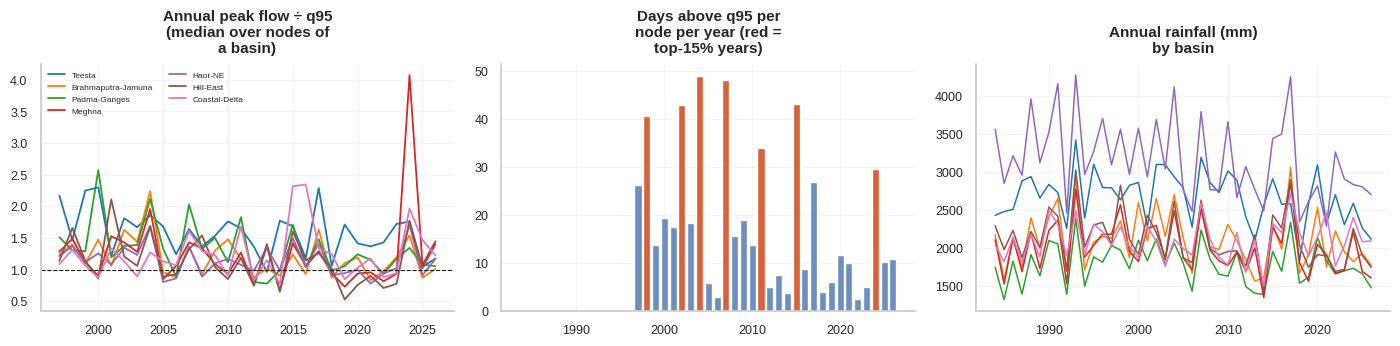

Top-8 high-flow years (days above q95 per node): {2004: 49.1, 2007: 48.2, 2015: 43.1, 2002: 42.9, 1998: 40.6, 2011: 34.1, 2024: 29.5, 2017: 26.9}


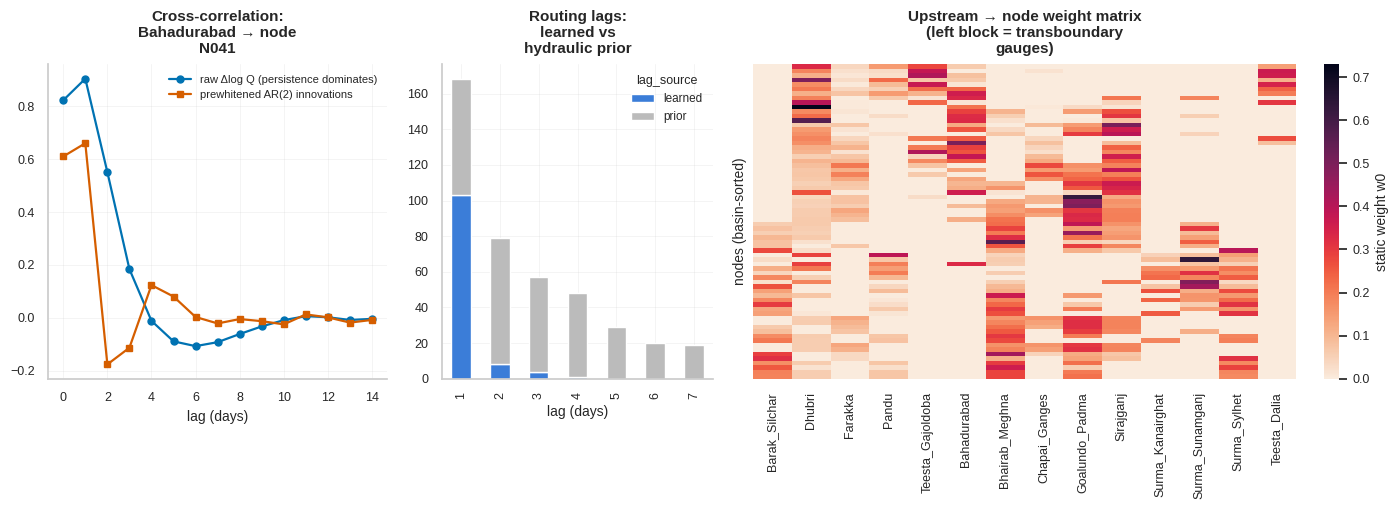

Share of routing weight on transboundary gauges: median 0.24 (riparian nodes 0.24, inland 0.24)


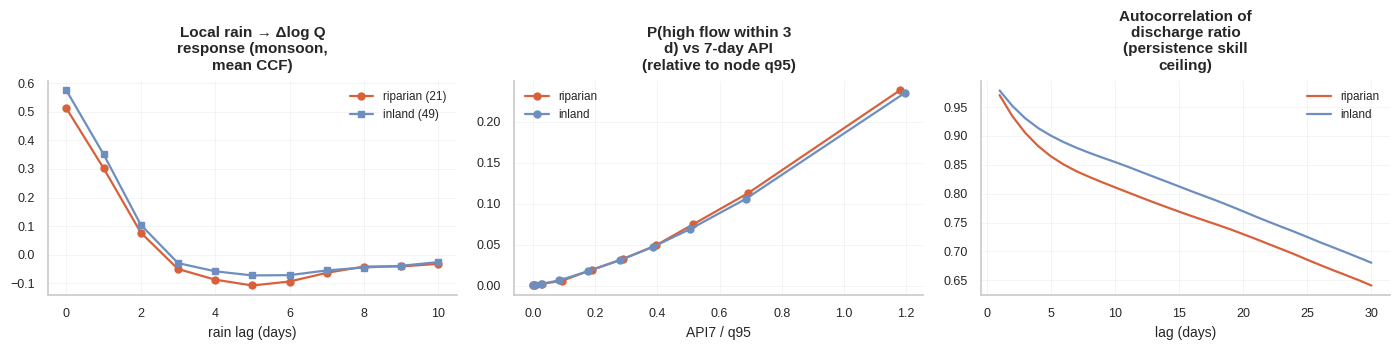

In [18]:
# @title EDA 2 · Hydrology — flood years, upstream→downstream routing & weight matrix, rain→flow response (descriptive; thresholds here use the full sample, models re-fit them per fold)
ratio_full = QN[NODE_IDS] / QN[NODE_IDS].quantile(FLOOD_Q); ex_full = (ratio_full >= 1).astype(float); yr = QN.index.year
# ---- Fig 1: flood years -----------------------------------------------------------------------------------------------------------------------------------------------
fig, ax = plt.subplots(1, 3, figsize=(21, 5.2))
for b in BASINS:
    cols = [n for n in NODE_IDS if NODES.at[n, "basin"] == b]; ax[0].plot(ratio_full[cols].groupby(yr).max().median(axis=1), color=BP[b], label=b, lw=1.3)
ax[0].axhline(1, color="k", ls="--", lw=.8); ax[0].set_title("Annual peak flow ÷ q95 (median over nodes of a basin)"); ax[0].legend(fontsize=6, ncol=2)
cnt = ex_full.groupby(yr).sum().sum(axis=1) / len(NODE_IDS); ax[1].bar(cnt.index, cnt.values, color=np.where(cnt.values > cnt.quantile(.85), "#d8613b", "#6d8fbf")); ax[1].set_title("Days above q95 per node per year (red = top-15% years)")
rain_y = {b: PR[[n for n in NODE_IDS if NODES.at[n, "basin"] == b]].mean(axis=1).groupby(yr).sum() for b in BASINS}
for b in BASINS: ax[2].plot(rain_y[b], color=BP[b], lw=1.1)
ax[2].set_title("Annual rainfall (mm) by basin"); plt.savefig(f"{EDA}/E2_flood_years.png"); plt.show(); plt.close("all")
print("Top-8 high-flow years (days above q95 per node):", cnt.sort_values(ascending=False).head(8).round(1).to_dict())

# ---- Fig 2: routing — raw vs prewhitened CCF, learned-lag histogram, and the UPSTREAM → DOWNSTREAM WEIGHT MATRIX -------------------------------------------------------
pair = RT[RT.tb == False].sort_values("corr", ascending=False).iloc[0]; nn_, gg_ = pair.node, pair.g
Ln = np.log1p(QN[nn_].astype("float64")).diff(1); Lg = np.log1p(QG[gg_].astype("float64")).diff(1); En, Eg = _ar2_innovations(Ln), _ar2_innovations(Lg); mon = Ln.index.month.isin(range(5, 11)); lags = list(range(0, 15))
raw = [Ln[mon].corr(Lg.shift(l)[mon]) for l in lags]; pw = [En[mon].corr(Eg.shift(l)[mon]) for l in lags]
Wm = pd.DataFrame(0.0, index=NODES.loc[NODE_IDS].sort_values(["basin_code", "lat"], ascending=[True, False]).index, columns=list(STATIONS))
for n, rr in _FIT_PREVIEW["route"].items():
    for r in rr: Wm.at[n, r["g"]] = r["w0"]
Wm = Wm[sorted(STATIONS, key=lambda g: (g not in TRANSBOUNDARY, g))]
fig, ax = plt.subplots(1, 3, figsize=(22, 8), gridspec_kw={"width_ratios": [1, .8, 1.6]})
ax[0].plot(lags, raw, marker="o", label="raw Δlog Q (persistence dominates)"); ax[0].plot(lags, pw, marker="s", label="prewhitened AR(2) innovations"); ax[0].set_title(f"Cross-correlation: {gg_} → node {nn_}"); ax[0].set_xlabel("lag (days)"); ax[0].legend(fontsize=8)
RT.groupby(["lag", "lag_source"]).size().unstack(fill_value=0).plot.bar(stacked=True, ax=ax[1], color=["#3b7dd8", "#bbb"]); ax[1].set_title("Routing lags: learned vs hydraulic prior"); ax[1].set_xlabel("lag (days)")
sns.heatmap(Wm, cmap="rocket_r", ax=ax[2], yticklabels=False, cbar_kws={"label": "static weight w0"}); ax[2].set_title("Upstream → node weight matrix (left block = transboundary gauges)"); ax[2].set_ylabel("nodes (basin-sorted)"); ax[2].tick_params(axis="x", rotation=60)
plt.savefig(f"{EDA}/E2_routing_weights.png"); plt.show(); plt.close("all")
tbw = np.array([sum(r["w0"] for r in rr if r["tb"]) for rr in _FIT_PREVIEW["route"].values()]); print(f"Share of routing weight on transboundary gauges: median {np.median(tbw):.2f} (riparian nodes {np.median(tbw[(NODES.loc[NODE_IDS,'ripar']==1).values]):.2f}, inland {np.median(tbw[(NODES.loc[NODE_IDS,'ripar']==0).values]):.2f})")

# ---- Fig 3: rain → flow response by zone, API saturation curve ----------------------------------------------------------------------------------------------------------
def ccf_rain_flow(nodes, maxlag=10):
    out = []
    for n in nodes:
        dq = np.log1p(QN[n].astype("float64")).diff(1); p = PR[n].astype("float64"); m = dq.index.month.isin(range(6, 10)); out.append([dq[m].corr(p.shift(l)[m]) for l in range(maxlag + 1)])
    return np.nanmean(out, axis=0)
zr, zi = [n for n in NODE_IDS if NODES.at[n, "ripar"] == 1], [n for n in NODE_IDS if NODES.at[n, "ripar"] == 0]
fig, ax = plt.subplots(1, 3, figsize=(20, 5))
ax[0].plot(ccf_rain_flow(zr), marker="o", color="#d8613b", label=f"riparian ({len(zr)})"); ax[0].plot(ccf_rain_flow(zi), marker="s", color="#6d8fbf", label=f"inland ({len(zi)})"); ax[0].set_title("Local rain → Δlog Q response (monsoon, mean CCF)"); ax[0].set_xlabel("rain lag (days)"); ax[0].legend()
a7 = pd.concat([_api(PR[n].astype("float64"), API_WIN_K, 7).rename(n) for n in NODE_IDS], axis=1); a7r = a7 / a7.quantile(.95); fut = ex_full[NODE_IDS].rolling(HORIZON).max().shift(-HORIZON)
for z, nodes, c in (("riparian", zr, "#d8613b"), ("inland", zi, "#6d8fbf")):
    x = a7r[nodes].values.ravel(); yv = fut[nodes].values.ravel(); ok = np.isfinite(x) & np.isfinite(yv); b = pd.qcut(x[ok], 12, duplicates="drop"); g = pd.DataFrame({"b": b, "y": yv[ok], "x": x[ok]}).groupby("b", observed=True).agg(x=("x", "mean"), y=("y", "mean"))
    ax[1].plot(g.x, g.y, marker="o", color=c, label=z)
ax[1].set_title("P(high flow within 3 d) vs 7-day API (relative to node q95)"); ax[1].set_xlabel("API7 / q95"); ax[1].legend()
acf = [pd.concat([ratio_full[n] for n in nodes[:15]], axis=1).apply(lambda s: s.autocorr(1)).mean() for nodes in (zr, zi)]; lagsA = range(1, 31)
for nodes, c, z in ((zr, "#d8613b", "riparian"), (zi, "#6d8fbf", "inland")): ax[2].plot(lagsA, [np.nanmean([ratio_full[n].autocorr(l) for n in nodes[:15]]) for l in lagsA], color=c, label=z)
ax[2].set_title("Autocorrelation of discharge ratio (persistence skill ceiling)"); ax[2].set_xlabel("lag (days)"); ax[2].legend()
plt.savefig(f"{EDA}/E2_rain_flow_response.png"); plt.show(); plt.close("all")


## EDA 3 · Spatial EDA

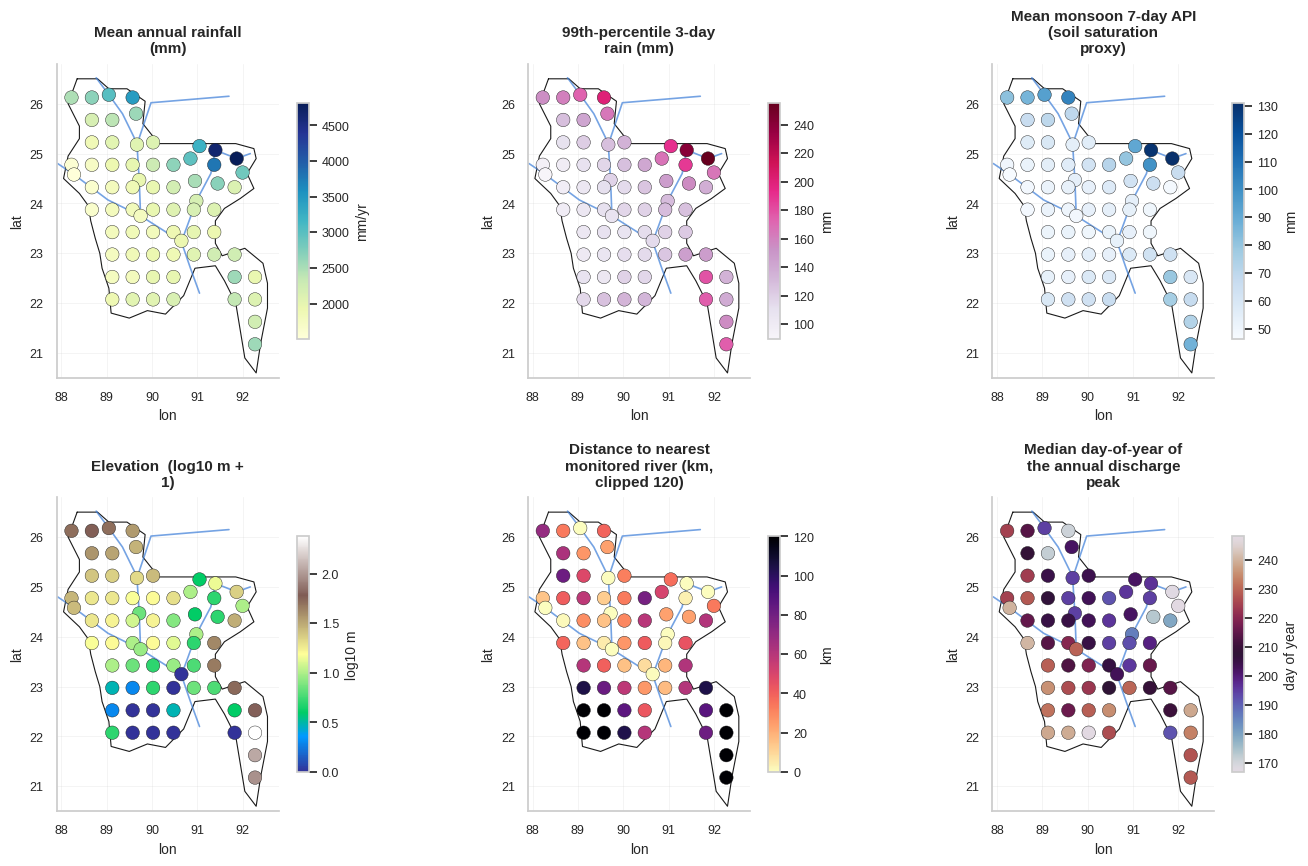

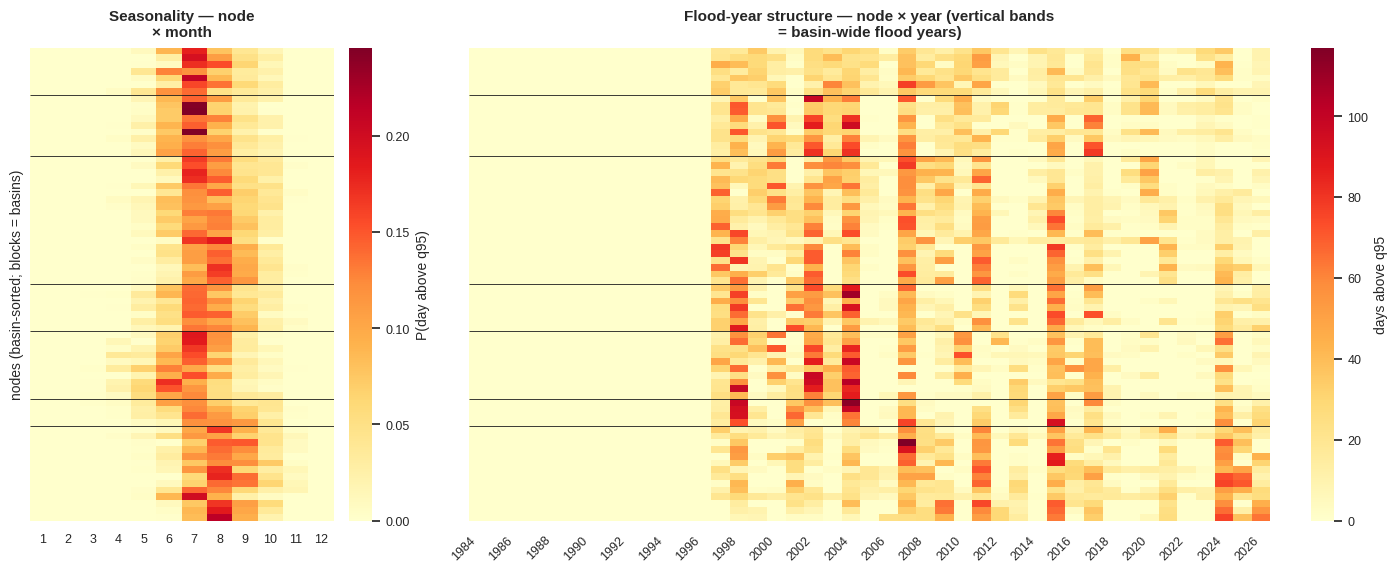

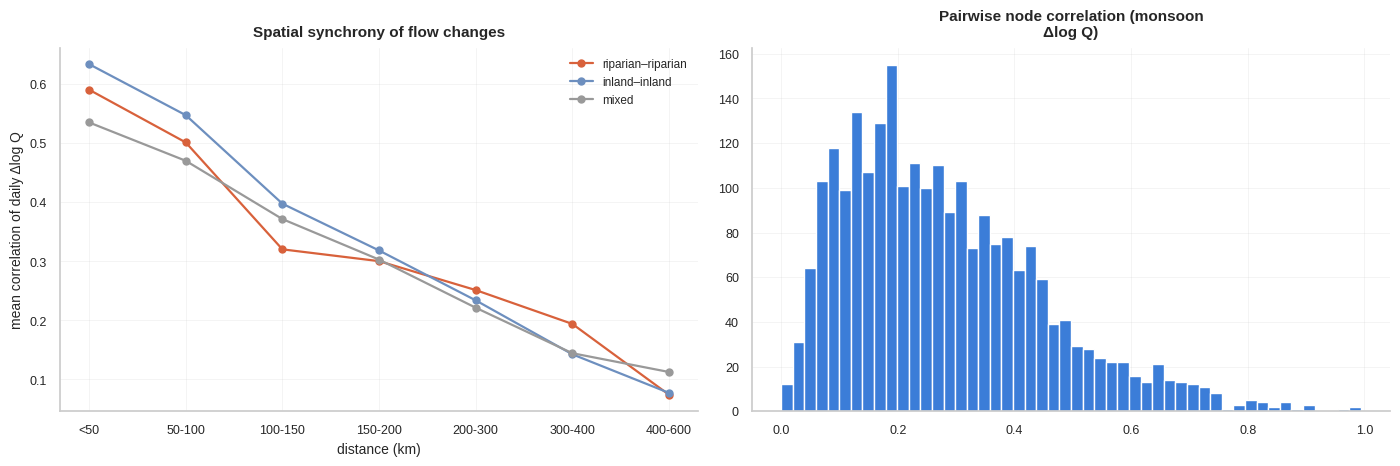

In [21]:
# @title EDA 3 · Spatial EDA — national maps, node × month / node × year heat-maps, spatial synchrony (why spatial-lag features help)
A7 = pd.concat([_api(PR[n].astype("float64"), API_WIN_K, 7).rename(n) for n in NODE_IDS], axis=1)
r3 = PR[NODE_IDS].rolling(3).sum(); peak_doy = ratio_full.groupby(QN.index.year).idxmax().apply(lambda col: col.dt.dayofyear).median()
fig, ax = plt.subplots(2, 3, figsize=(21, 13))
map_values(ax[0, 0], PR[NODE_IDS].mean() * 365.25, "Mean annual rainfall (mm)", "YlGnBu", "mm/yr")
map_values(ax[0, 1], r3.quantile(.99), "99th-percentile 3-day rain (mm)", "PuRd", "mm")
map_values(ax[0, 2], (A7.loc[A7.index.month.isin([6, 7, 8, 9])].mean()), "Mean monsoon 7-day API (soil saturation proxy)", "Blues", "mm")
map_values(ax[1, 0], np.log10(NODES.loc[NODE_IDS, "elev_m"] + 1), "Elevation  (log10 m + 1)", "terrain", "log10 m")
map_values(ax[1, 1], NODES.loc[NODE_IDS, "d_river_km"].clip(upper=120), "Distance to nearest monitored river (km, clipped 120)", "magma_r", "km")
map_values(ax[1, 2], peak_doy, "Median day-of-year of the annual discharge peak", "twilight", "day of year")
plt.savefig(f"{EDA}/E3_national_maps.png"); plt.show(); plt.close("all")

order = NODES.loc[NODE_IDS].sort_values(["basin_code", "lat"], ascending=[True, False]).index
hm_m = ex_full[order].groupby(QN.index.month).mean().T; hm_y = ex_full[order].groupby(QN.index.year).sum().T
fig, ax = plt.subplots(1, 2, figsize=(22, 9), gridspec_kw={"width_ratios": [.55, 1.45]})
sns.heatmap(hm_m, cmap="YlOrRd", ax=ax[0], yticklabels=False, cbar_kws={"label": "P(day above q95)"}); ax[0].set_title("Seasonality — node × month"); ax[0].set_ylabel("nodes (basin-sorted; blocks = basins)")
sns.heatmap(hm_y, cmap="YlOrRd", ax=ax[1], yticklabels=False, cbar_kws={"label": "days above q95"}); ax[1].set_title("Flood-year structure — node × year (vertical bands = basin-wide flood years)")
bounds = np.cumsum([int((NODES.loc[order, "basin"] == b).sum()) for b in BASINS]); [a.hlines(bounds[:-1], *a.get_xlim(), color="k", lw=.6) for a in ax]
plt.savefig(f"{EDA}/E3_node_heatmaps.png"); plt.show(); plt.close("all")

# spatial synchrony: correlation of daily discharge innovations between node pairs as a function of their distance
dl = np.log1p(QN[NODE_IDS].astype("float64")).diff(1).loc[lambda d: d.index.month.isin(range(6, 10))]; C = dl.corr().values; ii, jj = np.triu_indices(len(NODE_IDS), 1)
dist = km_between(NODES.loc[NODE_IDS, "lat"].values[ii], NODES.loc[NODE_IDS, "lon"].values[ii], NODES.loc[NODE_IDS, "lat"].values[jj], NODES.loc[NODE_IDS, "lon"].values[jj]); zi_ = NODES.loc[NODE_IDS, "ripar"].values
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
for lab, m, c in (("riparian–riparian", (zi_[ii] == 1) & (zi_[jj] == 1), "#d8613b"), ("inland–inland", (zi_[ii] == 0) & (zi_[jj] == 0), "#6d8fbf"), ("mixed", zi_[ii] != zi_[jj], "#999")):
    g = pd.DataFrame({"d": dist[m], "c": C[ii, jj][m]}).dropna(); g["b"] = pd.cut(g.d, [0, 50, 100, 150, 200, 300, 400, 600]); gg = g.groupby("b", observed=True).c.mean(); ax[0].plot(range(len(gg)), gg.values, marker="o", label=lab, color=c)
ax[0].set_xticks(range(7)); ax[0].set_xticklabels(["<50", "50-100", "100-150", "150-200", "200-300", "300-400", "400-600"]); ax[0].set_xlabel("distance (km)"); ax[0].set_ylabel("mean correlation of daily Δlog Q"); ax[0].set_title("Spatial synchrony of flow changes"); ax[0].legend()
ax[1].hist(C[ii, jj], bins=50, color="#3b7dd8"); ax[1].set_title("Pairwise node correlation (monsoon Δlog Q)")
plt.savefig(f"{EDA}/E3_spatial_synchrony.png"); plt.show(); plt.close("all")


## 9 · Tabular branch (Branch 2) — walk-forward training

In [22]:
# @title 9 · TABULAR BRANCH (Branch 2) — leakage-safe walk-forward with EMBARGO · persistence · LR · RF · LightGBM · XGBoost · local (no-upstream) XGBoost · distance gate
# Fold for test year Y: thresholds, routing lags & weights are fitted on years < Y only; training rows exclude the last HORIZON days before Y; training rows are strided, test rows are complete.
def fold_spec(Y):
    if Y == "final": return pd.Timestamp(FINAL_TEST_FROM - 1, 12, 31), (lambda yr: yr >= FINAL_TEST_FROM)
    return pd.Timestamp(Y - 1, 12, 31), (lambda yr, Y=Y: yr == Y)
_FE_PREFIX = ("hd_", "up_", "tb_", "rn_", "sp_", "st_", "ss_", "cx_", "ex_")
def fold_panel(Y):
    """Fold panel + fitted dictionary. Cached on Drive (zstd-parquet + json) → a re-run / resumed runtime skips ALL feature engineering."""
    train_last, test_pred = fold_spec(Y); tag = f"{Y}_s{TRAIN_STRIDE}_n{len(NODE_IDS)}_{FEAT_VER}_{TODAY.date()}"; ckp, ckf = f"{DIRS['processed_data']}/panel_{tag}.parquet", f"{DIRS['processed_data']}/fit_{tag}.json"
    if os.path.exists(ckp) and os.path.exists(ckf):
        P = pd.read_parquet(ckp); print(f"  ♻️ fold {Y}: panel loaded from cache ({len(P):,} rows)"); return P, [c for c in P.columns if c.startswith(_FE_PREFIX)], json.load(open(ckf))
    fit = fit_all(train_last)
    def keep(idx):
        pos = np.arange(len(idx)); return ((idx <= train_last - pd.Timedelta(days=EMBARGO)) & (pos % TRAIN_STRIDE == 0)) | test_pred(idx.year.values)
    P, FE_ = build_panel(fit, keep); P["is_test"] = test_pred(P.date.dt.year.values); P = P[(P.is_test) | (P.date <= train_last - pd.Timedelta(days=EMBARGO))].reset_index(drop=True)
    P.to_parquet(ckp, compression="zstd", index=False); json.dump(fit, open(ckf, "w"), default=float)
    return P, FE_, fit

def val_score(y, p, on):
    """Onset-first selection objective: SCORE_W_ONSET × onset PR-AUC + (1 − SCORE_W_ONSET) × overall PR-AUC."""
    if not on.any(): return aps(y, p)
    a, b = aps(y, p), aps(y[on], p[on]); return float(a if not np.isfinite(b) else (b if not np.isfinite(a) else SCORE_W_ONSET * b + (1 - SCORE_W_ONSET) * a))
def cw(y): return np.where(y == 1, (y == 0).sum() / max(y.sum(), 1), 1.0)
def xgb_make(params, n_est, spw, es=None):
    return xgb.XGBClassifier(n_estimators=n_est, tree_method="hist", device=XGB_DEVICE, max_bin=256, scale_pos_weight=spw, random_state=SEED, n_jobs=-1, eval_metric="aucpr", early_stopping_rounds=es, **params)
def subsample(idx, cap, seed=SEED): return idx if len(idx) <= cap else np.sort(np.random.default_rng(seed).choice(idx, cap, replace=False))

# ---- hyper-parameters: tuned ONCE on the first dev fold (train < Y0, validate Y0), then FIXED for every fold (that fold's score is therefore slightly optimistic) ----
Y0 = DEV_FOLDS[0]; P0, FEATS, FIT0 = fold_panel(Y0); X0 = P0[FEATS].to_numpy(np.float32); y0 = P0.y.to_numpy(int); tr0 = np.where(~P0.is_test)[0]; va0 = np.where(P0.is_test)[0]; on0 = P0.quiet4.to_numpy(bool)[va0]; q40 = P0.quiet4.to_numpy(int)
LOCAL = [c for c in FEATS if not c.startswith(("up_", "tb_", "sp_ratio", "ex_up_")) and c not in ("cx_river_drive", "cx_tb_drive")]
NOEX_COLS = [c for c in FEATS if not c.startswith(("ex_", "hd_x_"))]; LOCX_COLS = [c for c in FEATS if not c.startswith("ex_")]; HAS_EX = len(NOEX_COLS) < len(FEATS); HAS_LOCX = len(NOEX_COLS) < len(LOCX_COLS) < len(FEATS)
NOEX_NAME = "XGBoost (baseline features)"; LOCX_NAME = "XGBoost (baseline + hydrograph-shape features)"
print(f"features: {len(FEATS)} = {len(NOEX_COLS)} baseline + {len(LOCX_COLS) - len(NOEX_COLS)} hydrograph-shape + {len(FEATS) - len(LOCX_COLS)} extra-source | LSTM candidate: {LSTM_OK}")
def sw_of(y, quiet4, ow):
    """Sample weights: onset positives (quiet 4 d → flood) are the rare, hard rows persistence cannot solve → up-weight them by `ow`."""
    w = np.ones(len(y), np.float32); w[(np.asarray(y) == 1) & (np.asarray(quiet4) == 1)] = ow; return w
def _obj(tr):
    p = dict(max_depth=tr.suggest_int("max_depth", 3, 8), learning_rate=tr.suggest_float("learning_rate", .02, .2, log=True), subsample=tr.suggest_float("subsample", .6, 1),
             colsample_bytree=tr.suggest_float("colsample_bytree", .5, 1), min_child_weight=tr.suggest_int("min_child_weight", 1, 20), reg_lambda=tr.suggest_float("reg_lambda", 1e-2, 10, log=True), gamma=tr.suggest_float("gamma", 0, 2))
    sm = tr.suggest_float("spw_mult", .15, 1.5, log=True); ow = tr.suggest_float("onset_w", 1.0, 4.0)            # v5: cost-sensitive learning knobs are TUNED, not fixed
    spw = sm * (y0[tr0] == 0).sum() / max(y0[tr0].sum(), 1)
    m = xgb_make(p, 150, spw, es=15).fit(X0[tr0], y0[tr0], sample_weight=sw_of(y0[tr0], q40[tr0], ow), eval_set=[(X0[va0], y0[va0])], verbose=False)
    return val_score(y0[va0], m.predict_proba(X0[va0])[:, 1], on0)
print(f"🔧 Optuna tuning XGBoost on fold {Y0} ({XGB_TRIALS} trials, {len(tr0):,} train rows × {len(FEATS)} features) …")
_st = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED)); _st.optimize(_obj, n_trials=XGB_TRIALS); XGB_P = dict(_st.best_params); IMB = dict(spw_mult=XGB_P.pop("spw_mult"), onset_w=XGB_P.pop("onset_w"))
_m = xgb_make(XGB_P, N_TREES * 2, IMB["spw_mult"] * (y0[tr0] == 0).sum() / max(y0[tr0].sum(), 1), es=25).fit(X0[tr0], y0[tr0], sample_weight=sw_of(y0[tr0], q40[tr0], IMB["onset_w"]), eval_set=[(X0[va0], y0[va0])], verbose=False); N_ITER = int(np.clip(_m.best_iteration + 1, 60, N_TREES * 2))
print("best params:", {k: round(v, 4) if isinstance(v, float) else v for k, v in XGB_P.items()}, "| trees:", N_ITER, "| imbalance:", {k: round(v, 3) for k, v in IMB.items()}); del X0, P0, _m; gc.collect()

def sig(z): return 1 / (1 + np.exp(-z))
def ens_of(*ps): return sig(np.mean([logit(p) for p in ps], axis=0))                                    # logit-average: models trained with different weighting live on different probability scales
def bag_fit(X, y, tr, n_est, K=BAG_K, ratio=BAG_NEG_RATIO, seed=SEED):
    """Balanced bagging with HARD-NEGATIVE mining: every member sees ALL positives + `ratio`× as many negatives, half of them 'near-miss' negatives
    (7-day max discharge already ≥ 0.5 × q95) so the trees learn the boundary instead of the trivially quiet days."""
    HI = FEATS.index("hd_ratio_max7"); pos = tr[y[tr] == 1]; neg = tr[y[tr] == 0]; hard = neg[np.nan_to_num(X[neg, HI]) >= 0.5]; rng = np.random.default_rng(seed); nn_ = min(len(neg), ratio * max(len(pos), 1)); ms = []
    for k in range(K):
        nh = min(len(hard), nn_ // 2); pick = np.concatenate([rng.choice(hard, nh, replace=False) if nh else np.array([], int), rng.choice(neg, nn_ - nh, replace=False)]); idx = np.concatenate([pos, pick])
        ms.append(xgb_make(XGB_P, max(60, n_est // 2), 1.0).fit(X[idx], y[idx]))
    return ms
def bag_predict(ms, X): return np.mean([m.predict_proba(X)[:, 1] for m in ms], axis=0)

class _Const:
    """Fallback when a regime has too few positives to fit (keeps pickling / prediction code uniform)."""
    def __init__(self, p): self.p = float(p)
    def predict_proba(self, X): return np.column_stack([np.full(len(X), 1 - self.p), np.full(len(X), self.p)])
def split_fit(X, y, q4, tr):
    """Regime-split XGBoost: specialist 1 = ONSET regime (quiet 4 days → the rare, hard question 'will it start?'), specialist 0 = CONTINUATION regime (already flooding → 'will it persist?')."""
    ms = []
    for reg in (1, 0):
        r = tr[q4[tr] == reg]
        if len(r) < 500 or y[r].sum() < 20 or (1 - y[r]).sum() < 20: ms.append(_Const(y[r].mean() if len(r) else .5)); continue
        ms.append(xgb_make(XGB_P, N_ITER, 1.0).fit(X[r], y[r]))                      # natural class balance inside each regime → the two specialists' probabilities share one scale (pooled ranking stays consistent)
    return tuple(ms)
def split_predict(ms, X, q4): return np.where(np.asarray(q4) == 1, ms[0].predict_proba(X)[:, 1], ms[1].predict_proba(X)[:, 1])
def lgb_make(): return lgb.LGBMClassifier(n_estimators=N_TREES, learning_rate=.06, num_leaves=31, subsample=.8, subsample_freq=1, colsample_bytree=.8, min_child_samples=40, class_weight="balanced", verbose=-1, random_state=SEED, n_jobs=-1)

CTX_NAMES = [c for c in ("hd_ratio", "hd_ratio_max7", "hd_ratio_vs_min7", "hd_gap", "ss_sin", "ss_cos", "st_ripar_score", "up_pressure", "tb_pressure") if c in FEATS]      # context for the meta-learners (all available live too)
def fold_fit_predict(Y, P=None, fit_=None):
    if P is None: P, _fe, fit_ = fold_panel(Y)
    tr = np.where(~P.is_test)[0]; te = np.where(P.is_test)[0]; X = P[FEATS].to_numpy(np.float32); y = P.y.to_numpy(int); now = P.flood_now.to_numpy(int); q4 = P.quiet4.to_numpy(int); out = {}
    out["Persistence (binary: stays as today)"] = now[te].astype(float); out["Persistence-soft (rank by Q/q95 today)"] = np.nan_to_num(P.hd_ratio.to_numpy(float))[te]
    sub = subsample(tr, SUB_CAP)
    out["Logistic Regression"] = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LogisticRegression(C=.3, class_weight="balanced", max_iter=2000)).fit(X[sub], y[sub]).predict_proba(X[te])[:, 1]
    out["Random Forest"] = make_pipeline(SimpleImputer(strategy="median"), RandomForestClassifier(100, max_depth=12, min_samples_leaf=25, class_weight="balanced_subsample", n_jobs=-1, random_state=SEED)).fit(X[sub], y[sub]).predict_proba(X[te])[:, 1]
    sw = sw_of(y[tr], q4[tr], IMB["onset_w"])
    mlg = lgb.LGBMClassifier(n_estimators=N_TREES, learning_rate=.06, num_leaves=31, subsample=.8, subsample_freq=1, colsample_bytree=.8, min_child_samples=40, class_weight="balanced", verbose=-1, random_state=SEED, n_jobs=-1).fit(X[tr], y[tr], sample_weight=sw)
    out["LightGBM"] = mlg.predict_proba(X[te])[:, 1]
    spw = IMB["spw_mult"] * (y[tr] == 0).sum() / max(y[tr].sum(), 1); li = [FEATS.index(c) for c in LOCAL]
    mx = xgb_make(XGB_P, N_ITER, spw).fit(X[tr], y[tr], sample_weight=sw); ml = xgb_make(XGB_P, N_ITER, spw).fit(X[tr][:, li], y[tr], sample_weight=sw)
    out["XGBoost (all features)"] = mx.predict_proba(X[te])[:, 1]; out["XGBoost-local (no upstream/transboundary)"] = ml.predict_proba(X[te][:, li])[:, 1]
    bags = bag_fit(X, y, tr, N_ITER); out[BAG_NAME] = bag_predict(bags, X[te]); spl = split_fit(X, y, q4, tr); out[SPLIT_NAME] = split_predict(spl, X[te], q4[te]); out[ENS_NAME] = ens_of(out["XGBoost (all features)"], out["LightGBM"], out[BAG_NAME])
    nx = [FEATS.index(c) for c in NOEX_COLS]; mnx = None; lpack = None; hpack = None; tpack = None
    if HAS_EX: mnx = xgb_make(XGB_P, N_ITER, spw).fit(X[tr][:, nx], y[tr], sample_weight=sw); out[NOEX_NAME] = mnx.predict_proba(X[te][:, nx])[:, 1]
    mlx = None
    if HAS_LOCX: lx = [FEATS.index(c) for c in LOCX_COLS]; mlx = xgb_make(XGB_P, N_ITER, spw).fit(X[tr][:, lx], y[tr], sample_weight=sw); out[LOCX_NAME] = mlx.predict_proba(X[te][:, lx])[:, 1]
    if LSTM_OK:
        pl_, lpack = lstm_fold(P, fit_, tr, te, y, q4); out[LSTM_NAME] = pl_ if pl_ is not None else out["XGBoost (all features)"].copy()
    if HG_OK:
        ph_, hpack = hg_fold(P, fit_, tr, te, y, q4); out[HG_NAME] = ph_ if ph_ is not None else out["XGBoost (all features)"].copy()
    if TABM_OK:
        pt_, tpack = tabm_fit_predict(X, y, q4, pd.DatetimeIndex(P.date).year.values, tr, te); out[TABM_NAME] = pt_ if pt_ is not None else out["XGBoost (all features)"].copy()
    meta = pd.DataFrame(dict(fold=str(Y), date=P.date.values[te], node=P.node.values[te], zone=P.zone.values[te], basin=P.basin.values[te], d_river=P.st_dist_river.values[te], y=y[te], now=now[te], on=P.quiet4.values[te].astype(bool), **{"ctx_" + c: P[c].values[te].astype(float) for c in CTX_NAMES}))
    return out, meta, (mx, ml, X[te], P.index.values[te], dict(lgb=mlg, bag=bags, split=spl, noex=mnx, locx=mlx, lstm=lpack, hg=hpack, tabm=tpack))

import joblib, hashlib
CK = f"{BASE}/checkpoints"; os.makedirs(CK, exist_ok=True)
CK_SIG = hashlib.md5(repr((FEAT_VER, list(FEATS), N_TREES, LSTM_EPOCHS, LSTM_SEEDS, HG_EPOCHS, HG_SEEDS, TABM_OK, TRAIN_STRIDE, list(DEV_FOLDS), str(FINAL_TEST_FROM), BAG_K, DRY_RUN)).encode()).hexdigest()[:10]
def _ck_load(p):
    try: return joblib.load(p) if os.path.exists(p) else None
    except Exception as err: print(f"   (checkpoint unreadable, recomputing: {type(err).__name__})"); return None
_tn = _ck_load(f"{CK}/tuning_{CK_SIG}.pkl")
if _tn is not None: XGB_P, N_ITER = _tn["XGB_P"], _tn["N_ITER"]; IMB.update(_tn["IMB"]); print(f"  ♻️ tuned parameters restored from checkpoint (so restored folds and new folds use the SAME model): {XGB_P} | trees {N_ITER} | {IMB}")
else: joblib.dump(dict(XGB_P=XGB_P, N_ITER=N_ITER, IMB=dict(IMB)), f"{CK}/tuning_{CK_SIG}.pkl")
t0 = time.time(); DEVM, DEVP = [], {}
for Y in DEV_FOLDS:
    r_ = _ck_load(f"{CK}/dev_{Y}_{CK_SIG}.pkl")
    if r_ is not None: o, m = r_; print(f"  ♻️ fold {Y}: restored from checkpoint")
    else: o, m, _ = fold_fit_predict(Y); joblib.dump((o, m), f"{CK}/dev_{Y}_{CK_SIG}.pkl")
    DEVM.append(m)
    for k, v in o.items(): DEVP.setdefault(k, []).append(v)
    print(f"  fold {Y}: {len(m):,} test node-days | flood rate {m.y.mean():.3f} | {time.time()-t0:.0f}s"); gc.collect()
DEVM = pd.concat(DEVM, ignore_index=True); DEVP = {k: np.concatenate(v) for k, v in DEVP.items()}
PF, FE_F, FIT_FINAL = fold_panel("final"); _fsig = f"{len(PF)}_{int(PF.is_test.sum())}_{PF.date.max():%Y%m%d}"; _fck = f"{CK}/final_{CK_SIG}_{_fsig}.pkl"      # data fingerprint → a checkpoint made on older data is never reused
r_ = _ck_load(_fck)
if r_ is not None and len(r_[1]) != int(PF.is_test.sum()): print(f"   (final checkpoint holds {len(r_[1]):,} test rows but the data now has {int(PF.is_test.sum()):,} → refitting)"); r_ = None
if r_ is not None: o, TESTM, XGB_MAIN, XGB_LOCAL, XTE, _ti, EXTRA = r_; print("  ♻️ final model: restored from checkpoint")
else:
    o, TESTM, (XGB_MAIN, XGB_LOCAL, XTE, _ti, EXTRA) = fold_fit_predict("final", PF, FIT_FINAL)
    try: joblib.dump((o, TESTM, XGB_MAIN, XGB_LOCAL, XTE, _ti, EXTRA), _fck)
    except Exception as err: print(f"   (final checkpoint not saved: {type(err).__name__})")
TESTP = o
print(f"  final model: {int((~PF.is_test).sum()):,} train rows, {len(TESTM):,} untouched test node-days (≥ {FINAL_TEST_FROM}) | {time.time()-t0:.0f}s"); assert FE_F == FEATS

# ---- derived predictors: average ensemble + distance-gated blend (river-aware vs local) — D0, S chosen on POOLED out-of-time data ------------------------------------------
yD, onD, nowD = DEVM.y.values, DEVM.on.values, DEVM.now.values
def gate(p_all, p_loc, d, D0, S): w = 1 / (1 + np.exp(-(D0 - d) / S)) if D0 < 1e4 else np.ones_like(d); return w * p_all + (1 - w) * p_loc
GS = {(D0, S): val_score(yD, gate(DEVP["XGBoost (all features)"], DEVP["XGBoost-local (no upstream/transboundary)"], DEVM.d_river.values, D0, S), onD) for D0 in D0_GRID for S in S_GRID}
(GD0, GS_), _gbest = max(GS.items(), key=lambda kv: kv[1]); print(f"distance gate chosen on pooled walk-forward: D0 = {GD0} km, S = {GS_} km  (score {_gbest:.3f}; D0=0 → never use upstream, 100000 → always)")
def add_derived(P, M):
    P = dict(P); P["XGBoost (all features)"]; P["XGB+LGBM average"] = (P["XGBoost (all features)"] + P["LightGBM"]) / 2
    P["XGBoost distance-gated (river-aware ⇄ local)"] = gate(P["XGBoost (all features)"], P["XGBoost-local (no upstream/transboundary)"], M.d_river.values, GD0, GS_); return P
DEVS = add_derived(DEVP, DEVM); TESTS = add_derived(TESTP, TESTM)
# ---- parsimony rule: the simplest candidate (plain XGBoost) is served unless another beats it by ≥ SELECT_MARGIN on pooled out-of-time data --------------------------------
# ---- v6 · member probabilities + composition (the SAME code serves the evaluation fits and the live scorer) ---------------------------------------------------------------
META_SERVE = {}          # filled by the meta-learner arena (cell 9m): name → callable(member probabilities)
def member_probs(X, q4, M=None, rows=None, data=None):
    M = M or dict(main=XGB_MAIN, local=XGB_LOCAL, **EXTRA); li = [FEATS.index(c) for c in LOCAL]
    out = {"XGBoost (all features)": M["main"].predict_proba(X)[:, 1], "LightGBM": M["lgb"].predict_proba(X)[:, 1], "XGBoost-local (no upstream/transboundary)": M["local"].predict_proba(X[:, li])[:, 1],
           BAG_NAME: bag_predict(M["bag"], X), SPLIT_NAME: split_predict(M["split"], X, q4)}
    if HAS_EX and M.get("noex") is not None: out[NOEX_NAME] = M["noex"].predict_proba(X[:, [FEATS.index(c) for c in NOEX_COLS]])[:, 1]
    if HAS_LOCX and M.get("locx") is not None: out[LOCX_NAME] = M["locx"].predict_proba(X[:, [FEATS.index(c) for c in LOCX_COLS]])[:, 1]
    if LSTM_OK and M.get("lstm") is not None and rows is not None: out[LSTM_NAME] = lstm_predict(M["lstm"], rows, data)
    if HG_OK and M.get("hg") is not None and rows is not None: out[HG_NAME] = hg_predict(M["hg"], rows, data)
    if TABM_OK and M.get("tabm") is not None: out[TABM_NAME] = tabm_predict(M["tabm"], X)
    if "ctx_live" in globals(): out["__ctx__"] = ctx_live(X, q4)
    return out
def compose(name, MP, d=None):
    if name in META_SERVE: return META_SERVE[name](MP)
    if name == COMBO_NAME: return sig(sum(w * logit(MP[k]) for k, w in COMBO_W.items()))
    if name == ENS_NAME: return ens_of(MP["XGBoost (all features)"], MP["LightGBM"], MP[BAG_NAME])
    if name.startswith("XGBoost distance-gated"): return gate(MP["XGBoost (all features)"], MP["XGBoost-local (no upstream/transboundary)"], d, GD0, GS_)
    return MP[name]

# ---- v6 · COMBINATION SELECTION (Caruana greedy ensemble on logits). Weights come from WALK-FORWARD predictions only; honesty comes from a NESTED leave-one-fold-out estimate -------------
POOL = ["XGBoost (all features)", "LightGBM", "XGBoost-local (no upstream/transboundary)", BAG_NAME, SPLIT_NAME]
if HAS_EX: POOL.append(NOEX_NAME)
if HAS_LOCX: POOL.append(LOCX_NAME)
if LSTM_NAME in DEVS: POOL.append(LSTM_NAME)
if HG_NAME in DEVS: POOL.append(HG_NAME)
if TABM_NAME in DEVS: POOL.append(TABM_NAME)
def caruana(L, y, on, iters=COMBO_ITERS):
    """Greedy forward selection WITH replacement: repeatedly add the member that most improves the (overall + onset) PR-AUC of the logit-average. Weight = share of picks."""
    cnt = np.zeros(L.shape[1]); acc = np.zeros(len(y))
    for it in range(iters):
        sc = [val_score(y, sig((acc + L[:, j]) / (it + 1)), on) for j in range(L.shape[1])]; j = int(np.nanargmax(sc)); cnt[j] += 1; acc += L[:, j]
    return cnt / cnt.sum()
LD = np.column_stack([logit(DEVS[k]) for k in POOL]); FID = DEVM.fold.values; NEST = np.zeros(len(yD)); NEST_W = []
for f_ in np.unique(FID):
    a_, b_ = FID != f_, FID == f_; w_ = caruana(LD[a_], yD[a_], onD[a_]); NEST[b_] = sig(LD[b_] @ w_); NEST_W.append(w_)
COMBO_W = dict(zip(POOL, caruana(LD, yD, onD))); DEVS[COMBO_NAME] = NEST                                                              # dev predictions of the combination are the NESTED (honest) ones
TESTS[COMBO_NAME] = sig(np.column_stack([logit(TESTS[k]) for k in POOL]) @ np.array(list(COMBO_W.values())))
print("combination weights (all dev folds):", {k[:28]: round(float(v), 2) for k, v in COMBO_W.items()}, "| weight spread across folds (std):", np.round(np.std(NEST_W, axis=0), 2))
CANDS = ["XGBoost (all features)", "XGBoost distance-gated (river-aware ⇄ local)", ENS_NAME, SPLIT_NAME, COMBO_NAME] + ([NOEX_NAME] if HAS_EX else []) + ([LOCX_NAME] if HAS_LOCX else []) + ([LSTM_NAME] if LSTM_NAME in DEVS else [])      # servable variants (LightGBM / average stay in the comparison tables)
SC = {k: val_score(yD, DEVS[k], onD) for k in CANDS}; BEST_ = max(SC, key=SC.get); BASE_ = NOEX_NAME if HAS_EX else "XGBoost (all features)"
WINS = float(np.mean([aps(yD[FID == f_], DEVS[BEST_][FID == f_]) > aps(yD[FID == f_], DEVS[BASE_][FID == f_]) for f_ in np.unique(FID)])) if BEST_ != BASE_ else 0.0
TAB_NAME = BEST_ if (SC[BEST_] - SC[BASE_] >= SELECT_MARGIN and WINS >= 0.6) else BASE_
print("pooled walk-forward score (onset-weighted: 70 % onset PR-AUC + 30 % overall; the combination uses NESTED predictions):", {k: round(v, 3) for k, v in SC.items()},
      f"\n→ Branch-2 model carried forward: {TAB_NAME}  (needs ≥ +{SELECT_MARGIN} over plain XGBoost AND a win in ≥ 60 % of folds; best candidate {BEST_} gain {SC[BEST_]-SC[BASE_]:+.4f}, fold wins {WINS:.0%})")
CAL_TAB = Platt().fit(DEVS[TAB_NAME], yD)                 # calibration from POOLED walk-forward predictions (not from one flood-heavy year)
ram("after tabular branch")


  ♻️ fold 2020: panel loaded from cache (221,480 rows)
features: 121 = 81 baseline + 16 hydrograph-shape + 24 extra-source | LSTM candidate: True
🔧 Optuna tuning XGBoost on fold 2020 (8 trials, 195,860 train rows × 121 features) …
best params: {'max_depth': 7, 'learning_rate': 0.021, 'subsample': 0.988, 'colsample_bytree': 0.9162, 'min_child_weight': 5, 'reg_lambda': 0.0351, 'gamma': 0.3668} | trees: 256 | imbalance: {'spw_mult': 0.302, 'onset_w': 2.574}
  ♻️ tuned parameters restored from checkpoint (so restored folds and new folds use the SAME model): {'max_depth': 7, 'learning_rate': 0.02097077545038924, 'subsample': 0.9879639408647978, 'colsample_bytree': 0.9162213204002109, 'min_child_weight': 5, 'reg_lambda': 0.035113563139704075, 'gamma': 0.36680901970686763} | trees 256 | {'spw_mult': 0.30222716826237983, 'onset_w': 2.5742692948967134}
  ♻️ fold 2020: restored from checkpoint
  fold 2020: 25,620 test node-days | flood rate 0.038 | 0s
  ♻️ fold 2021: restored from checkpoint
  f

### 9m · Meta-learner arena (learned combination of the members)

In [23]:
# @title 9m · META-LEARNER ARENA — learn HOW to combine the members from the national out-of-fold logits (≈ every dev node-day, not ~400 SAR floods): logistic stack · context-gated mixture-of-experts · residual boosting on member logits  (all nested leave-one-fold-out, onset-weighted, gated)
# v7 trained its meta-learner on a few hundred SAR-covered floods; v8 only used fixed Caruana weights. Here the stackers learn from the SAME national out-of-fold member logits that the Caruana ensemble uses (≈ 10 k floods), with the regime (onset vs continuation), river-vs-inland context,
# season and current flow level as inputs — so they can learn e.g. "in the onset regime on riparian nodes trust the sequence net more". Each stacker is evaluated by LEAVE-ONE-FOLD-OUT (fitted on the other dev years), then must beat plain XGBoost by SELECT_MARGIN and win ≥ 60 % of folds.
MEM = [k for k in POOL]; LZ = lambda D_: np.clip(np.column_stack([logit(D_[k]) for k in MEM]), -12, 12)
LDv, LTv = LZ(DEVS), LZ(TESTS); BI = MEM.index(BASE_) if BASE_ in MEM else MEM.index("XGBoost (all features)"); WDEV = sw_of(yD, onD.astype(int), IMB["onset_w"]); FIDv = DEVM.fold.values
def _tf(c, v):
    v = np.nan_to_num(np.asarray(v, float), nan=0.0); return np.sign(v) * np.log1p(np.abs(v)) if c.startswith(("hd_ratio", "hd_gap", "up_pressure", "tb_pressure")) else v
def ctx_raw(getter, on): return np.column_stack([_tf(c, getter(c)) for c in CTX_NAMES] + [np.asarray(on, float)])
_Z0 = ctx_raw(lambda c: DEVM["ctx_" + c].values, onD); CTX_MU, CTX_SD = _Z0.mean(0), _Z0.std(0) + 1e-6; CTX_MU[-1], CTX_SD[-1] = 0.0, 1.0
def ctx_std(Z): return (Z - CTX_MU) / CTX_SD
ZD = ctx_std(_Z0); ZT = ctx_std(ctx_raw(lambda c: TESTM["ctx_" + c].values, TESTM.on.values))
def ctx_live(X, q4): return ctx_std(ctx_raw(lambda c: X[:, FEATS.index(c)], q4))

def fit_lr(L, Z, y, w):
    F = lambda L_, Z_: np.column_stack([L_, L_ * Z_[:, -1:], Z_]); m = LogisticRegression(C=0.05, max_iter=400).fit(F(L, Z), y, sample_weight=w)
    return lambda L_, Z_: m.decision_function(F(L_, Z_))
def fit_moe(L, Z, y, w, epochs=200, seed=0):
    """Context-gated mixture-of-experts: z = a_r · Σ_j softmax_j(Wc + b) · L_j + b_r  (regime r = onset / continuation). Gate starts as a one-hot prior on the base model and is L2-pulled back to it → cannot wander far from plain XGBoost without evidence."""
    torch.manual_seed(seed); m, k = L.shape[1], Z.shape[1]; prior = torch.zeros(m); prior[BI] = 2.5
    Lt, Zt, yt, wt = (torch.as_tensor(a, dtype=torch.float32) for a in (L, Z, y, w)); rg = (Zt[:, -1] > 0.5).long()
    Wg = torch.zeros(k, m, requires_grad=True); bg = prior.clone().requires_grad_(True); a = torch.ones(2, requires_grad=True); b0 = torch.zeros(2, requires_grad=True); opt = torch.optim.Adam([Wg, bg, a, b0], lr=0.03)
    def fwd(L_, Z_, r_): g = torch.softmax(Z_ @ Wg + bg, 1); return a[r_] * (g * L_).sum(1) + b0[r_]
    for ep in range(epochs):
        opt.zero_grad(); loss = (tnn.functional.binary_cross_entropy_with_logits(fwd(Lt, Zt, rg), yt, reduction="none") * wt).mean() + 2e-3 * (Wg ** 2).sum() + 2e-3 * ((bg - prior) ** 2).sum(); loss.backward(); opt.step()
    Wg, bg, a, b0 = Wg.detach(), bg.detach(), a.detach(), b0.detach()
    def pred(L_, Z_):
        with torch.no_grad(): Z2 = torch.as_tensor(Z_, dtype=torch.float32); return fwd_np(torch.as_tensor(L_, dtype=torch.float32), Z2).numpy()
    def fwd_np(L_, Z_): g = torch.softmax(Z_ @ Wg + bg, 1); r_ = (Z_[:, -1] > 0.5).long(); return a[r_] * (g * L_).sum(1) + b0[r_]
    pred.gate = (Wg.numpy(), bg.numpy()); return pred
def fit_xr(L, Z, y, w):
    F = lambda L_, Z_: np.column_stack([L_, Z_]); m = xgb.XGBClassifier(n_estimators=120, max_depth=2, learning_rate=.05, subsample=.8, colsample_bytree=.8, min_child_weight=50, reg_lambda=5, tree_method="hist", device="cpu", random_state=SEED, n_jobs=-1).fit(F(L, Z), y, sample_weight=w, base_margin=L[:, BI])
    return lambda L_, Z_: m.predict(F(L_, Z_), output_margin=True, base_margin=L_[:, BI])
ARENA = {"Meta-learner · logistic stack (members × regime × context)": fit_lr, "Meta-learner · context-gated mixture-of-experts": fit_moe, "Meta-learner · residual boosting on member logits": fit_xr}
META_NAMES, META_FIT, META_RES = [], {}, []
for nm, fn in ARENA.items():
    try:
        NESTm = np.zeros(len(yD))
        for f_ in np.unique(FIDv):
            a_, b_ = FIDv != f_, FIDv == f_; NESTm[b_] = fn(LDv[a_], ZD[a_], yD[a_], WDEV[a_])(LDv[b_], ZD[b_])
        full = fn(LDv, ZD, yD, WDEV); DEVS[nm] = sig(NESTm); TESTS[nm] = sig(full(LTv, ZT)); META_FIT[nm] = full; META_NAMES.append(nm)
        META_RES.append(dict(stacker=nm, dev_score=val_score(yD, DEVS[nm], onD), dev_gain_vs_base=val_score(yD, DEVS[nm], onD) - val_score(yD, DEVS[BASE_], onD), fold_wins=float(np.mean([aps(yD[FIDv == f_], DEVS[nm][FIDv == f_]) > aps(yD[FIDv == f_], DEVS[BASE_][FIDv == f_]) for f_ in np.unique(FIDv)]))))
    except Exception as err: print(f"⚠️ stacker '{nm}' failed ({type(err).__name__}: {str(err)[:100]}) → skipped")
META_RES = pd.DataFrame(META_RES).set_index("stacker"); print("🧠 META-LEARNER ARENA (nested leave-one-fold-out, onset-weighted dev score; base = " + BASE_ + ")"); show(META_RES, 4)
if "Meta-learner · context-gated mixture-of-experts" in META_FIT:
    Wg_, bg_ = META_FIT["Meta-learner · context-gated mixture-of-experts"].gate; mean_g = np.exp(ZD @ Wg_ + bg_); mean_g = (mean_g / mean_g.sum(1, keepdims=True))
    GATE_TAB = pd.DataFrame({"onset rows": mean_g[onD].mean(0), "continuation rows": mean_g[~onD].mean(0)}, index=[k[:44] for k in MEM]).round(3); print("\nwhat the gate learned — mean expert weight by regime (interpretability):"); show(GATE_TAB, 3)

def _serve_meta(nm):
    def f(MP): L_ = np.clip(np.column_stack([logit(MP[k]) for k in MEM]), -12, 12); return sig(META_FIT[nm](L_, MP["__ctx__"]))
    return f
for nm in META_NAMES: META_SERVE[nm] = _serve_meta(nm)

# ---- re-run the SELECTION with the stackers (and HydroGate-Net) as candidates — same gate as before: ≥ SELECT_MARGIN over plain XGBoost AND ≥ 60 % fold wins ----
CANDS = list(dict.fromkeys(CANDS + ([HG_NAME] if HG_NAME in DEVS else []) + META_NAMES))
SC = {k: val_score(yD, DEVS[k], onD) for k in CANDS}; BEST_ = max(SC, key=SC.get)
WINS = float(np.mean([aps(yD[FID == f_], DEVS[BEST_][FID == f_]) > aps(yD[FID == f_], DEVS[BASE_][FID == f_]) for f_ in np.unique(FID)])) if BEST_ != BASE_ else 0.0
TAB_NAME = BEST_ if (SC[BEST_] - SC[BASE_] >= SELECT_MARGIN and WINS >= 0.6) else BASE_
print("\npooled walk-forward score of every servable candidate:", {k[:40]: round(v, 3) for k, v in SC.items()},
      f"\n→ Branch-2 model carried forward (after the arena): {TAB_NAME}  (best candidate {BEST_}: gain {SC[BEST_]-SC[BASE_]:+.4f}, fold wins {WINS:.0%}; needs ≥ +{SELECT_MARGIN} AND ≥ 60 %)")
CAL_TAB = Platt().fit(DEVS[TAB_NAME], yD)


🧠 META-LEARNER ARENA (nested leave-one-fold-out, onset-weighted dev score; base = XGBoost (baseline features))


,dev_score,dev_gain_vs_base,fold_wins
stacker,,,
Meta-learner · logistic stack (members × regime × context),0.4560,-0.0028,0.8
Meta-learner · context-gated mixture-of-experts,0.4588,-0.0001,0.8
Meta-learner · residual boosting on member logits,0.4419,-0.0169,0.2



what the gate learned — mean expert weight by regime (interpretability):


,onset rows,continuation rows
XGBoost (all features),0.051,0.059
LightGBM,0.050,0.052
XGBoost-local (no upstream/transboundary),0.051,0.053
XGBoost balanced-bag (hard-negative undersam,0.053,0.058
XGBoost regime-split (onset ⇄ continuation),0.062,0.211
XGBoost (baseline features),0.499,0.221
XGBoost (baseline + hydrograph-shape feature,0.050,0.052
LSTM (30-day sequence · pooled nodes),0.065,0.135
HydroGate-Net (gated multi-scale sequence ·,0.066,0.115
TabM-style MLP ensemble (k=4 · quantile-scal,0.053,0.043



pooled walk-forward score of every servable candidate: {'XGBoost (all features)': 0.462, 'XGBoost distance-gated (river-aware ⇄ lo': 0.464, 'Imbalance ensemble (XGB+LGBM+Bag)': 0.463, 'XGBoost regime-split (onset ⇄ continuati': 0.467, 'Selected combination (walk-forward ensem': 0.482, 'XGBoost (baseline features)': 0.459, 'XGBoost (baseline + hydrograph-shape fea': 0.461, 'LSTM (30-day sequence · pooled nodes)': 0.428, 'HydroGate-Net (gated multi-scale sequenc': 0.443, 'Meta-learner · logistic stack (members ×': 0.456, 'Meta-learner · context-gated mixture-of-': 0.459, 'Meta-learner · residual boosting on memb': 0.442} 
→ Branch-2 model carried forward (after the arena): Selected combination (walk-forward ensemble)  (best candidate Selected combination (walk-forward ensemble): gain +0.0228, fold wins 100%; needs ≥ +0.005 AND ≥ 60 %)


### 9z · Final model selection (all-folds rule)

In [24]:
# @title 9z · FINAL MODEL SELECTION — the ALL-FOLDS rule: a combination / meta-learner / any other candidate is served ONLY if it beats plain XGBoost (all features, calibrated) in EVERY development fold (even by a tiny margin) and pooled; otherwise plain XGBoost is served
# Every model family stays in the notebook and in the tables (baselines · XGBoost variants · LightGBM · balanced bagging · regime split · LSTM · HydroGate-Net · TabM-style MLP · Caruana combination · three meta-learners). This cell is the single place that decides what is DEPLOYED.
# Metric per fold = the onset-weighted score (70 % onset PR-AUC + 30 % overall PR-AUC) on that year's untouched out-of-fold predictions; Platt calibration is a monotone map, so it cannot change a rank-based score — the reference is therefore "XGBoost (all features), calibrated".
# Stackers and the combination are scored with NESTED (leave-one-fold-out) predictions, so their per-fold numbers are honest. The final test (≥ 2025) is NOT used here.
REF_ = "XGBoost (all features)"; BASE_ = REF_; SERVE_MARGIN = 0.0
FOLDS_ = list(np.unique(FID)); CAND_ALL = [k for k in dict.fromkeys(list(CANDS) + [COMBO_NAME] + [k for k in (LSTM_NAME, HG_NAME, TABM_NAME) if k in DEVS] + list(META_NAMES)) if k in DEVS and k in TESTS and not k.startswith("Persistence")]
def _fs(k, f): m = FID == f; return val_score(yD[m], DEVS[k][m], onD[m])
_rows = []
for k in CAND_ALL:
    d_ = [_fs(k, f) - _fs(REF_, f) for f in FOLDS_]; _rows.append(dict(candidate=k, pooled_score=val_score(yD, DEVS[k], onD), **{f"Δ fold {f}": x for f, x in zip(FOLDS_, d_)}, pooled_gain=val_score(yD, DEVS[k], onD) - val_score(yD, DEVS[REF_], onD), min_fold_gain=min(d_), folds_beaten=f"{sum(x > 0 for x in d_)}/{len(d_)}",
                      beats_in_all_folds=bool(k != REF_ and all(x > 0 for x in d_) and val_score(yD, DEVS[k], onD) - val_score(yD, DEVS[REF_], onD) > SERVE_MARGIN)))
SELECT_TAB = pd.DataFrame(_rows).set_index("candidate").sort_values("pooled_score", ascending=False)
_q = SELECT_TAB[SELECT_TAB.beats_in_all_folds]
TAB_NAME = _q.pooled_score.idxmax() if len(_q) else REF_; BEST_ = TAB_NAME
SC = {k: val_score(yD, DEVS[k], onD) for k in CAND_ALL}; WINS = float(np.mean([_fs(TAB_NAME, f) > _fs(REF_, f) for f in FOLDS_])) if TAB_NAME != REF_ else 0.0
print("🏁 FINAL SELECTION — onset-weighted dev score: pooled and the gain over plain XGBoost in EACH fold (a candidate qualifies only if every fold gain is > 0)"); show(SELECT_TAB.drop(columns=["beats_in_all_folds"]), 4)
print("\nqualifying candidates:", list(_q.index) if len(_q) else "none")
print(f"→ DEPLOYED national model: {TAB_NAME}" + ("" if TAB_NAME == REF_ else f"  (gain {SC[TAB_NAME]-SC[REF_]:+.4f} pooled; beats plain XGBoost in {WINS:.0%} of dev folds; weakest fold {SELECT_TAB.loc[TAB_NAME,'min_fold_gain']:+.4f})") + ("  — nothing beat plain XGBoost in every fold, so the simplest strong model is served" if TAB_NAME == REF_ else ""))
CAL_TAB = Platt().fit(DEVS[TAB_NAME], yD); SELECT_TAB.to_csv(f"{DIRS['results/eval']}/final_selection_all_folds.csv")


🏁 FINAL SELECTION — onset-weighted dev score: pooled and the gain over plain XGBoost in EACH fold (a candidate qualifies only if every fold gain is > 0)


,pooled_score,Δ fold 2020,Δ fold 2021,Δ fold 2022,Δ fold 2023,Δ fold 2024,pooled_gain,min_fold_gain,folds_beaten
candidate,,,,,,,,,
Selected combination (walk-forward ensemble),0.4816,0.0129,0.0234,0.0213,0.0105,0.0130,0.0201,0.0105,5/5
XGBoost regime-split (onset ⇄ continuation),0.4671,-0.0015,0.0182,0.0072,0.0065,0.0007,0.0056,-0.0015,4/5
XGBoost distance-gated (river-aware ⇄ local),0.4641,0.0099,-0.0077,0.0067,-0.0025,0.0036,0.0025,-0.0077,3/5
Imbalance ensemble (XGB+LGBM+Bag),0.4630,0.0055,0.0097,-0.0050,0.0004,-0.0023,0.0015,-0.0050,3/5
XGBoost (all features),0.4615,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0/5
XGBoost (baseline + hydrograph-shape features),0.4613,0.0034,0.0009,0.0094,0.0073,-0.0044,-0.0002,-0.0044,4/5
XGBoost (baseline features),0.4588,-0.0012,-0.0052,-0.0035,0.0092,-0.0059,-0.0027,-0.0059,1/5
Meta-learner · context-gated mixture-of-experts,0.4588,0.0085,0.0225,0.0032,0.0032,0.0043,-0.0028,0.0032,5/5
Meta-learner · logistic stack (members × regime × context),0.4560,0.0047,0.0255,-0.0041,-0.0215,0.0080,-0.0055,-0.0215,3/5



qualifying candidates: ['Selected combination (walk-forward ensemble)']
→ DEPLOYED national model: Selected combination (walk-forward ensemble)  (gain +0.0201 pooled; beats plain XGBoost in 100% of dev folds; weakest fold +0.0105)


## EDA 4 · Features & targets

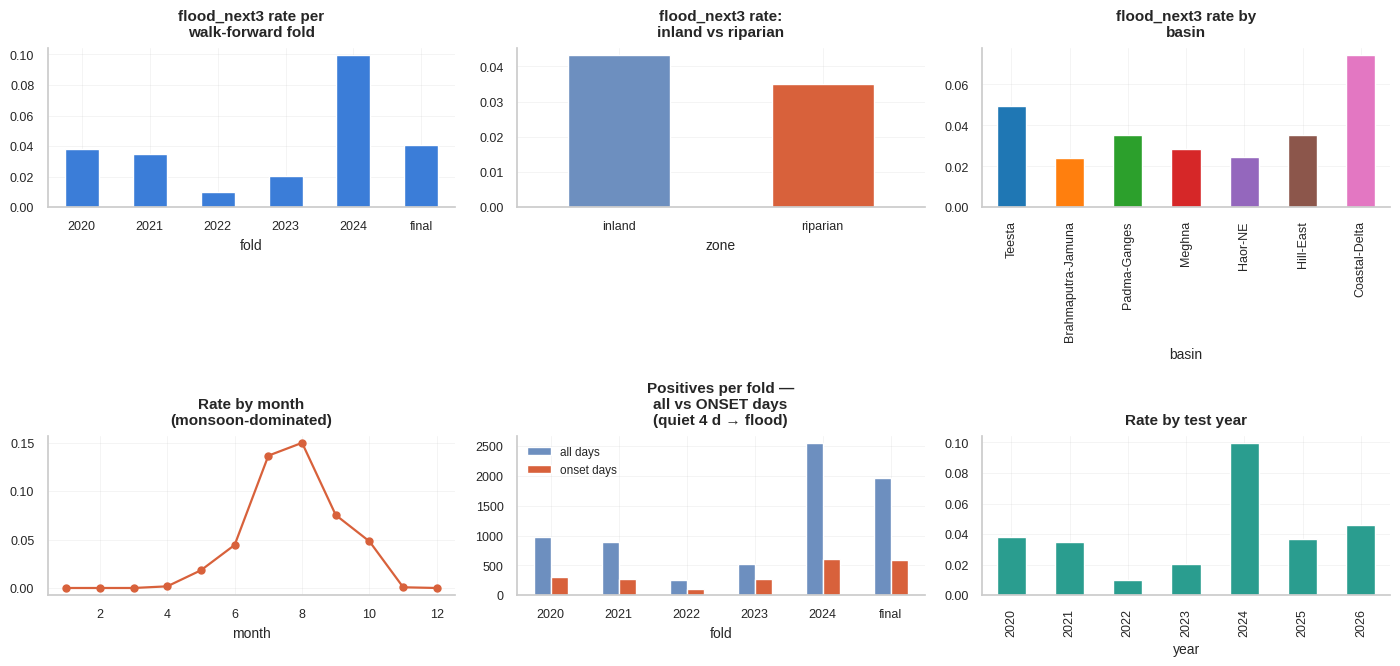

Overall: 175,700 out-of-time node-days | positives 7,153 (4.1%) | onset days 167,771 with 2,149 true onsets (1.3%)


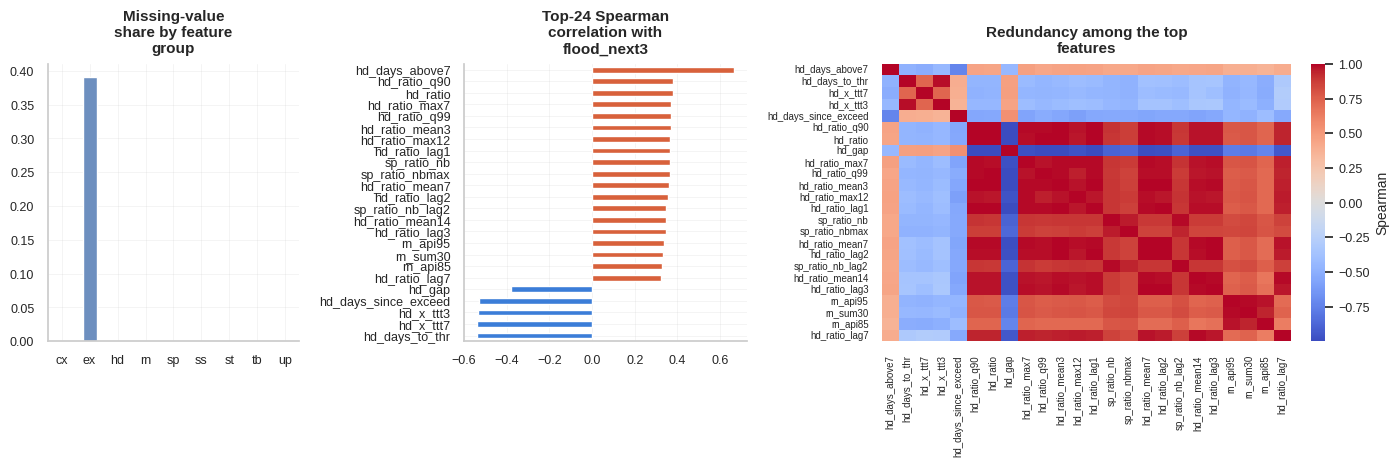

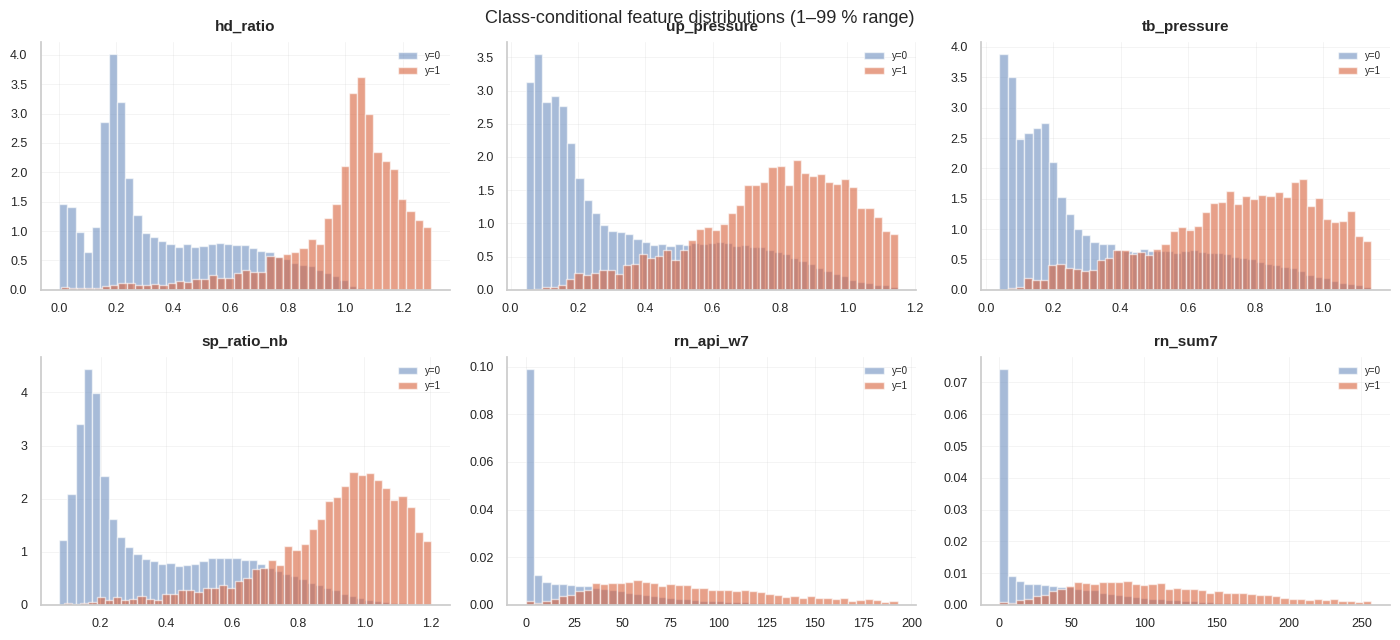

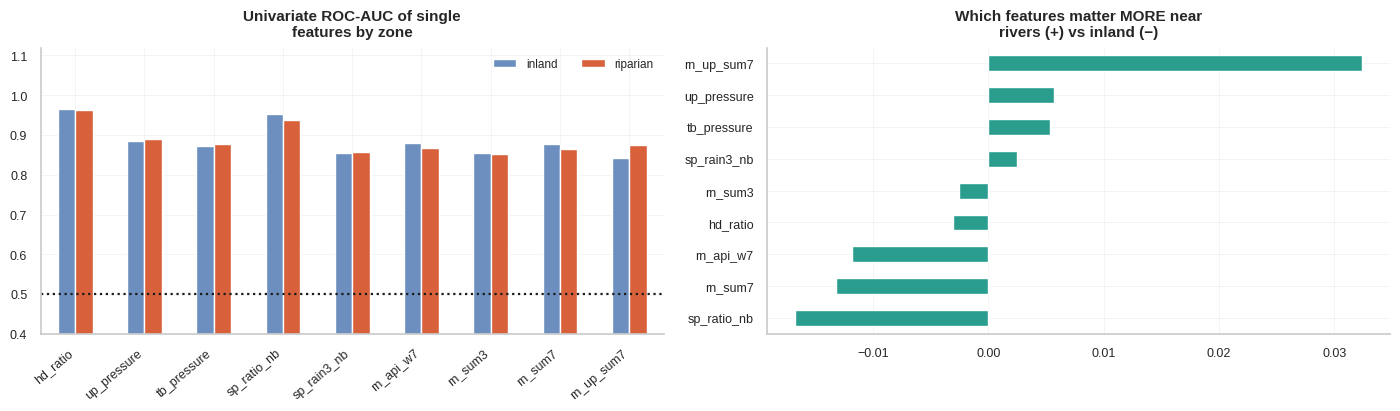

,inland,riparian,Δ (ripar − inland)
hd_ratio,0.966,0.962,-0.003
up_pressure,0.884,0.890,0.006
tb_pressure,0.873,0.878,0.005
sp_ratio_nb,0.954,0.937,-0.017
sp_rain3_nb,0.855,0.858,0.002
rn_api_w7,0.879,0.868,-0.012
rn_sum3,0.855,0.852,-0.003
rn_sum7,0.878,0.865,-0.013
rn_up_sum7,0.842,0.874,0.032


47536

In [25]:
# @title EDA 4 · Features & targets — class balance, onset share, missingness, correlations, class-conditional distributions, zone-specific drivers
PALL = pd.concat([DEVM.assign(split="dev"), TESTM.assign(split="test")], ignore_index=True); PALL["month"] = pd.to_datetime(PALL.date).dt.month; PALL["year"] = pd.to_datetime(PALL.date).dt.year
fig, ax = plt.subplots(2, 3, figsize=(21, 10))
PALL.groupby("fold").y.mean().plot.bar(ax=ax[0, 0], color="#3b7dd8"); ax[0, 0].set_title("flood_next3 rate per walk-forward fold"); ax[0, 0].tick_params(axis="x", rotation=0)
PALL.groupby("zone").y.mean().plot.bar(ax=ax[0, 1], color=["#6d8fbf", "#d8613b"]); ax[0, 1].set_title("flood_next3 rate: inland vs riparian"); ax[0, 1].tick_params(axis="x", rotation=0)
PALL.groupby("basin").y.mean().reindex(BASINS).plot.bar(ax=ax[0, 2], color=[BP[b] for b in BASINS]); ax[0, 2].set_title("flood_next3 rate by basin"); ax[0, 2].tick_params(axis="x", rotation=40)
PALL.groupby("month").y.mean().plot(ax=ax[1, 0], marker="o", color="#d8613b"); ax[1, 0].set_title("Rate by month (monsoon-dominated)")
on = PALL[PALL.on]; sh = pd.DataFrame({"all days": PALL.groupby("fold").y.sum(), "onset days": on.groupby("fold").y.sum()}); sh.plot.bar(ax=ax[1, 1], color=["#6d8fbf", "#d8613b"]); ax[1, 1].set_title("Positives per fold — all vs ONSET days (quiet 4 d → flood)"); ax[1, 1].tick_params(axis="x", rotation=0)
PALL.groupby("year").y.mean().plot.bar(ax=ax[1, 2], color="#2a9d8f"); ax[1, 2].set_title("Rate by test year")
plt.savefig(f"{EDA}/E4_label_balance.png"); plt.show(); plt.close("all")
print(f"Overall: {len(PALL):,} out-of-time node-days | positives {int(PALL.y.sum()):,} ({100*PALL.y.mean():.1f}%) | onset days {int(PALL.on.sum()):,} with {int(PALL.y[PALL.on].sum()):,} true onsets ({100*PALL.y[PALL.on].mean():.1f}%)")

samp = PF.sample(min(120_000, len(PF)), random_state=SEED); grp = pd.Series({c: c.split("_")[0] for c in FEATS}); nan_g = samp[FEATS].isna().mean().groupby(grp).mean()
cor = samp[FEATS].corrwith(samp.y, method="spearman").dropna(); top = cor.abs().sort_values(ascending=False).head(24).index
fig, ax = plt.subplots(1, 3, figsize=(24, 8), gridspec_kw={"width_ratios": [.8, .9, 1.3]})
nan_g.plot.bar(ax=ax[0], color="#6d8fbf"); ax[0].set_title("Missing-value share by feature group"); ax[0].tick_params(axis="x", rotation=0)
cor.loc[top].sort_values().plot.barh(ax=ax[1], color=["#d8613b" if v > 0 else "#3b7dd8" for v in cor.loc[top].sort_values()]); ax[1].set_title("Top-24 Spearman correlation with flood_next3")
sns.heatmap(samp[list(top)].corr(method="spearman"), cmap="coolwarm", center=0, ax=ax[2], cbar_kws={"label": "Spearman"}, xticklabels=True, yticklabels=True); ax[2].set_title("Redundancy among the top features"); ax[2].tick_params(labelsize=7)
plt.savefig(f"{EDA}/E4_feature_correlations.png"); plt.show(); plt.close("all")

key = [c for c in ("hd_ratio", "up_pressure", "tb_pressure", "sp_ratio_nb", "rn_api_w7", "rn_sum7") if c in FEATS]
fig, ax = plt.subplots(2, 3, figsize=(20, 9))
for a, c in zip(ax.ravel(), key):
    v = samp[c]; lo, hi = v.quantile(.01), v.quantile(.99)
    for lab, col in ((0, "#6d8fbf"), (1, "#d8613b")): a.hist(v[(samp.y == lab) & v.between(lo, hi)], bins=45, alpha=.6, color=col, density=True, label=f"y={lab}")
    a.set_title(c); a.legend(fontsize=7)
plt.suptitle("Class-conditional feature distributions (1–99 % range)", y=1.0); plt.savefig(f"{EDA}/E4_class_distributions.png"); plt.show(); plt.close("all")

drv = [c for c in ("hd_ratio", "up_pressure", "tb_pressure", "sp_ratio_nb", "sp_rain3_nb", "rn_api_w7", "rn_sum3", "rn_sum7", "rn_up_sum7") if c in FEATS]
zt = pd.DataFrame({z: {c: auc(g.y.values, g[c].fillna(g[c].median()).values) for c in drv} for z, g in samp.groupby("zone")}); zt["Δ (ripar − inland)"] = zt["riparian"] - zt["inland"]
fig, ax = plt.subplots(1, 2, figsize=(17, 5)); zt[["inland", "riparian"]].plot.bar(ax=ax[0], color=["#6d8fbf", "#d8613b"]); ax[0].axhline(.5, color="k", ls=":"); ax[0].set_ylim(.4, 1.12); ax[0].set_title("Univariate ROC-AUC of single features by zone"); ax[0].legend(loc="upper right", ncol=2); ax[0].tick_params(axis="x", rotation=40); plt.setp(ax[0].get_xticklabels(), ha="right")
zt["Δ (ripar − inland)"].sort_values().plot.barh(ax=ax[1], color="#2a9d8f"); ax[1].set_title("Which features matter MORE near rivers (+) vs inland (−)")
plt.savefig(f"{EDA}/E4_zone_drivers.png"); plt.show(); plt.close("all"); show(zt, 3)
del samp; gc.collect()


## 10 · Tabular branch — comparison matrix

🔒 selection FROZEN before the final test is evaluated → /content/drive/MyDrive/Bangladesh_Flood_Research/results/eval/selection_frozen.json  (model: Selected combination (walk-forward ensemble))
POOLED WALK-FORWARD (2020, 2021, 2022, 2023, 2024): 127,890 node-days, 5,191 positives, 122,141 onset days with 1,565 true onsets


,PR_AUC,ROC_AUC,F1,F2,Precision,Recall_POD,FAR,CSI,MCC,PR_AUC_onset,F1_onset,F2_onset,Recall_onset,Brier,MAE,ECE
Model,,,,,,,,,,,,,,,,
Selected combination (walk-forward ensemble),0.847,0.978,0.778,0.776,0.877,0.699,0.123,0.636,0.775,0.325,0.373,0.442,0.397,NaN,NaN,NaN
★ Selected combination (walk-forward ensemble) (calibrated),0.847,0.978,0.778,0.776,0.877,0.699,0.123,0.636,0.775,0.325,0.373,0.442,0.397,0.013,0.026,0.001
XGBoost regime-split (onset ⇄ continuation),0.841,0.976,0.773,0.772,0.850,0.709,0.150,0.630,0.768,0.307,0.365,0.425,0.404,NaN,NaN,NaN
XGBoost distance-gated (river-aware ⇄ local),0.838,0.976,0.769,0.767,0.879,0.684,0.121,0.625,0.767,0.304,0.358,0.415,0.365,NaN,NaN,NaN
Imbalance ensemble (XGB+LGBM+Bag),0.840,0.977,0.772,0.770,0.842,0.714,0.158,0.629,0.766,0.301,0.355,0.422,0.350,NaN,NaN,NaN
XGBoost (all features),0.837,0.976,0.769,0.766,0.865,0.693,0.135,0.625,0.765,0.301,0.357,0.411,0.387,NaN,NaN,NaN
XGBoost (baseline + hydrograph-shape features),0.837,0.976,0.769,0.766,0.903,0.670,0.097,0.625,0.770,0.300,0.355,0.416,0.407,NaN,NaN,NaN
XGBoost-local (no upstream/transboundary),0.837,0.976,0.769,0.765,0.874,0.687,0.126,0.625,0.767,0.298,0.355,0.414,0.382,NaN,NaN,NaN
Meta-learner · context-gated mixture-of-experts,0.836,0.976,0.767,0.765,0.872,0.684,0.128,0.622,0.764,0.297,0.361,0.424,0.406,0.015,0.036,0.013



FINAL TEST (≥ 2025, untouched): 47,810 node-days, 1,962 positives, 45,630 onset days with 584 true onsets


,PR_AUC,ROC_AUC,F1,F2,Precision,Recall_POD,FAR,CSI,MCC,PR_AUC_onset,F1_onset,F2_onset,Recall_onset,Brier,MAE,ECE
Model,,,,,,,,,,,,,,,,
Meta-learner · context-gated mixture-of-experts,0.824,0.981,0.739,0.746,0.774,0.706,0.226,0.586,0.729,0.325,0.337,0.435,0.568,0.019,0.051,0.030
Selected combination (walk-forward ensemble),0.834,0.982,0.747,0.753,0.782,0.714,0.218,0.596,0.737,0.320,0.340,0.433,0.543,NaN,NaN,NaN
★ Selected combination (walk-forward ensemble) (calibrated),0.834,0.982,0.747,0.753,0.782,0.714,0.218,0.596,0.737,0.320,0.340,0.433,0.543,0.015,0.034,0.010
Meta-learner · logistic stack (members × regime × context),0.821,0.980,0.724,0.744,0.707,0.743,0.293,0.568,0.713,0.319,0.342,0.424,0.558,0.021,0.055,0.035
LSTM (30-day sequence · pooled nodes),0.821,0.979,0.700,0.726,0.621,0.802,0.379,0.538,0.691,0.317,0.325,0.372,0.587,0.016,0.038,0.014
XGBoost (baseline features),0.825,0.981,0.741,0.752,0.837,0.665,0.163,0.589,0.737,0.316,0.357,0.449,0.495,NaN,NaN,NaN
XGBoost (baseline + hydrograph-shape features),0.825,0.981,0.735,0.753,0.864,0.640,0.136,0.581,0.734,0.315,0.349,0.434,0.507,NaN,NaN,NaN
Imbalance ensemble (XGB+LGBM+Bag),0.829,0.981,0.747,0.750,0.768,0.726,0.232,0.596,0.736,0.314,0.340,0.425,0.469,NaN,NaN,NaN
XGBoost regime-split (onset ⇄ continuation),0.831,0.981,0.746,0.754,0.784,0.712,0.216,0.595,0.737,0.311,0.336,0.438,0.483,NaN,NaN,NaN



PR-AUC per walk-forward fold (stability):


,2020,2021,2022,2023,2024,mean,std
Selected combination (walk-forward ensemble),0.833,0.849,0.736,0.611,0.903,0.786,0.115
XGBoost regime-split (onset ⇄ continuation),0.826,0.846,0.724,0.607,0.898,0.780,0.116
Imbalance ensemble (XGB+LGBM+Bag),0.825,0.847,0.725,0.600,0.900,0.780,0.119
Meta-learner · context-gated mixture-of-experts,0.822,0.843,0.729,0.597,0.902,0.778,0.119
XGBoost (baseline + hydrograph-shape features),0.822,0.839,0.726,0.603,0.899,0.778,0.116
XGBoost (baseline features),0.820,0.840,0.722,0.605,0.898,0.777,0.115
XGBoost distance-gated (river-aware ⇄ local),0.822,0.838,0.725,0.597,0.900,0.777,0.118
XGBoost-local (no upstream/transboundary),0.821,0.833,0.733,0.596,0.900,0.777,0.117
XGB+LGBM average,0.821,0.844,0.723,0.594,0.899,0.776,0.120
XGBoost (all features),0.819,0.840,0.719,0.598,0.899,0.775,0.119



Block-bootstrap (400 draws, 14-day blocks): Selected combination (walk-forward ensemble) − baseline (positive = carried-forward model better)


,sample,vs,metric,mean_diff,ci_low,ci_high,verdict
0,pooled walk-forward,Persistence-soft (rank by Q/q95 today),PR_AUC,0.077,0.056,0.101,SIGNIFICANTLY better
1,pooled walk-forward,Logistic Regression,PR_AUC,0.109,0.060,0.174,SIGNIFICANTLY better
2,pooled walk-forward,Random Forest,PR_AUC,0.011,0.005,0.018,SIGNIFICANTLY better
3,pooled walk-forward,LightGBM,PR_AUC,0.016,0.011,0.022,SIGNIFICANTLY better
4,pooled walk-forward,XGBoost (baseline features),PR_AUC,0.010,0.006,0.015,SIGNIFICANTLY better
5,pooled walk-forward,XGBoost (baseline + hydrograph-shape features),PR_AUC,0.009,0.006,0.014,SIGNIFICANTLY better
6,pooled walk-forward,LSTM (30-day sequence · pooled nodes),PR_AUC,0.039,0.029,0.051,SIGNIFICANTLY better
7,pooled walk-forward,HydroGate-Net (gated multi-scale sequence · onset-aware),PR_AUC,0.024,0.017,0.033,SIGNIFICANTLY better
8,pooled walk-forward,TabM-style MLP ensemble (k=4 · quantile-scaled),PR_AUC,0.048,0.037,0.062,SIGNIFICANTLY better
9,pooled walk-forward,Meta-learner · logistic stack (members × regime × context),PR_AUC,0.012,0.007,0.018,SIGNIFICANTLY better



Final test by zone / basin (small groups are noisy). 'gain_of_upstream_info' = full model − same model WITHOUT upstream/transboundary features:


,n,pos,PR_AUC,PR_soft_persist,PR_local_only,onset_pos,PR_AUC_onset,PR_onset_soft,gain_vs_soft,gain_of_upstream_info
group,,,,,,,,,,
inland,33467,1548,0.862,0.790,0.852,408,0.336,0.157,0.073,0.010
riparian,14343,414,0.717,0.616,0.707,176,0.293,0.153,0.101,0.010
Brahmaputra-Jamuna,6147,48,0.320,0.263,0.278,30,0.128,0.039,0.057,0.042
Coastal-Delta,9562,999,0.939,0.891,0.934,186,0.519,0.249,0.047,0.005
Haor-NE,6830,96,0.504,0.432,0.497,54,0.233,0.120,0.072,0.007
Hill-East,2732,141,0.889,0.850,0.887,34,0.402,0.222,0.039,0.002
Meghna,4781,249,0.835,0.763,0.833,74,0.405,0.182,0.072,0.002
Padma-Ganges,12977,300,0.694,0.578,0.682,133,0.190,0.127,0.117,0.012
Teesta,4781,129,0.521,0.391,0.519,73,0.297,0.161,0.131,0.002


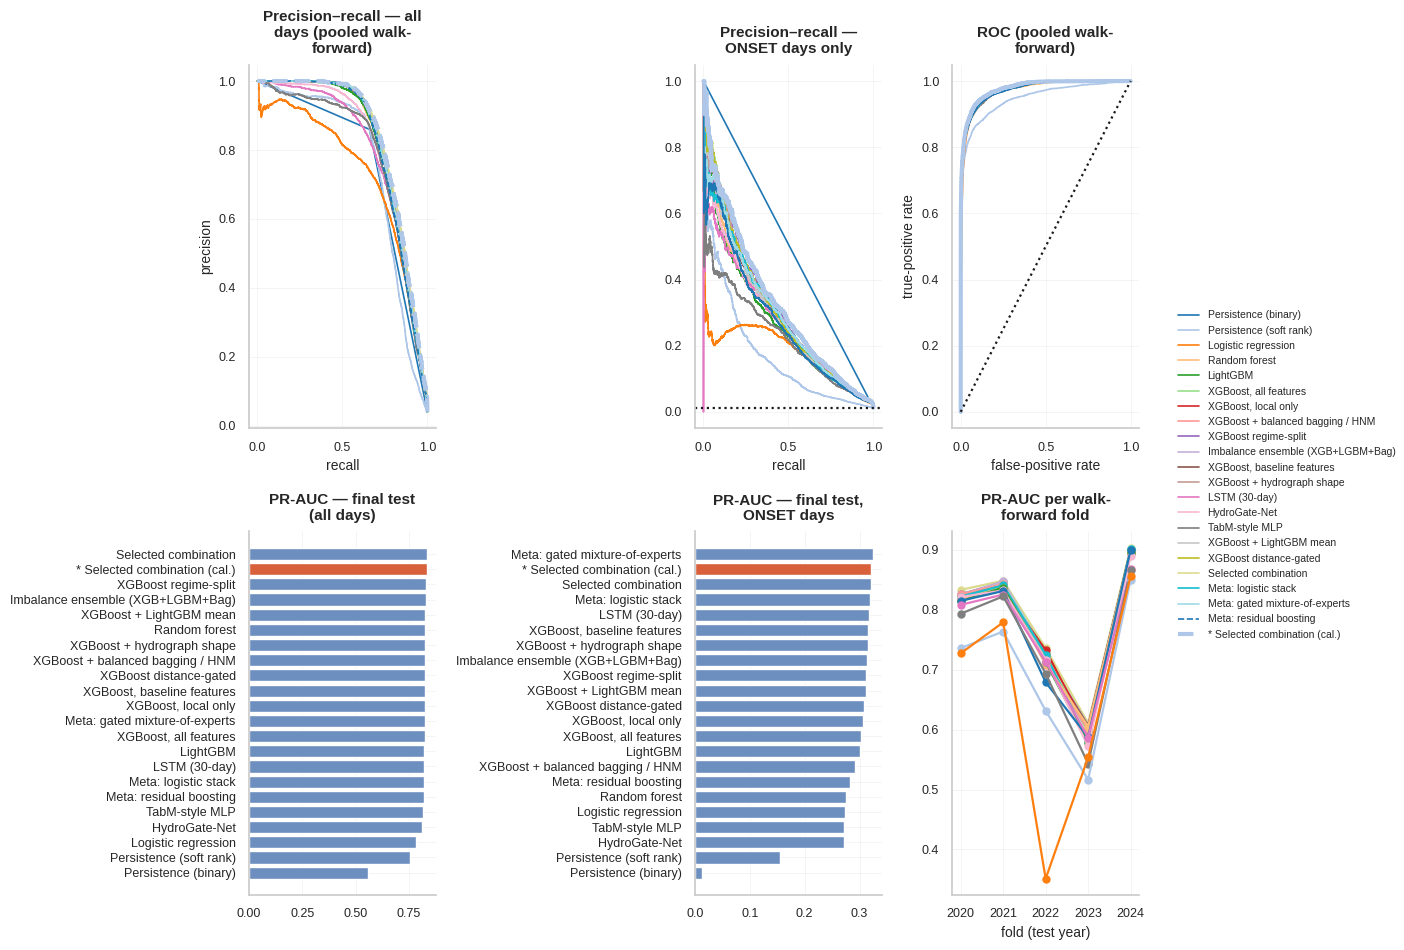

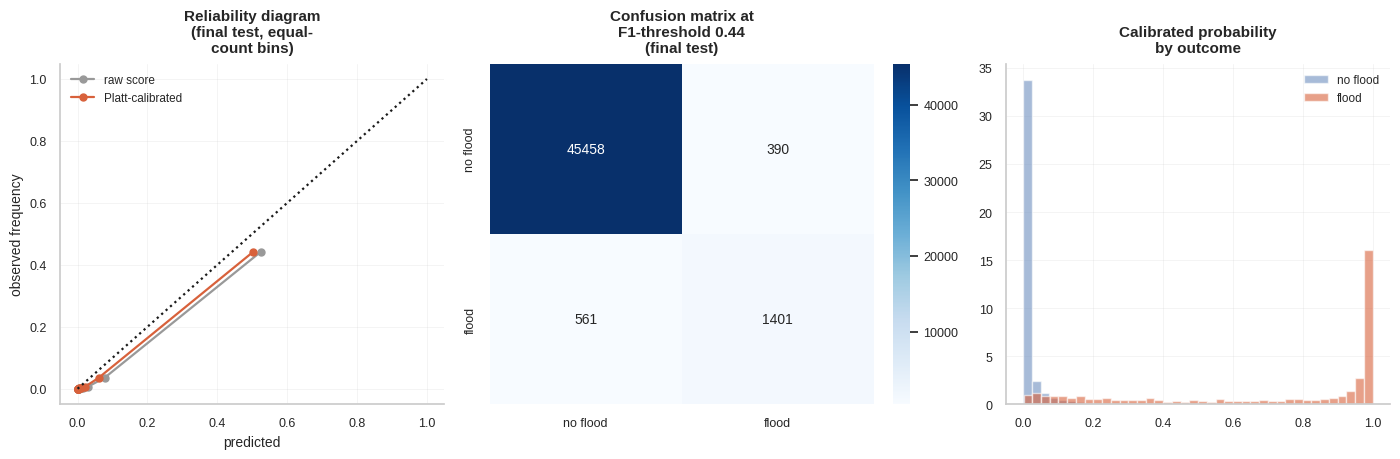


=== TABULAR BRANCH VERDICT (computed, not asserted) ===
[pooled walk-forward] ONSET PR-AUC 0.325 vs soft-persistence 0.167 vs base-rate 0.013 | diff +0.156 (95% CI +0.127…+0.186) → SIGNIFICANTLY better
[final test] ONSET PR-AUC 0.320 vs soft-persistence 0.155 vs base-rate 0.013 | diff +0.161 (95% CI +0.101…+0.209) → SIGNIFICANTLY better
🧠 RAM 2.09 GB used of 13.6 GB  after tabular evaluation


In [26]:
# @title 10 · TABULAR BRANCH — comparison matrix: pooled walk-forward AND untouched final test · overall + ONSET · PR-AUC/ROC-AUC/F1/POD/FAR/CSI/Brier/ECE · folds · zones · block-bootstrap
EV = DIRS["results/eval"]; MD = DIRS["saved_models"]
BINARY = {"Persistence (binary: stays as today)"}; SOFT = "Persistence-soft (rank by Q/q95 today)"
DEVS["★ " + TAB_NAME + " (calibrated)"] = CAL_TAB(DEVS[TAB_NAME]); TESTS["★ " + TAB_NAME + " (calibrated)"] = CAL_TAB(TESTS[TAB_NAME]); TAB_CAL_NAME = "★ " + TAB_NAME + " (calibrated)"
def thr4(y, p, on):
    """Four thresholds picked on DEVELOPMENT data only: F1 (overall, onset) and F2 (overall, onset). F2 weights recall 4× precision — the right objective for life-safety WATCH alerts."""
    a = best_thr(y, p); a2 = best_thr(y, p, 2.0); o = best_thr(y[on], p[on]) if on.any() else a; o2 = best_thr(y[on], p[on], 2.0) if on.any() else a2
    return (a, o, a2, o2)
THR = {n: ((0.5, 0.5, 0.5, 0.5) if n in BINARY else thr4(yD, DEVS[n], onD)) for n in DEVS}      # thresholds from DEV only
def bench(S, M, thr):
    y, on = M.y.values, M.on.values; rows = []
    for n, p in S.items():
        th = thr[n]; ta, to = th[0], th[1]; t2, t2o = (th[2], th[3]) if len(th) > 2 else (ta, to); v = verif(y, (p >= ta).astype(int)); prob = n.startswith(("★", "·", "Meta", "Tabular only", "CNN only", "LSTM", "HydroGate", "TabM"))
        rows.append(dict(Model=n, PR_AUC=aps(y, p), ROC_AUC=auc(y, p), F1=float(f1_score(y, p >= ta, zero_division=0)), F2=float(fbeta_score(y, p >= t2, beta=2, zero_division=0)), Precision=float(precision_score(y, p >= ta, zero_division=0)),
                         Recall_POD=v["POD"], FAR=v["FAR"], CSI=v["CSI"], MCC=float(matthews_corrcoef(y, p >= ta)), PR_AUC_onset=aps(y[on], p[on]), F1_onset=float(f1_score(y[on], p[on] >= to, zero_division=0)),
                         F2_onset=float(fbeta_score(y[on], p[on] >= t2o, beta=2, zero_division=0)), Recall_onset=float(recall_score(y[on], p[on] >= to, zero_division=0)),
                         Brier=float(brier_score_loss(y, np.clip(p, 0, 1))) if prob else np.nan, MAE=float(np.mean(np.abs(y - np.clip(p, 0, 1)))) if prob else np.nan, ECE=ece(y, p) if prob else np.nan))
    return pd.DataFrame(rows).set_index("Model").sort_values("PR_AUC_onset", ascending=False)
FROZEN = dict(tab_model=TAB_NAME, combo_weights={k: float(v) for k, v in COMBO_W.items()}, xgb_params=XGB_P, imbalance=IMB, n_iter=int(N_ITER), distance_gate=[GD0, GS_], thresholds={k: [float(x) for x in v] for k, v in THR.items() if k == TAB_CAL_NAME},
              dev_folds=list(map(int, DEV_FOLDS)), final_test_from=int(FINAL_TEST_FROM), feat_ver=FEAT_VER, n_features=len(FEATS), frozen_at=str(pd.Timestamp.now()))
json.dump(FROZEN, open(f"{EV}/selection_frozen.json", "w"), indent=1, default=str); print(f"🔒 selection FROZEN before the final test is evaluated → {EV}/selection_frozen.json  (model: {TAB_NAME})")
BENCH_DEV, BENCH_TEST = bench(DEVS, DEVM, THR), bench(TESTS, TESTM, THR); BENCH_DEV.round(4).to_csv(f"{EV}/T_benchmark_dev_walkforward.csv"); BENCH_TEST.round(4).to_csv(f"{EV}/T_benchmark_final_test.csv")
print(f"POOLED WALK-FORWARD ({', '.join(map(str, DEV_FOLDS))}): {len(DEVM):,} node-days, {int(DEVM.y.sum()):,} positives, {int(DEVM.on.sum()):,} onset days with {int(DEVM.y[DEVM.on].sum()):,} true onsets"); show(BENCH_DEV)
print(f"\nFINAL TEST (≥ {FINAL_TEST_FROM}, untouched): {len(TESTM):,} node-days, {int(TESTM.y.sum()):,} positives, {int(TESTM.on.sum()):,} onset days with {int(TESTM.y[TESTM.on].sum()):,} true onsets"); show(BENCH_TEST)

# ---- fold-by-fold stability ----------------------------------------------------------------------------------------------------------------------------------------
MODELS_SHOW = [n for n in DEVS if not n.startswith("★")]; FOLD = pd.DataFrame({n: {f: aps(g.y.values, DEVS[n][g.index.values]) for f, g in DEVM.groupby("fold")} for n in MODELS_SHOW}).T
FOLD["mean"] = FOLD.mean(axis=1); FOLD["std"] = FOLD.iloc[:, :-1].std(axis=1); FOLD = FOLD.sort_values("mean", ascending=False); FOLD.round(4).to_csv(f"{EV}/T_fold_stability.csv"); print("\nPR-AUC per walk-forward fold (stability):"); show(FOLD)

# ---- block bootstrap: is the carried-forward model significantly better than each baseline? (14-day blocks keep temporal + cross-node dependence) -------------------------------
def block_boot(dates, n_boot, block_days, seed):
    by = pd.Series(np.arange(len(dates))).groupby(dates).indices; ud = np.array(sorted(by)); nb = int(np.ceil(len(ud) / block_days))
    blocks = [np.concatenate([by[x] for x in ud[i * block_days:(i + 1) * block_days]]) for i in range(nb)]; rng = np.random.default_rng(seed)
    return [np.concatenate([blocks[j] for j in rng.integers(0, nb, nb)]) for _ in range(n_boot)]
def sig_table(S, M, label, ref, vs):
    y, on = M.y.values, M.on.values; B = block_boot(M.date.values, N_BOOT, BLOCK_DAYS, SEED); rows = []; fa = lambda yy, pp, oo: aps(yy, pp); fo = lambda yy, pp, oo: aps(yy[oo], pp[oo]) if oo.any() else np.nan
    for lab, fn in (("PR_AUC", fa), ("PR_AUC_onset", fo)):
        r = np.array([fn(y[b], S[ref][b], on[b]) for b in B], float)
        for n in vs:
            d = r - np.array([fn(y[b], S[n][b], on[b]) for b in B], float); rows.append(dict(sample=label, vs=n, metric=lab, mean_diff=np.nanmean(d), ci_low=np.nanpercentile(d, 2.5), ci_high=np.nanpercentile(d, 97.5)))
    return pd.DataFrame(rows)
VS = [SOFT, "Logistic Regression", "Random Forest", "LightGBM"] + ([NOEX_NAME] if HAS_EX else []) + ([LOCX_NAME] if HAS_LOCX else []) + ([LSTM_NAME] if LSTM_NAME in DEVS else []) + ([HG_NAME] if HG_NAME in DEVS else []) + ([TABM_NAME] if TABM_NAME in DEVS else []) + list(META_NAMES); SIG_TAB = pd.concat([sig_table(DEVS, DEVM, "pooled walk-forward", TAB_NAME, VS), sig_table(TESTS, TESTM, "final test", TAB_NAME, VS)])
SIG_TAB["verdict"] = np.where(SIG_TAB.ci_low > 0, "SIGNIFICANTLY better", np.where(SIG_TAB.ci_high < 0, "significantly worse", "not significant")); SIG_TAB.round(4).to_csv(f"{EV}/T_significance.csv", index=False)
print(f"\nBlock-bootstrap ({N_BOOT} draws, {BLOCK_DAYS}-day blocks): {TAB_NAME} − baseline (positive = carried-forward model better)"); show(SIG_TAB, 3)

# ---- by zone / basin (final test): does the model help where the physics says it should? --------------------------------------------------------------------------------------
T = TESTM.copy(); T["p"] = TESTS[TAB_NAME]; T["p_soft"] = TESTS[SOFT]; T["p_loc"] = TESTS["XGBoost-local (no upstream/transboundary)"]; tab = []
for key, g in list(T.groupby("zone")) + list(T.groupby("basin")):
    on = g[g.on]; tab.append(dict(group=key, n=len(g), pos=int(g.y.sum()), PR_AUC=aps(g.y.values, g.p.values), PR_soft_persist=aps(g.y.values, g.p_soft.values), PR_local_only=aps(g.y.values, g.p_loc.values),
                                  onset_pos=int(on.y.sum()), PR_AUC_onset=aps(on.y.values, on.p.values) if len(on) else np.nan, PR_onset_soft=aps(on.y.values, on.p_soft.values) if len(on) else np.nan))
BYZ = pd.DataFrame(tab).set_index("group"); BYZ["gain_vs_soft"] = BYZ.PR_AUC - BYZ.PR_soft_persist; BYZ["gain_of_upstream_info"] = BYZ.PR_AUC - BYZ.PR_local_only; BYZ.round(4).to_csv(f"{EV}/T_by_zone_basin.csv")
print("\nFinal test by zone / basin (small groups are noisy). 'gain_of_upstream_info' = full model − same model WITHOUT upstream/transboundary features:"); show(BYZ, 3)

# ---- plots ----------------------------------------------------------------------------------------------------------------------------------------------------------------
_p20 = sns.color_palette("tab20", 20); pal = {n: _p20[k % 20] for k, n in enumerate(DEVS)}; fig, ax = plt.subplots(2, 3, figsize=(14, 9.5))
for n, p in DEVS.items():
    lw = 3 if n == TAB_CAL_NAME else 1.2; pr, rc, _ = precision_recall_curve(yD, p); ax[0, 0].plot(rc, pr, lw=lw, color=pal[n], ls="-" if list(DEVS).index(n) < 20 else "--", label=short_name(n))
    if onD.any(): pr, rc, _ = precision_recall_curve(yD[onD], p[onD]); ax[0, 1].plot(rc, pr, lw=lw, color=pal[n])
    if n not in BINARY:
        from sklearn.metrics import roc_curve; fp_, tp_, _ = roc_curve(yD, p); ax[0, 2].plot(fp_, tp_, lw=lw, color=pal[n])
ax[0, 0].set_title("Precision–recall — all days (pooled walk-forward)"); fig.legend(*ax[0, 0].get_legend_handles_labels(), loc="outside right", ncol=1, fontsize=7.5); ax[0, 0].set_xlabel("recall"); ax[0, 0].set_ylabel("precision"); ax[0, 1].set_xlabel("recall"); ax[0, 2].set_xlabel("false-positive rate"); ax[0, 2].set_ylabel("true-positive rate"); ax[0, 1].set_title("Precision–recall — ONSET days only"); ax[0, 1].axhline(yD[onD].mean() if onD.any() else 0, color="k", ls=":"); ax[0, 2].plot([0, 1], [0, 1], "k:"); ax[0, 2].set_title("ROC (pooled walk-forward)")
bt = BENCH_TEST.sort_values("PR_AUC"); ax[1, 0].barh([short_name(n) for n in bt.index], bt.PR_AUC, color=["#d8613b" if n == TAB_CAL_NAME else "#6d8fbf" for n in bt.index]); ax[1, 0].set_title("PR-AUC — final test (all days)")
bt = BENCH_TEST.sort_values("PR_AUC_onset"); ax[1, 1].barh([short_name(n) for n in bt.index], bt.PR_AUC_onset, color=["#d8613b" if n == TAB_CAL_NAME else "#6d8fbf" for n in bt.index]); ax[1, 1].set_title("PR-AUC — final test, ONSET days")
FOLD.drop(columns=["mean", "std"]).loc[[n for n in FOLD.index if n not in BINARY]].T.plot(ax=ax[1, 2], marker="o", legend=False, color=[pal.get(n, "grey") for n in FOLD.index if n not in BINARY]); ax[1, 2].set_title("PR-AUC per walk-forward fold"); ax[1, 2].set_xlabel("fold (test year)")
plt.savefig(f"{EV}/T_curves_and_bars.png"); plt.show(); plt.close("all")

fig, ax = plt.subplots(1, 3, figsize=(14, 4.6)); yT = TESTM.y.values
for lab, p, c in (("raw score", TESTS[TAB_NAME], "#999"), ("Platt-calibrated", TESTS[TAB_CAL_NAME], "#d8613b")):
    b = pd.qcut(pd.Series(p).rank(method="first"), 12, labels=False); g = pd.DataFrame({"p": p, "y": yT, "b": b}).groupby("b").mean(); ax[0].plot(g.p, g.y, marker="o", color=c, label=lab)
ax[0].plot([0, 1], [0, 1], "k:"); ax[0].set_title("Reliability diagram (final test, equal-count bins)"); ax[0].set_xlabel("predicted"); ax[0].set_ylabel("observed frequency"); ax[0].legend(loc="upper left")
ta = THR[TAB_CAL_NAME][0]; cm = confusion_matrix(yT, TESTS[TAB_CAL_NAME] >= ta); sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax[1], xticklabels=["no flood", "flood"], yticklabels=["no flood", "flood"]); ax[1].set_title(f"Confusion matrix at F1-threshold {ta:.2f} (final test)")
ax[2].hist(TESTS[TAB_CAL_NAME][yT == 0], bins=40, alpha=.6, label="no flood", color="#6d8fbf", density=True); ax[2].hist(TESTS[TAB_CAL_NAME][yT == 1], bins=40, alpha=.6, label="flood", color="#d8613b", density=True); ax[2].set_title("Calibrated probability by outcome"); ax[2].legend()
plt.savefig(f"{EV}/T_calibration.png"); plt.show(); plt.close("all")

print("\n=== TABULAR BRANCH VERDICT (computed, not asserted) ===")
for lab, B_, M_ in (("pooled walk-forward", BENCH_DEV, DEVM), ("final test", BENCH_TEST, TESTM)):
    s = SIG_TAB[(SIG_TAB["sample"] == lab) & (SIG_TAB.metric == "PR_AUC_onset") & (SIG_TAB.vs == SOFT)].iloc[0]
    print(f"[{lab}] ONSET PR-AUC {B_.loc[TAB_CAL_NAME,'PR_AUC_onset']:.3f} vs soft-persistence {B_.loc[SOFT,'PR_AUC_onset']:.3f} vs base-rate {M_.y[M_.on].mean():.3f} | diff {s.mean_diff:+.3f} (95% CI {s.ci_low:+.3f}…{s.ci_high:+.3f}) → {s.verdict}")
ram("after tabular evaluation")


### 10b · Importance, ablations, SHAP, save artefacts

,meaning,n_features,perm_drop_PR_AUC,gain_share
group,,,,
hd,node hydrology,39,0.7351,0.7937
rn,local rain / API,19,0.0471,0.0907
ss,season,3,0.0146,0.0178
st,static geography,12,0.0057,0.0140
up,upstream (dynamic weights),11,0.0054,0.0177
tb,transboundary,4,0.0019,0.0053
ex,extra sources (keyless APIs: Open-Meteo ERA5-Land / ERA5 · NASA POWER; optional Earth Engine CHIRPS / ERA5-Land),24,0.0009,0.0361
cx,riparian-context interactions,4,0.0002,0.0028
sp,spatial lag,5,-0.0004,0.0219



Retrained ablations (final test; negative Δ = the removed group was helping):


,n_features,PR_AUC,PR_AUC_onset,PR_AUC_riparian,PR_AUC_inland,Δ PR_AUC,Δ PR_AUC_onset,Δ PR_AUC_riparian,Δ PR_AUC_inland
variant,,,,,,,,,
full model (all groups),121,0.8235,0.3035,0.7089,0.8516,0.0000,0.0000,0.0000,0.0000
− spatial lag (sp_),116,0.8232,0.3044,0.7050,0.8520,-0.0003,0.0009,-0.0039,0.0004
"− transboundary (tb_, cx_tb)",116,0.8224,0.3046,0.7049,0.8509,-0.0012,0.0011,-0.0040,-0.0007
"− upstream & transboundary (up_, tb_)",104,0.8223,0.3051,0.7047,0.8511,-0.0013,0.0016,-0.0043,-0.0005
"− static geography & context (st_, cx_)",105,0.8206,0.2971,0.7055,0.8488,-0.0029,-0.0064,-0.0035,-0.0028
− windowed API (rn_api*),115,0.8229,0.3028,0.7064,0.8514,-0.0006,-0.0007,-0.0025,-0.0002
− extra sources (ex_),97,0.8254,0.3147,0.7110,0.8533,0.0019,0.0112,0.0020,0.0017
− hydrograph-shape (hd_x_),105,0.8230,0.3051,0.7070,0.8513,-0.0006,0.0016,-0.0019,-0.0003
"v3-like (hd_, up_, rn_, ss_ only)",68,0.8229,0.3098,0.7073,0.8509,-0.0006,0.0063,-0.0017,-0.0007


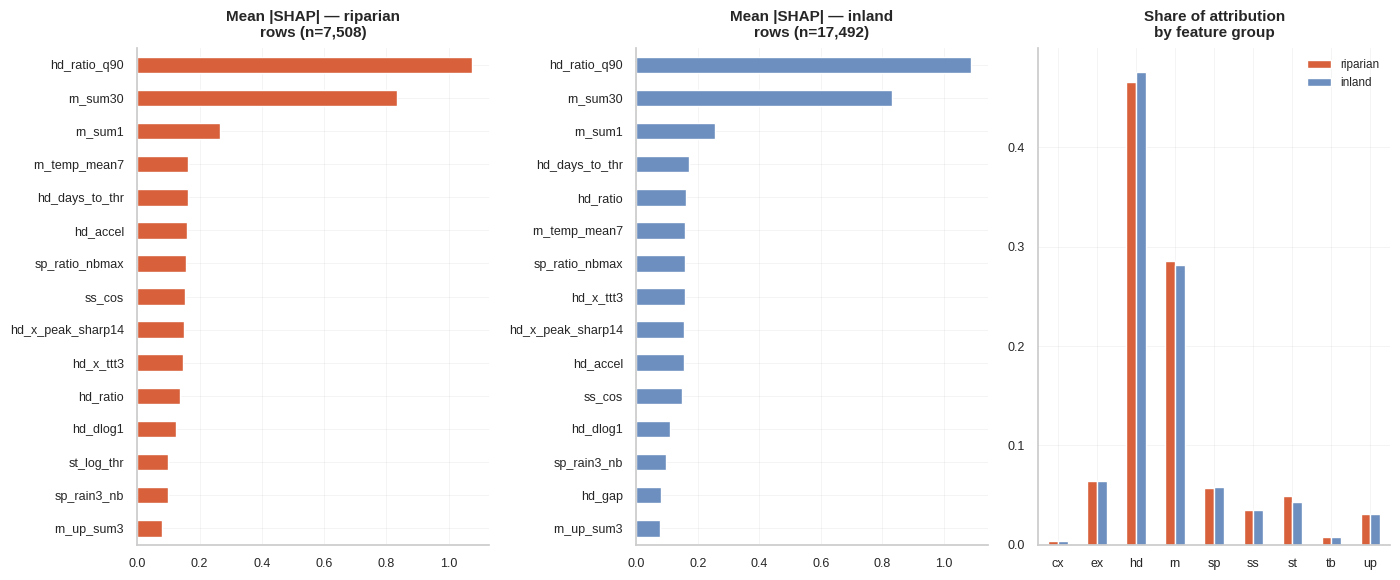

💾 saved: processed_data/daily_final_{train,test}.parquet (zstd) · saved_models/national_tabular_branch.joblib · national_fit_network.json
🧠 RAM 1.97 GB used of 13.6 GB  after ablations


In [27]:
# @title 10b · TABULAR BRANCH — what drives the model? feature-group importance · retrained ABLATIONS (incl. a v3-like feature set) · zone-specific SHAP · save artefacts
GROUP_OF = np.array([c.split("_")[0] for c in FEATS]); yT = TESTM.y.values; onT = TESTM.on.values; rng = np.random.default_rng(SEED)
sub = np.sort(rng.choice(len(yT), min(25_000, len(yT)), replace=False)); Xs, ys, zs = XTE[sub], yT[sub], TESTM.zone.values[sub]
base_ap = aps(ys, XGB_MAIN.predict_proba(Xs)[:, 1]); rows = []
for g, nm in GROUPS.items():
    cols = np.where(GROUP_OF == g)[0]
    if not len(cols): continue
    d = []
    for rep in range(3):
        Xp = Xs.copy(); perm = rng.permutation(len(Xs)); Xp[:, cols] = Xs[perm][:, cols]; d.append(base_ap - aps(ys, XGB_MAIN.predict_proba(Xp)[:, 1]))
    rows.append(dict(group=g, meaning=nm, n_features=len(cols), perm_drop_PR_AUC=float(np.mean(d))))
gain = pd.Series(XGB_MAIN.get_booster().get_score(importance_type="total_gain")); gain.index = [FEATS[int(i[1:])] for i in gain.index]; gg = gain.groupby(lambda c: c.split("_")[0]).sum(); gg = gg / gg.sum()
GI = pd.DataFrame(rows).set_index("group"); GI["gain_share"] = gg.reindex(GI.index).fillna(0).values; show(GI.sort_values("perm_drop_PR_AUC", ascending=False), 4); GI.round(4).to_csv(f"{EV}/T_group_importance.csv")

# ---- retrained ablations (final fold; each variant re-fitted from scratch on the same train rows, evaluated on the same untouched test rows) --------------------------------------
Ptr = PF[~PF.is_test]; Pte = PF[PF.is_test]; ytr = Ptr.y.values; spw = IMB["spw_mult"] * (ytr == 0).sum() / max(ytr.sum(), 1); swt = sw_of(ytr, Ptr.quiet4.values.astype(int), IMB["onset_w"])
ABL = {"full model (all groups)": FEATS, "− spatial lag (sp_)": [c for c in FEATS if not c.startswith("sp_")], "− transboundary (tb_, cx_tb)": [c for c in FEATS if not c.startswith("tb_") and c != "cx_tb_drive"],
       "− upstream & transboundary (up_, tb_)": [c for c in FEATS if not c.startswith(("up_", "tb_")) and c not in ("cx_river_drive", "cx_tb_drive")], "− static geography & context (st_, cx_)": [c for c in FEATS if not c.startswith(("st_", "cx_"))],
       "− windowed API (rn_api*)": [c for c in FEATS if not c.startswith("rn_api")], "− extra sources (ex_)": [c for c in FEATS if not c.startswith("ex_")], "− hydrograph-shape (hd_x_)": [c for c in FEATS if not c.startswith("hd_x_")], "v3-like (hd_, up_, rn_, ss_ only)": [c for c in FEATS if c.startswith(("hd_", "up_", "rn_", "ss_")) and not c.startswith("rn_api_w") and c != "rn_api7_rel"]}
rows = []; zT = Pte.zone.values; onP = Pte.quiet4.values.astype(bool); yP = Pte.y.values
for nm, cols in ABL.items():
    m = xgb_make(XGB_P, N_ITER, spw).fit(Ptr[cols].to_numpy(np.float32), ytr, sample_weight=swt); p = m.predict_proba(Pte[cols].to_numpy(np.float32))[:, 1]
    rows.append(dict(variant=nm, n_features=len(cols), PR_AUC=aps(yP, p), PR_AUC_onset=aps(yP[onP], p[onP]), PR_AUC_riparian=aps(yP[zT == "riparian"], p[zT == "riparian"]), PR_AUC_inland=aps(yP[zT == "inland"], p[zT == "inland"])))
ABLT = pd.DataFrame(rows).set_index("variant")
for c in ("PR_AUC", "PR_AUC_onset", "PR_AUC_riparian", "PR_AUC_inland"): ABLT["Δ " + c] = ABLT[c] - ABLT.loc["full model (all groups)", c]
print("\nRetrained ablations (final test; negative Δ = the removed group was helping):"); show(ABLT, 4); ABLT.round(4).to_csv(f"{EV}/T_ablations.csv"); del Ptr, Pte; gc.collect()

# ---- SHAP-style attribution (XGBoost's exact tree contributions) — separately for riparian and inland rows ------------------------------------------------------------------------------
contrib = XGB_MAIN.get_booster().predict(xgb.DMatrix(Xs), pred_contribs=True)[:, :-1]; fig, ax = plt.subplots(1, 3, figsize=(14, 5.8))
for a, z, c in zip(ax[:2], ("riparian", "inland"), ("#d8613b", "#6d8fbf")):
    s = pd.Series(np.abs(contrib[zs == z]).mean(0), FEATS).sort_values().tail(15); s.plot.barh(ax=a, color=c); a.set_title(f"Mean |SHAP| — {z} rows (n={int((zs == z).sum()):,})")
gs = pd.DataFrame({z: pd.Series(np.abs(contrib[zs == z]).mean(0), FEATS).groupby(lambda c: c.split("_")[0]).sum() for z in ("riparian", "inland")}); (gs / gs.sum()).plot.bar(ax=ax[2], color=["#d8613b", "#6d8fbf"]); ax[2].set_title("Share of attribution by feature group"); ax[2].tick_params(axis="x", rotation=0)
plt.savefig(f"{EV}/T_shap_by_zone.png"); plt.show(); plt.close("all")

# ---- persist (Drive): Zstd-Parquet shards of the final panel + model artefacts --------------------------------------------------------------------------------------------------------
import joblib
for nm_, mask in (("train", ~PF.is_test.values), ("test", PF.is_test.values)): PF[mask].drop(columns=["is_test"]).to_parquet(f"{DIRS['processed_data']}/daily_final_{nm_}.parquet", compression="zstd", compression_level=6, index=False)
joblib.dump(dict(xgb_all=XGB_MAIN, xgb_local=XGB_LOCAL, feats=FEATS, local_feats=LOCAL, params=XGB_P, n_iter=N_ITER, cal_lr=CAL_TAB.lr, tab_name=TAB_NAME, gate=(GD0, GS_), imb=IMB, extra=EXTRA), f"{MD}/national_tabular_branch.joblib")
json.dump(FIT_FINAL, open(f"{MD}/national_fit_network.json", "w"), indent=1, default=float); print("💾 saved: processed_data/daily_final_{train,test}.parquet (zstd) · saved_models/national_tabular_branch.joblib · national_fit_network.json"); ram("after ablations")


### 10c · Imbalance-method comparison (evidence for the v5 recipe)

,PR_AUC,PR_AUC_onset,F1,F2,F1_onset,F2_onset,Recall_POD,FAR,CSI,MCC
Model,,,,,,,,,,
1 · no re-weighting,0.8266,0.3014,0.7439,0.7416,0.3427,0.4052,0.7232,0.2342,0.5922,0.7336
2 · natural scale_pos_weight,0.8210,0.2865,0.7427,0.7410,0.2936,0.3825,0.7120,0.2239,0.5907,0.7329
3 · √ scale_pos_weight,0.8254,0.2963,0.7466,0.7529,0.3232,0.3990,0.7187,0.2231,0.5957,0.7368
4 · tuned spw × onset weight (v5),0.8192,0.2960,0.6963,0.7233,0.3175,0.4032,0.7793,0.3708,0.5341,0.6861
5 · balanced bagging + hard negatives,0.8236,0.2928,0.7437,0.7479,0.3163,0.3821,0.7069,0.2155,0.5920,0.7344
6 · tuned + bagging (logit avg),0.8249,0.3004,0.6953,0.7482,0.3164,0.4087,0.7849,0.3760,0.5329,0.6856


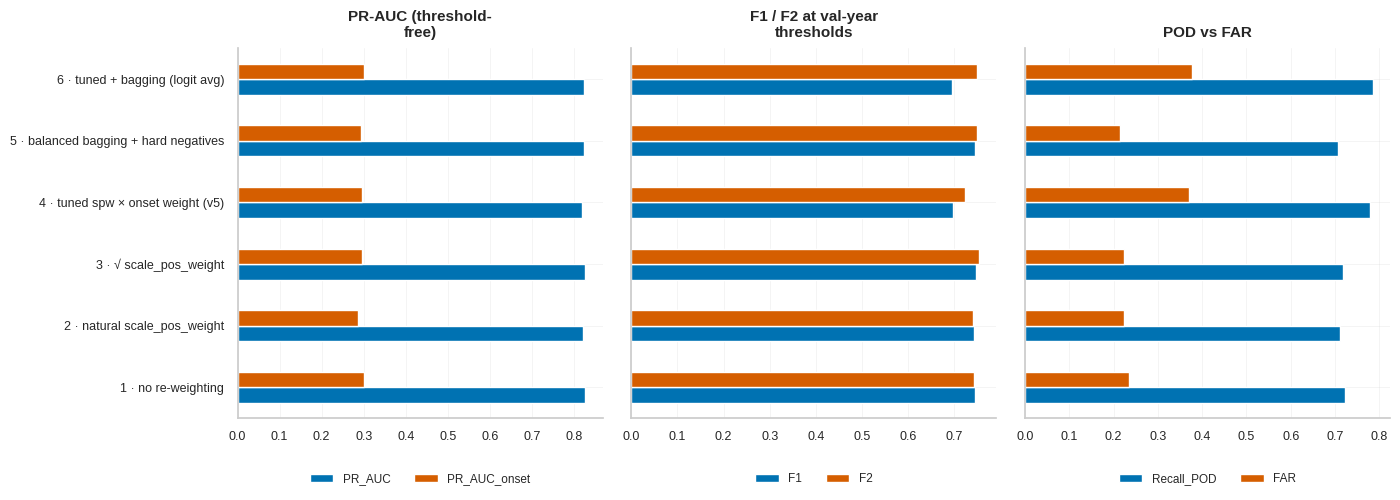

64213

In [28]:
# @title 10c · IMBALANCE-METHOD COMPARISON — same rows, same features, same test set; thresholds picked on a held-out TRAINING year (no test peeking)
tl = pd.Timestamp(FINAL_TEST_FROM - 1, 12, 31); Ptr_ = PF[~PF.is_test].reset_index(drop=True); Pte_ = PF[PF.is_test].reset_index(drop=True)
fi = np.where((Ptr_.date <= tl - pd.Timedelta(days=365 + EMBARGO)).values)[0]; vi = np.where((Ptr_.date > tl - pd.Timedelta(days=365)).values)[0]       # fit on ≤ 2023(-embargo), threshold-select on 2024
Xa, ya, qa = Ptr_[FEATS].to_numpy(np.float32), Ptr_.y.to_numpy(int), Ptr_.quiet4.to_numpy(int); Xt = Pte_[FEATS].to_numpy(np.float32); nat = (ya[fi] == 0).sum() / max(ya[fi].sum(), 1)
VAR = {"1 · no re-weighting": (1.0, 1.0), "2 · natural scale_pos_weight": (nat, 1.0), "3 · √ scale_pos_weight": (np.sqrt(nat), 1.0), "4 · tuned spw × onset weight (v5)": (IMB["spw_mult"] * nat, IMB["onset_w"])}
SVv, STv = {}, {}
for nm, (s_, ow) in VAR.items():
    m = xgb_make(XGB_P, N_ITER, s_).fit(Xa[fi], ya[fi], sample_weight=sw_of(ya[fi], qa[fi], ow)); SVv[nm] = m.predict_proba(Xa[vi])[:, 1]; STv[nm] = m.predict_proba(Xt)[:, 1]
bg = bag_fit(Xa, ya, fi, N_ITER); SVv["5 · balanced bagging + hard negatives"] = bag_predict(bg, Xa[vi]); STv["5 · balanced bagging + hard negatives"] = bag_predict(bg, Xt)
SVv["6 · tuned + bagging (logit avg)"] = ens_of(SVv["4 · tuned spw × onset weight (v5)"], SVv["5 · balanced bagging + hard negatives"]); STv["6 · tuned + bagging (logit avg)"] = ens_of(STv["4 · tuned spw × onset weight (v5)"], STv["5 · balanced bagging + hard negatives"])
thr_ = {n: thr4(ya[vi], SVv[n], qa[vi].astype(bool)) for n in STv}; Mi = pd.DataFrame(dict(y=Pte_.y.values, on=Pte_.quiet4.values.astype(bool))); IMBT = bench(STv, Mi, thr_).drop(columns=["Brier", "MAE", "ECE"])
IMBT = IMBT.sort_index(); show(IMBT[["PR_AUC", "PR_AUC_onset", "F1", "F2", "F1_onset", "F2_onset", "Recall_POD", "FAR", "CSI", "MCC"]], 4); IMBT.round(4).to_csv(f"{EV}/T_imbalance_methods.csv")
fig, ax = plt.subplots(1, 3, figsize=(14, 5), sharey=True); IMBT[["PR_AUC", "PR_AUC_onset"]].plot.barh(ax=ax[0]); ax[0].set_title("PR-AUC (threshold-free)"); IMBT[["F1", "F2"]].plot.barh(ax=ax[1]); ax[1].set_title("F1 / F2 at val-year thresholds"); IMBT[["Recall_POD", "FAR"]].plot.barh(ax=ax[2]); ax[2].set_title("POD vs FAR")
[(a_.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2), a_.set_ylabel("")) for a_ in ax]; [a_.tick_params(labelleft=False) for a_ in ax[1:]]
plt.savefig(f"{EV}/T_imbalance_methods.png"); plt.show(); plt.close("all"); del Ptr_, Pte_, Xa, Xt; gc.collect()


### 10d · Event-level evaluation with tolerance windows · 10e · Overfitting audit · 10f · Gauge ground-truth hook

In [29]:
# @title 10d · EVENT-LEVEL EVALUATION WITH TOLERANCE WINDOWS — strict (tol 0) is the headline; ±1/±2-day rows show how much timing slack changes the picture
def _runs(a):
    """Alert episodes = runs of alert days (gaps of one day are merged)."""
    idx = np.where(a)[0]
    if len(idx) == 0: return []
    cut = np.where(np.diff(idx) > 2)[0]; return list(zip(np.r_[idx[0], idx[cut + 1]], np.r_[idx[cut], idx[-1]]))
def event_eval(M, p, thr, tols=TOL_DAYS, H=HORIZON):
    """Onset event = first flood day after ≥ 4 quiet days. An alert issued on day s warns the event at day t when s ∈ [t−H−tol, t−1+tol] (tol = 0 is strict: the alert must precede the onset
    and lie within the forecast horizon). Episode precision: an alert run is 'right' if an exceedance occurs within [start+1−tol, end+H+tol]. Event-F1/F2 combine event-POD with day precision under the same tolerance."""
    df = pd.DataFrame(dict(node=M.node.values, date=pd.to_datetime(M.date.values), ex=M.now.values.astype(float), a=(np.asarray(p) >= thr).astype(float))); acc = {t: dict(ev=0, hit=0, lead=[], ep=0, ep_ok=0, tp=0, fp=0) for t in tols}
    for _, g in df.groupby("node"):
        g = g.sort_values("date").set_index("date"); g = g.reindex(pd.date_range(g.index.min(), g.index.max())); n = len(g)
        ex = g.ex.to_numpy(); a = np.nan_to_num(g.a.to_numpy()) > 0; cs = np.r_[0, np.cumsum(np.nan_to_num(ex))]
        prev = pd.Series(ex).shift(1).rolling(4, min_periods=4).max().to_numpy(); ons = np.where((ex == 1) & (prev == 0))[0]; eps = _runs(a); s_ = np.arange(n)
        for t_ in tols:
            A = acc[t_]
            for t in ons:
                lo, hi = max(0, t - H - t_), min(n - 1, t - 1 + t_); w = np.where(a[lo:hi + 1])[0]; A["ev"] += 1
                if len(w): A["hit"] += 1; A["lead"].append(t - (lo + w[0]))
            for s0, e0 in eps:
                lo, hi = max(0, s0 + 1 - t_), min(n - 1, e0 + H + t_); A["ep"] += 1; A["ep_ok"] += int(cs[hi + 1] - cs[lo] > 0)
            lo, hi = np.maximum(0, s_ + 1 - t_), np.minimum(n - 1, s_ + H + t_); yt = (cs[hi + 1] - cs[lo]) > 0; A["tp"] += int((a & yt).sum()); A["fp"] += int((a & ~yt).sum())
    rows = []
    for t_, A in acc.items():
        pod = A["hit"] / max(A["ev"], 1); pr = A["tp"] / max(A["tp"] + A["fp"], 1); f = lambda b: (1 + b * b) * pr * pod / max(b * b * pr + pod, 1e-9)
        rows.append(dict(tol_days=t_, onset_events=A["ev"], event_POD=pod, median_lead_days=float(np.median(A["lead"])) if A["lead"] else np.nan, alert_episodes=A["ep"], episode_precision=A["ep_ok"] / max(A["ep"], 1), day_precision=pr, F1_event=f(1), F2_event=f(2)))
    return pd.DataFrame(rows).set_index("tol_days")
SPEC = {"served model @ F1 threshold": (TAB_CAL_NAME, THR[TAB_CAL_NAME][0]), "served model @ F2 threshold (recall-weighted)": (TAB_CAL_NAME, THR[TAB_CAL_NAME][2]),
        "soft persistence @ F1 threshold": (SOFT, THR[SOFT][0]), "persistence (alert only if flooded today)": ("Persistence (binary: stays as today)", .5)}
def ev_table(S, M): return pd.concat([event_eval(M, S[nm], th).reset_index().assign(model=lab) for lab, (nm, th) in SPEC.items()], ignore_index=True).set_index(["model", "tol_days"])
EV_DEV, EV_TEST = ev_table(DEVS, DEVM), ev_table(TESTS, TESTM); EV_DEV.round(4).to_csv(f"{EV}/T_event_tolerance_dev.csv"); EV_TEST.round(4).to_csv(f"{EV}/T_event_tolerance_test.csv")
print("POOLED WALK-FORWARD — onset-event metrics by tolerance window:"); show(EV_DEV, 3); print(f"\nFINAL TEST (≥ {FINAL_TEST_FROM}) — onset-event metrics by tolerance window:"); show(EV_TEST, 3)
print("\nHow to read this: tol 0 is the strict, honest score. Larger tolerances credit 'late' alerts too — note that plain persistence (which can only react AFTER the flood has begun) scores 0 at tol 0 and jumps at tol ≥ 1; "
      "that jump is pure leniency, not skill. Quote tolerant numbers only next to the strict ones.")


POOLED WALK-FORWARD — onset-event metrics by tolerance window:


onset_events  \
model                                         tol_days                 
served model @ F1 threshold                   0                  540   
                                              1                  540   
                                              2                  540   
served model @ F2 threshold (recall-weighted) 0                  540   
                                              1                  540   
                                              2                  540   
soft persistence @ F1 threshold               0                  540   
                                              1                  540   
                                              2                  540   
persistence (alert only if flooded today)     0                  540   
                                              1                  540   
                                              2                  540   

                                                        event_POD  \
model                                         tol_days              
served model @ F1 threshold                   0             0.446   
                                              1             0.969   
                                              2             0.969   
served model @ F2 threshold (recall-weighted) 0             0.802   
                                              1             1.000   
                                              2             1.000   
soft persistence @ F1 threshold               0             0.000   
                                              1             0.952   
                                              2             0.974   
persistence (alert only if flooded today)     0             0.000   
                                              1             1.000   
                                              2             1.000   

                                                        median_lead_days  \
model                                         tol_days                     
served model @ F1 threshold                   0                      1.0   
                                              1                      0.0   
                                              2                      0.0   
served model @ F2 threshold (recall-weighted) 0                      2.0   
                                              1                      2.0   
                                              2                      2.0   
soft persistence @ F1 threshold               0                      NaN   
                                              1                      0.0   
                                              2                      0.0   
persistence (alert only if flooded today)     0                      NaN   
                                              1                      0.0   
                                              2                      0.0   

                                                        alert_episodes  \
model                                         tol_days                   
served model @ F1 threshold                   0                    740   
                                              1                    740   
                                              2                    740   
served model @ F2 threshold (recall-weighted) 0                   1452   
                                              1                   1452   
                                              2                   1452   
soft persistence @ F1 threshold               0                    579   
                                              1                    579   
                                              2                    579   
persistence (alert only if flooded today)     0                    589   
                                              1                    589   
                                              2      


FINAL TEST (≥ 2025) — onset-event metrics by tolerance window:


onset_events  \
model                                         tol_days                 
served model @ F1 threshold                   0                  200   
                                              1                  200   
                                              2                  200   
served model @ F2 threshold (recall-weighted) 0                  200   
                                              1                  200   
                                              2                  200   
soft persistence @ F1 threshold               0                  200   
                                              1                  200   
                                              2                  200   
persistence (alert only if flooded today)     0                  200   
                                              1                  200   
                                              2                  200   

                                                        event_POD  \
model                                         tol_days              
served model @ F1 threshold                   0             0.625   
                                              1             0.980   
                                              2             0.980   
served model @ F2 threshold (recall-weighted) 0             0.930   
                                              1             1.000   
                                              2             1.000   
soft persistence @ F1 threshold               0             0.000   
                                              1             0.945   
                                              2             0.960   
persistence (alert only if flooded today)     0             0.000   
                                              1             1.000   
                                              2             1.000   

                                                        median_lead_days  \
model                                         tol_days                     
served model @ F1 threshold                   0                      1.0   
                                              1                      1.0   
                                              2                      1.0   
served model @ F2 threshold (recall-weighted) 0                      2.0   
                                              1                      3.0   
                                              2                      3.0   
soft persistence @ F1 threshold               0                      NaN   
                                              1                      0.0   
                                              2                      0.0   
persistence (alert only if flooded today)     0                      NaN   
                                              1                      0.0   
                                              2                      0.0   

                                                        alert_episodes  \
model                                         tol_days                   
served model @ F1 threshold                   0                    402   
                                              1                    402   
                                              2                    402   
served model @ F2 threshold (recall-weighted) 0                    770   
                                              1                    770   
                                              2                    770   
soft persistence @ F1 threshold               0                    228   
                                              1                    228   
                                              2                    228   
persistence (alert only if flooded today)     0                    234   
                                              1                    234   
                                              2      


How to read this: tol 0 is the strict, honest score. Larger tolerances credit 'late' alerts too — note that plain persistence (which can only react AFTER the flood has begun) scores 0 at tol 0 and jumps at tol ≥ 1; that jump is pure leniency, not skill. Quote tolerant numbers only next to the strict ones.


In [30]:
# @title 10e · OVERFITTING AUDIT — fold stability · seen-vs-unseen gap · LEAVE-ONE-BASIN-OUT (spatial) generalisation · coordinates vs no-coordinates
fs = FOLD.loc[TAB_NAME]; fv = fs.drop(["mean", "std"]); print(f"1) temporal stability of '{TAB_NAME}': PR-AUC per fold mean {fs['mean']:.3f} ± {fs['std']:.3f} (min {fv.min():.3f}, max {fv.max():.3f})")
Ptr = PF[~PF.is_test].reset_index(drop=True); Pte = PF[PF.is_test].reset_index(drop=True); Xtr, Xte = Ptr[FEATS].to_numpy(np.float32), Pte[FEATS].to_numpy(np.float32); ytr, yte = Ptr.y.to_numpy(int), Pte.y.to_numpy(int); q4tr, on_te = Ptr.quiet4.to_numpy(int), Pte.quiet4.to_numpy(bool)
smp = subsample(np.arange(len(Ptr)), 60_000, seed=SEED + 7); p_in = XGB_MAIN.predict_proba(Xtr[smp])[:, 1]; p_out = TESTS["XGBoost (all features)"]; assert len(p_out) == len(yte), f"test panel ({len(yte):,} rows) and stored test predictions ({len(p_out):,}) differ → re-run cell 9 (it now refits the final model automatically when the data changed)"
print(f"2) seen vs unseen: PR-AUC on TRAINING rows {aps(ytr[smp], p_in):.3f} vs untouched test {aps(yte, p_out):.3f} → gap {aps(ytr[smp], p_in) - aps(yte, p_out):+.3f} (boosted trees always fit their own rows better; a gap > 0.15 would signal memorisation)")
SPATIAL = None
if RUN_SPATIAL_CV:
    NC = [c for c in FEATS if c not in ("st_lat", "st_lon", "st_basin")]; nci = [FEATS.index(c) for c in NC]; spw_ = IMB["spw_mult"] * (ytr == 0).sum() / max(ytr.sum(), 1); rows = []
    for b in sorted(Pte.basin.unique()):
        trm = np.where(Ptr.basin.values != b)[0]; tem = np.where(Pte.basin.values == b)[0]
        if len(tem) < 200 or yte[tem].sum() < 10 or len(trm) < 1000: continue
        idx = subsample(trm, 80_000, seed=SEED); sw = sw_of(ytr[idx], q4tr[idx], IMB["onset_w"]); ob = on_te[tem]
        mb = xgb_make(XGB_P, N_ITER, spw_).fit(Xtr[idx], ytr[idx], sample_weight=sw); mn = xgb_make(XGB_P, N_ITER, spw_).fit(Xtr[idx][:, nci], ytr[idx], sample_weight=sw)
        pb, pn = mb.predict_proba(Xte[tem])[:, 1], mn.predict_proba(Xte[tem][:, nci])[:, 1]; yb = yte[tem]
        rows.append(dict(basin=b, n=len(tem), pos=int(yb.sum()), PR_trained_here=aps(yb, p_out[tem]), PR_unseen_basin=aps(yb, pb), PR_unseen_nocoord=aps(yb, pn), onset_trained_here=aps(yb[ob], p_out[tem][ob]) if ob.any() else np.nan,
                         onset_unseen_basin=aps(yb[ob], pb[ob]) if ob.any() else np.nan, onset_unseen_nocoord=aps(yb[ob], pn[ob]) if ob.any() else np.nan))
    SPATIAL = pd.DataFrame(rows).set_index("basin"); SPATIAL.round(4).to_csv(f"{EV}/T_spatial_cv.csv"); print("3) LEAVE-ONE-BASIN-OUT — the model has NEVER seen any node of the basin it is scored on:"); show(SPATIAL, 3)
    w = SPATIAL.pos / SPATIAL.pos.sum(); g1 = float((w * (SPATIAL.PR_trained_here - SPATIAL.PR_unseen_basin)).sum()); g2 = float((w * (SPATIAL.PR_unseen_basin - SPATIAL.PR_unseen_nocoord)).sum())
    print(f"   weighted PR-AUC cost of never having seen the basin: {g1:+.3f} | benefit of lat/lon/basin features on unseen basins: {g2:+.4f} " + ("→ coordinates add nothing on new locations; consider dropping st_lat/st_lon/st_basin for a more portable model." if g2 < 0.002 else "→ coordinates help even on unseen basins (they act as smooth climate/terrain proxies)."))
del Ptr, Pte, Xtr, Xte; gc.collect()


1) temporal stability of 'Selected combination (walk-forward ensemble)': PR-AUC per fold mean 0.786 ± 0.115 (min 0.611, max 0.903)
2) seen vs unseen: PR-AUC on TRAINING rows 0.946 vs untouched test 0.824 → gap +0.123 (boosted trees always fit their own rows better; a gap > 0.15 would signal memorisation)
3) LEAVE-ONE-BASIN-OUT — the model has NEVER seen any node of the basin it is scored on:


,n,pos,PR_trained_here,PR_unseen_basin,PR_unseen_nocoord,onset_trained_here,onset_unseen_basin,onset_unseen_nocoord
basin,,,,,,,,
Brahmaputra-Jamuna,6147,48,0.301,0.320,0.313,0.105,0.164,0.148
Coastal-Delta,9562,999,0.933,0.922,0.923,0.493,0.412,0.415
Haor-NE,6830,96,0.499,0.468,0.470,0.222,0.187,0.193
Hill-East,2732,141,0.875,0.890,0.888,0.349,0.381,0.363
Meghna,4781,249,0.831,0.828,0.826,0.408,0.371,0.372
Padma-Ganges,12977,300,0.684,0.660,0.665,0.191,0.168,0.179
Teesta,4781,129,0.532,0.520,0.521,0.291,0.280,0.283


   weighted PR-AUC cost of never having seen the basin: +0.010 | benefit of lat/lon/basin features on unseen basins: -0.0008 → coordinates add nothing on new locations; consider dropping st_lat/st_lon/st_basin for a more portable model.


121

### 10g · Formal ablation table (per fold, with gains)

In [31]:
# @title 10g · FORMAL ABLATION TABLE — why every component exists: baseline calibrated XGBoost → + balanced bagging / hard-negative mining → TabM-style MLP → HydroGate-Net → final all-folds-gated model · POD · FAR · CSI · PR-AUC · ECE per development fold + gains + sealed final test
# Protocol (no leakage, identical for every row): for each development year f the calibrator (Platt) and the F1-optimal threshold are fitted ONLY on the OTHER development years' out-of-fold predictions of the same model, then applied to year f.
# POD = hits / observed floods · FAR = false alarms / all alarms (false-alarm RATIO) · CSI = hits / (hits + misses + false alarms) · ECE = 10-bin calibration error of the calibrated probability · PR-AUC is rank-based (calibration cannot change it).
# "Gain" is always signed so that + means BETTER than the baseline: ΔPOD = model − base · ΔPR-AUC = model − base · ΔCSI = model − base · ΔFAR = base − model · ΔECE = base − model.
ABL_ROWS = {"1 · Baseline calibrated XGBoost (all features)": REF_,
            "2 · XGBoost + balanced bagging & hard-negative mining": next((k for k in DEVS if k.startswith("XGBoost balanced-bag")), None),
            "3 · TabM-style MLP ensemble": TABM_NAME if TABM_NAME in DEVS else None,
            "4 · HydroGate-Net": HG_NAME if HG_NAME in DEVS else None,
            "5 · FINAL all-folds-gated model → " + TAB_NAME[:46]: TAB_NAME}
ABL_ROWS = {k: v for k, v in ABL_ROWS.items() if v is not None and v in DEVS and v in TESTS}; ABL_BASE = list(ABL_ROWS)[0]; ABL_FOLDS = list(np.unique(FID)); ABL_METRICS = ["PR_AUC", "PR_AUC_onset", "POD", "FAR", "CSI", "ECE"]; ABL_HIGHER = {"PR_AUC": 1, "PR_AUC_onset": 1, "POD": 1, "FAR": -1, "CSI": 1, "ECE": -1}
def _abl_point(y, on, p_cal, thr):
    v = verif(y, (p_cal >= thr).astype(int)); return dict(PR_AUC=aps(y, p_cal), PR_AUC_onset=aps(y[on], p_cal[on]) if on.any() else np.nan, POD=v["POD"], FAR=v["FAR"], CSI=v["CSI"], ECE=ece(y, p_cal))
_rows = []
for lab, k in ABL_ROWS.items():
    for f in ABL_FOLDS:                                          # development folds: calibrator + threshold from the OTHER folds only
        m = FID == f; cal = Platt().fit(DEVS[k][~m], yD[~m]); thr = best_thr(yD[~m], cal(DEVS[k][~m])); _rows.append(dict(model=lab, split=f"fold {f}", **_abl_point(yD[m], onD[m], cal(DEVS[k][m]), thr)))
    cal = Platt().fit(DEVS[k], yD); thr = best_thr(yD, cal(DEVS[k])); yT, onT = TESTM.y.values.astype(int), TESTM.on.values.astype(bool)          # sealed final test: calibrator + threshold from ALL dev years
    _rows.append(dict(model=lab, split="FINAL TEST (≥ 2025)", **_abl_point(yT, onT, cal(TESTS[k]), thr)))
ABL_LONG = pd.DataFrame(_rows); ABL_LONG.to_csv(f"{EV}/T_ablation_per_fold.csv", index=False)
SPL = [f"fold {f}" for f in ABL_FOLDS]; out_txt = []
def _metric_table(met):
    W = ABL_LONG.pivot(index="model", columns="split", values=met).reindex(index=list(ABL_ROWS), columns=SPL + ["FINAL TEST (≥ 2025)"]); b = W.loc[ABL_BASE]; s = ABL_HIGHER[met]
    G = (W.sub(b, axis=1)) * s; T = W.copy(); T.insert(len(SPL), "dev mean", W[SPL].mean(1)); T["Δ dev mean (+ = better)"] = G[SPL].mean(1); T["folds better than base"] = [("—" if i == ABL_BASE else f"{int((G.loc[i, SPL] > 0).sum())}/{len(SPL)}") for i in W.index]
    T["Δ weakest fold"] = G[SPL].min(1); T["Δ final test (+ = better)"] = G["FINAL TEST (≥ 2025)"]; return T.round(4)
ABL_TABLES = {m: _metric_table(m) for m in ABL_METRICS}
for m in ABL_METRICS:
    print(f"\n━━ {m}  ({'higher' if ABL_HIGHER[m] > 0 else 'LOWER'} is better) ━━"); show(ABL_TABLES[m], 4); out_txt += [f"### {m} ({'higher' if ABL_HIGHER[m] > 0 else 'lower'} is better)", ABL_TABLES[m].to_string(), ""]
# one-glance summary: mean development gain and folds beaten, per metric
ABL_SUM = pd.DataFrame({m: [f"{ABL_TABLES[m].loc[i, 'Δ dev mean (+ = better)']:+.4f}  ({ABL_TABLES[m].loc[i, 'folds better than base']})" if i != ABL_BASE else "reference" for i in ABL_ROWS] for m in ABL_METRICS}, index=list(ABL_ROWS))
print("\n━━ SUMMARY — mean gain over the baseline across the development folds (folds beaten) ━━"); show(ABL_SUM); out_txt = ["### Summary — mean dev gain over the baseline (folds beaten)", ABL_SUM.to_string(), ""] + out_txt
ABL_TXT = "\n".join(out_txt); ABL_SUM.to_csv(f"{EV}/T_ablation_summary.csv"); [ABL_TABLES[m].to_csv(f"{EV}/T_ablation_{m}.csv") for m in ABL_METRICS]
print("\nReading guide: a component earns its place only if its gains are positive in (almost) every fold AND on the sealed test. Rows that lose are kept in the notebook as evidence of what was tried — they are simply not deployed (cell 9z).")



━━ PR_AUC  (higher is better) ━━


split,fold 2020,fold 2021,fold 2022,fold 2023,fold 2024,dev mean,FINAL TEST (≥ 2025),Δ dev mean (+ = better),folds better than base,Δ weakest fold,Δ final test (+ = better)
model,,,,,,,,,,,
1 · Baseline calibrated XGBoost (all features),0.8191,0.8404,0.7189,0.5975,0.8994,0.7751,0.8235,0.0000,—,0.0000,0.0000
2 · XGBoost + balanced bagging & hard-negative mining,0.8261,0.8427,0.7082,0.6005,0.8968,0.7749,0.8253,-0.0002,3/5,-0.0107,0.0018
3 · TabM-style MLP ensemble,0.7935,0.8225,0.6935,0.5431,0.8667,0.7439,0.8132,-0.0312,0/5,-0.0544,-0.0103
4 · HydroGate-Net,0.8214,0.8324,0.7169,0.5723,0.8895,0.7665,0.8126,-0.0086,1/5,-0.0252,-0.0109
5 · FINAL all-folds-gated model → Selected combination (walk-forward ensemble),0.8332,0.8486,0.7360,0.6107,0.9033,0.7863,0.8338,0.0113,5/5,0.0038,0.0103



━━ PR_AUC_onset  (higher is better) ━━


split,fold 2020,fold 2021,fold 2022,fold 2023,fold 2024,dev mean,FINAL TEST (≥ 2025),Δ dev mean (+ = better),folds better than base,Δ weakest fold,Δ final test (+ = better)
model,,,,,,,,,,,
1 · Baseline calibrated XGBoost (all features),0.2787,0.3223,0.2897,0.2312,0.3741,0.2992,0.3035,0.0000,—,0.0000,0.0000
2 · XGBoost + balanced bagging & hard-negative mining,0.2868,0.3286,0.2410,0.2370,0.3545,0.2896,0.2915,-0.0096,3/5,-0.0488,-0.0120
3 · TabM-style MLP ensemble,0.2388,0.2835,0.2361,0.1686,0.2888,0.2432,0.2724,-0.0561,0/5,-0.0854,-0.0311
4 · HydroGate-Net,0.2617,0.3201,0.2952,0.1882,0.3632,0.2857,0.2721,-0.0135,1/5,-0.0429,-0.0314
5 · FINAL all-folds-gated model → Selected combination (walk-forward ensemble),0.2911,0.3523,0.3128,0.2406,0.3911,0.3176,0.3203,0.0183,5/5,0.0094,0.0168



━━ POD  (higher is better) ━━


split,fold 2020,fold 2021,fold 2022,fold 2023,fold 2024,dev mean,FINAL TEST (≥ 2025),Δ dev mean (+ = better),folds better than base,Δ weakest fold,Δ final test (+ = better)
model,,,,,,,,,,,
1 · Baseline calibrated XGBoost (all features),0.6803,0.6760,0.5630,0.4875,0.7457,0.6305,0.6967,0.0000,—,0.0000,0.0000
2 · XGBoost + balanced bagging & hard-negative mining,0.6925,0.6929,0.5827,0.5163,0.7720,0.6513,0.7044,0.0208,5/5,0.0123,0.0076
3 · TabM-style MLP ensemble,0.7222,0.7334,0.5512,0.4549,0.7473,0.6418,0.7620,0.0113,3/5,-0.0326,0.0652
4 · HydroGate-Net,0.7365,0.6929,0.6614,0.4453,0.7084,0.6489,0.7686,0.0184,3/5,-0.0422,0.0719
5 · FINAL all-folds-gated model → Selected combination (walk-forward ensemble),0.6946,0.6805,0.5669,0.4779,0.7806,0.6401,0.7141,0.0096,4/5,-0.0096,0.0173


... (5 outputs left out)

split,fold 2020,fold 2021,fold 2022,fold 2023,fold 2024,dev mean,FINAL TEST (≥ 2025),Δ dev mean (+ = better),folds better than base,Δ weakest fold,Δ final test (+ = better)
model,,,,,,,,,,,
1 · Baseline calibrated XGBoost (all features),0.0030,0.0052,0.0043,0.0034,0.0123,0.0057,0.0075,0.0000,—,-0.0000,-0.0000
2 · XGBoost + balanced bagging & hard-negative mining,0.0024,0.0033,0.0051,0.0032,0.0127,0.0053,0.0036,0.0003,3/5,-0.0008,0.0039
3 · TabM-style MLP ensemble,0.0042,0.0081,0.0032,0.0053,0.0246,0.0091,0.0260,-0.0034,1/5,-0.0123,-0.0185
4 · HydroGate-Net,0.0074,0.0044,0.0062,0.0040,0.0214,0.0087,0.0212,-0.0030,1/5,-0.0090,-0.0137
5 · FINAL all-folds-gated model → Selected combination (walk-forward ensemble),0.0019,0.0042,0.0048,0.0042,0.0082,0.0047,0.0098,0.0010,3/5,-0.0008,-0.0023



━━ SUMMARY — mean gain over the baseline across the development folds (folds beaten) ━━


,PR_AUC,PR_AUC_onset,POD,FAR,CSI,ECE
1 · Baseline calibrated XGBoost (all features),reference,reference,reference,reference,reference,reference
2 · XGBoost + balanced bagging & hard-negative mining,-0.0002 (3/5),-0.0096 (3/5),+0.0208 (5/5),-0.0294 (1/5),+0.0022 (4/5),+0.0003 (3/5)
3 · TabM-style MLP ensemble,-0.0312 (0/5),-0.0561 (0/5),+0.0113 (3/5),-0.0667 (0/5),-0.0239 (0/5),-0.0034 (1/5)
4 · HydroGate-Net,-0.0086 (1/5),-0.0135 (1/5),+0.0184 (3/5),-0.0473 (1/5),-0.0138 (1/5),-0.0030 (1/5)
5 · FINAL all-folds-gated model → Selected combination (walk-forward ensemble),+0.0113 (5/5),+0.0183 (5/5),+0.0096 (4/5),+0.0114 (3/5),+0.0105 (4/5),+0.0010 (3/5)



Reading guide: a component earns its place only if its gains are positive in (almost) every fold AND on the sealed test. Rows that lose are kept in the notebook as evidence of what was tried — they are simply not deployed (cell 9z).


### 10h · Publication figures for the ablation

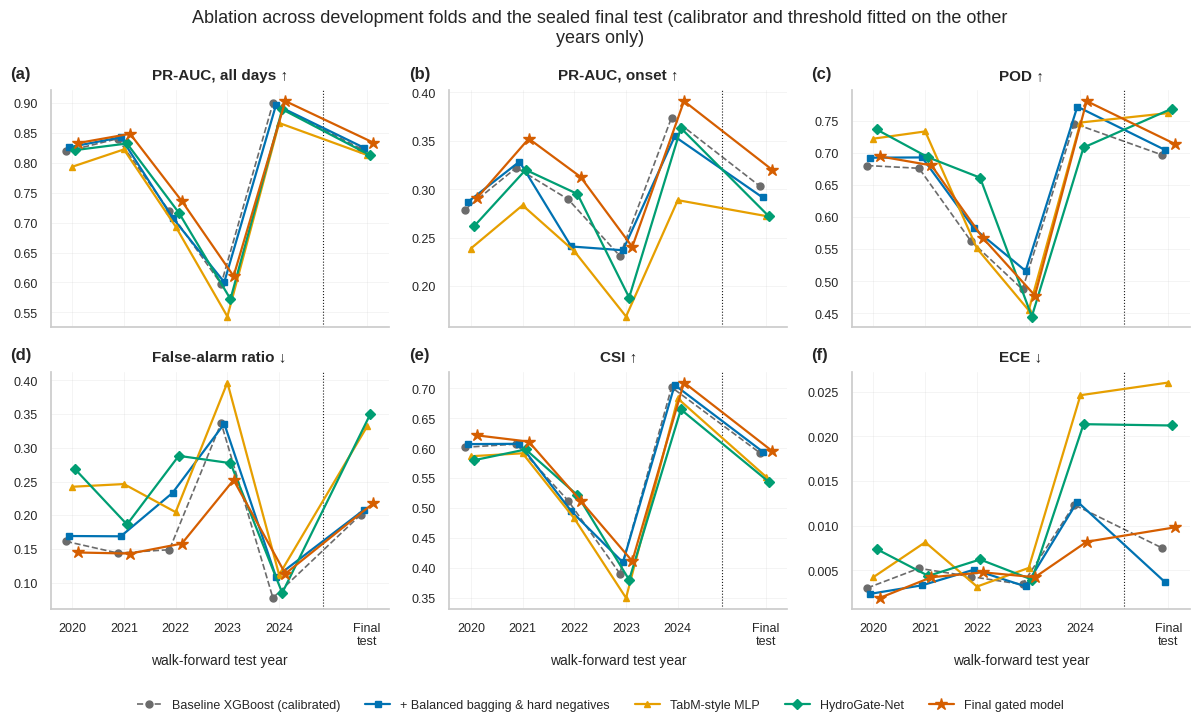

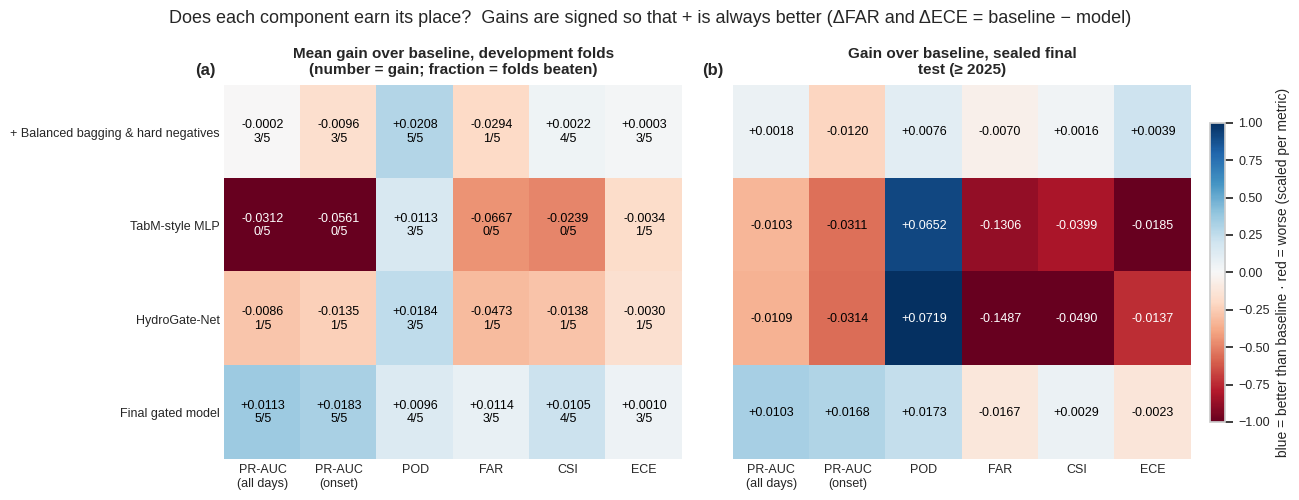

📈 saved: /content/drive/MyDrive/Bangladesh_Flood_Research/results/eval/F1_ablation_per_fold.png/.pdf · F2_ablation_gain_heatmap.png/.pdf (300 dpi + vector)


In [32]:
# @title 10h · PUBLICATION FIGURES FOR THE ABLATION — (a) per-fold trajectories of PR-AUC · onset PR-AUC · POD · FAR · CSI · ECE for the five compared models  (b) gain heat-map: mean development gain, folds beaten, and sealed-final-test gain
_ids = [r for r in ABL_ROWS]; _lab = {"1": "Baseline XGBoost (calibrated)", "2": "+ Balanced bagging & hard negatives", "3": "TabM-style MLP", "4": "HydroGate-Net", "5": "Final gated model"}
_col = {"1": "#6b6b6b", "2": "#0072B2", "3": "#E69F00", "4": "#009E73", "5": "#D55E00"}; _mk = {"1": "o", "2": "s", "3": "^", "4": "D", "5": "*"}
LABEL = {r: _lab[r.split(" ")[0]] for r in _ids}; COLOR = {r: _col[r.split(" ")[0]] for r in _ids}; MARK = {r: _mk[r.split(" ")[0]] for r in _ids}
_titles = {"PR_AUC": "PR-AUC, all days ↑", "PR_AUC_onset": "PR-AUC, onset ↑", "POD": "POD ↑", "FAR": "False-alarm ratio ↓", "CSI": "CSI ↑", "ECE": "ECE ↓"}
_short_m = {"PR_AUC": "PR-AUC\n(all days)", "PR_AUC_onset": "PR-AUC\n(onset)", "POD": "POD", "FAR": "FAR", "CSI": "CSI", "ECE": "ECE"}
_xl = [f"{f}" for f in ABL_FOLDS] + ["Final\ntest"]; _xp = list(range(len(ABL_FOLDS))) + [len(ABL_FOLDS) + 0.7]
fig, axs = plt.subplots(2, 3, figsize=(12, 7.2), sharex=True)
for a, (mt, pl) in zip(axs.ravel(), zip(ABL_METRICS, "abcdef")):
    W = ABL_LONG.pivot(index="model", columns="split", values=mt).reindex(columns=[f"fold {f}" for f in ABL_FOLDS] + ["FINAL TEST (≥ 2025)"])
    for j, r in enumerate(_ids):
        off = (j - (len(_ids) - 1) / 2) * 0.06; a.plot(np.array(_xp) + off, W.loc[r].values, color=COLOR[r], marker=MARK[r], ms=9 if MARK[r] == "*" else 5, lw=1.6 if r != ABL_BASE else 1.2, ls="-" if r != ABL_BASE else "--", label=LABEL[r], zorder=3 if r != ABL_BASE else 2)
    a.axvline(len(ABL_FOLDS) - 0.15, color="k", lw=.8, ls=":"); a.set_title(_titles[mt]); a.text(-0.12, 1.04, f"({pl})", transform=a.transAxes, fontsize=12, fontweight="bold", va="bottom"); a.set_xticks(_xp); a.set_xticklabels(_xl)
    if a in axs[1]: a.set_xlabel("walk-forward test year")
fig.legend(*axs[0, 0].get_legend_handles_labels(), loc="outside lower center", ncol=5, fontsize=9); fig.suptitle("Ablation across development folds and the sealed final test (calibrator and threshold fitted on the other years only)")
plt.savefig(f"{EV}/F1_ablation_per_fold.png"); plt.show(); plt.close("all")
# ---- (b) gain heat-map ----
_names = [r for r in _ids if r != ABL_BASE]; G = pd.DataFrame({m: [ABL_TABLES[m].loc[r, "Δ dev mean (+ = better)"] for r in _names] for m in ABL_METRICS}, index=_names); GT = pd.DataFrame({m: [ABL_TABLES[m].loc[r, "Δ final test (+ = better)"] for r in _names] for m in ABL_METRICS}, index=_names)
K = pd.DataFrame({m: [ABL_TABLES[m].loc[r, "folds better than base"] for r in _names] for m in ABL_METRICS}, index=_names)
fig, axs = plt.subplots(1, 2, figsize=(13, 3.6 + 0.35 * len(_names)), sharey=True)
for a, D, ttl, pl in ((axs[0], G, "Mean gain over baseline, development folds\n(number = gain; fraction = folds beaten)", "a"), (axs[1], GT, "Gain over baseline, sealed final test (≥ 2025)", "b")):
    Z = D.values / (np.nanmax(np.abs(np.vstack([G.values, GT.values])), axis=0) + 1e-12); im = a.imshow(Z, cmap="RdBu", vmin=-1, vmax=1, aspect="auto"); a.grid(False)
    for i in range(D.shape[0]):
        for j, m in enumerate(D.columns): a.text(j, i, f"{D.iloc[i, j]:+.4f}" + (f"\n{K.iloc[i, j]}" if D is G else ""), ha="center", va="center", fontsize=9, color="white" if abs(Z[i, j]) > 0.6 else "black")
    a.set_xticks(range(len(D.columns))); a.set_xticklabels([_short_m[m] for m in D.columns], fontsize=9, rotation=0); a.set_title(ttl); a.text(-0.02, 1.02, f"({pl})", transform=a.transAxes, fontsize=12, fontweight="bold", va="bottom", ha="right")
    a.set_yticks(range(len(_names))); a.set_yticklabels([LABEL[r] for r in _names]); a.tick_params(length=0)
    for s in a.spines.values(): s.set_visible(False)
fig.colorbar(im, ax=axs, shrink=0.8, pad=0.02, label="blue = better than baseline · red = worse (scaled per metric)"); fig.suptitle("Does each component earn its place?  Gains are signed so that + is always better (ΔFAR and ΔECE = baseline − model)")
plt.savefig(f"{EV}/F2_ablation_gain_heatmap.png"); plt.show(); plt.close("all"); print(f"📈 saved: {EV}/F1_ablation_per_fold.png/.pdf · F2_ablation_gain_heatmap.png/.pdf (300 dpi + vector)")


In [33]:
# @title 10f · OPTIONAL GROUND-TRUTH CHECK against real gauge records (BWDB / FFWC water levels) — drop a CSV, re-run this cell
GAUGE_CSV = f"{BASE}/gauges/gauge_levels.csv"; os.makedirs(os.path.dirname(GAUGE_CSV), exist_ok=True)
if not os.path.exists(GAUGE_CSV):
    print(f"ℹ️ no gauge file yet. To validate against REAL observations create {GAUGE_CSV} with columns: station, lat, lon, date (YYYY-MM-DD), level_m, danger_level_m\n"
          "   (daily maximum water level and the station's official danger level). Each station is matched to its nearest model node; 'observed flood' = level ≥ danger level.")
else:
    G = pd.read_csv(GAUGE_CSV, parse_dates=["date"]); AL_ = pd.concat([DEVM.assign(p=DEVS[TAB_CAL_NAME]), TESTM.assign(p=TESTS[TAB_CAL_NAME])], ignore_index=True); AL_["date"] = pd.to_datetime(AL_.date); th_ = THR[TAB_CAL_NAME]; rows = []
    for st, g in G.groupby("station"):
        la, lo = g.lat.iloc[0], g.lon.iloc[0]; n = NODES.index[int(np.argmin(km_between(la, lo, NODES.lat.values, NODES.lon.values)))]; dkm = float(km_between(la, lo, NODES.at[n, "lat"], NODES.at[n, "lon"]))
        obs = (g.set_index("date").level_m >= g.set_index("date").danger_level_m).astype(float); s = AL_[AL_.node == n].set_index("date").p; ix = obs.index.intersection(s.index)
        if len(ix) < 100: continue
        o = obs.reindex(pd.date_range(ix.min(), ix.max())); ob_next = pd.concat([o.shift(-h) for h in range(1, HORIZON + 1)], axis=1).max(axis=1, skipna=False); pp = s.reindex(ob_next.index); m = ob_next.notna() & pp.notna()
        if m.sum() < 100 or ob_next[m].sum() < 5: continue
        yy, pq = ob_next[m].values.astype(int), pp[m].values; a = pq >= th_[2]; rows.append(dict(station=st, node=n, node_km_away=round(dkm, 1), days=int(m.sum()), observed_flood_days=int(yy.sum()), PR_AUC=aps(yy, pq), ROC_AUC=auc(yy, pq), POD_at_F2=float((a & (yy == 1)).sum() / max(yy.sum(), 1)), FAR_at_F2=float((a & (yy == 0)).sum() / max(a.sum(), 1))))
    GAUGE_VAL = pd.DataFrame(rows).set_index("station") if rows else pd.DataFrame(); print("Model alerts vs OBSERVED danger-level exceedance (next 3 days):"); show(GAUGE_VAL, 3) if len(GAUGE_VAL) else print("no station had enough overlapping days")


ℹ️ no gauge file yet. To validate against REAL observations create /content/drive/MyDrive/Bangladesh_Flood_Research/gauges/gauge_levels.csv with columns: station, lat, lon, date (YYYY-MM-DD), level_m, danger_level_m
   (daily maximum water level and the station's official danger level). Each station is matched to its nearest model node; 'observed flood' = level ≥ danger level.


## 11 · Vision branch data (Stream B)

In [34]:
# @title 11 · VISION BRANCH — Sentinel-1 SAR (VV/VH) + DEM/slope patches per node & 12-day block → memory-mapped float16 .npy on Drive (resumable, per node-year shards)
PATCH_CH = ["VV_dB", "VH_dB", "VV-VH_dB", "DEM_m", "slope_deg"]; NCH = len(PATCH_CH); P_ = PATCH_PX; SHARDS = DIRS["spatial_arrays/shards"]; PDIR = os.path.dirname(SHARDS)
def block_ends(year):
    d = pd.Timestamp(year, *SEASON_START) + pd.Timedelta(days=BLOCK_LEN - 1); last = min(pd.Timestamp(year, *SEASON_END), TODAY - pd.Timedelta(days=2)); out = []
    while d <= last: out.append(d); d += pd.Timedelta(days=BLOCK_LEN)
    return out
def _fit_square(a, n):
    """Nearest-neighbour resample of a 2-D array to n×n (no extra dependency)."""
    ri = (np.arange(n) * a.shape[0] / n).astype(int); ci = (np.arange(n) * a.shape[1] / n).astype(int); return a[np.ix_(ri, ci)]

# ---------- synthetic patches (DRY_RUN only): water fraction follows the node's current wetness + a little routing-delayed signal the tabular features cannot see ------------------
_SYN_TERR = {}
def syn_patch(nid, d_end, rng):
    r = NODES.loc[nid]; q = QN[nid]; thr = max(q.quantile(.95), 1e-3); cur = float((q.loc[d_end - pd.Timedelta(days=BLOCK_LEN - 1):d_end] / thr).mean()); fut = float(q.reindex([d_end + pd.Timedelta(days=2)]).fillna(q.iloc[-1]).iloc[0] / thr)
    mix = 0.7 * cur + 0.3 * fut; fw = 0.03 + 0.55 * float(np.clip((mix - 0.3) / 1.0, 0, 1))
    if nid not in _SYN_TERR: tr = np.kron(np.random.default_rng(abs(hash(nid)) % 2**31).normal(0, 1, (4, 4)), np.ones((8, 8)))[:P_, :P_]; _SYN_TERR[nid] = tr
    terr = _SYN_TERR[nid]; field = np.kron(rng.normal(0, 1, (8, 8)), np.ones((4, 4)))[:P_, :P_] - 0.6 * terr; water = field > np.quantile(field, 1 - fw)
    vh = np.where(water, -22.0, -14.0) + rng.normal(0, 1.6, (P_, P_)); vv = vh + 6 + rng.normal(0, 1.0, (P_, P_)); dem = r.elev_m + 0.5 * max(r.relief_m, 1) * terr; sl = np.hypot(*np.gradient(dem))
    return np.stack([vv, vh, vv - vh, dem, sl]).astype(np.float32), float(np.clip(rng.normal(.93, .1), 0, 1))

# ---------- real patches via Google Earth Engine --------------------------------------------------------------------------------------------------------------------------------
_DEM_CACHE = {}
def ee_patch(nid, d_end):
    import ee
    r = NODES.loc[nid]; half = P_ * PATCH_SCALE_M / 2000.0; dlat = half / 110.57; dlon = half / (111.32 * np.cos(np.radians(r.lat))); region = ee.Geometry.Rectangle([r.lon - dlon, r.lat - dlat, r.lon + dlon, r.lat + dlat])
    s, e = (d_end - pd.Timedelta(days=BLOCK_LEN - 1)).strftime("%Y-%m-%d"), (d_end + pd.Timedelta(days=1)).strftime("%Y-%m-%d"); proj = "EPSG:32646"
    if nid not in _DEM_CACHE:
        dem = ee.Image("USGS/SRTMGL1_003").select("elevation"); st = dem.addBands(ee.Terrain.slope(dem)).setDefaultProjection(dem.projection()).reduceResolution(ee.Reducer.mean(), True, 1024).reproject(proj, None, PATCH_SCALE_M)
        dd = st.sampleRectangle(region=region, defaultValue=0).getInfo()["properties"]; _DEM_CACHE[nid] = [_fit_square(np.array(dd[b], np.float32), P_) for b in ("elevation", "slope")]
    col = (ee.ImageCollection("COPERNICUS/S1_GRD").filterBounds(region).filterDate(s, e).filter(ee.Filter.eq("instrumentMode", "IW"))
           .filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VV")).filter(ee.Filter.listContains("transmitterReceiverPolarisation", "VH")))
    fill = np.full((P_, P_), np.nan, np.float32)
    if col.size().getInfo() == 0: vv = vh = fill; valid = 0.0
    else:
        img = col.select(["VV", "VH"]).median().setDefaultProjection(col.first().select("VV").projection()).reduceResolution(ee.Reducer.mean(), True, 1024).reproject(proj, None, PATCH_SCALE_M)
        d = img.sampleRectangle(region=region, defaultValue=-9999).getInfo()["properties"]; vv, vh = (_fit_square(np.array(d[b], np.float32), P_) for b in ("VV", "VH"))
        bad = (vv < -60) | (vh < -60) | ~np.isfinite(vv) | ~np.isfinite(vh); valid = float(1 - bad.mean()); vv = np.where(bad, np.nan, vv); vh = np.where(bad, np.nan, vh)
    arr = np.stack([vv, vh, vv - vh, _DEM_CACHE[nid][0], _DEM_CACHE[nid][1]]); return arr, valid

def make_shard(nid, year):
    """One node-year → shard of shape (blocks, 5, P, P) float16 with missing SAR pixels filled by physical background values + a valid-fraction vector."""
    p = f"{SHARDS}/{nid}_{year}.npy"
    if os.path.exists(p) and os.path.exists(p.replace(".npy", "_valid.npy")): return p
    ends = block_ends(year)
    if not ends: return None
    rng = np.random.default_rng(zlib.crc32(f"{nid}{year}".encode()) % 2**32); arr = np.zeros((len(ends), NCH, P_, P_), np.float16); val = np.zeros(len(ends), np.float32)
    for i, d in enumerate(ends):
        a, v = syn_patch(nid, d, rng) if DRY_RUN else ee_patch(nid, d)
        for c, fv in enumerate(PATCH_FILL): a[c] = np.where(np.isfinite(a[c]), a[c], fv)
        arr[i] = a.astype(np.float16); val[i] = v
    np.save(p.replace(".npy", "_valid.npy"), val); np.save(p, arr); return p

USE_VISION = bool(USE_SAR and (DRY_RUN or EE_READY))
if USE_VISION and not DRY_RUN:      # preflight: ONE real patch. If Earth Engine fails, say why and run tabular-only instead of crashing every later cell (PIDX / PATCH_MM)
    try:
        _y = next(y for y in SAR_YEARS[::-1] if block_ends(y)); _p = ee_patch(NODE_IDS[0], block_ends(_y)[0]); print(f"✅ Earth Engine preflight OK (patch {_p[0].shape}, valid {_p[1]:.0%})")
    except Exception as err:
        USE_VISION = False; print(f"⛔ Earth Engine preflight FAILED → vision branch disabled, tabular branch continues.\n   {type(err).__name__}: {str(err)[:300]}")
if USE_VISION:
    jobs = [(n, y) for n in NODE_IDS for y in SAR_YEARS if block_ends(y)]; todo = [j for j in jobs if not os.path.exists(f"{SHARDS}/{j[0]}_{j[1]}_valid.npy")]; t0 = time.time()
    print(f"{len(jobs)} node-year shards ({len(todo)} to fetch) | patch {P_}×{P_} px @ {PATCH_SCALE_M} m ≈ {P_*PATCH_SCALE_M/1000:.1f} km | {NCH} channels {PATCH_CH}")
    if todo and not DRY_RUN:
        t1 = time.time(); ee_patch(*(todo[0][0], block_ends(todo[0][1])[0])); dtp = time.time() - t1; nb = sum(len(block_ends(y)) for _, y in todo)
        print(f"⏱ one patch took {dtp:.1f}s → ≈ {nb*dtp/EE_WORKERS/3600:.1f} h for {nb:,} patches with {EE_WORKERS} workers (cached on Drive after every node-year; safe to interrupt & re-run)")
    if DRY_RUN:
        for i, (n, y) in enumerate(todo): make_shard(n, y)
    else:
        with ThreadPoolExecutor(EE_WORKERS) as ex:
            for i, f in enumerate(as_completed([ex.submit(make_shard, n, y) for n, y in todo])):
                try: f.result()
                except Exception as err: print("shard failed:", str(err)[:100])
                if (i + 1) % 20 == 0: print(f"  … {i+1}/{len(todo)} node-year shards ({time.time()-t0:.0f}s)")
    # ---- consolidate into ONE memory-mapped array + index (Colab only ever touches the rows it needs) ----
    rows = []; recs = []
    for n, y in jobs:
        p = f"{SHARDS}/{n}_{y}.npy"
        if os.path.exists(p): recs.append((n, y, p))
    M = sum(len(block_ends(y)) for _, y, _ in recs); MM_PATH = f"{PDIR}/patches_{P_}px_f16.npy"; mm = np.lib.format.open_memmap(MM_PATH, mode="w+", dtype=np.float16, shape=(M, NCH, P_, P_)); k = 0
    for n, y, p in recs:
        a = np.load(p); v = np.load(p.replace(".npy", "_valid.npy")); mm[k:k + len(a)] = a; ends = block_ends(y)
        rows += [dict(node=n, date=d, year=y, valid=float(v[i]), row=k + i) for i, d in enumerate(ends)]; k += len(a)
    mm.flush(); del mm; PIDX = pd.DataFrame(rows); PIDX.to_parquet(f"{DIRS['processed_data']}/patch_index.parquet", compression="zstd"); PATCH_MM = np.load(MM_PATH, mmap_mode="r")
    print(f"✅ {len(PIDX):,} patches · memory-mapped {os.path.getsize(MM_PATH)/1e6:.0f} MB on disk (RAM use ≈ 0) | valid ≥ {MIN_VALID:.0%}: {(PIDX.valid >= MIN_VALID).mean():.1%} | years {PIDX.year.min()}–{PIDX.year.max()}")
else:
    PIDX = None; PATCH_MM = None; print("Vision branch disabled (USE_SAR=False or Earth Engine unavailable) → tabular branch only.")
ram("after patches")


✅ Earth Engine preflight OK (patch (5, 32, 32), valid 100%)
700 node-year shards (0 to fetch) | patch 32×32 px @ 300 m ≈ 9.6 km | 5 channels ['VV_dB', 'VH_dB', 'VV-VH_dB', 'DEM_m', 'slope_deg']
✅ 14,630 patches · memory-mapped 150 MB on disk (RAM use ≈ 0) | valid ≥ 60%: 99.8% | years 2017–2026
🧠 RAM 1.95 GB used of 13.6 GB  after patches


## 12 · Vision branch — a small, plain supervised U-Net (water segmentation → verification + gated correction)

In [35]:
# @title 12 · VISION BRANCH — a small, plain SUPERVISED U-Net on the SAR+DEM patches: terrain-aware, speckle-robust water segmentation → used for VERIFICATION and (only if it passes the gate) a light correction — no ResNet, no foundation model, no heavy fusion
UN_OK, UN_NOTE, UNET_FEATS = False, "U-Net disabled / no patches", ["u_wf", "u_wf_c", "u_wf_low", "u_blob", "u_conf"]
if USE_VISION and USE_UNET and importlib.util.find_spec("torch") is not None and PATCH_MM is not None:
    import torch, torch.nn as tnn, torch.nn.functional as TFn
    from scipy import ndimage as ndi
    if "TDEV" not in globals(): TDEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    def _miss(a): return (a[:, 0] == PATCH_FILL[0]) & (a[:, 1] == PATCH_FILL[1])
    def un_label(a):
        """Rule-based water mask of the CLEAN patch: dark in VV/VH, flat, not high ground; 3×3 majority filter. (No pixel-level ground truth exists offline → weak supervision; swap in Copernicus-GFM masks here when available.)"""
        vv, vh, dem, sl = a[:, 0], a[:, 1], a[:, 3], a[:, 4]; ok = ~_miss(a); demr = dem - np.median(dem.reshape(len(a), -1), axis=1)[:, None, None]
        w = ((vh < SAR_VH_WATER) | (vv < SAR_VV_WATER)) & ok & (sl < UNET_SLOPE_MAX) & (demr < 12); return (ndi.uniform_filter(w.astype(np.float32), size=(1, 3, 3)) >= .5).astype(np.float32) * ok, ok
    def un_prep(a):
        vv, vh, ra, dem, sl = a[:, 0], a[:, 1], a[:, 2], a[:, 3], a[:, 4]; ok = ~_miss(a); demr = dem - np.median(dem.reshape(len(a), -1), axis=1)[:, None, None]
        X = np.stack([(vv + 12) / 5 * ok, (vh + 19) / 5 * ok, (ra - 7) / 4 * ok, np.clip(demr, -30, 30) / 10, np.clip(sl, 0, 30) / 6, ok.astype(np.float32)], 1); return np.nan_to_num(X).astype(np.float32)
    def un_corrupt(a, rng):
        """Training/validation corruption: extra speckle + random missing pixels. The target stays the CLEAN mask, so the network must denoise and in-fill using terrain and context."""
        b = a.copy(); n = rng.normal(0, UNET_NOISE_DB, (len(a), 2, a.shape[2], a.shape[3])).astype(np.float32); b[:, 0] += n[:, 0]; b[:, 1] += n[:, 1]; b[:, 2] = b[:, 0] - b[:, 1]
        drop = rng.random((len(a), a.shape[2], a.shape[3])) < rng.uniform(0, .2, (len(a), 1, 1))
        for c, fv in enumerate(PATCH_FILL): b[:, c] = np.where(drop, fv, b[:, c])
        return b
    class UNetS(tnn.Module):
        def __init__(s, cin=6, b=16):
            super().__init__()
            def blk(i, o): return tnn.Sequential(tnn.Conv2d(i, o, 3, padding=1, bias=False), tnn.BatchNorm2d(o), tnn.ReLU(inplace=True), tnn.Conv2d(o, o, 3, padding=1, bias=False), tnn.BatchNorm2d(o), tnn.ReLU(inplace=True))
            s.e1, s.e2, s.e3, s.pool = blk(cin, b), blk(b, 2 * b), blk(2 * b, 4 * b), tnn.MaxPool2d(2); s.u2, s.d2, s.u1, s.d1, s.out = tnn.ConvTranspose2d(4 * b, 2 * b, 2, 2), blk(4 * b, 2 * b), tnn.ConvTranspose2d(2 * b, b, 2, 2), blk(2 * b, b), tnn.Conv2d(b, 1, 1)
        def forward(s, x): e1 = s.e1(x); e2 = s.e2(s.pool(e1)); e3 = s.e3(s.pool(e2)); d2 = s.d2(torch.cat([s.u2(e3), e2], 1)); d1 = s.d1(torch.cat([s.u1(d2), e1], 1)); return s.out(d1).squeeze(1)
    UPX = PIDX[PIDX.valid >= MIN_VALID].copy(); UPX["date"] = pd.to_datetime(UPX.date); tr_rows = UPX.row.values[(UPX.year < FINAL_TEST_FROM).values]; yrs_u = UPX.year.values[(UPX.year < FINAL_TEST_FROM).values]; vy = yrs_u.max()
    A_tr, A_va = np.asarray(PATCH_MM[np.sort(tr_rows[yrs_u < vy])], np.float32), np.asarray(PATCH_MM[np.sort(tr_rows[yrs_u == vy])], np.float32); rng_u = np.random.default_rng(SEED)
    unet = UNetS(6, UNET_BASE).to(TDEV); opt = torch.optim.AdamW(unet.parameters(), lr=2e-3, weight_decay=1e-4); sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, UNET_EPOCHS)
    L_va, _ = un_label(A_va); Vn = un_corrupt(A_va, np.random.default_rng(1)); Vx = torch.as_tensor(un_prep(Vn), device=TDEV)
    def un_iou(pred, lab, ok): i = ((pred > .5) & (lab > .5) & ok).sum(); u = (((pred > .5) | (lab > .5)) & ok).sum(); return float(i / max(u, 1))
    def un_predict(a, bs=512):
        unet.eval(); out = []
        with torch.no_grad():
            for i in range(0, len(a), bs): out.append(torch.sigmoid(unet(torch.as_tensor(un_prep(a[i:i + bs]), device=TDEV))).cpu().numpy())
        return np.concatenate(out)
    t0 = time.time(); print(f"U-Net: train {len(A_tr):,} patches (≤ {vy - 1}) · validation {len(A_va):,} patches ({vy}) · {sum(p.numel() for p in unet.parameters())/1e3:.0f} k parameters · {TDEV}")
    L_tr, _ = un_label(A_tr)
    for ep in range(UNET_EPOCHS):
        unet.train(); perm = rng_u.permutation(len(A_tr)); tl = 0
        for i in range(0, len(perm), 128):
            b = perm[i:i + 128]; x = torch.as_tensor(un_prep(un_corrupt(A_tr[b], rng_u)), device=TDEV); y_ = torch.as_tensor(L_tr[b], device=TDEV); lg = unet(x); pr = torch.sigmoid(lg)
            dice = 1 - (2 * (pr * y_).sum() + 1) / (pr.sum() + y_.sum() + 1); loss = TFn.binary_cross_entropy_with_logits(lg, y_) + dice; opt.zero_grad(); loss.backward(); opt.step(); tl += float(loss) * len(b)
        sched.step()
        if ep % max(1, UNET_EPOCHS // 5) == 0 or ep == UNET_EPOCHS - 1: print(f"  epoch {ep+1:02d}/{UNET_EPOCHS}  train-loss {tl/len(perm):.4f}  ({time.time()-t0:.0f}s)")
    pv = un_predict(Vn); okv = ~_miss(A_va); naive, _ = un_label(Vn); okn = ~_miss(Vn)       # naive = the plain threshold rule applied to the SAME corrupted patch
    iou_naive, iou_unet = un_iou(naive, L_va, okv), un_iou(pv, L_va, okv); iou_clean = un_iou(un_predict(A_va), L_va, okv)
    UN_TABLE = pd.DataFrame({"water IoU vs clean mask": {"plain threshold on corrupted patch": iou_naive, "U-Net on corrupted patch": iou_unet, "U-Net on clean patch": iou_clean}}); show(UN_TABLE, 4); UN_TABLE.round(4).to_csv(f"{EV}/F_unet_validation.csv")
    torch.save(unet.state_dict(), f"{MD}/national_unet.pt"); UN_OK = True
    UN_NOTE = f"U-Net (validation year {vy}): water IoU {iou_unet:.3f} vs {iou_naive:.3f} for the plain threshold on speckle-corrupted / gappy patches"; print("→", UN_NOTE); del A_tr, L_tr; gc.collect()
    def unet_feats(a):
        """(b,5,P,P) raw patches → (b, 5) U-Net water descriptors: mean probability, centre, low-ground, largest water blob, mean confidence."""
        out = []
        for i in range(0, len(a), 1024):
            x = np.asarray(a[i:i + 1024], np.float32); p = un_predict(x); ok = ~_miss(x); n_ok = np.maximum(ok.sum((1, 2)), 1); q = slice(x.shape[2] // 4, 3 * x.shape[2] // 4)
            low = x[:, 3] <= np.median(x[:, 3].reshape(len(x), -1), axis=1)[:, None, None]; wf = (p * ok).sum((1, 2)) / n_ok; wc = (p[:, q, q] * ok[:, q, q]).sum((1, 2)) / np.maximum(ok[:, q, q].sum((1, 2)), 1)
            wl = (p * (ok & low)).sum((1, 2)) / np.maximum((ok & low).sum((1, 2)), 1); blob = np.array([(np.bincount(ndi.label(m)[0].ravel())[1:].max() if m.any() else 0) / m.size for m in (p > .5) & ok]); conf = (np.abs(p - .5) * 2 * ok).sum((1, 2)) / n_ok
            out.append(np.column_stack([wf, wc, wl, blob, conf]))
        return np.vstack(out).astype(np.float32)
else: print("U-Net skipped (vision data unavailable, USE_UNET=False or PyTorch missing) → tabular + (optional) threshold-feature corrector only.")


U-Net: train 10,270 patches (≤ 2023) · validation 1,470 patches (2024) · 118 k parameters · cpu
  epoch 01/25  train-loss 0.7354  (58s)
  epoch 06/25  train-loss 0.1421  (341s)
  epoch 11/25  train-loss 0.1148  (627s)
  epoch 16/25  train-loss 0.1040  (913s)
  epoch 21/25  train-loss 0.0948  (1199s)
  epoch 25/25  train-loss 0.0939  (1427s)


,water IoU vs clean mask
plain threshold on corrupted patch,0.7675
U-Net on corrupted patch,0.9079
U-Net on clean patch,0.9259


→ U-Net (validation year 2024): water IoU 0.908 vs 0.768 for the plain threshold on speckle-corrupted / gappy patches


## 14b · SAR residual corrector (the real meta-learner) · 14c · Deployment refit

In [36]:
# @title 14b · SAR RESIDUAL CORRECTOR — the meta-learner: logit(p_tab) is an OFFSET; interpretable SAR water features add a small, bounded, out-of-time-validated correction (α = 0 = off)
SAR_ACTIVE, SAR_CORR, SAR_NOTE = False, None, "SAR vision branch unavailable"
SAR_FEATS = ["wf", "wf_c", "wf_low", "vv", "vh", "vh_sd", "vfrac", "dwf", "wf_anom"]
def sar_arr_feats(a):
    """a: (b, 5, P, P) patches [VV, VH, VV−VH, DEM, slope] → (b, 7). Missing pixels carry the exact PATCH_FILL values → masked out (they are NOT water)."""
    vv, vh, dem = a[:, 0], a[:, 1], a[:, 3]; miss = (vv == PATCH_FILL[0]) & (vh == PATCH_FILL[1]); ok = ~miss; wat = ((vh < SAR_VH_WATER) | (vv < SAR_VV_WATER)) & ok; n_ok = np.maximum(ok.sum((1, 2)), 1); q = slice(a.shape[2] // 4, 3 * a.shape[2] // 4)
    low = dem <= np.median(dem.reshape(len(a), -1), axis=1)[:, None, None]; vvm = np.where(ok, vv, np.nan); vhm = np.where(ok, vh, np.nan)
    import warnings
    with np.errstate(all="ignore"), warnings.catch_warnings():
        warnings.simplefilter("ignore"); feats = np.column_stack([wat.sum((1, 2)) / n_ok, wat[:, q, q].sum((1, 2)) / np.maximum(ok[:, q, q].sum((1, 2)), 1), (wat & low).sum((1, 2)) / np.maximum((ok & low).sum((1, 2)), 1), np.nanmean(vvm, (1, 2)), np.nanmean(vhm, (1, 2)), np.nanstd(vhm, (1, 2)), ok.mean((1, 2))])
    return feats.astype(np.float32)
if USE_VISION:
    PXs = PIDX[PIDX.valid >= MIN_VALID][["node", "date", "row"]].copy(); PXs["date"] = pd.to_datetime(PXs.date); PXs = PXs.sort_values(["node", "date"]).reset_index(drop=True)
    F7 = np.vstack([sar_arr_feats(np.asarray(PATCH_MM[PXs.row.values[i:i + 2048]], np.float32)) for i in range(0, len(PXs), 2048)])
    for j, c in enumerate(SAR_FEATS[:7]): PXs[c] = F7[:, j]
    gg = PXs.groupby("node"); PXs["gap"] = gg.date.diff().dt.days; PXs["dwf"] = gg.wf.diff(); PXs.loc[PXs.gap > 2 * BLOCK_LEN, "dwf"] = np.nan                    # change vs the previous 12-day block
    PXs["wf_anom"] = PXs.wf - gg.wf.transform(lambda s: s.shift(1).expanding(min_periods=3).median())                                                                  # vs the node's OWN causal history (no future data)
    NODE_WF_MED = PXs.groupby("node").wf.median().to_dict()
    D_ = pd.concat([DEVM.assign(p0=CAL_TAB(DEVS[TAB_NAME]), split="dev"), TESTM.assign(p0=TESTS[TAB_CAL_NAME], split="test")], ignore_index=True); D_["date"] = pd.to_datetime(D_.date); D_["year"] = D_.date.dt.year
    SRT = D_.merge(PXs[["node", "date"] + SAR_FEATS], on=["node", "date"], how="inner").reset_index(drop=True); ySR, onSR = SRT.y.values.astype(int), SRT.on.values.astype(bool); lt = logit(SRT.p0.values); XSR = SRT[SAR_FEATS].to_numpy(np.float32)
    dev_i, te_i = np.where(SRT.split == "dev")[0], np.where(SRT.split == "test")[0]; yrs = sorted(set(SRT.year.values[dev_i].astype(int)))
    print(f"SAR rows with an out-of-fold tabular probability: dev {len(dev_i):,} ({int(ySR[dev_i].sum())} floods) · final test {len(te_i):,} ({int(ySR[te_i].sum())} floods)  [v5.8 meta-learner had only 42 training floods]")
    def fit_corr(idx, nt): return xgb.XGBClassifier(n_estimators=nt, max_depth=2, learning_rate=.05, subsample=.8, colsample_bytree=.8, min_child_weight=CORR_MCW, reg_lambda=10, tree_method="hist", device="cpu", random_state=SEED, n_jobs=-1).fit(XSR[idx], ySR[idx], base_margin=lt[idx])
    def delta_of(m, idx): return m.predict(XSR[idx], output_margin=True, base_margin=lt[idx]) - lt[idx]
    OOF = {nt: np.full(len(SRT), np.nan) for nt in CORR_TREES}
    for Y in yrs[1:]:                                                                                                    # EXPANDING WINDOW: train on years < Y (− embargo), predict Y
        tr_ = dev_i[(SRT.year.values[dev_i] < Y) & (SRT.date.values[dev_i] <= np.datetime64(f"{Y - 1}-12-31") - np.timedelta64(EMBARGO, "D"))]; va_ = dev_i[SRT.year.values[dev_i] == Y]
        if len(va_) == 0 or ySR[tr_].sum() < 15 or (1 - ySR[tr_]).sum() < 15: continue
        for nt in CORR_TREES: OOF[nt][va_] = delta_of(fit_corr(tr_, nt), va_)
    ev_i = dev_i[np.isfinite(OOF[CORR_TREES[0]][dev_i])]
    if len(ev_i) < 300 or ySR[ev_i].sum() < 20: SAR_NOTE = f"too few out-of-time SAR rows to validate a corrector ({len(ev_i)} rows, {int(ySR[ev_i].sum()) if len(ev_i) else 0} floods) → tabular only"; print("⚠️", SAR_NOTE)
    else:
        sc_ = lambda ii, p: val_score(ySR[ii], p, onSR[ii]); base_sc = sc_(ev_i, sig(lt[ev_i])); grid = {(nt, a): sc_(ev_i, sig(lt[ev_i] + a * OOF[nt][ev_i])) for nt in CORR_TREES for a in CORR_ALPHAS}
        (BNT, BAL), best_sc = max(grid.items(), key=lambda kv: kv[1]); ey = SRT.year.values[ev_i]; yw = [aps(ySR[ev_i][ey == Y], sig(lt[ev_i] + BAL * OOF[BNT][ev_i])[ey == Y]) > aps(ySR[ev_i][ey == Y], sig(lt[ev_i])[ey == Y]) for Y in sorted(set(ey))]
        SAR_ACTIVE = bool(BAL > 0 and best_sc - base_sc >= CORR_MARGIN and np.mean(yw) >= 0.6); SAR_NOTE = f"corrector {'ACTIVE' if SAR_ACTIVE else 'OFF (did not clear the out-of-time bar)'}: α={BAL}, trees={BNT}, out-of-time score {base_sc:.4f} → {best_sc:.4f} (Δ {best_sc - base_sc:+.4f}, margin {CORR_MARGIN}), better in {int(sum(yw))}/{len(yw)} years"
        print("expanding-window grid (score = onset-weighted: 70 % onset PR-AUC + 30 % overall; α=0 is the tabular model):"); show(pd.Series(grid).unstack(), 4); print("→", SAR_NOTE)
        m_fin = fit_corr(dev_i, BNT); dl_te = delta_of(m_fin, te_i); alpha = BAL if SAR_ACTIVE else 0.0; p_tab_te = sig(lt[te_i]); p_cor_te = sig(lt[te_i] + BAL * dl_te)
        ev_p = sig(lt[ev_i] + BAL * OOF[BNT][ev_i]); NAME_T, NAME_C = "Tabular only (calibrated) — baseline", f"★ Tabular + SAR correction (α={BAL})"
        MS_ = SRT.iloc[te_i].reset_index(drop=True); SS_ = {NAME_T: p_tab_te, NAME_C: p_cor_te}; THS_ = {NAME_T: thr4(ySR[ev_i], sig(lt[ev_i]), onSR[ev_i]), NAME_C: thr4(ySR[ev_i], ev_p, onSR[ev_i])}
        BSR = bench(SS_, MS_, THS_); BSR.round(4).to_csv(f"{EV}/F_sar_corrector_test.csv"); print(f"\nFINAL TEST on SAR rows ({len(te_i):,} rows, {int(ySR[te_i].sum())} floods) — thresholds from dev out-of-time rows only:"); show(BSR)
        SGS = sig_table(SS_, MS_, "final test (SAR rows)", NAME_C, [NAME_T]); SGS["verdict"] = np.where(SGS.ci_low > 0, "SIGNIFICANTLY better", np.where(SGS.ci_high < 0, "significantly worse", "not significant")); show(SGS, 4)
        print(f"→ (v6 threshold-feature corrector alone would serve: {'tabular + SAR correction' if SAR_ACTIVE else 'tabular only'}; the final SAR decision is taken in 14b2.)")
        imp = pd.Series(m_fin.get_booster().get_score(importance_type="gain")); imp.index = [SAR_FEATS[int(k[1:])] if k.startswith("f") else k for k in imp.index]; print("corrector feature gain:", imp.sort_values(ascending=False).round(2).to_dict())
        SAR_CORR = dict(model=m_fin, alpha=float(alpha), trees=int(BNT), feats=SAR_FEATS, node_wf_med=NODE_WF_MED); joblib.dump(SAR_CORR, f"{MD}/national_sar_corrector.joblib")
    # independent plausibility check: does the (GloFAS-trained) tabular probability agree with SAR-observed surface water?
    from scipy.stats import spearmanr
    wet = SRT.wf_anom if "wf_anom" in SRT else None
    if wet is not None and wet.notna().sum() > 200:
        ok_ = wet.notna().values; thr_w = np.nanquantile(wet.values[dev_i][np.isfinite(wet.values[dev_i])], .9); lab = (wet.values >= thr_w)
        print(f"independent SAR check: Spearman(tabular p, SAR water anomaly) = {spearmanr(SRT.p0.values[ok_], wet.values[ok_])[0]:+.3f} | PR-AUC of p vs 'SAR-wet' (top-decile anomaly, threshold from dev) on final test: {aps(lab[te_i].astype(int), SRT.p0.values[te_i]):.3f} (base rate {lab[te_i].mean():.3f})")
else: print("SAR corrector skipped (no vision data).")

def get_patch(n, d):
    a = syn_patch(n, d, np.random.default_rng(zlib.crc32(f"{n}{d}".encode()) % 2**32))[0] if DRY_RUN else ee_patch(n, d)[0]
    for c, fv in enumerate(PATCH_FILL): a[c] = np.where(np.isfinite(a[c]), a[c], fv)
    return a.astype(np.float32)
def live_sar_correct(P, p, asof):
    """Apply the validated corrector to live probabilities: current + previous 12-day SAR block per node (fetched in parallel)."""
    nodes = list(P.node.values); prev_d = asof - pd.Timedelta(days=BLOCK_LEN)
    with ThreadPoolExecutor(EE_WORKERS) as ex: cur = list(ex.map(lambda n: get_patch(n, asof), nodes)); prv = list(ex.map(lambda n: get_patch(n, prev_d), nodes))
    fc, fp_ = sar_arr_feats(np.stack(cur)), sar_arr_feats(np.stack(prv)); X = np.column_stack([fc, fc[:, 0] - fp_[:, 0], fc[:, 0] - np.array([SAR_CORR["node_wf_med"].get(n, np.nan) for n in nodes])]).astype(np.float32)
    base = logit(p); dl = SAR_CORR["model"].predict(X, output_margin=True, base_margin=base) - base; return sig(base + SAR_CORR["alpha"] * dl)

SAR_SERVE_KIND = "xgb_corrector" if SAR_ACTIVE else "none"            # overwritten by the architecture shoot-out (14e)
def live_sar_apply(P, p, asof): return live_sar_correct(P, p, asof)


SAR rows with an out-of-fold tabular probability: dev 7,342 (400 floods) · final test 2,868 (162 floods)  [v5.8 meta-learner had only 42 training floods]
expanding-window grid (score = onset-weighted: 70 % onset PR-AUC + 30 % overall; α=0 is the tabular model):


,0.00,0.25,0.50,0.75,1.00
40,0.5029,0.5005,0.5003,0.4965,0.4949
80,0.5029,0.5007,0.4971,0.4949,0.4894


→ corrector OFF (did not clear the out-of-time bar): α=0.0, trees=40, out-of-time score 0.5029 → 0.5029 (Δ +0.0000, margin 0.003), better in 0/4 years

FINAL TEST on SAR rows (2,868 rows, 162 floods) — thresholds from dev out-of-time rows only:


,PR_AUC,ROC_AUC,F1,F2,Precision,Recall_POD,FAR,CSI,MCC,PR_AUC_onset,F1_onset,F2_onset,Recall_onset,Brier,MAE,ECE
Model,,,,,,,,,,,,,,,,
Tabular only (calibrated) — baseline,0.874,0.983,0.775,0.809,0.698,0.87,0.302,0.632,0.765,0.393,0.4,0.396,0.667,0.018,0.046,0.019
★ Tabular + SAR correction (α=0.0),0.874,0.983,0.775,0.809,0.698,0.87,0.302,0.632,0.765,0.393,0.4,0.396,0.667,0.018,0.046,0.019


,sample,vs,metric,mean_diff,ci_low,ci_high,verdict
0,final test (SAR rows),Tabular only (calibrated) — baseline,PR_AUC,0.0,0.0,0.0,not significant
1,final test (SAR rows),Tabular only (calibrated) — baseline,PR_AUC_onset,0.0,0.0,0.0,not significant


→ (v6 threshold-feature corrector alone would serve: tabular only; the final SAR decision is taken in 14b2.)
corrector feature gain: {'vh_sd': 2.52, 'vh': 2.28, 'wf_c': 1.96, 'wf_anom': 1.93, 'wf_low': 1.83, 'vv': 1.76, 'dwf': 1.73, 'wf': 1.68}
independent SAR check: Spearman(tabular p, SAR water anomaly) = +0.317 | PR-AUC of p vs 'SAR-wet' (top-decile anomaly, threshold from dev) on final test: 0.146 (base rate 0.078)


### 14b2 · SAR shoot-out (thresholds vs U-Net vs both) + SAR verification

In [37]:
# @title 14b2 · SAR RESIDUAL SHOOT-OUT — which SAR descriptors (plain thresholds · small U-Net · both) add a bounded correction to the tabular logit? Same expanding-window protocol & gate for all (A–C: depth-2 trees on the logit · R1/R2: two interpretable rules with a handful of parameters) · plus SAR VERIFICATION of the forecast
SARV, SERVE_V, SAR_NOTE2, VER_COL, VER_Q, SAR_CORR2 = {}, None, "SAR correction OFF (no usable SAR rows)", None, {}, None
if USE_VISION and "SRT" in globals() and len(SRT) > 500:
    UF_ALL = UNET_FEATS + ["u_d", "u_anom"]; NODE_UWF_MED = {}
    if UN_OK:
        Uf = unet_feats(np.asarray(PATCH_MM[PXs.row.values], np.float32))
        for j, c in enumerate(UNET_FEATS): PXs[c] = Uf[:, j]
        gg_ = PXs.groupby("node"); PXs["u_d"] = gg_.u_wf.diff(); PXs.loc[PXs.gap > 2 * BLOCK_LEN, "u_d"] = np.nan; PXs["u_anom"] = PXs.u_wf - gg_.u_wf.transform(lambda s: s.shift(1).expanding(min_periods=3).median()); NODE_UWF_MED = PXs.groupby("node").u_wf.median().to_dict()
        n0_ = len(SRT); SRT = SRT.merge(PXs[["node", "date"] + UF_ALL], on=["node", "date"], how="left"); assert len(SRT) == n0_ == len(ySR)
    CV_VARIANTS = {"A · threshold SAR features (v6)": SAR_FEATS}
    if UN_OK: CV_VARIANTS["B · U-Net features"] = UF_ALL; CV_VARIANTS["C · threshold + U-Net features"] = SAR_FEATS + UF_ALL
    def cv_eval(cols):
        X_ = SRT[cols].to_numpy(np.float32)
        def fit_(idx, nt): return xgb.XGBClassifier(n_estimators=nt, max_depth=2, learning_rate=.05, subsample=.8, colsample_bytree=.8, min_child_weight=CORR_MCW, reg_lambda=10, tree_method="hist", device="cpu", random_state=SEED, n_jobs=-1).fit(X_[idx], ySR[idx], base_margin=lt[idx])
        def dl_(m, idx): return m.predict(X_[idx], output_margin=True, base_margin=lt[idx]) - lt[idx]
        OOF = {nt: np.full(len(SRT), np.nan) for nt in CORR_TREES}
        for Y in yrs[1:]:
            tr_ = dev_i[(SRT.year.values[dev_i] < Y) & (SRT.date.values[dev_i] <= np.datetime64(f"{Y - 1}-12-31") - np.timedelta64(EMBARGO, "D"))]; va_ = dev_i[SRT.year.values[dev_i] == Y]
            if len(va_) == 0 or ySR[tr_].sum() < 15 or (1 - ySR[tr_]).sum() < 15: continue
            for nt in CORR_TREES: OOF[nt][va_] = dl_(fit_(tr_, nt), va_)
        ev = dev_i[np.isfinite(OOF[CORR_TREES[0]][dev_i])]
        if len(ev) < 300 or ySR[ev].sum() < 20: return None
        sc_ = lambda ii, p: val_score(ySR[ii], p, onSR[ii]); base = sc_(ev, sig(lt[ev])); grid = {(nt, a): sc_(ev, sig(lt[ev] + a * OOF[nt][ev])) for nt in CORR_TREES for a in CORR_ALPHAS}
        (nt, al), best = max(grid.items(), key=lambda kv: kv[1]); ey = SRT.year.values[ev]; yw = [aps(ySR[ev][ey == Y], sig(lt[ev] + al * OOF[nt][ev])[ey == Y]) > aps(ySR[ev][ey == Y], sig(lt[ev])[ey == Y]) for Y in sorted(set(ey))]
        m = fit_(dev_i, nt); dte = dl_(m, te_i); ev_p = sig(lt[ev] + al * OOF[nt][ev])
        return dict(cols=cols, nt=int(nt), alpha=float(al), base=float(base), score=float(best), wins=float(np.mean(yw)), n_years=len(yw), active=bool(al > 0 and best - base >= CORR_MARGIN and np.mean(yw) >= 0.6), model=m, p_te=sig(lt[te_i] + al * dte), thr=thr4(ySR[ev], ev_p, onSR[ev]))
    # ---- interpretable rules (a handful of parameters, fitted on the training years only): "water rising fast and the model is only moderately worried → boost" / "surface water low and falling and the model is calm → damp" ----
    RULE_Q, RULE_LO, RULE_UP, RULE_DN = (0.8, 0.9, 0.95), (0.03, 0.10, 0.25), (0.25, 0.5, 0.75, 1.0), (0.0, -0.25, -0.5)
    def rule_adj(x, p, prm):
        a = np.zeros(len(p)); ok = np.isfinite(x); a[ok & (x >= prm["x_hi"]) & (p >= prm["p_lo"]) & (p < 0.7)] += prm["up"]; a[ok & (x <= prm["x_lo"]) & (p < 0.5)] += prm["dn"]; return a
    def rule_fit(x, lt_, y_, on_):
        p_ = sig(lt_); xv = x[np.isfinite(x)]; best = (val_score(y_, p_, on_), dict(x_hi=np.inf, x_lo=-np.inf, p_lo=1.0, up=0.0, dn=0.0))
        if len(xv) < 200: return best[1]
        x_lo = float(np.quantile(xv, .2))
        for q in RULE_Q:
            xh = float(np.quantile(xv, q))
            for lo in RULE_LO:
                for up in RULE_UP:
                    for dn in RULE_DN:
                        prm = dict(x_hi=xh, x_lo=x_lo, p_lo=lo, up=up, dn=dn); sc_ = val_score(y_, sig(lt_ + rule_adj(x, p_, prm)), on_)
                        if sc_ > best[0] + 1e-4: best = (sc_, prm)
        return best[1]
    def rule_eval(col):
        x = SRT[col].to_numpy(float); adj = np.full(len(SRT), np.nan)
        for Y in yrs[1:]:
            tr_ = dev_i[(SRT.year.values[dev_i] < Y) & (SRT.date.values[dev_i] <= np.datetime64(f"{Y - 1}-12-31") - np.timedelta64(EMBARGO, "D"))]; va_ = dev_i[SRT.year.values[dev_i] == Y]
            if len(va_) == 0 or ySR[tr_].sum() < 15 or (1 - ySR[tr_]).sum() < 15: continue
            adj[va_] = rule_adj(x[va_], sig(lt[va_]), rule_fit(x[tr_], lt[tr_], ySR[tr_], onSR[tr_]))
        ev = dev_i[np.isfinite(adj[dev_i])]
        if len(ev) < 300 or ySR[ev].sum() < 20: return None
        sc_ = lambda ii, p: val_score(ySR[ii], p, onSR[ii]); base = sc_(ev, sig(lt[ev])); best = sc_(ev, sig(lt[ev] + adj[ev])); ey = SRT.year.values[ev]
        yw = [aps(ySR[ev][ey == Y], sig(lt[ev] + adj[ev])[ey == Y]) > aps(ySR[ev][ey == Y], sig(lt[ev])[ey == Y]) for Y in sorted(set(ey))]; prm = rule_fit(x[dev_i], lt[dev_i], ySR[dev_i], onSR[dev_i])
        return dict(cols=[col], nt=0, alpha=1.0, base=float(base), score=float(best), wins=float(np.mean(yw)), n_years=len(yw), active=bool(best - base >= CORR_MARGIN and np.mean(yw) >= 0.6), model=None, p_te=sig(lt[te_i] + rule_adj(x[te_i], sig(lt[te_i]), prm)), thr=thr4(ySR[ev], sig(lt[ev] + adj[ev]), onSR[ev]), kind="rule", params=prm)
    CVR = {k: cv_eval(c) for k, c in CV_VARIANTS.items()}; CVR = {k: v for k, v in CVR.items() if v}
    for v in CVR.values(): v["kind"] = "xgb"
    for k, col in [("R1 · rule on plain-threshold water rise (dwf)", "dwf")] + ([("R2 · rule on U-Net water rise (u_d)", "u_d")] if UN_OK else []):
        r_ = rule_eval(col)
        if r_: CVR[k] = r_
    if not CVR: SAR_NOTE2 = "too few out-of-time SAR rows to validate any corrector → tabular only"; print("⚠️", SAR_NOTE2)
    else:
        rows_ = [dict(variant=k, features=len(v["cols"]), dev_score_tab=v["base"], dev_score_with=v["score"], gain=v["score"] - v["base"], alpha=v["alpha"], years_better=f"{round(v['wins']*v['n_years'])}/{v['n_years']}", passes_gate=v["active"]) for k, v in CVR.items()]
        CVT = pd.DataFrame(rows_).set_index("variant"); print("DEVELOPMENT evidence (expanding window, out-of-time SAR rows; gate = gain ≥ %.3f AND better in ≥ 60 %% of years):" % CORR_MARGIN); show(CVT, 4); CVT.round(4).to_csv(f"{EV}/F_sar_variants_dev.csv")
        act = {k: v for k, v in CVR.items() if v["active"]}; SERVE_V = max(act, key=lambda k: act[k]["score"]) if act else None
        NAME_T = "Tabular only (calibrated) — baseline"; MS_ = SRT.iloc[te_i].reset_index(drop=True); SS_ = {NAME_T: sig(lt[te_i])}; THS_ = {NAME_T: thr4(ySR[dev_i], sig(lt[dev_i]), onSR[dev_i])}
        for k, v in CVR.items(): nm = ("★ " if k == SERVE_V else "· ") + k; SS_[nm] = v["p_te"]; THS_[nm] = v["thr"]
        BSR = bench(SS_, MS_, THS_); BSR.round(4).to_csv(f"{EV}/F_sar_variants_test.csv"); print(f"\nFINAL TEST on SAR rows ({len(te_i):,} rows, {int(ySR[te_i].sum())} floods) — thresholds from DEV only; ★ = the variant the dev rule serves:"); show(BSR)
        SGS = pd.concat([sig_table(SS_, MS_, "final test (SAR rows)", nm, [NAME_T]) for nm in SS_ if nm != NAME_T]); SGS["verdict"] = np.where(SGS.ci_low > 0, "SIGNIFICANTLY better", np.where(SGS.ci_high < 0, "significantly worse", "not significant")); SGS.round(4).to_csv(f"{EV}/F_sar_variants_significance.csv", index=False); show(SGS, 4)
        for k, v in CVR.items():
            nm = ("★ " if k == SERVE_V else "· ") + k
            SARV[k] = dict(dev_gain=v["score"] - v["base"], wins=v["wins"], active=v["active"], served=(k == SERVE_V), test_gain=float(BSR.loc[nm, "PR_AUC"] - BSR.loc[NAME_T, "PR_AUC"]), test_gain_onset=float(BSR.loc[nm, "PR_AUC_onset"] - BSR.loc[NAME_T, "PR_AUC_onset"]))
        SAR_NOTE2 = (f"SAR correction ON — {SERVE_V} (α={CVR[SERVE_V]['alpha']}, {CVR[SERVE_V]['nt']} depth-2 trees)" if SERVE_V else "SAR correction OFF — no SAR variant cleared the development gate (tabular only)"); print("→", SAR_NOTE2)
        if SERVE_V: SAR_CORR2 = dict(kind=CVR[SERVE_V]["kind"], model=CVR[SERVE_V]["model"], alpha=CVR[SERVE_V]["alpha"], cols=CVR[SERVE_V]["cols"], params=CVR[SERVE_V].get("params"), variant=SERVE_V); joblib.dump(SAR_CORR2, f"{MD}/national_sar_corrector2.joblib")
        if SERVE_V and CVR[SERVE_V]["kind"] == "rule": print("   rule parameters (fitted on all development years):", {k: (round(v, 3) if isinstance(v, float) else v) for k, v in CVR[SERVE_V]["params"].items()})

    # ---------------- SAR VERIFICATION: does the forecast agree with what the satellite sees (independent of GloFAS)? ----------------
    VR = []
    for tag, col in [("plain-threshold water anomaly", "wf_anom")] + ([("U-Net water anomaly", "u_anom")] if UN_OK else []):
        w = SRT[col].values; okw = np.isfinite(w)
        if okw[dev_i].sum() < 200: continue
        q50, q80 = np.nanquantile(w[dev_i], .5), np.nanquantile(w[dev_i], .8); lab = (w >= q80) & okw
        for part, ii in (("dev", dev_i), ("final test", te_i)):
            ii = ii[okw[ii]]; VR.append(dict(sar_signal=tag, sample=part, rows=len(ii), base_rate_sar_wet=float(lab[ii].mean()), PR_AUC_of_forecast_vs_SAR_wet=aps(lab[ii].astype(int), SRT.p0.values[ii]), spearman=float(pd.Series(SRT.p0.values[ii]).corr(pd.Series(w[ii]), method="spearman")), _col=col, _q50=q50, _q80=q80))
    if VR:
        VRT = pd.DataFrame(VR); show(VRT.drop(columns=["_col", "_q50", "_q80"]).set_index(["sar_signal", "sample"]), 3); VRT.drop(columns=["_col", "_q50", "_q80"]).round(4).to_csv(f"{EV}/F_sar_verification.csv")
        best_v = VRT[VRT["sample"] == "dev"].sort_values("PR_AUC_of_forecast_vs_SAR_wet", ascending=False).iloc[0]; VER_COL = best_v["_col"]; VER_Q = dict(q50=float(best_v["_q50"]), q80=float(best_v["_q80"])); print(f"→ live 'SAR now' status uses: {best_v.sar_signal} (best agreement with the forecast on dev rows)")
        T_ = SRT.iloc[te_i].assign(p=SRT.p0.values[te_i]); T_["wet"] = (T_[VER_COL] >= VER_Q["q80"]); T_["alert"] = T_.p >= THS_[NAME_T][0] if CVR else T_.p >= .5
        aud = T_.groupby("alert").wet.agg(["size", "mean"]).rename(columns={"size": "rows", "mean": "share_with_SAR_water_above_normal"}); print("\nAlert audit on final-test SAR rows (is surface water above normal where the model warns?):"); show(aud, 3); aud.round(4).to_csv(f"{EV}/F_sar_alert_audit.csv")
    def live_sar_dict(P, asof):
        nodes = list(P.node.values); prev = asof - pd.Timedelta(days=BLOCK_LEN)
        with ThreadPoolExecutor(EE_WORKERS) as ex: cur = np.stack(list(ex.map(lambda n: get_patch(n, asof), nodes))); prv = np.stack(list(ex.map(lambda n: get_patch(n, prev), nodes)))
        fc, fp_ = sar_arr_feats(cur), sar_arr_feats(prv); D = {c: fc[:, j] for j, c in enumerate(SAR_FEATS[:7])}; D["dwf"] = fc[:, 0] - fp_[:, 0]; D["wf_anom"] = fc[:, 0] - np.array([NODE_WF_MED.get(n, np.nan) for n in nodes])
        if UN_OK:
            uc, up_ = unet_feats(cur), unet_feats(prv); D.update({c: uc[:, j] for j, c in enumerate(UNET_FEATS)}); D["u_d"] = uc[:, 0] - up_[:, 0]; D["u_anom"] = uc[:, 0] - np.array([NODE_UWF_MED.get(n, np.nan) for n in nodes])
        return D
    SAR_SERVE_KIND = "sar_corrector2" if SERVE_V else "none"
    def live_sar_apply(P, p, asof):
        D = live_sar_dict(P, asof); X = np.column_stack([D[c] for c in SAR_CORR2["cols"]]).astype(np.float32); b = logit(p)
        if SAR_CORR2["kind"] == "rule": return sig(b + rule_adj(X[:, 0].astype(float), p, SAR_CORR2["params"]))
        return sig(b + SAR_CORR2["alpha"] * (SAR_CORR2["model"].predict(X, output_margin=True, base_margin=b) - b))
    def live_sar_status(P, asof):
        D = live_sar_dict(P, asof); w = D[VER_COL]; return np.where(~np.isfinite(w), "n/a", np.where(w >= VER_Q["q80"], "surface water well above normal", np.where(w >= VER_Q["q50"], "slightly above normal", "normal / low")))
else: print("SAR shoot-out skipped (no vision data).")


DEVELOPMENT evidence (expanding window, out-of-time SAR rows; gate = gain ≥ 0.003 AND better in ≥ 60 % of years):


,features,dev_score_tab,dev_score_with,gain,alpha,years_better,passes_gate
variant,,,,,,,
A · threshold SAR features (v6),9,0.5029,0.5029,0.0000,0.0,0/4,False
B · U-Net features,7,0.5029,0.5029,0.0000,0.0,0/4,False
C · threshold + U-Net features,16,0.5029,0.5029,0.0000,0.0,0/4,False
R1 · rule on plain-threshold water rise (dwf),1,0.5029,0.4856,-0.0172,1.0,1/4,False
R2 · rule on U-Net water rise (u_d),1,0.5029,0.4912,-0.0117,1.0,2/4,False



FINAL TEST on SAR rows (2,868 rows, 162 floods) — thresholds from DEV only; ★ = the variant the dev rule serves:


,PR_AUC,ROC_AUC,F1,F2,Precision,Recall_POD,FAR,CSI,MCC,PR_AUC_onset,F1_onset,F2_onset,Recall_onset,Brier,MAE,ECE
Model,,,,,,,,,,,,,,,,
· R1 · rule on plain-threshold water rise (dwf),0.874,0.983,0.768,0.814,0.717,0.827,0.283,0.623,0.755,0.405,0.387,0.396,0.590,0.018,0.047,0.020
· R2 · rule on U-Net water rise (u_d),0.873,0.983,0.762,0.803,0.690,0.852,0.310,0.616,0.751,0.401,0.377,0.493,0.590,0.018,0.047,0.021
· A · threshold SAR features (v6),0.874,0.983,0.775,0.809,0.698,0.870,0.302,0.632,0.765,0.393,0.400,0.396,0.667,0.018,0.046,0.019
Tabular only (calibrated) — baseline,0.874,0.983,0.775,0.803,0.698,0.870,0.302,0.632,0.765,0.393,0.346,0.396,0.718,0.018,0.046,0.019
· C · threshold + U-Net features,0.874,0.983,0.775,0.809,0.698,0.870,0.302,0.632,0.765,0.393,0.400,0.396,0.667,0.018,0.046,0.019
· B · U-Net features,0.874,0.983,0.775,0.809,0.698,0.870,0.302,0.632,0.765,0.393,0.400,0.396,0.667,0.018,0.046,0.019


,sample,vs,metric,mean_diff,ci_low,ci_high,verdict
0,final test (SAR rows),Tabular only (calibrated) — baseline,PR_AUC,0.0000,0.0000,0.0000,not significant
1,final test (SAR rows),Tabular only (calibrated) — baseline,PR_AUC_onset,0.0000,0.0000,0.0000,not significant
0,final test (SAR rows),Tabular only (calibrated) — baseline,PR_AUC,0.0000,0.0000,0.0000,not significant
1,final test (SAR rows),Tabular only (calibrated) — baseline,PR_AUC_onset,0.0000,0.0000,0.0000,not significant
0,final test (SAR rows),Tabular only (calibrated) — baseline,PR_AUC,0.0000,0.0000,0.0000,not significant
1,final test (SAR rows),Tabular only (calibrated) — baseline,PR_AUC_onset,0.0000,0.0000,0.0000,not significant
0,final test (SAR rows),Tabular only (calibrated) — baseline,PR_AUC,0.0004,-0.0039,0.0043,not significant
1,final test (SAR rows),Tabular only (calibrated) — baseline,PR_AUC_onset,0.0137,-0.0020,0.0435,not significant
0,final test (SAR rows),Tabular only (calibrated) — baseline,PR_AUC,-0.0002,-0.0071,0.0278,not significant
1,final test (SAR rows),Tabular only (calibrated) — baseline,PR_AUC_onset,0.0108,-0.0116,0.0487,not significant


→ SAR correction OFF — no SAR variant cleared the development gate (tabular only)


rows  base_rate_sar_wet  \
sar_signal                    sample                                
plain-threshold water anomaly dev         7342              0.200   
                              final test  2868              0.165   
U-Net water anomaly           dev         7342              0.200   
                              final test  2868              0.165   

                                          PR_AUC_of_forecast_vs_SAR_wet  \
sar_signal                    sample                                      
plain-threshold water anomaly dev                                 0.348   
                              final test                          0.274   
U-Net water anomaly           dev                                 0.321   
                              final test                          0.260   

                                          spearman  
sar_signal                    sample                
plain-threshold water anomaly dev            0.327  
                              final test     0.328  
U-Net water anomaly           dev            0.307  
                              final test     0.291

→ live 'SAR now' status uses: plain-threshold water anomaly (best agreement with the forecast on dev rows)

Alert audit on final-test SAR rows (is surface water above normal where the model warns?):


,rows,share_with_SAR_water_above_normal
alert,,
False,2666,0.155
True,202,0.297


### 14d · Self-correcting loop · recall-guaranteed levels · abstention

In [38]:
# @title 14d · SELF-CORRECTING LOOP — online bias correction from MATURED outcomes · RECALL-GUARANTEED alert levels (class-conditional conformal) · ABSTENTION when the ensemble members disagree · served-forecast log
ST_ = pd.concat([DEVM[["node", "date", "basin", "y", "on"]].assign(p=DEVS[TAB_CAL_NAME], part="dev", fold=DEVM.fold.values), TESTM[["node", "date", "basin", "y", "on"]].assign(p=TESTS[TAB_CAL_NAME], part="test", fold="test")], ignore_index=True)
ST_["date"] = pd.to_datetime(ST_.date); dates_ = pd.date_range(ST_.date.min(), ST_.date.max(), freq="D"); di_ = dates_.get_indexer(ST_.date); BAS_ = sorted(ST_.basin.unique()); bi_ = ST_.basin.map({b: i for i, b in enumerate(BAS_)}).values
SY_, SP_, SN_ = (np.zeros((len(dates_), len(BAS_))) for _ in range(3)); np.add.at(SY_, (di_, bi_), ST_.y.values); np.add.at(SP_, (di_, bi_), ST_.p.values); np.add.at(SN_, (di_, bi_), 1.0)
def onl_shift_arr(W, lag=HORIZON):
    """Per day t and basin: logit(observed flood rate) − logit(mean forecast probability) over the W days whose outcome is already KNOWN at t (label of day s covers s+1…s+HORIZON ⇒ matured when s ≤ t−HORIZON)."""
    cy, cp, cn = (np.vstack([np.zeros((1, a.shape[1])), np.cumsum(a, 0)]) for a in (SY_, SP_, SN_)); T = len(SY_); t = np.arange(T); hi = np.clip(t - lag + 1, 0, T); lo = np.clip(hi - W, 0, T)
    Sy, Sp, Nn = cy[hi] - cy[lo], cp[hi] - cp[lo], cn[hi] - cn[lo]; mY, mP = (Sy + .5) / (Nn + 1), (Sp + .5) / (Nn + 1); return np.where(Sy >= ONL_MIN_POS, np.clip(logit(mY) - logit(mP), -1.5, 1.5), 0.0)
SHIFT_ = {W: onl_shift_arr(W) for W in ONL_WINDOWS}; is_dev_, is_te_ = (ST_.part == "dev").values, (ST_.part == "test").values; yS_, onS_, lS_ = ST_.y.values.astype(int), ST_.on.values.astype(bool), logit(ST_.p.values); fS_ = ST_.fold.values
def onl_apply_rows(W, k): return sig(lS_ + k * SHIFT_[W][di_, bi_])
def brier_(ii, p): return float(brier_score_loss(yS_[ii], np.clip(p[ii], 0, 1)))
dev_ix, te_ix = np.where(is_dev_)[0], np.where(is_te_)[0]; base_p = sig(lS_); base_sc = val_score(yS_[dev_ix], base_p[dev_ix], onS_[dev_ix]); base_br = brier_(dev_ix, base_p); GR = {}
for W in ONL_WINDOWS:
    for k in ONL_KAPPAS:
        p_ = onl_apply_rows(W, k); GR[(W, k)] = dict(score=val_score(yS_[dev_ix], p_[dev_ix], onS_[dev_ix]), brier=brier_(dev_ix, p_), folds_better_brier=float(np.mean([brier_(dev_ix[fS_[dev_ix] == f], p_) < brier_(dev_ix[fS_[dev_ix] == f], base_p) for f in np.unique(fS_[dev_ix])])))
GRT = pd.DataFrame(GR).T; GRT.index.names = ["window_days", "kappa"]; show(GRT, 5); GRT.round(5).to_csv(f"{EV}/F_online_correction_dev_grid.csv")
cand_ = GRT[(GRT.index.get_level_values(1) > 0) & (GRT.score >= base_sc - 0.002) & (GRT.brier <= base_br * 0.98) & (GRT.folds_better_brier >= 0.6)]
ONL = dict(active=False, W=None, kappa=0.0)
if len(cand_): (ONL_W, ONL_K) = cand_.brier.idxmin(); ONL = dict(active=True, W=int(ONL_W), kappa=float(ONL_K))
p_dev_f, p_te_f = base_p.copy(), base_p.copy()
if ONL["active"]: pf_ = onl_apply_rows(ONL["W"], ONL["kappa"]); p_dev_f, p_te_f = pf_, pf_
rows_ = []
for nm, p_ in (("served tabular probability (before)", base_p), (f"after online correction ({'ON' if ONL['active'] else 'OFF'})", p_dev_f)):
    rows_.append(dict(stage=nm, PR_AUC_dev=aps(yS_[dev_ix], p_[dev_ix]), Brier_dev=brier_(dev_ix, p_), ECE_dev=ece(yS_[dev_ix], p_[dev_ix]), PR_AUC_test=aps(yS_[te_ix], p_[te_ix]), Brier_test=brier_(te_ix, p_), ECE_test=ece(yS_[te_ix], p_[te_ix])))
ONLT = pd.DataFrame(rows_).set_index("stage"); show(ONLT, 5); ONLT.round(5).to_csv(f"{EV}/F_online_correction_result.csv")
ONL_RES = dict(active=ONL["active"], dev_brier_gain=1 - brier_(dev_ix, p_dev_f) / base_br, test_brier_gain=1 - brier_(te_ix, p_te_f) / brier_(te_ix, base_p), test_pr_delta=aps(yS_[te_ix], p_te_f[te_ix]) - aps(yS_[te_ix], base_p[te_ix]), W=ONL["W"], kappa=ONL["kappa"])
print(f"→ ONLINE CORRECTION {'ON' if ONL['active'] else 'OFF'}" + (f": window {ONL['W']} d, κ={ONL['kappa']} — dev Brier gain {ONL_RES['dev_brier_gain']:+.1%}, final-test Brier gain {ONL_RES['test_brier_gain']:+.1%}, final-test PR-AUC Δ {ONL_RES['test_pr_delta']:+.4f}" if ONL["active"] else " (rule: PR-score not worse than −0.002 AND Brier ≥ 2 % better AND better in ≥ 60 % of folds, all on DEV)"))

# ---------------- recall-guaranteed alert levels: class-conditional conformal quantiles of the SERVED probability on dev FLOODS ----------------
CFR = []; pos_d, pos_on = dev_ix[yS_[dev_ix] == 1], dev_ix[(yS_[dev_ix] == 1) & onS_[dev_ix]]; CF_TAU = {}
for q in CF_LEVELS:
    for kind, ref in (("all floods", pos_d), ("onset floods", pos_on)):
        if len(ref) < 20: continue
        tau = float(np.quantile(p_dev_f[ref], 1 - q)); fl = p_te_f >= tau; tp = te_ix[yS_[te_ix] == 1] if kind == "all floods" else te_ix[(yS_[te_ix] == 1) & onS_[te_ix]]; CF_TAU[(q, kind)] = tau
        CFR.append(dict(target_recall=q, scope=kind, threshold=tau, realised_recall_test=float(np.mean(p_te_f[tp] >= tau)) if len(tp) else np.nan, alert_rate_test=float(fl[te_ix].mean()), precision_test=float(yS_[te_ix][fl[te_ix]].mean()) if fl[te_ix].any() else np.nan))
CFT = pd.DataFrame(CFR); show(CFT.set_index(["target_recall", "scope"]), 3); CFT.round(4).to_csv(f"{EV}/F_conformal_alert_levels.csv"); print("→ 'realised_recall_test' ≈ target_recall means the level held out of time (floods are autocorrelated, so the guarantee is approximate).")

# ---------------- abstention: do the ensemble members' disagreements flag the rows the model gets wrong? ----------------
# disagreement is measured in PROBABILITY space (logits explode at saturated p)
MEMB = [k for k in POOL if k in DEVS and k in TESTS]; u_dev, u_te = np.std([DEVS[k] for k in MEMB], axis=0), np.std([TESTS[k] for k in MEMB], axis=0); UNC_THR = float(np.quantile(u_dev, .8)); thr_ = THR[TAB_CAL_NAME][0]; hi_ = u_te > UNC_THR; yt_, pt_ = TESTM.y.values, p_te_f[te_ix]
miss_ = (yt_ == 1) & (pt_ < thr_); fa_ = (yt_ == 0) & (pt_ >= thr_)
UNCT = pd.DataFrame({"confident 80 % of rows": dict(rows=int((~hi_).sum()), flood_rate=float(yt_[~hi_].mean()), PR_AUC=aps(yt_[~hi_], pt_[~hi_]), missed_floods=int(miss_[~hi_].sum()), false_alarms=int(fa_[~hi_].sum())),
                     "members disagree (top 20 %)": dict(rows=int(hi_.sum()), flood_rate=float(yt_[hi_].mean()), PR_AUC=aps(yt_[hi_], pt_[hi_]), missed_floods=int(miss_[hi_].sum()), false_alarms=int(fa_[hi_].sum()))}).T
show(UNCT, 4); UNCT.round(4).to_csv(f"{EV}/F_abstention.csv"); share_miss = float(miss_[hi_].sum() / max(miss_.sum(), 1)); share_fa = float(fa_[hi_].sum() / max(fa_.sum(), 1))
print(f"→ the 20 % of rows where members disagree hold {share_miss:.0%} of the missed floods and {share_fa:.0%} of the false alarms (random would be 20 %) → the live bulletin flags those rows as LOW AGREEMENT.")
UNC_RES = dict(share_miss=share_miss, share_fa=share_fa)

# ---------------- served-forecast log (the memory of the self-correcting loop) ----------------
SERVED_DIR = f"{BASE}/served_log"; os.makedirs(SERVED_DIR, exist_ok=True); SERVED_P = f"{SERVED_DIR}/served.parquet"
def onl_log_read(): return pd.read_parquet(SERVED_P) if os.path.exists(SERVED_P) else pd.DataFrame(columns=["node", "date", "p_base", "src"])
def onl_log_write(df): df = df.copy(); df["date"] = pd.to_datetime(df.date); df = df.sort_values("src", ascending=False).drop_duplicates(["node", "date"], keep="first"); df.to_parquet(SERVED_P, compression="zstd", index=False)   # 'live' > 'seed'
_seed = ST_[ST_.part == "test"][["node", "date", "p"]].rename(columns={"p": "p_base"}).assign(src="seed"); onl_log_write(pd.concat([onl_log_read(), _seed], ignore_index=True)); print(f"🗂️ served-forecast log: {len(onl_log_read()):,} rows (seeded with the out-of-sample test-period forecasts; every live run appends its own)")
def onl_log(P, p_base, asof): onl_log_write(pd.concat([onl_log_read(), pd.DataFrame(dict(node=P.node.values, date=asof, p_base=np.asarray(p_base, float), src="live"))], ignore_index=True))
def onl_live(P, p, asof):
    """Same rule as the dev-validated one, on the log of PAST forecasts whose outcome is now known."""
    if not ONL["active"]: return p, "online correction OFF"
    L = onl_log_read(); L["date"] = pd.to_datetime(L.date); hi = asof - pd.Timedelta(days=HORIZON); L = L[(L.date <= hi) & (L.date > hi - pd.Timedelta(days=ONL["W"]))]
    if L.empty: return p, "online correction: no matured history yet"
    Yd = {n: make_labels(n, FIT_FINAL, QN)["y"] for n in L.node.unique()}; L["y"] = [Yd[n].get(d, np.nan) for n, d in zip(L.node.values, L.date.values)]; L = L.dropna(subset=["y"]); L["basin"] = NODES.reindex(L.node.values).basin.values
    g = L.groupby("basin").agg(sy=("y", "sum"), sp=("p_base", "sum"), n=("y", "size")); sh = np.where(g.sy >= ONL_MIN_POS, np.clip(logit((g.sy + .5) / (g.n + 1)) - logit((g.sp + .5) / (g.n + 1)), -1.5, 1.5), 0.0); sh = pd.Series(sh, g.index)
    k = sh.reindex(NODES.reindex(P.node.values).basin.values).fillna(0.0).values; return sig(logit(p) + ONL["kappa"] * k), f"online correction ON (window {ONL['W']} d, κ {ONL['kappa']}): basin logit shifts " + ", ".join(f"{b} {v:+.2f}" for b, v in sh.items() if abs(v) > 0.05)


score    brier  folds_better_brier
window_days kappa                                      
30          0.00   0.48164  0.01307                 0.0
            0.25   0.48018  0.01311                 0.0
            0.50   0.47760  0.01316                 0.0
            0.75   0.47395  0.01324                 0.0
            1.00   0.46940  0.01333                 0.0
60          0.00   0.48164  0.01307                 0.0
            0.25   0.47979  0.01311                 0.2
            0.50   0.47709  0.01317                 0.0
            0.75   0.47383  0.01323                 0.0
            1.00   0.46961  0.01331                 0.0
120         0.00   0.48164  0.01307                 0.0
            0.25   0.48038  0.01310                 0.0
            0.50   0.47857  0.01314                 0.0
            0.75   0.47622  0.01319                 0.0
            1.00   0.47301  0.01325                 0.0

,PR_AUC_dev,Brier_dev,ECE_dev,PR_AUC_test,Brier_test,ECE_test
stage,,,,,,
served tabular probability (before),0.84655,0.01307,0.00117,0.83384,0.01487,0.0098
after online correction (OFF),0.84655,0.01307,0.00117,0.83384,0.01487,0.0098


→ ONLINE CORRECTION OFF (rule: PR-score not worse than −0.002 AND Brier ≥ 2 % better AND better in ≥ 60 % of folds, all on DEV)


threshold  realised_recall_test  alert_rate_test  \
target_recall scope                                                            
0.90          all floods        0.044                 0.958            0.143   
              onset floods      0.008                 0.973            0.330   
0.95          all floods        0.016                 0.986            0.239   
              onset floods      0.004                 0.986            0.429   

                            precision_test  
target_recall scope                         
0.90          all floods             0.275  
              onset floods           0.123  
0.95          all floods             0.169  
              onset floods           0.095

→ 'realised_recall_test' ≈ target_recall means the level held out of time (floods are autocorrelated, so the guarantee is approximate).


,rows,flood_rate,PR_AUC,missed_floods,false_alarms
confident 80 % of rows,36830.0,0.0219,0.9684,27.0,11.0
members disagree (top 20 %),10980.0,0.1053,0.6349,534.0,379.0


→ the 20 % of rows where members disagree hold 95% of the missed floods and 97% of the false alarms (random would be 20 %) → the live bulletin flags those rows as LOW AGREEMENT.
🗂️ served-forecast log: 47,880 rows (seeded with the out-of-sample test-period forecasts; every live run appends its own)


### 14f · Forecast-rain value test

In [39]:
# @title 14f · FORECAST-RAIN VALUE TEST — does a TRUE lead-1…3 d rain forecast add skill beyond lagged observed rain? Previous-runs backfill (≈ 2024+) + the daily archive · control (observed-rain only) and oracle (perfect forecast) isolate the pure forecast value · same proof discipline
FC_DIR = f"{BASE}/forecast_archive"; os.makedirs(FC_DIR, exist_ok=True); FC_PREV_URL = "https://previous-runs-api.open-meteo.com/v1/forecast"
FC_SERVE, FCR, FC_NOTE, FC_OBJ = False, {}, "forecast-rain test not run", None
FC_CTRL, FC_FCST, FC_ORAC = ["obs0", "obs3", "obs7"], ["obs0", "obs3", "obs7", "fc1", "fc2", "fc3", "fc_sum3", "fc_vs_obs3"], ["obs0", "obs3", "obs7", "orc1", "orc2", "orc3", "orc_sum3"]
_PRv = PR.astype("float64").fillna(0.0); _PRc = np.vstack([np.zeros((1, _PRv.shape[1])), np.cumsum(_PRv.values, 0)]); _PRn = {n: i for i, n in enumerate(_PRv.columns)}; _PRd = _PRv.index
def obs_feats(nodes, dates):
    """Observed-rain features at the issue date (what the model already knows) + the oracle (the rain that actually fell on t+1…t+3)."""
    ni = np.array([_PRn[n] for n in nodes]); ti = _PRd.get_indexer(pd.DatetimeIndex(dates)); T = len(_PRd); C = lambda a, b: _PRc[np.clip(b, 0, T), ni] - _PRc[np.clip(a, 0, T), ni]
    o = dict(obs0=C(ti, ti + 1), obs3=C(ti - 2, ti + 1), obs7=C(ti - 6, ti + 1), orc1=C(ti + 1, ti + 2), orc2=C(ti + 2, ti + 3), orc3=C(ti + 3, ti + 4)); o["orc_sum3"] = o["orc1"] + o["orc2"] + o["orc3"]; bad = ti < 0
    for k in o: o[k] = np.where(bad, np.nan, o[k])
    o["orc1"], o["orc2"], o["orc3"], o["orc_sum3"] = (np.where(ti + 4 > T, np.nan, o[k]) for k in ("orc1", "orc2", "orc3", "orc_sum3")); return o
def fc_synth_table():
    """DRY_RUN only: a synthetic 'forecast' = the rain that later fell × noise, for leads 1-3."""
    rng = np.random.default_rng(11); rows = []; idx = _PRd[_PRd >= pd.Timestamp(FC_BACKFILL_FROM)]
    for n in NODES.index:
        s = _PRv[n]
        for k in (1, 2, 3): v = s.reindex(idx).values * rng.lognormal(0, .45 + .15 * k, len(idx)); rows.append(pd.DataFrame(dict(node=n, date=idx - pd.Timedelta(days=k), k=k, mm=v)))
    return pd.concat(rows, ignore_index=True)
def fc_backfill():
    """Past forecasts for lead 1-3 d from Open-Meteo's previous-runs API (hourly previous_dayK → local-day sums). Cached; incremental."""
    path = f"{FC_DIR}/backfill_prev_runs_{FC_MODEL}.parquet"; old = pd.read_parquet(path) if os.path.exists(path) else None
    start = pd.Timestamp(FC_BACKFILL_FROM) if old is None else (old.date.max() - pd.Timedelta(days=5)); end = TODAY - pd.Timedelta(days=1); nn = list(NODES.index); rows = []
    if old is not None and start >= end: return old
    for s0 in pd.date_range(start, end, freq="60D"):
        s1 = min(s0 + pd.Timedelta(days=59), end)
        for i in range(0, len(nn), 25):
            ch = nn[i:i + 25]; j = om_get(FC_PREV_URL, dict(latitude=",".join(f"{NODES.at[n, 'lat']:.4f}" for n in ch), longitude=",".join(f"{NODES.at[n, 'lon']:.4f}" for n in ch), hourly=",".join(f"precipitation_previous_day{k}" for k in (1, 2, 3)), start_date=s0.strftime("%Y-%m-%d"), end_date=s1.strftime("%Y-%m-%d"), models=FC_MODEL, timezone="Asia/Dhaka")); j = j if isinstance(j, list) else [j]
            for n, x in zip(ch, j):
                h = x["hourly"]; t = pd.to_datetime(h["time"]); day = t.normalize()
                for k in (1, 2, 3):
                    key = next(c for c in h if c.startswith(f"precipitation_previous_day{k}")); v = pd.Series(h[key], index=day, dtype="float64"); g = v.groupby(level=0).agg(lambda a: a.sum() if a.notna().sum() >= 20 else np.nan)
                    rows.append(pd.DataFrame(dict(node=n, date=g.index - pd.Timedelta(days=k), k=k, mm=g.values)))
    new = pd.concat(rows, ignore_index=True); out = new if old is None else pd.concat([old, new], ignore_index=True).drop_duplicates(["node", "date", "k"], keep="last")
    out.to_parquet(path, compression="zstd", index=False); return out
def fc_table():
    """(node, issue date) → fc1, fc2, fc3 = forecasts issued on that date for the next three days; backfill first, the daily archive (true issued forecasts) overrides."""
    parts = [fc_synth_table() if DRY_RUN else fc_backfill()]
    for f in sorted(os.listdir(FC_DIR)):
        if f.startswith("fc2_") and not DRY_RUN:
            a = pd.read_parquet(f"{FC_DIR}/{f}"); a = a[a.lead.between(1, 3)]; parts.append(pd.DataFrame(dict(node=a.node.values, date=pd.to_datetime(a.issue_date).values, k=a.lead.values, mm=a.precip_mm.values)))
    L = pd.concat(parts, ignore_index=True); L["date"] = pd.to_datetime(L.date); L = L.drop_duplicates(["node", "date", "k"], keep="last"); W = L.pivot_table(index=["node", "date"], columns="k", values="mm", aggfunc="last").rename(columns={1: "fc1", 2: "fc2", 3: "fc3"}).reset_index()
    W["fc_sum3"] = W[["fc1", "fc2", "fc3"]].sum(axis=1, min_count=3); return W
def fc_matrix(D, cols):
    o = obs_feats(D.node.values, D.date.values)
    for k, v in o.items(): D[k] = v
    D["fc_vs_obs3"] = D.fc_sum3 - D.obs3; return D[cols].to_numpy(np.float32)
try:
    FCW = fc_table(); D = ST_[ST_.date >= FCW.date.min()].merge(FCW, on=["node", "date"], how="inner").dropna(subset=["fc1", "fc2", "fc3"]).sort_values("date").reset_index(drop=True); nd_, npos_ = D.date.nunique(), int(D.y.sum())
    if nd_ < FC_MIN_DAYS or npos_ < FC_MIN_POS: FC_NOTE = f"forecast archive too short to prove anything yet ({nd_} days with forecasts, {npos_} floods; need ≥ {FC_MIN_DAYS} days and ≥ {FC_MIN_POS} floods) — keep the archiver running"; print("ℹ️", FC_NOTE)
    else:
        D["qid"] = D.date.dt.year * 4 + (D.date.dt.month - 1) // 3; blocks = sorted(D.qid.unique()); yv, ov, lv = D.y.values.astype(int), D.on.values.astype(bool), logit(D.p.values); XM = {nm: fc_matrix(D, cols) for nm, cols in (("control: observed rain only", FC_CTRL), ("forecast rain", FC_FCST), ("oracle: perfect forecast (not servable)", FC_ORAC))}
        def fcfit(X_, idx, nt): return xgb.XGBClassifier(n_estimators=nt, max_depth=2, learning_rate=.05, subsample=.8, colsample_bytree=.8, min_child_weight=CORR_MCW, reg_lambda=10, tree_method="hist", device="cpu", random_state=SEED, n_jobs=-1).fit(X_[idx], yv[idx], base_margin=lv[idx])
        OO = {nm: {nt: np.full(len(D), np.nan) for nt in CORR_TREES} for nm in XM}
        for bq in blocks[4:]:
            va_ = np.where(D.qid.values == bq)[0]; t0_ = D.date.values[va_].min(); tr_ = np.where(D.date.values <= t0_ - np.timedelta64(EMBARGO, "D"))[0]
            if yv[tr_].sum() < 20: continue
            for nm, X_ in XM.items():
                for nt in CORR_TREES: m = fcfit(X_, tr_, nt); OO[nm][nt][va_] = m.predict(X_[va_], output_margin=True, base_margin=lv[va_]) - lv[va_]
        ev = np.where(np.isfinite(OO["forecast rain"][CORR_TREES[0]]))[0]; sc = lambda ii, p: val_score(yv[ii], p, ov[ii]); base = sc(ev, sig(lv[ev])); RES = {}
        for nm in XM:
            grid = {(nt, a): sc(ev, sig(lv[ev] + a * OO[nm][nt][ev])) for nt in CORR_TREES for a in CORR_ALPHAS}; (nt, al), best = max(grid.items(), key=lambda kv: kv[1]); RES[nm] = dict(nt=nt, alpha=al, score=best, p=sig(lv[ev] + al * OO[nm][nt][ev]))
        bq_ = D.qid.values[ev]; ub = [b for b in sorted(set(bq_)) if yv[ev][bq_ == b].sum() >= 5]
        def wins(a, b): return float(np.mean([aps(yv[ev][bq_ == q], RES[a]["p"][bq_ == q]) > aps(yv[ev][bq_ == q], RES[b]["p"][bq_ == q]) for q in ub])) if ub else np.nan
        ctrl, fcn, orc = "control: observed rain only", "forecast rain", "oracle: perfect forecast (not servable)"; b0 = sig(lv[ev]); RES["base (no rain correction)"] = dict(nt=0, alpha=0, score=base, p=b0)
        def wb(a): return float(np.mean([aps(yv[ev][bq_ == q], RES[a]["p"][bq_ == q]) > aps(yv[ev][bq_ == q], b0[bq_ == q]) for q in ub])) if ub else np.nan
        FCT = pd.DataFrame([dict(variant=nm, score=RES[nm]["score"], gain_vs_tabular=RES[nm]["score"] - base, blocks_better_than_tabular=wb(nm) if nm != "base (no rain correction)" else np.nan, alpha=RES[nm]["alpha"], trees=RES[nm]["nt"]) for nm in ("base (no rain correction)", ctrl, fcn, orc)]).set_index("variant")
        print(f"FORECAST-RAIN VALUE — {len(ev):,} out-of-time rows in {len(ub)} evaluation quarters (expanding window, 3-day embargo), {nd_} days of forecasts:"); show(FCT, 4); FCT.round(5).to_csv(f"{EV}/F_forecast_rain_value.csv")
        pure = RES[fcn]["score"] - RES[ctrl]["score"]; w_c = wins(fcn, ctrl); act = bool(pure >= CORR_MARGIN and RES[fcn]["score"] - base >= CORR_MARGIN and w_c >= 0.6 and RES[fcn]["alpha"] > 0)
        FCR = dict(pure_value=pure, vs_tab=RES[fcn]["score"] - base, ctrl_vs_tab=RES[ctrl]["score"] - base, oracle_vs_tab=RES[orc]["score"] - base, wins_vs_control=w_c, active=act, days=nd_, quarters=len(ub))
        FC_NOTE = f"forecast rain {'ON' if act else 'OFF'} — pure forecast value (forecast − control) {pure:+.4f} (gate ≥ {CORR_MARGIN}, wins {w_c:.0%} of quarters vs control); oracle upper bound {FCR['oracle_vs_tab']:+.4f}"; print("→", FC_NOTE)
        if act:
            alls = np.arange(len(D)); X_ = XM[fcn]; FC_OBJ = dict(model=fcfit(X_, alls, RES[fcn]["nt"]), alpha=RES[fcn]["alpha"]); FC_SERVE = True; joblib.dump(FC_OBJ, f"{MD}/national_forecast_rain_corrector.joblib")
            def fc_fetch_live(nodes, asof):
                if DRY_RUN: S = fc_synth_table(); S = S[S.date == asof].set_index(["node", "k"]).mm; return np.array([[S.get((n, k), np.nan) for k in (1, 2, 3)] for n in nodes])
                out = []
                for i in range(0, len(nodes), 25):
                    ch = nodes[i:i + 25]; j = om_get(FORECAST_URL, dict(latitude=",".join(f"{NODES.at[n, 'lat']:.4f}" for n in ch), longitude=",".join(f"{NODES.at[n, 'lon']:.4f}" for n in ch), daily="precipitation_sum", forecast_days=4, models=FC_MODEL, timezone="Asia/Dhaka")); j = j if isinstance(j, list) else [j]
                    for x in j: tt = pd.to_datetime(x["daily"]["time"]); v = pd.Series(x["daily"]["precipitation_sum"], index=tt, dtype="float64"); out.append([v.get(asof + pd.Timedelta(days=k), np.nan) for k in (1, 2, 3)])
                return np.array(out)
            def live_fc_apply(P, p, asof):
                nodes = list(P.node.values); f3 = fc_fetch_live(nodes, asof); Dl = pd.DataFrame(dict(node=nodes, date=asof, fc1=f3[:, 0], fc2=f3[:, 1], fc3=f3[:, 2])); Dl["fc_sum3"] = Dl[["fc1", "fc2", "fc3"]].sum(axis=1, min_count=3); X = fc_matrix(Dl, FC_FCST); b = logit(p)
                return sig(b + FC_OBJ["alpha"] * (FC_OBJ["model"].predict(X, output_margin=True, base_margin=b) - b))
except Exception as err: FC_NOTE = f"forecast-rain test unavailable ({type(err).__name__}: {str(err)[:140]})"; print("⚠️", FC_NOTE)


FORECAST-RAIN VALUE — 47,740 out-of-time rows in 5 evaluation quarters (expanding window, 3-day embargo), 1015 days of forecasts:


,score,gain_vs_tabular,blocks_better_than_tabular,alpha,trees
variant,,,,,
base (no rain correction),0.4744,0.0000,NaN,0.00,0
control: observed rain only,0.5053,0.0309,0.8,1.00,40
forecast rain,0.5371,0.0627,0.8,0.75,80
oracle: perfect forecast (not servable),0.5440,0.0697,1.0,0.75,80


→ forecast rain ON — pure forecast value (forecast − control) +0.0318 (gate ≥ 0.003, wins 80% of quarters vs control); oracle upper bound +0.0697


### 14e · Final proof

,decision,dev,final_test
component,,,
Hydrograph-shape features (recession · peak age · run lengths …),NOT proven → left out of the served model,"Δ dev score +0.0025, fold wins 60%",PR_AUC +0.0006 (95% CI -0.0028…+0.0032); PR_AUC_onset -0.0016 (95% CI -0.0070…+0.0047)
Extra data (keyless APIs: Open-Meteo ERA5-Land / ERA5 · NASA POWER; optional Earth Engine),NOT proven → left out of the served model,"Δ dev score +0.0002, fold wins 40%",PR_AUC -0.0018 (95% CI -0.0043…+0.0007); PR_AUC_onset -0.0104 (95% CI -0.0207…-0.0006)
LSTM sequence model,USED inside the combination,"Δ dev score vs base -0.0334, fold wins 0%; Caruana weight 0.08",PR_AUC -0.0011 (95% CI -0.0121…+0.0140); PR_AUC_onset +0.0118 (95% CI -0.0121…+0.0389)
HydroGate-Net (novel sequence architecture),USED inside the combination,"Δ dev score vs base -0.0188, fold wins 20%; Caruana weight 0.17",PR_AUC -0.0102 (95% CI -0.0248…+0.0054); PR_AUC_onset -0.0290 (95% CI -0.0733…+0.0225)
TabM-style MLP ensemble (deep tabular member),NOT served (did not clear the gate),"Δ dev score vs base -0.0632, fold wins 0%; Caruana weight 0.00",PR_AUC -0.0108 (95% CI -0.0213…-0.0036); PR_AUC_onset -0.0332 (95% CI -0.0612…-0.0071)
Meta-learner · logistic stack (members × regime × context),NOT served (did not clear the gate),"Δ dev score vs base -0.0055, fold wins 80%",PR_AUC -0.0027 (95% CI -0.0086…+0.0038); PR_AUC_onset +0.0157 (95% CI -0.0030…+0.0367)
Meta-learner · context-gated mixture-of-experts,NOT served (did not clear the gate),"Δ dev score vs base -0.0028, fold wins 80%",PR_AUC +0.0001 (95% CI -0.0032…+0.0036); PR_AUC_onset +0.0203 (95% CI +0.0130…+0.0285)
Meta-learner · residual boosting on member logits,NOT served (did not clear the gate),"Δ dev score vs base -0.0196, fold wins 20%",PR_AUC -0.0059 (95% CI -0.0191…+0.0022); PR_AUC_onset -0.0189 (95% CI -0.0562…+0.0123)
Served national model: Selected combination (walk-forward ensemble),SERVED,"Δ dev score +0.0201, fold wins 100%",PR_AUC +0.0109 (95% CI +0.0052…+0.0186); PR_AUC_onset +0.0164 (95% CI +0.0064…+0.0303)



SERVED CHAIN — final test (≥ 2025), all 47,810 node-days:


,PR_AUC,ROC_AUC,F1,F2,Precision,Recall_POD,FAR,CSI,MCC,PR_AUC_onset,F1_onset,F2_onset,Recall_onset,Brier,MAE,ECE
Model,,,,,,,,,,,,,,,,
★ served tabular model (calibrated),0.834,0.982,0.747,0.753,0.782,0.714,0.218,0.596,0.737,0.320,0.340,0.433,0.543,0.015,0.034,0.010
★ + online correction,0.834,0.982,0.747,0.753,0.782,0.714,0.218,0.596,0.737,0.320,0.340,0.433,0.543,0.015,0.034,0.010
· baseline-feature XGBoost (reference),0.825,0.981,0.741,0.752,0.837,0.665,0.163,0.589,0.737,0.316,0.357,0.449,0.495,0.031,0.081,0.066
Persistence-soft (rank by Q/q95 today),0.756,0.957,0.728,0.721,0.865,0.628,0.135,0.572,0.728,0.155,0.229,0.293,0.301,NaN,NaN,NaN



ONSET EVENTS — detection and warning lead time on the final test (onset threshold from dev):


,events,detected,mean_lead_days,at_least_2_days,full_3_days
Persistence-soft (rank by Q/q95 today),200.0,0.515,1.786,0.245,0.160
★ served tabular model (calibrated),200.0,0.895,1.994,0.570,0.320
★ + online correction,200.0,0.895,1.994,0.570,0.320
· baseline-feature XGBoost (reference),200.0,0.885,1.876,0.520,0.255


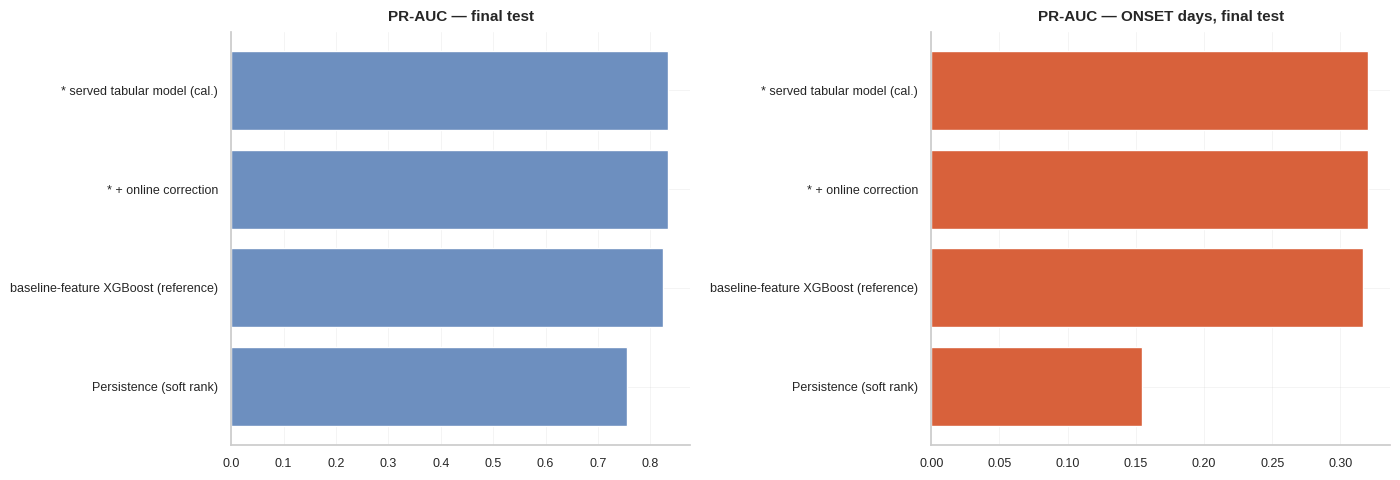


📄 PROOF_REPORT.md written → /content/drive/MyDrive/Bangladesh_Flood_Research/results/eval

=== SYSTEM SERVED ===
national model: Selected combination (walk-forward ensemble) (selection objective: 70% onset PR-AUC) | extra data: not proven | shape features: not proven | keyless data sources: om_era5land: switched OFF by flag | om_precip: ACTIVE — OK (newest value 6 d old; sample 2.2); 1 variables, | nasa_power: ACTIVE — OK (newest value 3 d old; sample 2.45); 3 variables | forecast rain: forecast rain ON — pure forecast value (forecast − control) +0.0318 (gate ≥ 0.003, wins 80 | SAR: SAR correction OFF — no SAR variant cleared the development gate (tabular only) | online correction: OFF | U-Net (validation year 2024): water IoU 0.908 vs 0.768 for the plain threshold on speckle-corrupted / gappy patches


In [40]:
# @title 14e · FINAL PROOF — every component, the rule it had to pass on DEVELOPMENT years, what it did on the untouched FINAL TEST (95 % block-bootstrap CI) and whether it is SERVED  →  PROOF_REPORT.md
def prf_ci(ref, other):
    g = sig_table(TESTS, TESTM, "final test", ref, [other]); return "; ".join(f"{r.metric} {r.mean_diff:+.4f} (95% CI {r.ci_low:+.4f}…{r.ci_high:+.4f})" for r in g.itertuples())
def fold_wins(a, b): return float(np.mean([aps(yD[FID == f_], DEVS[a][FID == f_]) > aps(yD[FID == f_], DEVS[b][FID == f_]) for f_ in np.unique(FID)]))
PRF = []; ALL_X = "XGBoost (all features)"
HAS_XS, HAS_SHAPE = any(c.startswith("ex_") for c in FEATS), any(c.startswith("hd_x_") for c in FEATS)
def _prf_group(label, better, worse, what):
    PRF.append(dict(component=label, rule=f"model WITH the {what} must beat the model WITHOUT by ≥ {SELECT_MARGIN} onset-weighted dev score AND win ≥ 60 % of folds", dev=f"Δ dev score {SC[better] - SC[worse]:+.4f}, fold wins {fold_wins(better, worse):.0%}", decision="PROVEN (served model uses it)" if (SC[better] - SC[worse] >= SELECT_MARGIN and fold_wins(better, worse) >= .6) else "NOT proven → left out of the served model", final_test=prf_ci(better, worse)))
if HAS_SHAPE: _prf_group("Hydrograph-shape features (recession · peak age · run lengths …)", LOCX_NAME if HAS_LOCX else ALL_X, NOEX_NAME, "hydrograph-shape features")
if HAS_XS: _prf_group("Extra data (keyless APIs: Open-Meteo ERA5-Land / ERA5 · NASA POWER; optional Earth Engine)", ALL_X, LOCX_NAME if HAS_LOCX else NOEX_NAME, "extra-source features")
if LSTM_NAME in DEVS:
    PRF.append(dict(component="LSTM sequence model", rule=f"alone: must beat {REF_} in EVERY dev fold; inside the combination: weight chosen by Caruana on walk-forward logits (nested estimate reported)", dev=f"Δ dev score vs base {SC[LSTM_NAME] - SC[BASE_]:+.4f}, fold wins {fold_wins(LSTM_NAME, BASE_):.0%}; Caruana weight {COMBO_W.get(LSTM_NAME, 0):.2f}",
                    decision=("SERVED alone" if TAB_NAME == LSTM_NAME else ("USED inside the combination" if (TAB_NAME == COMBO_NAME and COMBO_W.get(LSTM_NAME, 0) > 0) else "NOT served")), final_test=prf_ci(LSTM_NAME, BASE_)))
for _nm in [k for k in (HG_NAME, TABM_NAME) if k in DEVS] + list(META_NAMES):
    _inside = COMBO_W.get(_nm, 0)
    PRF.append(dict(component=({HG_NAME: "HydroGate-Net (novel sequence architecture)", TABM_NAME: "TabM-style MLP ensemble (deep tabular member)"}.get(_nm, _nm)), rule=f"deployed alone / as stacker ONLY if it beats {REF_} in EVERY dev fold (stackers use NESTED leave-one-fold-out predictions); members may still enter the combination",
                    dev=f"Δ dev score vs base {SC[_nm] - SC[BASE_]:+.4f}, fold wins {fold_wins(_nm, BASE_):.0%}" + (f"; Caruana weight {_inside:.2f}" if _nm in (HG_NAME, TABM_NAME) else ""),
                    decision=("SERVED" if TAB_NAME == _nm else ("USED inside the combination" if (_nm in (HG_NAME, TABM_NAME) and TAB_NAME == COMBO_NAME and _inside > 0) else "NOT served (did not clear the gate)")), final_test=prf_ci(_nm, BASE_)))
PRF.append(dict(component=f"Served national model: {TAB_NAME}", rule=f"deployed ONLY if it beats {REF_} in EVERY dev fold (strictly) and pooled; combination / stackers use NESTED predictions — see 9z table", dev=f"Δ dev score {SC[TAB_NAME] - SC[BASE_]:+.4f}, fold wins {fold_wins(TAB_NAME, BASE_):.0%}" if TAB_NAME != BASE_ else "base model kept", decision="SERVED", final_test=prf_ci(TAB_NAME, BASE_) if TAB_NAME != BASE_ else "—"))
for k, v in SARV.items(): PRF.append(dict(component=f"SAR correction — {k}", rule=f"gain ≥ {CORR_MARGIN} AND better in ≥ 60 % of out-of-time years (expanding window)", dev=f"Δ dev score {v['dev_gain']:+.4f}, years better {v['wins']:.0%}", decision="SERVED" if v["served"] else ("passed gate, not best" if v["active"] else "NOT served"), final_test=f"ΔPR-AUC {v['test_gain']:+.4f}, ΔPR-AUC onset {v['test_gain_onset']:+.4f} (SAR rows only; see F_sar_variants_significance.csv)"))
if FCR: PRF.append(dict(component="Forecast rain (lead 1-3 d, previous-runs backfill + archive)", rule=f"forecast model must beat the CONTROL (observed-rain only) by ≥ {CORR_MARGIN} AND ≥ 60 % of out-of-time quarters", dev=f"pure forecast value {FCR['pure_value']:+.4f} (forecast vs control), vs tabular {FCR['vs_tab']:+.4f}; control {FCR['ctrl_vs_tab']:+.4f}; oracle {FCR['oracle_vs_tab']:+.4f}", decision="SERVED" if FCR["active"] else "NOT served", final_test=f"{FCR['quarters']} out-of-time quarters over {FCR['days']} days of forecasts (exploratory: the archive is too short for a sealed final test)"))
else: PRF.append(dict(component="Forecast rain (lead 1-3 d)", rule="needs ≥ 240 days of true forecasts", dev=FC_NOTE[:120], decision="NOT yet testable", final_test="—"))
PRF.append(dict(component="Online bias correction (self-correcting loop)", rule="PR-score not worse than −0.002 AND Brier ≥ 2 % better AND better in ≥ 60 % of folds (dev)", dev=f"dev Brier gain {ONL_RES['dev_brier_gain']:+.1%}" + (f" (window {ONL_RES['W']} d, κ {ONL_RES['kappa']})" if ONL_RES["active"] else ""), decision="SERVED" if ONL_RES["active"] else "NOT served", final_test=f"Brier gain {ONL_RES['test_brier_gain']:+.1%}, PR-AUC Δ {ONL_RES['test_pr_delta']:+.4f}"))
PRF.append(dict(component="Recall-guaranteed alert levels (class-conditional conformal)", rule="threshold = dev quantile of the served probability on true floods", dev=f"levels {CF_LEVELS}", decision="SERVED (reported in bulletin config)", final_test="; ".join(f"{r.scope} target {r.target_recall:.0%} → realised {r.realised_recall_test:.1%} at {r.alert_rate_test:.1%} alert rate" for r in CFT.itertuples())))
PRF.append(dict(component="Abstention flag (member disagreement)", rule="flag = top-20 % member disagreement (threshold from dev)", dev=f"threshold {UNC_THR:.3f}", decision="SERVED as 'LOW AGREEMENT' flag", final_test=f"holds {UNC_RES['share_miss']:.0%} of missed floods and {UNC_RES['share_fa']:.0%} of false alarms in 20 % of rows"))
PRFT = pd.DataFrame(PRF).set_index("component"); pd.set_option("display.max_colwidth", 200); show(PRFT[["decision", "dev", "final_test"]], 3); PRFT.to_csv(f"{EV}/PROOF_components.csv")

# ---- the served national chain vs the references, final test (thresholds from DEV only) ----
SC_ = {"Persistence-soft (rank by Q/q95 today)": TESTS[SOFT], "★ served tabular model (calibrated)": TESTS[TAB_CAL_NAME], "★ + online correction": p_te_f[te_ix]}; TH_ = {"Persistence-soft (rank by Q/q95 today)": THR[SOFT], "★ served tabular model (calibrated)": THR[TAB_CAL_NAME], "★ + online correction": thr4(yD, p_dev_f[dev_ix], onD)}
if HAS_EX: SC_["· baseline-feature XGBoost (reference)"] = TESTS[NOEX_NAME]; TH_["· baseline-feature XGBoost (reference)"] = THR[NOEX_NAME]
CHAIN = bench(SC_, TESTM, TH_); print(f"\nSERVED CHAIN — final test (≥ {FINAL_TEST_FROM}), all {len(TESTM):,} node-days:"); show(CHAIN); CHAIN.round(4).to_csv(f"{EV}/PROOF_served_chain_test.csv")
def lead_stats(M, p, thr):
    """Onset EVENTS: a run of consecutive onset-positive rows (quiet 4 d, flood within 3 d) = one event. Lead = days of warning before the flood starts (≤ 3); 0 = missed."""
    d = M[["node", "date", "y", "on"]].copy(); d["a"] = (d.y.values == 1) & (d.on.values == 1); d["al"] = np.asarray(p) >= thr; d["date"] = pd.to_datetime(d.date); d = d.sort_values(["node", "date"]).reset_index(drop=True)
    brk = (d.node != d.node.shift()) | (d.date.diff().dt.days != 1) | (d.a != d.a.shift()); d["run"] = brk.cumsum(); leads = []
    for _, g in d[d.a].groupby("run"): hit = np.where(g.al.values)[0]; leads.append(len(g) - hit[0] if len(hit) else 0)
    L = np.array(leads); return dict(events=len(L), detected=float((L > 0).mean()), mean_lead_days=float(L[L > 0].mean()) if (L > 0).any() else np.nan, at_least_2_days=float((L >= 2).mean()), full_3_days=float((L >= 3).mean()))
LEAD = pd.DataFrame({nm: lead_stats(TESTM, p_, TH_[nm][1]) for nm, p_ in SC_.items()}).T; print(f"\nONSET EVENTS — detection and warning lead time on the final test (onset threshold from dev):"); show(LEAD, 3); LEAD.round(4).to_csv(f"{EV}/PROOF_onset_lead_time.csv")
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8), sharey=False); cs = CHAIN.sort_values("PR_AUC"); ax[0].barh([short_name(n) for n in cs.index], cs.PR_AUC, color="#6d8fbf"); ax[0].set_title("PR-AUC — final test"); cs = CHAIN.sort_values("PR_AUC_onset"); ax[1].barh([short_name(n) for n in cs.index], cs.PR_AUC_onset, color="#d8613b"); ax[1].set_title("PR-AUC — ONSET days, final test"); plt.savefig(f"{EV}/PROOF_chain.png"); plt.show(); plt.close("all")

SYS_NOTE = f"national model: {TAB_NAME} (selection objective: {SCORE_W_ONSET:.0%} onset PR-AUC) | extra data: {'used' if (HAS_XS and TAB_NAME in (ALL_X,)) else 'not proven'} | shape features: {'used' if (HAS_SHAPE and TAB_NAME in (ALL_X, LOCX_NAME)) else 'not proven'} | keyless data sources: {HX_NOTE[:200]} | forecast rain: {FC_NOTE[:90]} | SAR: {SAR_NOTE2} | online correction: {'ON' if ONL['active'] else 'OFF'} | {UN_NOTE}"
md = [f"# Bangladesh flood system — proof report (generated {pd.Timestamp.now():%Y-%m-%d %H:%M})", "", f"Development folds {DEV_FOLDS}; untouched final test ≥ {FINAL_TEST_FROM}; every decision below was taken on development data BEFORE the final test was evaluated (selection frozen in selection_frozen.json).", "", f"**System served:** {SYS_NOTE}", "",
      "| component | rule (dev) | dev evidence | decision | final-test evidence |", "|---|---|---|---|---|"] + [f"| {i} | {r.rule} | {r.dev} | **{r.decision}** | {r.final_test} |" for i, r in PRFT.iterrows()] + ["", "## Served chain, final test", "", CHAIN.round(4).to_markdown() if importlib.util.find_spec("tabulate") else CHAIN.round(4).to_string(), "", "", "## Formal ablation table (cell 10g)", "", ABL_TXT, "", "## Final selection (all-folds rule, cell 9z)", "", SELECT_TAB.round(4).to_string(), "", "## Data-source registry (flags in cell 8b2)", "", SRC_STATUS.to_string(), "", "Caveats: labels are GloFAS-derived high-flow events, not gauge records; the U-Net is trained on rule-based water masks (weak supervision); SAR history starts in 2017."]
open(f"{EV}/PROOF_REPORT.md", "w", encoding="utf-8").write("\n".join(md)); print(f"\n📄 PROOF_REPORT.md written → {EV}\n\n=== SYSTEM SERVED ===\n{SYS_NOTE}")


In [41]:
# @title 14c · DEPLOYMENT REFIT — serve models trained on ALL labelled rows (incl. ≥ 2025) with the frozen hyper-parameters, combination weights, calibrator and thresholds
EVAL_MODELS = dict(main=XGB_MAIN, local=XGB_LOCAL, **EXTRA)                       # evaluation fits (trained ≤ 2024) — every number in this notebook comes from these
if DEPLOY_REFIT:
    t0 = time.time(); Xa, ya, qa = PF[FEATS].to_numpy(np.float32), PF.y.to_numpy(int), PF.quiet4.to_numpy(int); all_i = np.arange(len(PF)); swa = sw_of(ya, qa, IMB["onset_w"]); spa = IMB["spw_mult"] * (ya == 0).sum() / max(ya.sum(), 1); li = [FEATS.index(c) for c in LOCAL]
    XGB_MAIN = xgb_make(XGB_P, N_ITER, spa).fit(Xa, ya, sample_weight=swa); XGB_LOCAL = xgb_make(XGB_P, N_ITER, spa).fit(Xa[:, li], ya, sample_weight=swa)
    EXTRA = dict(lgb=lgb_make().fit(Xa, ya, sample_weight=swa), bag=bag_fit(Xa, ya, all_i, N_ITER), split=split_fit(Xa, ya, qa, all_i), noex=(xgb_make(XGB_P, N_ITER, spa).fit(Xa[:, [FEATS.index(c) for c in NOEX_COLS]], ya, sample_weight=swa) if HAS_EX else None), locx=(xgb_make(XGB_P, N_ITER, spa).fit(Xa[:, [FEATS.index(c) for c in LOCX_COLS]], ya, sample_weight=swa) if HAS_LOCX else None), lstm=EVAL_MODELS.get("lstm"), hg=EVAL_MODELS.get("hg"), tabm=EVAL_MODELS.get("tabm"))
    print(f"♻️ deployment refit on {len(PF):,} labelled rows (train ≤ {FINAL_TEST_FROM - 1} + test ≥ {FINAL_TEST_FROM}) in {time.time() - t0:.0f}s — model {TAB_NAME}")
    del Xa, ya, qa; gc.collect()
else: print("DEPLOY_REFIT=False → serving the evaluation models (trained ≤ 2024).")
joblib.dump(dict(tab_name=TAB_NAME, combo_w=COMBO_W, models=dict(main=XGB_MAIN, local=XGB_LOCAL, **EXTRA), feats=FEATS, local=LOCAL, cal=CAL_TAB.lr, fit=FIT_FINAL, refit=bool(DEPLOY_REFIT), gate=(GD0, GS_)), f"{MD}/deployed_tabular.joblib"); print("💾 saved_models/deployed_tabular.joblib")


♻️ deployment refit on 286,300 labelled rows (train ≤ 2024 + test ≥ 2025) in 433s — model Selected combination (walk-forward ensemble)
💾 saved_models/deployed_tabular.joblib


## 15 · Alert tiers, live scoring, bulletin, CAP

Tier thresholds (tabular branch, calibrated probability, pooled walk-forward): {'WATCH': 0.135, 'WARNING': 0.445, 'SEVERE': 0.667}

Tier validation on the untouched final test (≥ 2025), tabular branch:


,alerts,alert_rate,precision,floods_captured,onsets_captured
tier,,,,,
≥ WATCH,3576,0.075,0.481,0.877,0.622
≥ WARNING,1791,0.037,0.782,0.714,0.252
≥ SEVERE,1395,0.029,0.893,0.635,0.103


    online correction OFF

📅 as of 2026-11-16 | mode: tabular + forecast rain | nodes: 70 | tiers: {'none': 70}


,basin,zone,prob,tier,drivers
district,,,,,



NATIONAL FLOOD EARLY-WARNING BULLETIN — as of 2026-11-16 (next 3 days) — status: TEST / research prototype
Mode: tabular + forecast rain. Probabilities are model estimates validated only against GloFAS-derived high-flow events, not official gauge records.

No district is at WATCH or above.


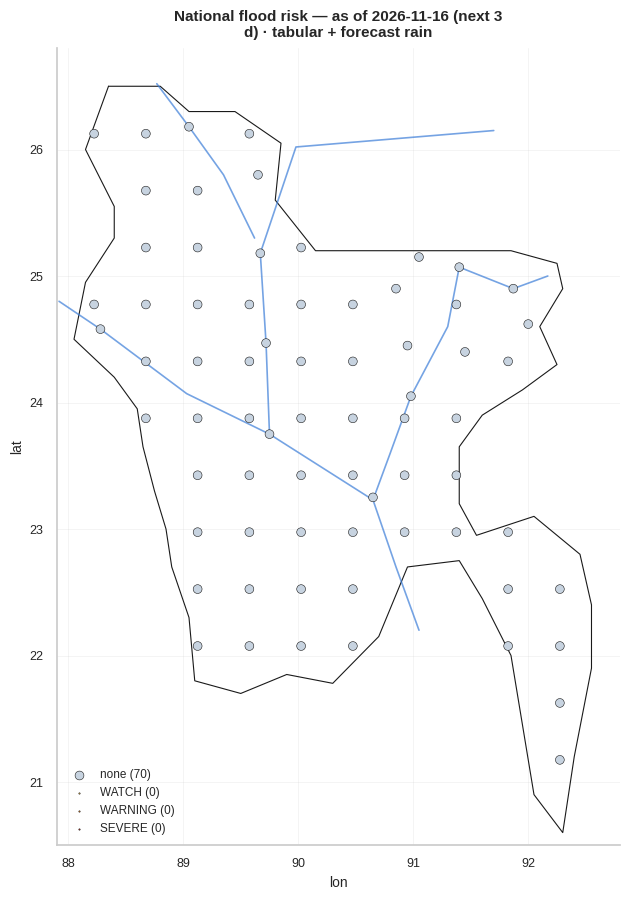

💾 alerts/: bulletin_20261116.txt · nodes_20261116.geojson · map_20261116.png · cap/: 0 CAP 1.2 file(s) with status=Test


In [42]:
# @title 15 · Alert tiers (WATCH / WARNING / SEVERE) from pooled out-of-time data · tier validation on the final test · live national scoring · bulletin · GeoJSON · CAP 1.2 · map
def tier_thr(y, p):
    """WATCH = recall-weighted (F2) optimum · WARNING = F1 optimum · SEVERE = lowest probability whose pooled out-of-time precision ≥ SEVERE_MIN_PREC (monotone enforced)."""
    w = best_thr(y, p, 2.0); wa = max(best_thr(y, p, 1.0), w); pr, rc, th = precision_recall_curve(y, p); ok = np.where(pr[:-1] >= SEVERE_MIN_PREC)[0]; sv = float(th[ok].min()) if len(ok) else float(np.quantile(p, .995))
    sv = max(sv, wa)
    if sv <= wa + 1e-6: sv = wa + 0.4 * (1 - wa)            # precision target already met at WARNING → place SEVERE 40 % of the way to 1 so the tiers stay distinct
    return dict(WATCH=w, WARNING=wa, SEVERE=sv)
def tier_of(p, T): return np.where(p >= T["SEVERE"], "SEVERE", np.where(p >= T["WARNING"], "WARNING", np.where(p >= T["WATCH"], "WATCH", "none")))
TIERS_TAB = tier_thr(yD, DEVS[TAB_CAL_NAME]); print("Tier thresholds (tabular branch, calibrated probability, pooled walk-forward):", {k: round(v, 3) for k, v in TIERS_TAB.items()})
TIERS_FUS = None
def tier_report(y, p, T, on=None):
    t = tier_of(p, T); rows = []
    for k in ("WATCH", "WARNING", "SEVERE"):
        m = np.isin(t, {"WATCH": ["WATCH", "WARNING", "SEVERE"], "WARNING": ["WARNING", "SEVERE"], "SEVERE": ["SEVERE"]}[k]); rows.append(dict(tier=f"≥ {k}", alerts=int(m.sum()), alert_rate=m.mean(), precision=y[m].mean() if m.any() else np.nan, floods_captured=y[m].sum() / max(y.sum(), 1),
                                                                                                                                                                  onsets_captured=(y[m & on].sum() / max(y[on].sum(), 1)) if on is not None and y[on].sum() else np.nan))
    return pd.DataFrame(rows).set_index("tier")
TR_TAB = tier_report(TESTM.y.values, TESTS[TAB_CAL_NAME], TIERS_TAB, TESTM.on.values); print(f"\nTier validation on the untouched final test (≥ {FINAL_TEST_FROM}), tabular branch:"); show(TR_TAB, 3); TR_TAB.round(4).to_csv(f"{EV}/T_tier_validation.csv")

# ---------------------------------------------------------------- live data ---------------------------------------------------------------------------------------------------
def fetch_live(past=60, asof=None):
    """Last `past` days of discharge (nodes + gauges) and weather. DRY_RUN replays the synthetic world up to `asof` (the busiest test day) so the bulletin is non-trivial."""
    if DRY_RUN:
        a = pd.Timestamp(asof or TESTM.groupby("date").y.sum().idxmax()); sl = lambda df: df.loc[a - pd.Timedelta(days=past):a]; return dict(QN=sl(QN), QG=sl(QG), PR=sl(PR), ET=sl(ET), TP=sl(TP), UPR=sl(UPR)), a
    def batch(url, names, coords, **kw):
        out = {}
        for i in range(0, len(names), 25):
            nm, cc = names[i:i + 25], coords[i:i + 25]; j = om_get(url, dict(latitude=",".join(f"{a:.4f}" for a, _ in cc), longitude=",".join(f"{b:.4f}" for _, b in cc), past_days=past, **kw)); j = j if isinstance(j, list) else [j]
            for n, x in zip(nm, j): out[n] = pd.DataFrame(x["daily"]).set_index(pd.to_datetime(x["daily"]["time"])).drop(columns="time")
        return out
    nn = list(NODES.index); nc = [(r.lat, r.lon) for r in NODES.itertuples()]; gn = list(STATIONS); gc_ = [(SNAP[g]["lat"], SNAP[g]["lon"]) for g in gn]
    fq = batch(FLOOD_URL, nn + gn, nc + gc_, daily="river_discharge", forecast_days=0); wx = batch(FORECAST_URL, nn + list(UP_RAIN), nc + list(UP_RAIN.values()), daily="precipitation_sum,et0_fao_evapotranspiration,temperature_2m_mean", forecast_days=1, timezone="Asia/Dhaka")
    ix = pd.date_range(TODAY - pd.Timedelta(days=past), TODAY, freq="D"); fr = lambda d, ks, col: pd.DataFrame({k: d[k][col] for k in ks}).reindex(ix).astype("float32")
    live = dict(QN=fr(fq, nn, "river_discharge"), QG=fr(fq, gn, "river_discharge"), PR=fr(wx, nn, "precipitation_sum"), ET=fr(wx, nn, "et0_fao_evapotranspiration"), TP=fr(wx, nn, "temperature_2m_mean"), UPR=fr(wx, list(UP_RAIN), "precipitation_sum"))
    a = min(live["QN"][NODE_IDS].dropna(how="all").index[-1], live["PR"][NODE_IDS].dropna(how="all").index[-1]); return {k: v.loc[:a] for k, v in live.items()}, a

DRIVER_TXT = {"hd_": "high flow already at the node", "up_": "rising upstream flow", "tb_": "transboundary inflow", "rn_": "heavy / persistent rain & wet soil", "sp_": "neighbouring areas rising", "st_": "terrain / location", "ss_": "monsoon season", "cx_": "river-driven context"}
REC = {("WATCH", "riparian"): "Monitor river gauges; review embankment/shelter readiness; move livestock & movable assets from the riverside.",
       ("WARNING", "riparian"): "Prepare to evacuate char/riverside households; alert shelter managers; secure food, water, medicine; avoid river crossings.",
       ("SEVERE", "riparian"): "Evacuate low-lying riverside and char areas now to cyclone/flood shelters; follow DDM/local administration orders; do not cross flooded roads.",
       ("WATCH", "inland"): "Watch local rainfall; clear drains and drainage channels; keep phones charged.",
       ("WARNING", "inland"): "Waterlogging / flash-flood risk: avoid low roads, protect stored crops & seed, prepare a go-bag, warn haor / low-lying communities.",
       ("SEVERE", "inland"): "Serious flash-flood / waterlogging risk: move to higher ground, avoid roads and bridges under water, follow official instructions."}
def score_live(live, asof):
    """Same feature code as training (build_panel with live=True) → calibrated tabular probability → optional vision/meta fusion → tiers + SHAP reason codes."""
    P, _ = build_panel(FIT_FINAL, lambda ix: np.asarray(ix == asof), data=live, live=True); X = P[FEATS].to_numpy(np.float32); MP_ = member_probs(X, P.quiet4.to_numpy(int), rows=P[["node", "date"]], data=live); pr = compose(TAB_NAME, MP_, P.st_dist_river.values); MEM_ = [k for k in POOL if k in MP_]
    unc = (np.std([MP_[k] for k in MEM_], axis=0) > UNC_THR) if len(MEM_) > 1 else np.zeros(len(P), bool)
    p = CAL_TAB(pr); T = TIERS_TAB; mode = "tabular"
    if SAR_SERVE_KIND != "none" and (EE_READY or DRY_RUN):
        try: p = live_sar_apply(P, p, asof); mode = f"tabular + SAR ({SAR_SERVE_KIND})"
        except Exception as err: print("⚠️ SAR correction unavailable for this run → tabular result used:", str(err)[:120])
    if FC_SERVE:
        try: p = live_fc_apply(P, p, asof); mode += " + forecast rain"
        except Exception as err: print("⚠️ forecast-rain correction unavailable:", str(err)[:100])
    p_base = p.copy(); ONL_MSG = "online correction OFF"
    try: p, ONL_MSG = onl_live(P, p, asof); onl_log(P, p_base, asof)
    except Exception as err: ONL_MSG = f"online correction unavailable ({str(err)[:80]})"
    if ONL["active"]: mode += " + online correction"
    print("   ", ONL_MSG); sar_now = np.array(["n/a"] * len(P))
    if VER_COL is not None and (EE_READY or DRY_RUN):
        try: sar_now = live_sar_status(P, asof)
        except Exception as err: print("⚠️ SAR status unavailable:", str(err)[:100])
    contrib = XGB_MAIN.get_booster().predict(xgb.DMatrix(X), pred_contribs=True)[:, :-1]; drv = []
    for r in contrib:
        top = np.argsort(-r)[:3]; drv.append("; ".join(dict.fromkeys(DRIVER_TXT.get(FEATS[i].split("_")[0] + "_", FEATS[i]) for i in top if r[i] > 0)) or "—")
    nd = NODES.reindex(P.node.values); R = pd.DataFrame(dict(node=P.node.values, district=nd.district.values, basin=nd.basin.values, zone=nd.zone.values, lat=nd.lat.values, lon=nd.lon.values, prob=p, tier=tier_of(p, T), drivers=drv, sar_now=sar_now, low_agree=unc)); return R, mode
LIVE, ASOF = fetch_live(asof=None); NOW, MODE = score_live(LIVE, ASOF); order = {"none": 0, "WATCH": 1, "WARNING": 2, "SEVERE": 3}
DIST = NOW.assign(rank=NOW.tier.map(order)).sort_values(["rank", "prob"], ascending=False).groupby("district").first().sort_values(["rank", "prob"], ascending=False).drop(columns="rank")
print(f"\n📅 as of {ASOF.date()} | mode: {MODE} | nodes: {len(NOW)} | tiers: {NOW.tier.value_counts().to_dict()}"); show(DIST[DIST.tier != "none"].head(15)[["basin", "zone", "prob", "tier", "drivers"]], 3)

# ---------------------------------------------------------------- bulletin, GeoJSON, CAP, map ------------------------------------------------------------------------------------
stamp = ASOF.strftime("%Y%m%d"); AL = DIRS["alerts"]; alerted = DIST[DIST.tier != "none"]
lines = [f"NATIONAL FLOOD EARLY-WARNING BULLETIN — as of {ASOF.date()} (next {HORIZON} days) — status: {CAP_STATUS.upper()} / research prototype", f"Mode: {MODE}. Probabilities are model estimates validated only against GloFAS-derived high-flow events, not official gauge records.", ""]
for tier in ("SEVERE", "WARNING", "WATCH"):
    d = alerted[alerted.tier == tier]
    if len(d): lines.append(f"{tier} ({BN_TIER[tier]}): {len(d)} district(s)"); lines += [f"  • {n} ({r.basin}, {r.zone}) — p={r.prob:.2f}; drivers: {r.drivers}; SAR now: {r.sar_now}{'; ⚠ LOW AGREEMENT between models' if r.low_agree else ''}. Advice: {REC[(tier, r.zone)]}" for n, r in d.iterrows()]; lines.append("")
if alerted.empty: lines.append("No district is at WATCH or above.")
BULLETIN = "\n".join(lines); open(f"{AL}/bulletin_{stamp}.txt", "w", encoding="utf-8").write(BULLETIN); print("\n" + BULLETIN[:2500])
gj = {"type": "FeatureCollection", "features": [{"type": "Feature", "geometry": {"type": "Point", "coordinates": [r.lon, r.lat]}, "properties": dict(node=r.node, district=r.district, basin=r.basin, zone=r.zone, prob=round(float(r.prob), 4), tier=r.tier, drivers=r.drivers)} for r in NOW.itertuples()]}
json.dump(gj, open(f"{AL}/nodes_{stamp}.geojson", "w"), ensure_ascii=False)
SEV = {"WATCH": ("Minor", "Possible"), "WARNING": ("Moderate", "Likely"), "SEVERE": ("Severe", "Likely")}; URG = {"WATCH": "Future", "WARNING": "Expected", "SEVERE": "Immediate"}
for d, r in alerted.iterrows():
    sev, cert = SEV[r.tier]; sent = dt.datetime.now(dt.timezone.utc).strftime("%Y-%m-%dT%H:%M:%S+00:00")
    cap = f"""<?xml version="1.0" encoding="UTF-8"?>
<alert xmlns="urn:oasis:names:tc:emergency:cap:1.2"><identifier>BD-FLOOD-{stamp}-{xml_escape(d.replace(' ', '_'))}</identifier><sender>{CAP_SENDER}</sender><sent>{sent}</sent><status>{CAP_STATUS}</status><msgType>Alert</msgType><scope>Public</scope>
<info><language>en-US</language><category>Met</category><event>Flood</event><urgency>{URG[r.tier]}</urgency><severity>{sev}</severity><certainty>{cert}</certainty><headline>{r.tier} — flood risk, {xml_escape(d)} district ({BN_TIER[r.tier]})</headline>
<description>Model-estimated probability {r.prob:.2f} of high river flow / flooding within {HORIZON} days. Main drivers: {xml_escape(r.drivers)}. Research prototype — verify with BWDB/FFWC/BMD.</description><instruction>{xml_escape(REC[(r.tier, r.zone)])}</instruction><area><areaDesc>{xml_escape(d)}</areaDesc></area></info></alert>"""
    open(f"{DIRS['cap']}/cap_{stamp}_{d.replace(' ', '_')}.xml", "w", encoding="utf-8").write(cap)
fig, ax = plt.subplots(figsize=(8.5, 9)); TC = {"none": "#c7d3e0", "WATCH": "#f2c14e", "WARNING": "#f08a24", "SEVERE": "#c0392b"}; bd_map(ax, title=f"National flood risk — as of {ASOF.date()} (next {HORIZON} d) · {MODE}")
for t in ("none", "WATCH", "WARNING", "SEVERE"): m = NOW.tier == t; ax.scatter(NOW.lon[m], NOW.lat[m], s=40 + 220 * NOW.prob[m], color=TC[t], edgecolor="k", lw=.4, label=f"{t} ({int(m.sum())})", zorder=4)
for d, r in alerted.head(10).iterrows(): ax.annotate(d, (r.lon, r.lat), fontsize=7, xytext=(4, 4), textcoords="offset points")
ax.legend(loc="lower left"); plt.savefig(f"{AL}/map_{stamp}.png"); plt.show(); plt.close("all")
if ALERT_CFG.get("telegram_token") and ALERT_CFG.get("telegram_chat") and not DRY_RUN and len(alerted):
    requests.post(f"https://api.telegram.org/bot{ALERT_CFG['telegram_token']}/sendMessage", data=dict(chat_id=ALERT_CFG["telegram_chat"], text=BULLETIN[:3900]), timeout=30); print("📨 bulletin sent to Telegram")
print(f"💾 alerts/: bulletin_{stamp}.txt · nodes_{stamp}.geojson · map_{stamp}.png · cap/: {len(alerted)} CAP 1.2 file(s) with status={CAP_STATUS}")


In [43]:
# @title 15b · FORECAST-RAIN ARCHIVER — saves today's true forecast (lead 1-3 d) for every node, so a genuine forecast-rain training history exists in ~12 months
FC_DIR = f"{BASE}/forecast_archive"; os.makedirs(FC_DIR, exist_ok=True)
def log_forecast_rain(days=4):
    nn = list(NODES.index); rows = []
    for i in range(0, len(nn), 25):
        ch = nn[i:i + 25]; j = om_get(FORECAST_URL, dict(latitude=",".join(f"{NODES.at[n, 'lat']:.4f}" for n in ch), longitude=",".join(f"{NODES.at[n, 'lon']:.4f}" for n in ch), daily="precipitation_sum", forecast_days=days, models=FC_MODEL, timezone="Asia/Dhaka")); j = j if isinstance(j, list) else [j]
        for n, x in zip(ch, j): rows += [dict(node=n, issue_date=TODAY, target_date=pd.Timestamp(t), lead=(pd.Timestamp(t) - TODAY).days, precip_mm=v) for t, v in zip(x["daily"]["time"], x["daily"]["precipitation_sum"])]
    df = pd.DataFrame(rows); df.to_parquet(f"{FC_DIR}/fc2_{TODAY.date()}.parquet", compression="zstd", index=False); return df
if DRY_RUN: print("DRY_RUN: forecast archiver skipped.")
else:
    try: _fc = log_forecast_rain(); print(f"🌧️ archived {len(_fc):,} forecast rows → forecast_archive/ ({len(os.listdir(FC_DIR))} daily snapshots so far). Cell 14f uses this archive (plus the previous-runs backfill) automatically on the next run.")
    except Exception as err: print("⚠️ forecast archiver failed (non-fatal):", str(err)[:160])


🌧️ archived 284 forecast rows → forecast_archive/ (6 daily snapshots so far). Cell 14f uses this archive (plus the previous-runs backfill) automatically on the next run.


## 16 · Dashboard & summary

In [44]:
# @title 16 · Interactive dashboard (Gradio) + run summary
def district_report(d):
    r = NOW[NOW.district == d].sort_values("prob", ascending=False)
    if r.empty: return "Unknown district."
    top = r.iloc[0]; return f"**{d}** — {top.tier if top.tier != 'none' else 'no alert'} (p = {top.prob:.2f})\n\nZone: {top.zone} · basin: {top.basin}\n\nDrivers: {top.drivers}\n\n" + (f"Advice: {REC[(top.tier, top.zone)]}" if top.tier != "none" else "No action needed beyond routine monitoring.") + f"\n\n_As of {ASOF.date()}, mode: {MODE}. Research prototype (status {CAP_STATUS})._"
def map_for(d=None):
    fig, ax = plt.subplots(figsize=(6, 6.5)); bd_map(ax, title=f"Risk as of {ASOF.date()}")
    ax.scatter(NOW.lon, NOW.lat, c=[TC[t] for t in NOW.tier], s=40 + 220 * NOW.prob, edgecolor="k", lw=.3, zorder=4)
    if d: r = NOW[NOW.district == d]; ax.scatter(r.lon, r.lat, s=330, facecolor="none", edgecolor="blue", lw=2, zorder=5)
    plt.close(fig); return fig
if DRY_RUN: print("DRY_RUN: dashboard functions defined, UI not launched. Try:\n", district_report(DIST.index[0]))
else:
    if importlib.util.find_spec("gradio") is None: subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gradio"], check=False)
    import gradio as gr
    with gr.Blocks(title="Bangladesh national flood intelligence") as demo:
        gr.Markdown("# Bangladesh National Flood Intelligence v11 — research prototype\nSelected tabular ensemble + SAR residual corrector · WATCH / WARNING / SEVERE")
        dd = gr.Dropdown(sorted(NOW.district.unique()), value=DIST.index[0], label="District"); out = gr.Markdown(district_report(DIST.index[0])); pl = gr.Plot(map_for(DIST.index[0]))
        dd.change(lambda d: (district_report(d), map_for(d)), dd, [out, pl]); gr.Dataframe(DIST[DIST.tier != "none"].reset_index()[["district", "basin", "zone", "prob", "tier", "drivers"]].round(3))
    demo.launch(share=True, debug=False)
print("\n================ RUN SUMMARY ================"); print(f"nodes {len(NODE_IDS)} | rows ≈ {n_rows:,} | folds {DEV_FOLDS} + final ≥ {FINAL_TEST_FROM} | tabular model: {TAB_NAME} | vision: {'on' if USE_VISION else 'off'}")
print(f"v11 | {SYS_NOTE} | deployment refit: {DEPLOY_REFIT}")
print(f"extra sources: {XS_NOTE}\n{LSTM_NOTE} | {UN_NOTE}")
print("artefacts under", BASE)
for sub in ("results/eda", "results/eval", "saved_models", "alerts", "cap"): print(f"   {sub}: {len(os.listdir(f'{BASE}/{sub}'))} files")
if DRY_RUN: print("\n⚠️ DRY_RUN used SYNTHETIC data — the numbers above only prove the pipeline runs end-to-end. Set DRY_RUN=False for real results.")


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://366cdfff5a3bbf4174.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)



================ RUN SUMMARY ================
nodes 70 | rows ≈ 763,910 | folds [2020, 2021, 2022, 2023, 2024] + final ≥ 2025 | tabular model: Selected combination (walk-forward ensemble) | vision: on
v11 | national model: Selected combination (walk-forward ensemble) (selection objective: 70% onset PR-AUC) | extra data: not proven | shape features: not proven | keyless data sources: om_era5land: switched OFF by flag | om_precip: ACTIVE — OK (newest value 6 d old; sample 2.2); 1 variables, | nasa_power: ACTIVE — OK (newest value 3 d old; sample 2.45); 3 variables | forecast rain: forecast rain ON — pure forecast value (forecast − control) +0.0318 (gate ≥ 0.003, wins 80 | SAR: SAR correction OFF — no SAR variant cleared the development gate (tabular only) | online correction: OFF | U-Net (validation year 2024): water IoU 0.908 vs 0.768 for the plain threshold on speckle-corrupted / gappy patches | deployment refit: True
extra sources: chirps: DROPPED (data arrive 48 d late > 45 d — not 